In [1]:
import pandas as pd
import numpy as np
import os

# Load your uploaded survey dataset
df = pd.read_csv("weather1.csv")
# Display dataset size
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 30
Number of columns: 18


In [2]:
# Display first five records
display(df.head())

,Timestamp,NAME,E-mail id,1. Which area do you live in?,2.Have you experienced extreme weather events in your area?,3. Which extreme weather events have you experienced?,4.Have you noticed unusual changes in local weather patterns in recent years?,5.How often does your area experience sudden temperature changes?,6.Are you familiar with the term 'micro-climate anomaly'?,7.How do extreme weather events affect your daily life?,8.How do you currently receive weather alerts?,9.How reliable do you think current weather forecasts are for your local area?,10.Have you ever received a weather warning too late to prepare?,11.Would you find an early warning system for sudden local weather anomalies useful?,12.How would you prefer to receive early warnings?,13.What features would you like in an Extreme Weather & Micro-Climate Anomaly Early Warning System?,14.Would you trust weather anomaly predictions generated using Artificial Intelligence (AI)?,15.What improvements would make an early warning system more effective in your area?
0,2026/10/09 5:32:22 pm GMT+5:30,GUNAPRIYA J,priyaguna859@gmail.com,Rural,Rarely,Heavy rainfall,"Yes, slight changes",Sometimes,Heard of it but unsure,Travel disruptions,Social media,Moderately reliable,Rarely,Somewhat useful,Local siren or public announcement,Real-time weather monitoring;Location-specific...,Somewhat trust,Offline alerts
1,2026/10/09 6:26:27 pm GMT+5:30,Dhanush,dhanush.s2025@vitstudent.ac.in,Urban,"Yes, frequently",Heatwaves,"Yes, significant changes",Very often,Very familiar,Health problems,Mobile SMS,Very reliable,Frequently,Very useful,SMS,Real-time weather monitoring,Completely trust,More accurate predictions
2,2026/10/09 7:26:16 pm GMT+5:30,D.Swetha,swethadhasaradhan2005@gmail.com,Rural,"Yes, occasionally",Heavy rainfall,No changes noticed,Rarely,Somewhat familiar,No major impact,Television or radio,Moderately reliable,Never,Somewhat useful,WhatsApp;Phone call,Real-time weather monitoring;Heavy rainfall an...,Somewhat trust,Better flood and heat risk detection
3,2026/10/09 11:04:52 pm GMT+5:30,NANDHA KUMAR B,nandhaleelaraja@gmail.com,Rural,"Yes, occasionally",Heavy rainfall,Not sure,Sometimes,Heard of it but unsure,NaN,NaN,Moderately reliable,NaN,Useful,Email,Heavy rainfall and flood warnings,NaN,More accurate predictions
4,2026/10/10 8:13:50 am GMT+5:30,Siva Prakasam k,ksivaprakasam2710@gmail.com,Rural,"Yes, frequently",Heatwaves,"Yes, significant changes",Often,Somewhat familiar,Work or school disruption,Television or radio,Very reliable,Frequently,Useful,WhatsApp,Temperature anomaly detection,Somewhat trust,Local-language notifications


In [3]:
# Display all column names

for i, column in enumerate(df.columns):
    print(i + 1, column)

1 Timestamp
2 NAME
3 E-mail id
4  1. Which area do you live in?  
5 2.Have you experienced extreme weather events in your area?
6 3. Which extreme weather events have you experienced?
7 4.Have you noticed unusual changes in local weather patterns in recent years?
8 5.How often does your area experience sudden temperature changes?
9 6.Are you familiar with the term 'micro-climate anomaly'?
10 7.How do extreme weather events affect your daily life?
11 8.How do you currently receive weather alerts?
12 9.How reliable do you think current weather forecasts are for your local area?
13 10.Have you ever received a weather warning too late to prepare?
14 11.Would you find an early warning system for sudden local weather anomalies useful?
15 12.How would you prefer to receive early warnings?
16 13.What features would you like in an Extreme Weather & Micro-Climate Anomaly Early Warning System?
17 14.Would you trust weather anomaly predictions generated using Artificial Intelligence (AI)?
18 15.Wh

In [4]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")

display(missing_values[missing_values > 0])

Missing values in each column:


7.How do extreme weather events affect your daily life?                                         1
8.How do you currently receive weather alerts?                                                  1
10.Have you ever received a weather warning too late to prepare?                                2
12.How would you prefer to receive early warnings?                                              1
14.Would you trust weather anomaly predictions generated using Artificial Intelligence (AI)?    1
dtype: int64

In [5]:
# Create a safe analysis copy

survey_df = df.copy()

# Remove personally identifiable information
survey_df = survey_df.drop(
    columns=["NAME", "E-mail id"],
    errors="ignore"
)

# Remove timestamp from the survey analysis features
survey_df = survey_df.drop(
    columns=["Timestamp"],
    errors="ignore"
)

print("Personal information removed!")
print("Remaining columns:", len(survey_df.columns))

display(survey_df.head())

Personal information removed!
Remaining columns: 15


,1. Which area do you live in?,2.Have you experienced extreme weather events in your area?,3. Which extreme weather events have you experienced?,4.Have you noticed unusual changes in local weather patterns in recent years?,5.How often does your area experience sudden temperature changes?,6.Are you familiar with the term 'micro-climate anomaly'?,7.How do extreme weather events affect your daily life?,8.How do you currently receive weather alerts?,9.How reliable do you think current weather forecasts are for your local area?,10.Have you ever received a weather warning too late to prepare?,11.Would you find an early warning system for sudden local weather anomalies useful?,12.How would you prefer to receive early warnings?,13.What features would you like in an Extreme Weather & Micro-Climate Anomaly Early Warning System?,14.Would you trust weather anomaly predictions generated using Artificial Intelligence (AI)?,15.What improvements would make an early warning system more effective in your area?
0,Rural,Rarely,Heavy rainfall,"Yes, slight changes",Sometimes,Heard of it but unsure,Travel disruptions,Social media,Moderately reliable,Rarely,Somewhat useful,Local siren or public announcement,Real-time weather monitoring;Location-specific...,Somewhat trust,Offline alerts
1,Urban,"Yes, frequently",Heatwaves,"Yes, significant changes",Very often,Very familiar,Health problems,Mobile SMS,Very reliable,Frequently,Very useful,SMS,Real-time weather monitoring,Completely trust,More accurate predictions
2,Rural,"Yes, occasionally",Heavy rainfall,No changes noticed,Rarely,Somewhat familiar,No major impact,Television or radio,Moderately reliable,Never,Somewhat useful,WhatsApp;Phone call,Real-time weather monitoring;Heavy rainfall an...,Somewhat trust,Better flood and heat risk detection
3,Rural,"Yes, occasionally",Heavy rainfall,Not sure,Sometimes,Heard of it but unsure,NaN,NaN,Moderately reliable,NaN,Useful,Email,Heavy rainfall and flood warnings,NaN,More accurate predictions
4,Rural,"Yes, frequently",Heatwaves,"Yes, significant changes",Often,Somewhat familiar,Work or school disruption,Television or radio,Very reliable,Frequently,Useful,WhatsApp,Temperature anomaly detection,Somewhat trust,Local-language notifications


In [6]:
# Save anonymised survey dataset

survey_df.to_csv(
    "cleaned_survey_data.csv",
    index=False
)

print("Cleaned survey dataset saved successfully!")

Cleaned survey dataset saved successfully!


In [7]:
# Remove unnecessary spaces from column names
survey_df.columns = survey_df.columns.str.strip()

print("Survey data is ready for analysis.")
print("Rows:", survey_df.shape[0])
print("Columns:", survey_df.shape[1])

display(survey_df.head())

Survey data is ready for analysis.
Rows: 30
Columns: 15


,1. Which area do you live in?,2.Have you experienced extreme weather events in your area?,3. Which extreme weather events have you experienced?,4.Have you noticed unusual changes in local weather patterns in recent years?,5.How often does your area experience sudden temperature changes?,6.Are you familiar with the term 'micro-climate anomaly'?,7.How do extreme weather events affect your daily life?,8.How do you currently receive weather alerts?,9.How reliable do you think current weather forecasts are for your local area?,10.Have you ever received a weather warning too late to prepare?,11.Would you find an early warning system for sudden local weather anomalies useful?,12.How would you prefer to receive early warnings?,13.What features would you like in an Extreme Weather & Micro-Climate Anomaly Early Warning System?,14.Would you trust weather anomaly predictions generated using Artificial Intelligence (AI)?,15.What improvements would make an early warning system more effective in your area?
0,Rural,Rarely,Heavy rainfall,"Yes, slight changes",Sometimes,Heard of it but unsure,Travel disruptions,Social media,Moderately reliable,Rarely,Somewhat useful,Local siren or public announcement,Real-time weather monitoring;Location-specific...,Somewhat trust,Offline alerts
1,Urban,"Yes, frequently",Heatwaves,"Yes, significant changes",Very often,Very familiar,Health problems,Mobile SMS,Very reliable,Frequently,Very useful,SMS,Real-time weather monitoring,Completely trust,More accurate predictions
2,Rural,"Yes, occasionally",Heavy rainfall,No changes noticed,Rarely,Somewhat familiar,No major impact,Television or radio,Moderately reliable,Never,Somewhat useful,WhatsApp;Phone call,Real-time weather monitoring;Heavy rainfall an...,Somewhat trust,Better flood and heat risk detection
3,Rural,"Yes, occasionally",Heavy rainfall,Not sure,Sometimes,Heard of it but unsure,NaN,NaN,Moderately reliable,NaN,Useful,Email,Heavy rainfall and flood warnings,NaN,More accurate predictions
4,Rural,"Yes, frequently",Heatwaves,"Yes, significant changes",Often,Somewhat familiar,Work or school disruption,Television or radio,Very reliable,Frequently,Useful,WhatsApp,Temperature anomaly detection,Somewhat trust,Local-language notifications


Respondents by area:


1. Which area do you live in?
Rural              17
Urban              10
Coastal             2
Industrial area     1
Name: count, dtype: int64

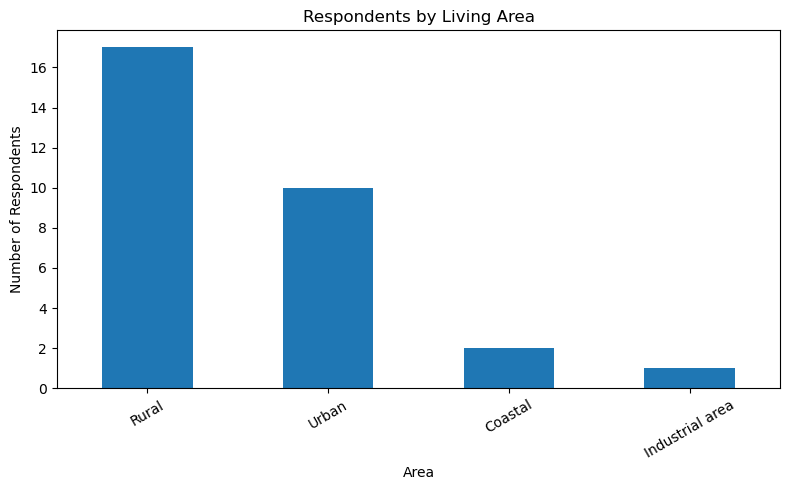

In [8]:
import matplotlib.pyplot as plt

area_col = "1. Which area do you live in?"

area_counts = survey_df[area_col].value_counts()

print("Respondents by area:")
display(area_counts)

area_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Respondents by Living Area"
)

plt.xlabel("Area")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Extreme weather experiences:


2.Have you experienced extreme weather events in your area?
Yes, occasionally    13
Yes, frequently      12
Rarely                5
Name: count, dtype: int64

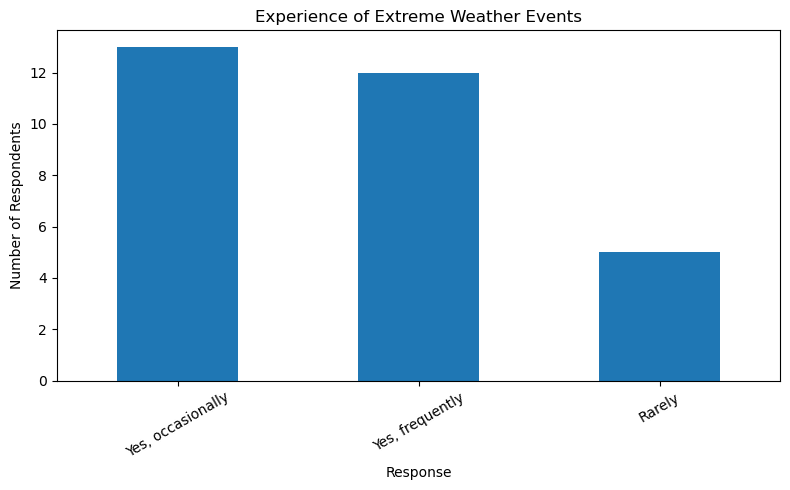

In [9]:
experience_col = "2.Have you experienced extreme weather events in your area?"

experience_counts = survey_df[experience_col].value_counts()

print("Extreme weather experiences:")
display(experience_counts)

experience_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Experience of Extreme Weather Events"
)

plt.xlabel("Response")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Types of extreme weather events:


3. Which extreme weather events have you experienced?
Heatwaves         14
Heavy rainfall    12
Thunderstorms      3
Floods             1
Name: count, dtype: int64

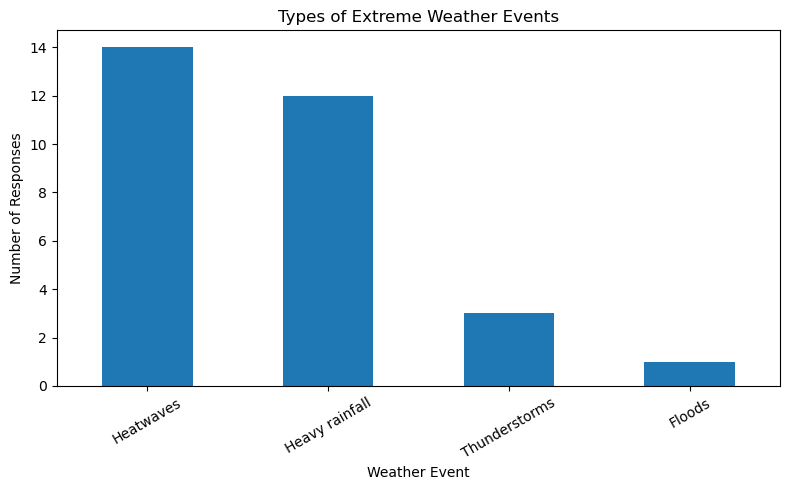

In [10]:
event_col = "3. Which extreme weather events have you experienced?"

event_counts = survey_df[event_col].value_counts()

print("Types of extreme weather events:")
display(event_counts)

event_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Types of Extreme Weather Events"
)

plt.xlabel("Weather Event")
plt.ylabel("Number of Responses")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Interest in an early warning system:


11.Would you find an early warning system for sudden local weather anomalies useful?
Useful             18
Very useful         8
Somewhat useful     4
Name: count, dtype: int64

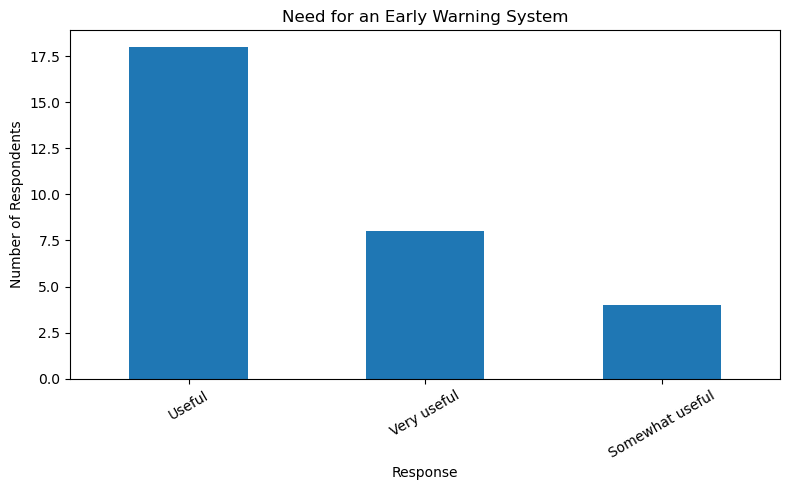

In [11]:
useful_col = "11.Would you find an early warning system for sudden local weather anomalies useful?"

useful_counts = survey_df[useful_col].value_counts()

print("Interest in an early warning system:")
display(useful_counts)

useful_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Need for an Early Warning System"
)

plt.xlabel("Response")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Trust in AI predictions:


14.Would you trust weather anomaly predictions generated using Artificial Intelligence (AI)?
Somewhat trust      15
Mostly trust         9
Completely trust     3
Do not trust         2
Name: count, dtype: int64

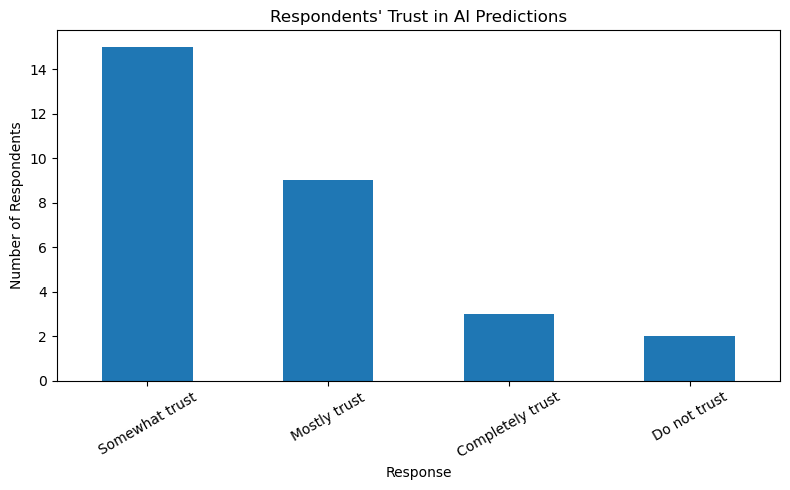

In [12]:
trust_col = "14.Would you trust weather anomaly predictions generated using Artificial Intelligence (AI)?"

trust_counts = survey_df[trust_col].value_counts()

print("Trust in AI predictions:")
display(trust_counts)

trust_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Respondents' Trust in AI Predictions"
)

plt.xlabel("Response")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [13]:
# Find the alert preference column
alert_col = "12.How would you prefer to receive early warnings?"

print("Available alert preference responses:")
display(survey_df[alert_col].dropna().value_counts())

Available alert preference responses:


12.How would you prefer to receive early warnings?
SMS                                                                    5
Local siren or public announcement                                     4
Mobile app notification                                                4
WhatsApp                                                               3
Email                                                                  2
SMS;Mobile app notification                                            2
WhatsApp;Phone call                                                    1
SMS;Phone call;Local siren or public announcement                      1
Mobile app notification;WhatsApp;Local siren or public announcement    1
Phone call                                                             1
WhatsApp;Local siren or public announcement                            1
SMS;Local siren or public announcement                                 1
Mobile app notification;Local siren or public announcement             1


In [14]:
import re

alert_responses = survey_df[alert_col].dropna()

alert_methods = []

for response in alert_responses:
    methods = re.split(r"[,;]", str(response))

    for method in methods:
        method = method.strip()
        if method:
            alert_methods.append(method)

alert_counts = pd.Series(alert_methods).value_counts()

print("Preferred alert methods:")
display(alert_counts)

Preferred alert methods:


SMS                                   11
Local siren or public announcement    10
Mobile app notification                9
WhatsApp                               8
Phone call                             3
Email                                  3
Name: count, dtype: int64

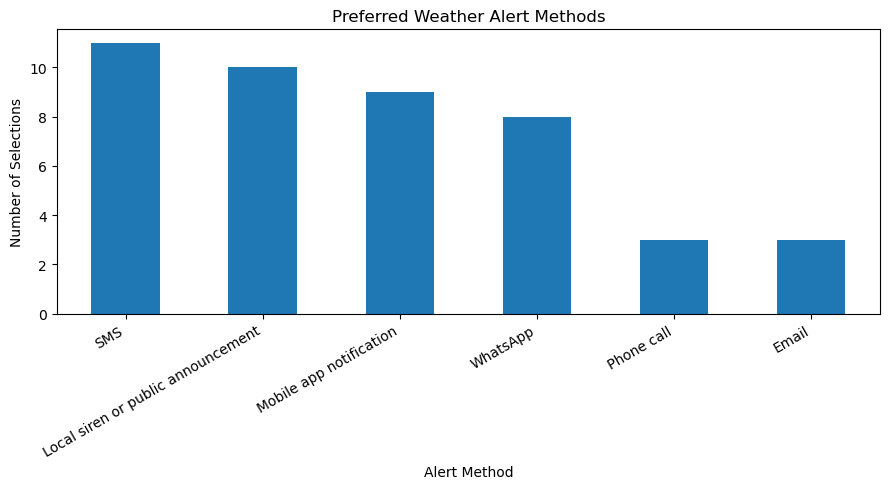

In [15]:
alert_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Preferred Weather Alert Methods"
)

plt.xlabel("Alert Method")
plt.ylabel("Number of Selections")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [16]:
feature_col = "13.What features would you like in an Extreme Weather & Micro-Climate Anomaly Early Warning System?"

print("Requested system features:")
display(survey_df[feature_col].dropna())

Requested system features:


0     Real-time weather monitoring;Location-specific...
1                          Real-time weather monitoring
2     Real-time weather monitoring;Heavy rainfall an...
3                     Heavy rainfall and flood warnings
4                         Temperature anomaly detection
5                              Location-specific alerts
6     Real-time weather monitoring;Location-specific...
7        Location-specific alerts;Risk level indicators
8                     Heavy rainfall and flood warnings
9                     Heavy rainfall and flood warnings
10                    Heavy rainfall and flood warnings
11                    Heavy rainfall and flood warnings
12    Real-time weather monitoring;Location-specific...
13    Temperature anomaly detection;Heavy rainfall a...
14                         Real-time weather monitoring
15                         Real-time weather monitoring
16                             Location-specific alerts
17    Real-time weather monitoring;Temperature a

In [17]:
improvement_col = "15.What improvements would make an early warning system more effective in your area?"

print("Respondents' suggestions:")
display(survey_df[improvement_col].dropna())

Respondents' suggestions:


0                           Offline alerts
1                More accurate predictions
2     Better flood and heat risk detection
3                More accurate predictions
4             Local-language notifications
5             Local-language notifications
6             Local-language notifications
7                More accurate predictions
8             Local-language notifications
9                            Faster alerts
10            Local-language notifications
11            Local-language notifications
12                           Faster alerts
13    Better flood and heat risk detection
14               More accurate predictions
15               More accurate predictions
16                           Faster alerts
17                           Faster alerts
18               More accurate predictions
19            Local-language notifications
20                           Faster alerts
21            Local-language notifications
22            Local-language notifications
23         

In [18]:
alert_counts.to_csv("preferred_alert_methods.csv", header=["Count"])

print("Alert preference analysis saved successfully!")

Alert preference analysis saved successfully!


In [19]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [20]:
location_name = "Chennai"

latitude = 13.0827
longitude = 80.2707

start_date = "2018-01-01"
end_date = "2025-12-31"

print("Location:", location_name)
print("Latitude:", latitude)
print("Longitude:", longitude)
print("Period:", start_date, "to", end_date)

Location: Chennai
Latitude: 13.0827
Longitude: 80.2707
Period: 2018-01-01 to 2025-12-31


In [21]:
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date,
    "end_date": end_date,
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "pressure_msl",
        "wind_speed_10m",
        "wind_direction_10m",
        "wind_gusts_10m"
    ],
    "models": "era5",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=120)

print("HTTP status:", response.status_code)

response.raise_for_status()

weather_data = response.json()

print("Weather data downloaded successfully!")

HTTP status: 200
Weather data downloaded successfully!


In [22]:
weather_df = pd.DataFrame(weather_data["hourly"])

weather_df["time"] = pd.to_datetime(weather_df["time"])

weather_df["location"] = location_name

print("Dataset created successfully!")
print("Dataset shape:", weather_df.shape)

display(weather_df.head())

Dataset created successfully!
Dataset shape: (70128, 9)


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,location
0,2018-01-01 00:00:00,24.5,88,0.0,1010.5,10.5,354,17.6,Chennai
1,2018-01-01 01:00:00,24.3,89,0.0,1010.0,9.9,341,15.5,Chennai
2,2018-01-01 02:00:00,24.3,89,0.0,1009.2,9.5,335,15.5,Chennai
3,2018-01-01 03:00:00,24.1,90,0.0,1009.2,7.7,323,15.1,Chennai
4,2018-01-01 04:00:00,23.9,91,0.0,1009.0,7.7,319,14.0,Chennai


In [23]:
print("Column names:")
print(weather_df.columns.tolist())

print("\nMissing values:")
display(weather_df.isnull().sum())

print("\nDataset information:")
weather_df.info()

Column names:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'pressure_msl', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'location']

Missing values:


time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
wind_direction_10m      0
wind_gusts_10m          0
location                0
dtype: int64


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70128 entries, 0 to 70127
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  70128 non-null  datetime64[ns]
 1   temperature_2m        70128 non-null  float64       
 2   relative_humidity_2m  70128 non-null  int64         
 3   precipitation         70128 non-null  float64       
 4   pressure_msl          70128 non-null  float64       
 5   wind_speed_10m        70128 non-null  float64       
 6   wind_direction_10m    70128 non-null  int64         
 7   wind_gusts_10m        70128 non-null  float64       
 8   location              70128 non-null  object        
dtypes: datetime64[ns](1), float64(5), int64(2), object(1)
memory usage: 4.8+ MB


In [24]:
weather_df.to_csv(
    "chennai_historical_weather.csv",
    index=False
)

print("Weather dataset saved successfully!")

Weather dataset saved successfully!


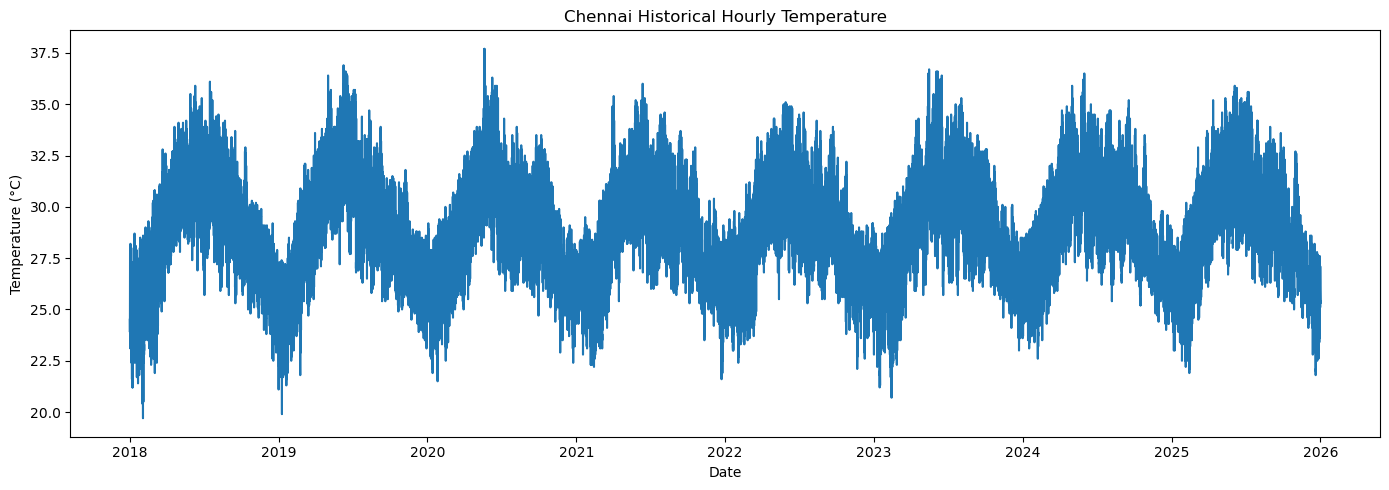

In [25]:
plt.figure(figsize=(14, 5))

plt.plot(
    weather_df["time"],
    weather_df["temperature_2m"]
)

plt.title("Chennai Historical Hourly Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.tight_layout()
plt.show()

In [26]:
print("Dataset shape:", weather_df.shape)

print("\nColumn names:")
print(weather_df.columns.tolist())

print("\nFirst 10 records:")
display(weather_df.head(10))

Dataset shape: (70128, 9)

Column names:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'pressure_msl', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'location']

First 10 records:


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,location
0,2018-01-01 00:00:00,24.5,88,0.0,1010.5,10.5,354,17.6,Chennai
1,2018-01-01 01:00:00,24.3,89,0.0,1010.0,9.9,341,15.5,Chennai
2,2018-01-01 02:00:00,24.3,89,0.0,1009.2,9.5,335,15.5,Chennai
3,2018-01-01 03:00:00,24.1,90,0.0,1009.2,7.7,323,15.1,Chennai
4,2018-01-01 04:00:00,23.9,91,0.0,1009.0,7.7,319,14.0,Chennai
5,2018-01-01 05:00:00,24.0,90,0.0,1008.9,8.2,311,13.7,Chennai
6,2018-01-01 06:00:00,24.0,90,0.0,1009.6,8.5,306,13.7,Chennai
7,2018-01-01 07:00:00,24.6,86,0.0,1010.3,9.8,306,17.3,Chennai
8,2018-01-01 08:00:00,24.8,85,0.0,1011.4,10.0,322,19.1,Chennai
9,2018-01-01 09:00:00,25.2,86,0.0,1011.9,12.2,341,22.0,Chennai


In [27]:
missing_values = weather_df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

total_missing = weather_df.isnull().sum().sum()

print("Total missing values:", total_missing)

Missing values in each column:


time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
wind_direction_10m      0
wind_gusts_10m          0
location                0
dtype: int64

Total missing values: 0


In [28]:
duplicate_count = weather_df.duplicated(
    subset=["time", "location"]
).sum()

print("Duplicate weather records:", duplicate_count)

Duplicate weather records: 0


In [29]:
print("First observation:", weather_df["time"].min())
print("Last observation:", weather_df["time"].max())

time_difference = weather_df["time"].diff()

print("\nTime interval frequency:")
display(time_difference.value_counts().head())

First observation: 2018-01-01 00:00:00
Last observation: 2025-12-31 23:00:00

Time interval frequency:


time
0 days 01:00:00    70127
Name: count, dtype: int64

In [30]:
print("Temperature range:")
print(
    weather_df["temperature_2m"].min(),
    "to",
    weather_df["temperature_2m"].max()
)

print("\nHumidity range:")
print(
    weather_df["relative_humidity_2m"].min(),
    "to",
    weather_df["relative_humidity_2m"].max()
)

print("\nRainfall range:")
print(
    weather_df["precipitation"].min(),
    "to",
    weather_df["precipitation"].max()
)

print("\nWind speed range:")
print(
    weather_df["wind_speed_10m"].min(),
    "to",
    weather_df["wind_speed_10m"].max()
)

Temperature range:
19.7 to 37.7

Humidity range:
39 to 100

Rainfall range:
0.0 to 16.4

Wind speed range:
0.0 to 54.2


In [31]:
invalid_values = {
    "temperature_2m": (
        (weather_df["temperature_2m"] < -10) |
        (weather_df["temperature_2m"] > 60)
    ),
    "relative_humidity_2m": (
        (weather_df["relative_humidity_2m"] < 0) |
        (weather_df["relative_humidity_2m"] > 100)
    ),
    "precipitation": (
        weather_df["precipitation"] < 0
    ),
    "pressure_msl": (
        (weather_df["pressure_msl"] < 800) |
        (weather_df["pressure_msl"] > 1100)
    ),
    "wind_speed_10m": (
        weather_df["wind_speed_10m"] < 0
    ),
    "wind_direction_10m": (
        (weather_df["wind_direction_10m"] < 0) |
        (weather_df["wind_direction_10m"] > 360)
    ),
    "wind_gusts_10m": (
        weather_df["wind_gusts_10m"] < 0
    )
}

for column, condition in invalid_values.items():
    print(column, ":", condition.sum(), "potentially invalid records")

temperature_2m : 0 potentially invalid records
relative_humidity_2m : 0 potentially invalid records
precipitation : 0 potentially invalid records
pressure_msl : 0 potentially invalid records
wind_speed_10m : 0 potentially invalid records
wind_direction_10m : 0 potentially invalid records
wind_gusts_10m : 0 potentially invalid records


In [32]:
display(weather_df.describe())

,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m
count,70128,70128.000000,70128.000000,70128.000000,70128.000000,70128.000000,70128.000000,70128.000000
mean,2021-12-31 23:30:00,28.466630,77.215292,0.131321,1008.947067,12.969889,152.961499,23.051269
min,2018-01-01 00:00:00,19.700000,39.000000,0.000000,995.400000,0.000000,0.000000,3.200000
25%,2020-01-01 11:45:00,26.700000,70.000000,0.000000,1005.800000,9.400000,66.000000,17.300000
50%,2021-12-31 23:30:00,28.400000,79.000000,0.000000,1008.900000,13.000000,162.000000,22.700000
75%,2024-01-01 11:15:00,30.100000,85.000000,0.000000,1012.100000,16.300000,219.000000,28.100000
max,2025-12-31 23:00:00,37.700000,100.000000,16.400000,1020.800000,54.200000,360.000000,87.100000
std,NaN,2.534041,9.977681,0.564098,3.958502,5.117894,86.708999,8.006175


In [33]:
validation_report = pd.DataFrame({
    "Column": weather_df.columns,
    "Missing Values": [
        weather_df[col].isnull().sum()
        for col in weather_df.columns
    ],
    "Data Type": [
        str(weather_df[col].dtype)
        for col in weather_df.columns
    ]
})

display(validation_report)

validation_report.to_csv(
    "weather_validation_report.csv",
    index=False
)

print("Validation report saved successfully!")

,Column,Missing Values,Data Type
0,time,0,datetime64[ns]
1,temperature_2m,0,float64
2,relative_humidity_2m,0,int64
3,precipitation,0,float64
4,pressure_msl,0,float64
5,wind_speed_10m,0,float64
6,wind_direction_10m,0,int64
7,wind_gusts_10m,0,float64
8,location,0,object


Validation report saved successfully!


In [34]:
cities = {
    "Chennai": {
        "state": "Tamil Nadu",
        "latitude": 13.0827,
        "longitude": 80.2707
    },
    "Bengaluru": {
        "state": "Karnataka",
        "latitude": 12.9716,
        "longitude": 77.5946
    },
    "Mumbai": {
        "state": "Maharashtra",
        "latitude": 19.0760,
        "longitude": 72.8777
    },
    "Delhi": {
        "state": "Delhi",
        "latitude": 28.6139,
        "longitude": 77.2090
    },
    "Kolkata": {
        "state": "West Bengal",
        "latitude": 22.5726,
        "longitude": 88.3639
    },
    "Hyderabad": {
        "state": "Telangana",
        "latitude": 17.3850,
        "longitude": 78.4867
    },
    "Jaipur": {
        "state": "Rajasthan",
        "latitude": 26.9124,
        "longitude": 75.7873
    },
    "Guwahati": {
        "state": "Assam",
        "latitude": 26.1445,
        "longitude": 91.7362
    },
    "Srinagar": {
        "state": "Jammu and Kashmir",
        "latitude": 34.0837,
        "longitude": 74.7973
    },
    "Thiruvananthapuram": {
        "state": "Kerala",
        "latitude": 8.5241,
        "longitude": 76.9366
    },
    "Bhopal": {
        "state": "Madhya Pradesh",
        "latitude": 23.2599,
        "longitude": 77.4126
    },
    "Leh": {
        "state": "Ladakh",
        "latitude": 34.1526,
        "longitude": 77.5771
    }
}

cities_df = pd.DataFrame(cities).T

display(cities_df)
print("Total locations:", len(cities))

,state,latitude,longitude
Chennai,Tamil Nadu,13.0827,80.2707
Bengaluru,Karnataka,12.9716,77.5946
Mumbai,Maharashtra,19.076,72.8777
Delhi,Delhi,28.6139,77.209
Kolkata,West Bengal,22.5726,88.3639
Hyderabad,Telangana,17.385,78.4867
Jaipur,Rajasthan,26.9124,75.7873
Guwahati,Assam,26.1445,91.7362
Srinagar,Jammu and Kashmir,34.0837,74.7973
Thiruvananthapuram,Kerala,8.5241,76.9366


Total locations: 12


In [35]:
import requests
import pandas as pd
import time

START_DATE = "2018-01-01"
END_DATE = "2025-12-31"

API_URL = "https://archive-api.open-meteo.com/v1/archive"

WEATHER_VARIABLES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

def collect_weather(city, details):

    params = {
        "latitude": details["latitude"],
        "longitude": details["longitude"],
        "start_date": START_DATE,
        "end_date": END_DATE,
        "hourly": WEATHER_VARIABLES,
        "models": "era5",
        "timezone": "Asia/Kolkata"
    }

    response = requests.get(
        API_URL,
        params=params,
        timeout=180
    )

    response.raise_for_status()

    data = response.json()

    city_df = pd.DataFrame(data["hourly"])

    city_df["time"] = pd.to_datetime(city_df["time"])
    city_df["city"] = city
    city_df["state"] = details["state"]
    city_df["latitude"] = details["latitude"]
    city_df["longitude"] = details["longitude"]

    return city_df

print("Weather collection function created successfully!")

Weather collection function created successfully!


In [40]:
weather_datasets = []
download_errors = []

for city, details in cities.items():

    try:
        print("Downloading:", city)

        city_data = collect_weather(city, details)

        weather_datasets.append(city_data)

        print(
            city,
            "downloaded successfully:",
            len(city_data),
            "records"
        )

    except Exception as e:

        download_errors.append({
            "city": city,
            "error": str(e)
        })

        print("Download failed for:", city)
        print("Error:", e)

    time.sleep(1)

print("\nDownload process completed.")
print("Successful locations:", len(weather_datasets))
print("Failed locations:", len(download_errors))

Downloading: Chennai
Chennai downloaded successfully: 70128 records
Downloading: Bengaluru
Bengaluru downloaded successfully: 70128 records
Downloading: Mumbai
Mumbai downloaded successfully: 70128 records
Downloading: Delhi
Delhi downloaded successfully: 70128 records
Downloading: Kolkata
Kolkata downloaded successfully: 70128 records
Downloading: Hyderabad
Download failed for: Hyderabad
Error: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=17.385&longitude=78.4867&start_date=2018-01-01&end_date=2025-12-31&hourly=temperature_2m&hourly=relative_humidity_2m&hourly=precipitation&hourly=pressure_msl&hourly=wind_speed_10m&hourly=wind_direction_10m&hourly=wind_gusts_10m&models=era5&timezone=Asia%2FKolkata
Downloading: Jaipur
Download failed for: Jaipur
Error: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=26.9124&longitude=75.7873&start_date=2018-01-01&end_date=2025-12-31&hourly=tempera

In [38]:
city_record_counts = (
    india_weather_df.groupby("city")
    .size()
    .sort_values(ascending=False)
)

display(city_record_counts)

city_record_counts.plot(
    kind="bar",
    figsize=(12, 5),
    title="Weather Records Collected by City"
)

plt.xlabel("City")
plt.ylabel("Number of Hourly Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Combined weather dataset created!
Dataset shape: (490896, 12)


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude
0,2018-01-01 00:00:00,17.3,78,0.0,1012.9,8.4,110,15.1,Bengaluru,Karnataka,12.9716,77.5946
1,2018-01-01 01:00:00,16.4,86,0.0,1012.6,8.3,108,15.5,Bengaluru,Karnataka,12.9716,77.5946
2,2018-01-01 02:00:00,16.3,89,0.0,1011.9,7.4,104,14.8,Bengaluru,Karnataka,12.9716,77.5946
3,2018-01-01 03:00:00,16.2,94,0.0,1011.8,7.5,107,12.6,Bengaluru,Karnataka,12.9716,77.5946
4,2018-01-01 04:00:00,16.1,95,0.0,1011.9,6.6,103,11.5,Bengaluru,Karnataka,12.9716,77.5946
5,2018-01-01 05:00:00,17.2,89,0.0,1011.7,5.5,101,10.1,Bengaluru,Karnataka,12.9716,77.5946
6,2018-01-01 06:00:00,16.8,90,0.0,1012.1,5.9,101,10.1,Bengaluru,Karnataka,12.9716,77.5946
7,2018-01-01 07:00:00,18.2,87,0.0,1013.0,6.3,103,9.7,Bengaluru,Karnataka,12.9716,77.5946
8,2018-01-01 08:00:00,18.6,86,0.0,1014.0,4.1,128,13.3,Bengaluru,Karnataka,12.9716,77.5946
9,2018-01-01 09:00:00,19.0,82,0.0,1014.2,4.6,162,16.6,Bengaluru,Karnataka,12.9716,77.5946


In [41]:
india_weather_df.to_csv(
    "india_multi_city_weather.csv",
    index=False
)

print("India multi-city weather dataset saved successfully!")

India multi-city weather dataset saved successfully!


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the combined dataset from the saved CSV
india_weather_df = pd.read_csv("india_multi_city_weather.csv")

india_weather_df["time"] = pd.to_datetime(
    india_weather_df["time"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", india_weather_df.shape)

display(india_weather_df.head())

Dataset loaded successfully!
Dataset shape: (490896, 12)


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude
0,2018-01-01 00:00:00,17.3,78,0.0,1012.9,8.4,110,15.1,Bengaluru,Karnataka,12.9716,77.5946
1,2018-01-01 01:00:00,16.4,86,0.0,1012.6,8.3,108,15.5,Bengaluru,Karnataka,12.9716,77.5946
2,2018-01-01 02:00:00,16.3,89,0.0,1011.9,7.4,104,14.8,Bengaluru,Karnataka,12.9716,77.5946
3,2018-01-01 03:00:00,16.2,94,0.0,1011.8,7.5,107,12.6,Bengaluru,Karnataka,12.9716,77.5946
4,2018-01-01 04:00:00,16.1,95,0.0,1011.9,6.6,103,11.5,Bengaluru,Karnataka,12.9716,77.5946


In [43]:
city_counts = (
    india_weather_df.groupby("city")
    .size()
    .sort_values(ascending=False)
)

display(city_counts)

print("Number of cities:", india_weather_df["city"].nunique())
print("Total weather records:", len(india_weather_df))

city
Bengaluru    70128
Chennai      70128
Delhi        70128
Hyderabad    70128
Jaipur       70128
Kolkata      70128
Mumbai       70128
dtype: int64

Number of cities: 7
Total weather records: 490896


In [44]:
missing_summary = pd.DataFrame({
    "Missing_Count": india_weather_df.isnull().sum(),
    "Missing_Percentage": (
        india_weather_df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing_Count,Missing_Percentage
time,0,0.0
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
precipitation,0,0.0
pressure_msl,0,0.0
wind_speed_10m,0,0.0
wind_direction_10m,0,0.0
wind_gusts_10m,0,0.0
city,0,0.0
state,0,0.0


In [45]:
duplicate_count = india_weather_df.duplicated(
    subset=["city", "time"]
).sum()

print("Duplicate city-time records:", duplicate_count)

Duplicate city-time records: 0


In [46]:
gap_results = []

for city, group in india_weather_df.groupby("city"):

    timestamps = (
        group["time"]
        .dropna()
        .sort_values()
    )

    gaps = timestamps.diff()

    gap_results.append({
        "City": city,
        "First_Timestamp": timestamps.min(),
        "Last_Timestamp": timestamps.max(),
        "Number_of_Timestamps": len(timestamps),
        "Gaps_Greater_Than_1_Hour": (gaps > pd.Timedelta(hours=1)).sum()
    })

gap_report = pd.DataFrame(gap_results)

display(gap_report)

,City,First_Timestamp,Last_Timestamp,Number_of_Timestamps,Gaps_Greater_Than_1_Hour
0,Bengaluru,2018-01-01,2025-12-31 23:00:00,70128,0
1,Chennai,2018-01-01,2025-12-31 23:00:00,70128,0
2,Delhi,2018-01-01,2025-12-31 23:00:00,70128,0
3,Hyderabad,2018-01-01,2025-12-31 23:00:00,70128,0
4,Jaipur,2018-01-01,2025-12-31 23:00:00,70128,0
5,Kolkata,2018-01-01,2025-12-31 23:00:00,70128,0
6,Mumbai,2018-01-01,2025-12-31 23:00:00,70128,0


In [47]:
weather_limits = {
    "temperature_2m": (-10, 60),
    "relative_humidity_2m": (0, 100),
    "precipitation": (0, None),
    "pressure_msl": (800, 1100),
    "wind_speed_10m": (0, None),
    "wind_direction_10m": (0, 360),
    "wind_gusts_10m": (0, None)
}

for column, (lower, upper) in weather_limits.items():

    values = india_weather_df[column]

    invalid = pd.Series(False, index=india_weather_df.index)

    if lower is not None:
        invalid |= values < lower

    if upper is not None:
        invalid |= values > upper

    print(
        column,
        "- potentially invalid records:",
        int(invalid.sum())
    )

temperature_2m - potentially invalid records: 0
relative_humidity_2m - potentially invalid records: 0
precipitation - potentially invalid records: 0
pressure_msl - potentially invalid records: 0
wind_speed_10m - potentially invalid records: 0
wind_direction_10m - potentially invalid records: 0
wind_gusts_10m - potentially invalid records: 0


In [48]:
weather_summary = (
    india_weather_df
    .groupby("city")[
        [
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "pressure_msl",
            "wind_speed_10m",
            "wind_gusts_10m"
        ]
    ]
    .agg(["mean", "min", "max", "std"])
)

display(weather_summary)

temperature_2m                       relative_humidity_2m           \
                    mean   min   max       std                 mean min  max   
city                                                                           
Bengaluru      23.873558  12.3  37.4  3.676812            71.354651  14  100   
Chennai        28.466630  19.7  37.7  2.534041            77.215292  39  100   
Delhi          24.974750   2.5  46.5  8.227224            67.324706   8  100   
Hyderabad      26.517251  10.7  42.2  4.636845            66.104081  14  100   
Jaipur         24.968044   2.6  46.3  7.872618            58.628579   5  100   
Kolkata        26.610797   9.6  42.9  5.197787            78.957934  18  100   
Mumbai         27.224343  14.6  37.4  3.092197            75.640472  23  100   

                     precipitation       ... pressure_msl            \
                 std          mean  min  ...          max       std   
city                                     ...                          
Bengaluru  19.230077      0.121188  0.0  ...       1022.3  3.123609   
Chennai     9.977681      0.131321  0.0  ...       1020.8  3.958502   
Delhi      21.217995      0.087409  0.0  ...       1027.8  7.260105   
Hyderabad  19.296638      0.113334  0.0  ...       1022.7  4.497436   
Jaipur     22.828708      0.070825  0.0  ...       1027.2  6.945400   
Kolkata    14.961161      0.190513  0.0  ...       1022.9  6.193959   
Mumbai     14.362709      0.249089  0.0  ...       1020.2  3.780805   

          wind_speed_10m                      wind_gusts_10m              \
                    mean  min   max       std           mean  min    max   
city                                                                       
Bengaluru      10.875150  0.2  36.9  5.104576      23.252744  1.8   82.8   
Chennai        12.969889  0.0  54.2  5.117894      23.051269  3.2   87.1   
Delhi           8.824027  0.0  32.3  4.232541      17.602582  0.7   75.2   
Hyderabad      10.932800  0.0  36.7  5.540957      22.325009  1.8   85.0   
Jaipur          9.068714  0.0  36.7  4.300034      18.394213  1.8   67.3   
Kolkata         8.954530  0.0  49.6  4.350803      18.594249  1.1  102.6   
Mumbai         11.184413  0.0  53.9  6.011775      20.992880  2.9   99.4   

                      
                 std  
city                  
Bengaluru  10.442035  
Chennai     8.006175  
Delhi       8.525155  
Hyderabad  11.131916  
Jaipur      8.544569  
Kolkata     8.960479  
Mumbai     10.222217  

[7 rows x 24 columns]

In [49]:
missing_summary.to_csv(
    "india_weather_missing_values.csv"
)

gap_report.to_csv(
    "india_weather_timestamp_gaps.csv",
    index=False
)

weather_summary.to_csv(
    "india_weather_city_statistics.csv"
)

print("All Step 8 validation reports saved successfully!")

All Step 8 validation reports saved successfully!


In [50]:
import pandas as pd
import numpy as np

india_weather_df = pd.read_csv("india_multi_city_weather.csv")

india_weather_df["time"] = pd.to_datetime(
    india_weather_df["time"]
)

# Preserve the original dataset
weather_clean_df = india_weather_df.copy()

print("Original dataset shape:", india_weather_df.shape)
print("Working dataset shape:", weather_clean_df.shape)

Original dataset shape: (490896, 12)
Working dataset shape: (490896, 12)


In [51]:
duplicate_mask = weather_clean_df.duplicated(
    subset=["city", "time"],
    keep=False
)

print("Duplicate records:", duplicate_mask.sum())

display(
    weather_clean_df[duplicate_mask]
    .sort_values(["city", "time"])
    .head(20)
)

Duplicate records: 0


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude


In [52]:
weather_clean_df = weather_clean_df.drop_duplicates(
    subset=["city", "time"],
    keep="first"
)

print("Shape after duplicate removal:", weather_clean_df.shape)

Shape after duplicate removal: (490896, 12)


In [53]:
weather_clean_df = weather_clean_df.sort_values(
    by=["city", "time"]
).reset_index(drop=True)

print("Dataset sorted successfully!")

display(weather_clean_df.head())

Dataset sorted successfully!


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude
0,2018-01-01 00:00:00,17.3,78,0.0,1012.9,8.4,110,15.1,Bengaluru,Karnataka,12.9716,77.5946
1,2018-01-01 01:00:00,16.4,86,0.0,1012.6,8.3,108,15.5,Bengaluru,Karnataka,12.9716,77.5946
2,2018-01-01 02:00:00,16.3,89,0.0,1011.9,7.4,104,14.8,Bengaluru,Karnataka,12.9716,77.5946
3,2018-01-01 03:00:00,16.2,94,0.0,1011.8,7.5,107,12.6,Bengaluru,Karnataka,12.9716,77.5946
4,2018-01-01 04:00:00,16.1,95,0.0,1011.9,6.6,103,11.5,Bengaluru,Karnataka,12.9716,77.5946


In [55]:
for col in weather_columns:
    weather_clean_df[col + "_was_missing"] = (
        weather_clean_df[col].isna().astype(int)
    )

print("Missing-value indicators created!")

Missing-value indicators created!


In [4]:
import pandas as pd
import numpy as np

india_weather_df = pd.read_csv("india_multi_city_weather.csv")

india_weather_df["time"] = pd.to_datetime(
    india_weather_df["time"]
)

# Preserve the original dataset
weather_clean_df = india_weather_df.copy()

print("Original dataset shape:", india_weather_df.shape)
print("Working dataset shape:", weather_clean_df.shape)

Original dataset shape: (490896, 12)
Working dataset shape: (490896, 12)


In [5]:
duplicate_mask = weather_clean_df.duplicated(
    subset=["city", "time"],
    keep=False
)

print("Duplicate records:", duplicate_mask.sum())

display(
    weather_clean_df[duplicate_mask]
    .sort_values(["city", "time"])
    .head(20)
)

Duplicate records: 0


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude


In [6]:
weather_clean_df = weather_clean_df.drop_duplicates(
    subset=["city", "time"],
    keep="first"
)

print("Shape after duplicate removal:", weather_clean_df.shape)

Shape after duplicate removal: (490896, 12)


In [7]:
weather_clean_df = weather_clean_df.sort_values(
    by=["city", "time"]
).reset_index(drop=True)

print("Dataset sorted successfully!")

display(weather_clean_df.head())

Dataset sorted successfully!


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude
0,2018-01-01 00:00:00,17.3,78,0.0,1012.9,8.4,110,15.1,Bengaluru,Karnataka,12.9716,77.5946
1,2018-01-01 01:00:00,16.4,86,0.0,1012.6,8.3,108,15.5,Bengaluru,Karnataka,12.9716,77.5946
2,2018-01-01 02:00:00,16.3,89,0.0,1011.9,7.4,104,14.8,Bengaluru,Karnataka,12.9716,77.5946
3,2018-01-01 03:00:00,16.2,94,0.0,1011.8,7.5,107,12.6,Bengaluru,Karnataka,12.9716,77.5946
4,2018-01-01 04:00:00,16.1,95,0.0,1011.9,6.6,103,11.5,Bengaluru,Karnataka,12.9716,77.5946


In [8]:
weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

missing_percentage = (
    weather_clean_df[weather_columns]
    .isnull()
    .mean() * 100
).round(2)

display(missing_percentage)

temperature_2m          0.0
relative_humidity_2m    0.0
precipitation           0.0
pressure_msl            0.0
wind_speed_10m          0.0
wind_direction_10m      0.0
wind_gusts_10m          0.0
dtype: float64

In [9]:
for col in weather_columns:
    weather_clean_df[col + "_was_missing"] = (
        weather_clean_df[col].isna().astype(int)
    )

print("Missing-value indicators created!")

Missing-value indicators created!


In [2]:
print("Checking Jupyter Notebook...")

print("india_weather_df exists:",
      "india_weather_df" in globals())

print("weather_clean_df exists:",
      "weather_clean_df" in globals())

Checking Jupyter Notebook...
india_weather_df exists: False
weather_clean_df exists: False


In [3]:
import pandas as pd
import numpy as np
import os

print("Current folder:", os.getcwd())

print("Files in current folder:")
print(os.listdir())

Current folder: C:\Users\admin
Files in current folder:
['.anaconda', '.conda', '.config', '.continuum', '.copilot', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.vscode', '.vscode-shared', 'AppData', 'Application Data', 'chennai_historical_weather.csv', 'cleaned_survey_data.csv', 'Contacts', 'Cookies', 'DA-4,DM.ipynb', 'Documents', 'Downloads', 'eda.ipynb', 'extracted_signatures', 'Favorites', 'GANESHYAZHINI.ipynb', 'india_multi_city_weather.csv', 'india_weather_city_statistics.csv', 'india_weather_missing_values.csv', 'india_weather_timestamp_gaps.csv', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'logs', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{9d043c1d-c5fc-11ed-9314-080027ec4824}.TM.blf', 'NTUSER.DAT{9d043c1d-c5fc-11ed-9314-080027ec4824}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{9d043c1d-c5fc-11ed-9314-080027ec4824}.TMContainer00000000000000000002.regtrans-ms

In [4]:
india_weather_df = pd.read_csv(
    "india_multi_city_weather.csv"
)

india_weather_df["time"] = pd.to_datetime(
    india_weather_df["time"]
)

weather_clean_df = india_weather_df.copy()

print("SUCCESS!")
print("Dataset shape:", weather_clean_df.shape)
print("Cities:", weather_clean_df["city"].nunique())

SUCCESS!
Dataset shape: (490896, 12)
Cities: 7


In [5]:
import pandas as pd
import numpy as np
import os

file_path = "india_multi_city_weather.csv"

if os.path.exists(file_path):

    weather_clean_df = pd.read_csv(file_path)

    weather_clean_df["time"] = pd.to_datetime(
        weather_clean_df["time"]
    )

    print("Dataset loaded successfully!")

    print("Dataset shape:", weather_clean_df.shape)

    print(
        "Number of cities:",
        weather_clean_df["city"].nunique()
    )

    display(weather_clean_df.head())

else:
    print("ERROR: Dataset file not found!")
    print("Current folder:", os.getcwd())
    print("Available files:", os.listdir())

Dataset loaded successfully!
Dataset shape: (490896, 12)
Number of cities: 7


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude
0,2018-01-01 00:00:00,17.3,78,0.0,1012.9,8.4,110,15.1,Bengaluru,Karnataka,12.9716,77.5946
1,2018-01-01 01:00:00,16.4,86,0.0,1012.6,8.3,108,15.5,Bengaluru,Karnataka,12.9716,77.5946
2,2018-01-01 02:00:00,16.3,89,0.0,1011.9,7.4,104,14.8,Bengaluru,Karnataka,12.9716,77.5946
3,2018-01-01 03:00:00,16.2,94,0.0,1011.8,7.5,107,12.6,Bengaluru,Karnataka,12.9716,77.5946
4,2018-01-01 04:00:00,16.1,95,0.0,1011.9,6.6,103,11.5,Bengaluru,Karnataka,12.9716,77.5946


In [6]:
weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

print("Missing values:")
display(weather_clean_df[weather_columns].isnull().sum())

Missing values:


temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
wind_direction_10m      0
wind_gusts_10m          0
dtype: int64

In [7]:
for col in weather_columns:
    weather_clean_df[col + "_was_missing"] = (
        weather_clean_df[col].isnull().astype(int)
    )

print("Missing-value indicators created successfully!")

Missing-value indicators created successfully!


In [8]:
import os
import pandas as pd

print("Current working directory:")
print(os.getcwd())

print("\nCSV files available:")
for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

Current working directory:
C:\Users\admin

CSV files available:
chennai_historical_weather.csv
cleaned_survey_data.csv
india_multi_city_weather.csv
india_weather_city_statistics.csv
india_weather_missing_values.csv
india_weather_timestamp_gaps.csv
preferred_alert_methods.csv
weather1.csv
weather_validation_report.csv


In [9]:
weather_clean_df = pd.read_csv(
    "india_multi_city_weather.csv"
)

weather_clean_df["time"] = pd.to_datetime(
    weather_clean_df["time"]
)

print("Dataset loaded successfully!")
print("Shape:", weather_clean_df.shape)
print("Cities:", weather_clean_df["city"].nunique())

display(weather_clean_df.head())

Dataset loaded successfully!
Shape: (490896, 12)
Cities: 7


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude
0,2018-01-01 00:00:00,17.3,78,0.0,1012.9,8.4,110,15.1,Bengaluru,Karnataka,12.9716,77.5946
1,2018-01-01 01:00:00,16.4,86,0.0,1012.6,8.3,108,15.5,Bengaluru,Karnataka,12.9716,77.5946
2,2018-01-01 02:00:00,16.3,89,0.0,1011.9,7.4,104,14.8,Bengaluru,Karnataka,12.9716,77.5946
3,2018-01-01 03:00:00,16.2,94,0.0,1011.8,7.5,107,12.6,Bengaluru,Karnataka,12.9716,77.5946
4,2018-01-01 04:00:00,16.1,95,0.0,1011.9,6.6,103,11.5,Bengaluru,Karnataka,12.9716,77.5946


In [10]:
print("weather_clean_df exists:",
      "weather_clean_df" in globals())

weather_clean_df exists: True


In [11]:
import pandas as pd
import numpy as np
import os

file_path = "india_multi_city_weather.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):

    weather_clean_df = pd.read_csv(file_path)

    weather_clean_df["time"] = pd.to_datetime(
        weather_clean_df["time"]
    )

    print("Dataset loaded successfully!")
    print("Dataset shape:", weather_clean_df.shape)
    print("Available cities:", weather_clean_df["city"].nunique())

    display(weather_clean_df.head())

else:
    print("CSV file not found.")
    print("Current folder:", os.getcwd())

File exists: True
Dataset loaded successfully!
Dataset shape: (490896, 12)
Available cities: 7


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude
0,2018-01-01 00:00:00,17.3,78,0.0,1012.9,8.4,110,15.1,Bengaluru,Karnataka,12.9716,77.5946
1,2018-01-01 01:00:00,16.4,86,0.0,1012.6,8.3,108,15.5,Bengaluru,Karnataka,12.9716,77.5946
2,2018-01-01 02:00:00,16.3,89,0.0,1011.9,7.4,104,14.8,Bengaluru,Karnataka,12.9716,77.5946
3,2018-01-01 03:00:00,16.2,94,0.0,1011.8,7.5,107,12.6,Bengaluru,Karnataka,12.9716,77.5946
4,2018-01-01 04:00:00,16.1,95,0.0,1011.9,6.6,103,11.5,Bengaluru,Karnataka,12.9716,77.5946


In [12]:
weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

missing_summary = pd.DataFrame({
    "Missing_Count": weather_clean_df[weather_columns].isnull().sum(),
    "Missing_Percentage": (
        weather_clean_df[weather_columns].isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing_Count,Missing_Percentage
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
precipitation,0,0.0
pressure_msl,0,0.0
wind_speed_10m,0,0.0
wind_direction_10m,0,0.0
wind_gusts_10m,0,0.0


In [13]:
for col in weather_columns:
    weather_clean_df[col + "_was_missing"] = (
        weather_clean_df[col].isnull().astype(int)
    )

print("Missing-value indicators created successfully!")

Missing-value indicators created successfully!


In [14]:
duplicate_count = weather_clean_df.duplicated(
    subset=["city", "time"]
).sum()

print("Duplicate records:", duplicate_count)

weather_clean_df = weather_clean_df.drop_duplicates(
    subset=["city", "time"],
    keep="first"
)

print("Dataset shape after duplicate removal:",
      weather_clean_df.shape)

Duplicate records: 0
Dataset shape after duplicate removal: (490896, 19)


In [15]:
interpolation_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

weather_clean_df = weather_clean_df.sort_values(
    ["city", "time"]
).copy()

def fill_short_gaps(group):

    group = group.set_index("time")

    group[interpolation_columns] = (
        group[interpolation_columns]
        .interpolate(
            method="time",
            limit=2,
            limit_area="inside"
        )
    )

    return group.reset_index()

weather_clean_df = (
    weather_clean_df
    .groupby("city", group_keys=False)
    .apply(fill_short_gaps)
    .reset_index(drop=True)
)

print("Short-gap interpolation completed successfully!")

Short-gap interpolation completed successfully!


C:\Users\admin\AppData\Local\Temp\ipykernel_16084\1886783730.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(fill_short_gaps)


In [16]:
remaining_missing = pd.DataFrame({
    "Missing_Count": weather_clean_df[weather_columns].isnull().sum(),
    "Missing_Percentage": (
        weather_clean_df[weather_columns].isnull().mean() * 100
    ).round(2)
})

display(remaining_missing)

print(
    "Total remaining missing values:",
    weather_clean_df[weather_columns].isnull().sum().sum()
)

,Missing_Count,Missing_Percentage
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
precipitation,0,0.0
pressure_msl,0,0.0
wind_speed_10m,0,0.0
wind_direction_10m,0,0.0
wind_gusts_10m,0,0.0


Total remaining missing values: 0


In [18]:
weather_clean_df.to_csv(
    "india_weather_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", weather_clean_df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (490896, 19)


In [19]:
comparison = pd.DataFrame({
    "Original_Missing": india_weather_df[weather_columns].isnull().sum(),
    "Cleaned_Missing": weather_clean_df[weather_columns].isnull().sum()
})

display(comparison)

,Original_Missing,Cleaned_Missing
temperature_2m,0,0
relative_humidity_2m,0,0
precipitation,0,0
pressure_msl,0,0
wind_speed_10m,0,0
wind_direction_10m,0,0
wind_gusts_10m,0,0


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

weather_df = pd.read_csv("india_weather_cleaned.csv")

weather_df["time"] = pd.to_datetime(weather_df["time"])

weather_df = weather_df.sort_values(
    ["city", "time"]
).reset_index(drop=True)

print("Cleaned weather dataset loaded!")
print("Dataset shape:", weather_df.shape)

display(weather_df.head())

Cleaned weather dataset loaded!
Dataset shape: (490896, 19)


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,latitude,longitude,temperature_2m_was_missing,relative_humidity_2m_was_missing,precipitation_was_missing,pressure_msl_was_missing,wind_speed_10m_was_missing,wind_direction_10m_was_missing,wind_gusts_10m_was_missing
0,2018-01-01 00:00:00,17.3,78,0.0,1012.9,8.4,110,15.1,Bengaluru,Karnataka,12.9716,77.5946,0,0,0,0,0,0,0
1,2018-01-01 01:00:00,16.4,86,0.0,1012.6,8.3,108,15.5,Bengaluru,Karnataka,12.9716,77.5946,0,0,0,0,0,0,0
2,2018-01-01 02:00:00,16.3,89,0.0,1011.9,7.4,104,14.8,Bengaluru,Karnataka,12.9716,77.5946,0,0,0,0,0,0,0
3,2018-01-01 03:00:00,16.2,94,0.0,1011.8,7.5,107,12.6,Bengaluru,Karnataka,12.9716,77.5946,0,0,0,0,0,0,0
4,2018-01-01 04:00:00,16.1,95,0.0,1011.9,6.6,103,11.5,Bengaluru,Karnataka,12.9716,77.5946,0,0,0,0,0,0,0


In [21]:
weather_df["year"] = weather_df["time"].dt.year
weather_df["month"] = weather_df["time"].dt.month
weather_df["day"] = weather_df["time"].dt.day
weather_df["hour"] = weather_df["time"].dt.hour
weather_df["day_of_week"] = weather_df["time"].dt.dayofweek

weather_df["day_of_year"] = weather_df["time"].dt.dayofyear

print("Date and time features created!")

display(
    weather_df[
        ["time", "city", "year", "month", "hour", "day_of_year"]
    ].head()
)

Date and time features created!


,time,city,year,month,hour,day_of_year
0,2018-01-01 00:00:00,Bengaluru,2018,1,0,1
1,2018-01-01 01:00:00,Bengaluru,2018,1,1,1
2,2018-01-01 02:00:00,Bengaluru,2018,1,2,1
3,2018-01-01 03:00:00,Bengaluru,2018,1,3,1
4,2018-01-01 04:00:00,Bengaluru,2018,1,4,1


In [22]:
weather_df["temperature_change_1h"] = (
    weather_df.groupby("city")["temperature_2m"]
    .diff()
)

weather_df["temperature_change_3h"] = (
    weather_df.groupby("city")["temperature_2m"]
    .diff(3)
)

weather_df["temperature_change_24h"] = (
    weather_df.groupby("city")["temperature_2m"]
    .diff(24)
)

print("Temperature change features created!")

display(
    weather_df[
        [
            "city",
            "time",
            "temperature_2m",
            "temperature_change_1h",
            "temperature_change_3h",
            "temperature_change_24h"
        ]
    ].head(30)
)

Temperature change features created!


,city,time,temperature_2m,temperature_change_1h,temperature_change_3h,temperature_change_24h
0,Bengaluru,2018-01-01 00:00:00,17.3,NaN,NaN,NaN
1,Bengaluru,2018-01-01 01:00:00,16.4,-0.9,NaN,NaN
2,Bengaluru,2018-01-01 02:00:00,16.3,-0.1,NaN,NaN
3,Bengaluru,2018-01-01 03:00:00,16.2,-0.1,-1.1,NaN
4,Bengaluru,2018-01-01 04:00:00,16.1,-0.1,-0.3,NaN
5,Bengaluru,2018-01-01 05:00:00,17.2,1.1,0.9,NaN
6,Bengaluru,2018-01-01 06:00:00,16.8,-0.4,0.6,NaN
7,Bengaluru,2018-01-01 07:00:00,18.2,1.4,2.1,NaN
8,Bengaluru,2018-01-01 08:00:00,18.6,0.4,1.4,NaN
9,Bengaluru,2018-01-01 09:00:00,19.0,0.4,2.2,NaN


In [23]:
weather_df["temperature_rolling_mean_24h"] = (
    weather_df.groupby("city")["temperature_2m"]
    .transform(
        lambda x: x.rolling(24, min_periods=12).mean()
    )
)

weather_df["temperature_rolling_std_24h"] = (
    weather_df.groupby("city")["temperature_2m"]
    .transform(
        lambda x: x.rolling(24, min_periods=12).std()
    )
)

print("Rolling temperature features created!")

Rolling temperature features created!


In [24]:
weather_df["rainfall_3h"] = (
    weather_df.groupby("city")["precipitation"]
    .transform(
        lambda x: x.rolling(3, min_periods=3).sum()
    )
)

weather_df["rainfall_24h"] = (
    weather_df.groupby("city")["precipitation"]
    .transform(
        lambda x: x.rolling(24, min_periods=24).sum()
    )
)

print("Rainfall features created!")

display(
    weather_df[
        ["city", "time", "precipitation", "rainfall_3h", "rainfall_24h"]
    ].head(30)
)

Rainfall features created!


,city,time,precipitation,rainfall_3h,rainfall_24h
0,Bengaluru,2018-01-01 00:00:00,0.0,NaN,NaN
1,Bengaluru,2018-01-01 01:00:00,0.0,NaN,NaN
2,Bengaluru,2018-01-01 02:00:00,0.0,0.0,NaN
3,Bengaluru,2018-01-01 03:00:00,0.0,0.0,NaN
4,Bengaluru,2018-01-01 04:00:00,0.0,0.0,NaN
5,Bengaluru,2018-01-01 05:00:00,0.0,0.0,NaN
6,Bengaluru,2018-01-01 06:00:00,0.0,0.0,NaN
7,Bengaluru,2018-01-01 07:00:00,0.0,0.0,NaN
8,Bengaluru,2018-01-01 08:00:00,0.0,0.0,NaN
9,Bengaluru,2018-01-01 09:00:00,0.0,0.0,NaN


In [25]:
weather_df["wind_speed_change_1h"] = (
    weather_df.groupby("city")["wind_speed_10m"]
    .diff()
)

weather_df["wind_gust_difference"] = (
    weather_df["wind_gusts_10m"] -
    weather_df["wind_speed_10m"]
)

print("Wind features created!")

Wind features created!


In [26]:
weather_df["humidity_change_1h"] = (
    weather_df.groupby("city")["relative_humidity_2m"]
    .diff()
)

weather_df["pressure_change_1h"] = (
    weather_df.groupby("city")["pressure_msl"]
    .diff()
)

print("Humidity and pressure features created!")

Humidity and pressure features created!


In [27]:
new_features = [
    "temperature_change_1h",
    "temperature_change_3h",
    "temperature_change_24h",
    "temperature_rolling_mean_24h",
    "temperature_rolling_std_24h",
    "rainfall_3h",
    "rainfall_24h",
    "wind_speed_change_1h",
    "wind_gust_difference",
    "humidity_change_1h",
    "pressure_change_1h"
]

display(weather_df[new_features].describe())

,temperature_change_1h,temperature_change_3h,temperature_change_24h,temperature_rolling_mean_24h,temperature_rolling_std_24h,rainfall_3h,rainfall_24h,wind_speed_change_1h,wind_gust_difference,humidity_change_1h,pressure_change_1h
count,490889.000000,490875.000000,490728.000000,490819.000000,490819.000000,490882.000000,490735.000000,490889.000000,490896.000000,490889.000000,490889.000000
mean,0.000008,0.000068,-0.000206,26.091806,2.832690,0.413017,3.305084,-0.000014,10.200489,0.000090,0.000001
std,1.131168,2.601983,1.321894,4.728493,1.343127,1.593762,9.305226,1.600934,5.812048,4.611364,0.629352
min,-9.900000,-12.100000,-17.000000,5.866667,0.114208,0.000000,0.000000,-22.200000,-18.400000,-39.000000,-4.000000
25%,-0.500000,-1.500000,-0.600000,23.616667,1.733786,0.000000,0.000000,-0.800000,5.700000,-2.000000,-0.500000
50%,0.000000,-0.400000,0.000000,26.850000,2.674829,0.000000,0.000000,0.000000,9.600000,0.000000,0.000000
75%,0.400000,1.300000,0.700000,29.316667,3.879908,0.000000,2.300000,0.800000,14.000000,2.000000,0.500000
max,9.100000,14.200000,11.500000,40.358333,7.367039,80.900000,308.400000,23.600000,61.700000,43.000000,4.100000


In [30]:
weather_df.to_csv(
    "india_weather_features.csv",
    index=False
)

print("Feature-engineered dataset saved successfully!")
print("Final shape:", weather_df.shape)

Feature-engineered dataset saved successfully!
Final shape: (490896, 36)


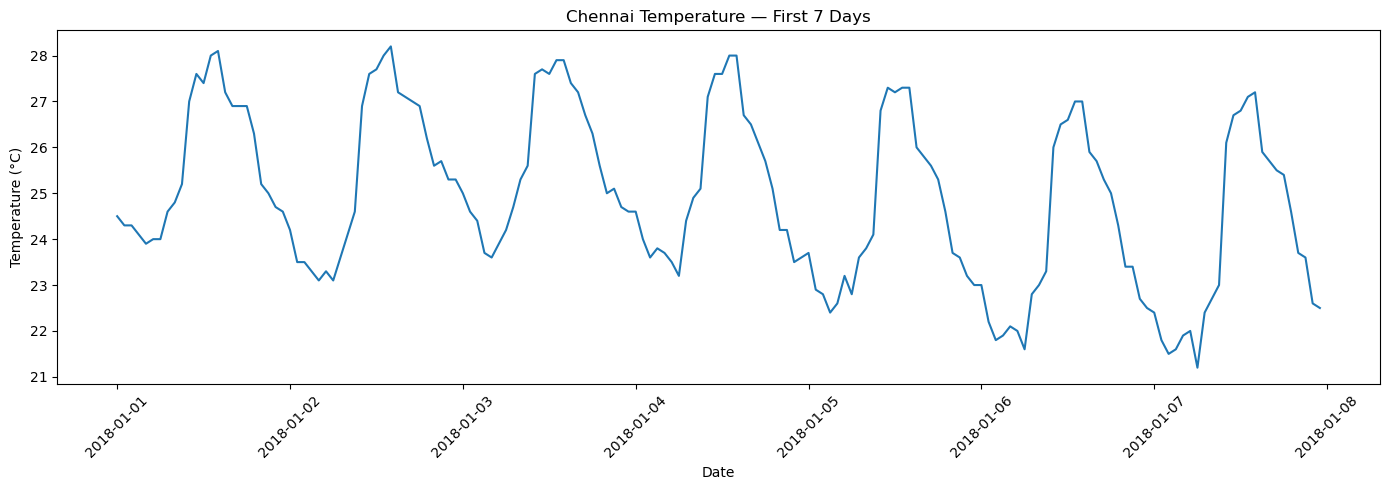

In [31]:
chennai_data = weather_df[
    weather_df["city"] == "Chennai"
].copy()

plt.figure(figsize=(14, 5))

plt.plot(
    chennai_data["time"].head(168),
    chennai_data["temperature_2m"].head(168)
)

plt.title("Chennai Temperature — First 7 Days")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [32]:

# STEP 11.1: Load and inspect weather feature dataset

import pandas as pd
import numpy as np

# Load the feature dataset
weather_df = pd.read_csv("india_weather_features.csv")

# Convert time column into datetime format
weather_df["time"] = pd.to_datetime(weather_df["time"], errors="coerce")

# Sort records by city and timestamp
weather_df = weather_df.sort_values(
    by=["city", "time"]
).reset_index(drop=True)

# Display basic information
print("Dataset Shape:", weather_df.shape)

print("\nAvailable Columns:")
print(weather_df.columns.tolist())

print("\nNumber of Cities:")
print(weather_df["city"].nunique())

print("\nRecords per City:")
print(weather_df["city"].value_counts().sort_index())

print("\nDate Range:")
print("Start:", weather_df["time"].min())
print("End:", weather_df["time"].max())

print("\nMissing Timestamp Values:")
print(weather_df["time"].isna().sum())


Dataset Shape: (490896, 36)

Available Columns:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'pressure_msl', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'city', 'state', 'latitude', 'longitude', 'temperature_2m_was_missing', 'relative_humidity_2m_was_missing', 'precipitation_was_missing', 'pressure_msl_was_missing', 'wind_speed_10m_was_missing', 'wind_direction_10m_was_missing', 'wind_gusts_10m_was_missing', 'year', 'month', 'day', 'hour', 'day_of_week', 'day_of_year', 'temperature_change_1h', 'temperature_change_3h', 'temperature_change_24h', 'temperature_rolling_mean_24h', 'temperature_rolling_std_24h', 'rainfall_3h', 'rainfall_24h', 'wind_speed_change_1h', 'wind_gust_difference', 'humidity_change_1h', 'pressure_change_1h']

Number of Cities:
7

Records per City:
city
Bengaluru    70128
Chennai      70128
Delhi        70128
Hyderabad    70128
Jaipur       70128
Kolkata      70128
Mumbai       70128
Name: count, dtype: int64

Date Range:
Start: 201

In [33]:

# STEP 11.2: Check timestamp gaps city by city

gap_results = []

for city, group in weather_df.groupby("city"):

    city_data = group.sort_values("time").copy()

    # Calculate time difference between consecutive records
    time_diff = city_data["time"].diff()

    # Count gaps greater than one hour
    missing_intervals = (time_diff > pd.Timedelta(hours=1)).sum()

    # Calculate total missing hourly timestamps
    expected_hours = int(
        (city_data["time"].max() - city_data["time"].min())
        / pd.Timedelta(hours=1)
    ) + 1

    actual_hours = city_data["time"].nunique()

    missing_hours = expected_hours - actual_hours

    gap_results.append({
        "city": city,
        "records": len(city_data),
        "gap_intervals": int(missing_intervals),
        "missing_hours": int(missing_hours),
        "duplicate_timestamps": int(city_data["time"].duplicated().sum())
    })

gap_report = pd.DataFrame(gap_results)

print(gap_report.to_string(index=False))


     city  records  gap_intervals  missing_hours  duplicate_timestamps
Bengaluru    70128              0              0                     0
  Chennai    70128              0              0                     0
    Delhi    70128              0              0                     0
Hyderabad    70128              0              0                     0
   Jaipur    70128              0              0                     0
  Kolkata    70128              0              0                     0
   Mumbai    70128              0              0                     0


In [34]:

# STEP 11.3: Identify missing hourly timestamps for each city

import pandas as pd

# Create a dictionary to store missing timestamps
missing_timestamps = {}

for city, group in weather_df.groupby("city"):

    city_data = group.sort_values("time")

    # Remove duplicate timestamps only from the timestamp index
    # Original weather_df remains unchanged
    existing_times = pd.DatetimeIndex(
        city_data["time"].dropna().drop_duplicates()
    )

    if len(existing_times) == 0:
        continue

    # Generate complete hourly timeline
    complete_times = pd.date_range(
        start=existing_times.min(),
        end=existing_times.max(),
        freq="h"
    )

    # Identify missing timestamps
    missing_times = complete_times.difference(existing_times)

    missing_timestamps[city] = missing_times

    print(f"\nCity: {city}")
    print("Existing timestamps:", len(existing_times))
    print("Expected timestamps:", len(complete_times))
    print("Missing timestamps:", len(missing_times))

    if len(missing_times) > 0:
        print("First 10 missing timestamps:")
        print(missing_times[:10].tolist())
    else:
        print("No missing hourly timestamps.")



City: Bengaluru
Existing timestamps: 70128
Expected timestamps: 70128
Missing timestamps: 0
No missing hourly timestamps.

City: Chennai
Existing timestamps: 70128
Expected timestamps: 70128
Missing timestamps: 0
No missing hourly timestamps.

City: Delhi
Existing timestamps: 70128
Expected timestamps: 70128
Missing timestamps: 0
No missing hourly timestamps.

City: Hyderabad
Existing timestamps: 70128
Expected timestamps: 70128
Missing timestamps: 0
No missing hourly timestamps.

City: Jaipur
Existing timestamps: 70128
Expected timestamps: 70128
Missing timestamps: 0
No missing hourly timestamps.

City: Kolkata
Existing timestamps: 70128
Expected timestamps: 70128
Missing timestamps: 0
No missing hourly timestamps.

City: Mumbai
Existing timestamps: 70128
Expected timestamps: 70128
Missing timestamps: 0
No missing hourly timestamps.


In [35]:

# STEP 11.4: Missing timestamp summary

missing_summary = pd.DataFrame([
    {
        "city": city,
        "missing_hours": len(times)
    }
    for city, times in missing_timestamps.items()
])

print("Missing Timestamp Summary:")
print(missing_summary.to_string(index=False))

print("\nTotal Missing Hours:",
      missing_summary["missing_hours"].sum())

print("\nCities With Missing Hours:",
      (missing_summary["missing_hours"] > 0).sum())


Missing Timestamp Summary:
     city  missing_hours
Bengaluru              0
  Chennai              0
    Delhi              0
Hyderabad              0
   Jaipur              0
  Kolkata              0
   Mumbai              0

Total Missing Hours: 0

Cities With Missing Hours: 0


In [36]:

# STEP 11.5: Reconstruct continuous hourly records for each city

reconstructed_cities = []

for city, group in weather_df.groupby("city"):

    city_data = group.copy()

    # Sort by timestamp
    city_data = city_data.sort_values("time")

    # Check duplicate timestamps
    duplicate_count = city_data["time"].duplicated().sum()

    print(f"{city}: Duplicate timestamps = {duplicate_count}")

    # Keep original rows for now.
    # Stop if duplicates exist because we must inspect them first.
    if duplicate_count > 0:
        raise ValueError(
            f"Duplicate timestamps found for {city}. "
            "Inspect duplicates before continuing."
        )

    # Set timestamp as index
    city_data = city_data.set_index("time")

    # Create complete hourly timeline
    full_index = pd.date_range(
        start=city_data.index.min(),
        end=city_data.index.max(),
        freq="h"
    )

    # Reindex without filling missing measurements
    city_data = city_data.reindex(full_index)

    # Restore city name
    city_data["city"] = city

    # Restore timestamp column
    city_data.index.name = "time"
    city_data = city_data.reset_index()

    reconstructed_cities.append(city_data)

# Combine all cities
weather_hourly_df = pd.concat(
    reconstructed_cities,
    ignore_index=True
)

# Sort final dataset
weather_hourly_df = weather_hourly_df.sort_values(
    ["city", "time"]
).reset_index(drop=True)

print("\nReconstructed Dataset Shape:")
print(weather_hourly_df.shape)

print("\nRecords per City:")
print(weather_hourly_df.groupby("city").size())


Bengaluru: Duplicate timestamps = 0
Chennai: Duplicate timestamps = 0
Delhi: Duplicate timestamps = 0
Hyderabad: Duplicate timestamps = 0
Jaipur: Duplicate timestamps = 0
Kolkata: Duplicate timestamps = 0
Mumbai: Duplicate timestamps = 0

Reconstructed Dataset Shape:
(490896, 36)

Records per City:
city
Bengaluru    70128
Chennai      70128
Delhi        70128
Hyderabad    70128
Jaipur       70128
Kolkata      70128
Mumbai       70128
dtype: int64


In [37]:

# STEP 11.6: Verify hourly continuity

continuity_results = []

for city, group in weather_hourly_df.groupby("city"):

    city_data = group.sort_values("time")

    time_diff = city_data["time"].diff()

    remaining_gaps = (
        time_diff > pd.Timedelta(hours=1)
    ).sum()

    duplicate_times = city_data["time"].duplicated().sum()

    continuity_results.append({
        "city": city,
        "records": len(city_data),
        "remaining_gaps": int(remaining_gaps),
        "duplicate_timestamps": int(duplicate_times)
    })

continuity_report = pd.DataFrame(continuity_results)

print(continuity_report.to_string(index=False))

print("\nTotal Remaining Gaps:",
      continuity_report["remaining_gaps"].sum())

print("\nTotal Duplicate Timestamps:",
      continuity_report["duplicate_timestamps"].sum())


     city  records  remaining_gaps  duplicate_timestamps
Bengaluru    70128               0                     0
  Chennai    70128               0                     0
    Delhi    70128               0                     0
Hyderabad    70128               0                     0
   Jaipur    70128               0                     0
  Kolkata    70128               0                     0
   Mumbai    70128               0                     0

Total Remaining Gaps: 0

Total Duplicate Timestamps: 0


In [43]:

# STEP 11.7: Save reconstructed hourly dataset

weather_hourly_df.to_csv(
    "india_weather_hourly_reconstructed.csv",
    index=False
)

print("Successfully saved:")
print("india_weather_hourly_reconstructed.csv")


Successfully saved:
india_weather_hourly_reconstructed.csv


In [44]:

# STEP 11.8: Check missing weather measurements by city

weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

missing_by_city = (
    weather_hourly_df
    .groupby("city")[weather_columns]
    .apply(lambda x: x.isna().sum())
)

print("Missing Weather Measurements by City:")
print(missing_by_city.to_string())

print("\nTotal Missing Values by Variable:")
print(weather_hourly_df[weather_columns].isna().sum())


Missing Weather Measurements by City:
           temperature_2m  relative_humidity_2m  precipitation  pressure_msl  wind_speed_10m  wind_direction_10m  wind_gusts_10m
city                                                                                                                            
Bengaluru               0                     0              0             0               0                   0               0
Chennai                 0                     0              0             0               0                   0               0
Delhi                   0                     0              0             0               0                   0               0
Hyderabad               0                     0              0             0               0                   0               0
Jaipur                  0                     0              0             0               0                   0               0
Kolkata                 0                     0            

In [45]:

# STEP 11.9: Calculate missing-value percentages

missing_percentage = (
    weather_hourly_df
    .groupby("city")[weather_columns]
    .apply(lambda x: x.isna().mean() * 100)
)

print("Missing Percentage by City:")
print(missing_percentage.round(2).to_string())


Missing Percentage by City:
           temperature_2m  relative_humidity_2m  precipitation  pressure_msl  wind_speed_10m  wind_direction_10m  wind_gusts_10m
city                                                                                                                            
Bengaluru             0.0                   0.0            0.0           0.0             0.0                 0.0             0.0
Chennai               0.0                   0.0            0.0           0.0             0.0                 0.0             0.0
Delhi                 0.0                   0.0            0.0           0.0             0.0                 0.0             0.0
Hyderabad             0.0                   0.0            0.0           0.0             0.0                 0.0             0.0
Jaipur                0.0                   0.0            0.0           0.0             0.0                 0.0             0.0
Kolkata               0.0                   0.0            0.0       

In [46]:

# STEP 11.10: Identify consecutive missing temperature periods

for city, group in weather_hourly_df.groupby("city"):

    city_data = group.sort_values("time").copy()

    missing_mask = city_data["temperature_2m"].isna()

    # Identify consecutive missing periods
    group_id = (~missing_mask).cumsum()

    missing_periods = (
        city_data[missing_mask]
        .groupby(group_id[missing_mask])
        .agg(
            start_time=("time", "min"),
            end_time=("time", "max"),
            missing_hours=("time", "count")
        )
    )

    print(f"\nCity: {city}")
    print("Missing temperature periods:")

    if missing_periods.empty:
        print("No missing temperature measurements.")
    else:
        print(missing_periods.to_string(index=False))



City: Bengaluru
Missing temperature periods:
No missing temperature measurements.

City: Chennai
Missing temperature periods:
No missing temperature measurements.

City: Delhi
Missing temperature periods:
No missing temperature measurements.

City: Hyderabad
Missing temperature periods:
No missing temperature measurements.

City: Jaipur
Missing temperature periods:
No missing temperature measurements.

City: Kolkata
Missing temperature periods:
No missing temperature measurements.

City: Mumbai
Missing temperature periods:
No missing temperature measurements.


In [47]:

# STEP 12.1: Analyse consecutive missing periods

weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

missing_runs = []

for city, group in weather_hourly_df.groupby("city"):

    city_data = group.sort_values("time").reset_index(drop=True)

    for column in weather_columns:

        missing_mask = city_data[column].isna()

        # Identify consecutive missing groups
        run_id = (~missing_mask).cumsum()

        missing_groups = city_data[missing_mask].groupby(
            run_id[missing_mask]
        )

        for _, run in missing_groups:

            missing_runs.append({
                "city": city,
                "variable": column,
                "start_time": run["time"].min(),
                "end_time": run["time"].max(),
                "missing_hours": len(run)
            })

missing_runs_df = pd.DataFrame(missing_runs)

if missing_runs_df.empty:
    print("No missing weather measurements found.")
else:
    print("Missing Periods:")
    print(missing_runs_df.to_string(index=False))

    print("\nMissing Period Length Summary:")
    print(
        missing_runs_df.groupby(
            ["variable", "missing_hours"]
        ).size().to_string()
    )


No missing weather measurements found.


In [48]:

# STEP 12.2: Classify missing periods

if not missing_runs_df.empty:

    def classify_gap(hours):

        if hours <= 2:
            return "Short gap (1-2 hours)"

        elif hours <= 6:
            return "Medium gap (3-6 hours)"

        else:
            return "Long gap (more than 6 hours)"

    missing_runs_df["gap_category"] = (
        missing_runs_df["missing_hours"].apply(classify_gap)
    )

    print("Gap Classification:")
    print(
        missing_runs_df.groupby(
            ["variable", "gap_category"]
        ).size().to_string()
    )
else:
    print("No missing periods to classify.")


No missing periods to classify.


In [49]:

# STEP 12.3: Save missing-period report

missing_runs_df.to_csv(
    "india_weather_missing_periods_report.csv",
    index=False
)

print("Missing-period report saved successfully.")


Missing-period report saved successfully.


In [50]:

# STEP 12.4: Create a separate dataset for missing-value treatment

weather_imputed_df = weather_hourly_df.copy()

print("Original dataset shape:", weather_hourly_df.shape)
print("Working dataset shape:", weather_imputed_df.shape)

print("\nMissing values before treatment:")
print(weather_imputed_df.isna().sum())


Original dataset shape: (490896, 36)
Working dataset shape: (490896, 36)

Missing values before treatment:
time                                  0
temperature_2m                        0
relative_humidity_2m                  0
precipitation                         0
pressure_msl                          0
wind_speed_10m                        0
wind_direction_10m                    0
wind_gusts_10m                        0
city                                  0
state                                 0
latitude                              0
longitude                             0
temperature_2m_was_missing            0
relative_humidity_2m_was_missing      0
precipitation_was_missing             0
pressure_msl_was_missing              0
wind_speed_10m_was_missing            0
wind_direction_10m_was_missing        0
wind_gusts_10m_was_missing            0
year                                  0
month                                 0
day                                   0
hour         

In [51]:

# STEP 12.5: Interpolate short gaps in selected variables

interpolation_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

for city in weather_imputed_df["city"].dropna().unique():

    city_mask = weather_imputed_df["city"] == city

    city_data = (
        weather_imputed_df.loc[city_mask]
        .sort_values("time")
        .copy()
    )

    for column in interpolation_columns:

        city_data[column] = city_data[column].interpolate(
            method="linear",
            limit=2,
            limit_area="inside"
        )

    weather_imputed_df.loc[city_data.index, interpolation_columns] = (
        city_data[interpolation_columns]
    )

print("Short-gap interpolation completed.")


Short-gap interpolation completed.


In [52]:

# STEP 12.6: Compare missing values before and after treatment

missing_comparison = pd.DataFrame({
    "Before": weather_hourly_df[weather_columns].isna().sum(),
    "After": weather_imputed_df[weather_columns].isna().sum()
})

missing_comparison["Filled"] = (
    missing_comparison["Before"] -
    missing_comparison["After"]
)

print("Missing Value Comparison:")
print(missing_comparison)

print("\nTotal Missing Values Before:",
      missing_comparison["Before"].sum())

print("Total Missing Values After:",
      missing_comparison["After"].sum())


Missing Value Comparison:
                      Before  After  Filled
temperature_2m             0      0       0
relative_humidity_2m       0      0       0
precipitation              0      0       0
pressure_msl               0      0       0
wind_speed_10m             0      0       0
wind_direction_10m         0      0       0
wind_gusts_10m             0      0       0

Total Missing Values Before: 0
Total Missing Values After: 0


In [55]:

# STEP 12.7: Save treated weather dataset

weather_imputed_df.to_csv(
    "india_weather_missing_treated.csv",
    index=False
)

print("Dataset saved successfully:")
print("india_weather_missing_treated.csv")


Dataset saved successfully:
india_weather_missing_treated.csv


In [56]:

# STEP 12.8: Check physically invalid weather measurements

validation_rules = {
    "temperature_2m": (-90, 65),
    "relative_humidity_2m": (0, 100),
    "precipitation": (0, None),
    "pressure_msl": (800, 1100),
    "wind_speed_10m": (0, None),
    "wind_direction_10m": (0, 360),
    "wind_gusts_10m": (0, None)
}

for column, (lower, upper) in validation_rules.items():

    values = weather_imputed_df[column]

    invalid_mask = pd.Series(False, index=weather_imputed_df.index)

    if lower is not None:
        invalid_mask |= values.notna() & (values < lower)

    if upper is not None:
        invalid_mask |= values.notna() & (values > upper)

    print(f"\n{column}")
    print("Invalid values:", int(invalid_mask.sum()))

    if invalid_mask.any():
        print(
            weather_imputed_df.loc[
                invalid_mask, ["city", "time", column]
            ].head(10).to_string(index=False)
        )



temperature_2m
Invalid values: 0

relative_humidity_2m
Invalid values: 0

precipitation
Invalid values: 0

pressure_msl
Invalid values: 0

wind_speed_10m
Invalid values: 0

wind_direction_10m
Invalid values: 0

wind_gusts_10m
Invalid values: 0


In [57]:

# STEP 12.9: Check wind gust consistency

gust_problem_mask = (
    weather_imputed_df["wind_gusts_10m"].notna() &
    weather_imputed_df["wind_speed_10m"].notna() &
    (
        weather_imputed_df["wind_gusts_10m"] <
        weather_imputed_df["wind_speed_10m"]
    )
)

print("Wind gust consistency issues:",
      int(gust_problem_mask.sum()))

if gust_problem_mask.any():
    print(
        weather_imputed_df.loc[
            gust_problem_mask,
            [
                "city",
                "time",
                "wind_speed_10m",
                "wind_gusts_10m"
            ]
        ].head(10).to_string(index=False)
    )


Wind gust consistency issues: 4311
     city                time  wind_speed_10m  wind_gusts_10m
Bengaluru 2018-02-08 19:00:00             4.7             4.3
Bengaluru 2018-02-09 05:00:00             6.9             6.8
Bengaluru 2018-02-09 22:00:00             6.8             4.3
Bengaluru 2018-02-09 23:00:00             5.8             3.6
Bengaluru 2018-03-21 21:00:00             5.2             4.7
Bengaluru 2018-04-16 23:00:00             9.7             8.6
Bengaluru 2018-04-22 23:00:00             9.4             6.5
Bengaluru 2018-05-03 22:00:00            13.8            13.7
Bengaluru 2018-05-03 23:00:00            14.5            11.2
Bengaluru 2018-05-07 20:00:00             7.5             5.8


In [58]:

# STEP 12.10: Final missing-value check

print("Remaining missing values:")
print(weather_imputed_df[weather_columns].isna().sum())

print("\nRemaining missing percentages:")
print(
    (
        weather_imputed_df[weather_columns]
        .isna()
        .mean() * 100
    ).round(2)
)


Remaining missing values:
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
wind_direction_10m      0
wind_gusts_10m          0
dtype: int64

Remaining missing percentages:
temperature_2m          0.0
relative_humidity_2m    0.0
precipitation           0.0
pressure_msl            0.0
wind_speed_10m          0.0
wind_direction_10m      0.0
wind_gusts_10m          0.0
dtype: float64


In [59]:

# STEP 12.11: Save validation summary

validation_summary = pd.DataFrame({
    "variable": weather_columns,
    "missing_values": [
        weather_imputed_df[col].isna().sum()
        for col in weather_columns
    ],
    "missing_percentage": [
        weather_imputed_df[col].isna().mean() * 100
        for col in weather_columns
    ]
})

validation_summary.to_csv(
    "india_weather_validation_report.csv",
    index=False
)

print("Validation report saved successfully.")


Validation report saved successfully.


In [60]:

# STEP 12.12: Check duplicate city-time records

duplicate_count = weather_imputed_df.duplicated(
    subset=["city", "time"]
).sum()

print("Duplicate city-time records:", duplicate_count)

if duplicate_count == 0:
    print("PASS: No duplicate city-time records.")
else:
    print("WARNING: Duplicate records require investigation.")


Duplicate city-time records: 0
PASS: No duplicate city-time records.


In [61]:

# STEP 12.13: Verify hourly timestamp continuity

continuity_check = []

for city, group in weather_imputed_df.groupby("city"):

    city_data = group.sort_values("time")

    differences = city_data["time"].diff()

    continuity_check.append({
        "city": city,
        "records": len(city_data),
        "missing_hour_gaps": int(
            (differences > pd.Timedelta(hours=1)).sum()
        ),
        "duplicate_timestamps": int(
            city_data["time"].duplicated().sum()
        )
    })

continuity_df = pd.DataFrame(continuity_check)

print(continuity_df.to_string(index=False))

print("\nTotal missing-hour gaps:",
      continuity_df["missing_hour_gaps"].sum())


     city  records  missing_hour_gaps  duplicate_timestamps
Bengaluru    70128                  0                     0
  Chennai    70128                  0                     0
    Delhi    70128                  0                     0
Hyderabad    70128                  0                     0
   Jaipur    70128                  0                     0
  Kolkata    70128                  0                     0
   Mumbai    70128                  0                     0

Total missing-hour gaps: 0


In [62]:

# STEP 12.14: Compare original and treated datasets

print("Original dataset shape:",
      weather_hourly_df.shape)

print("Treated dataset shape:",
      weather_imputed_df.shape)

print("\nOriginal city count:",
      weather_hourly_df["city"].nunique())

print("Treated city count:",
      weather_imputed_df["city"].nunique())

print("\nOriginal date range:")
print(weather_hourly_df["time"].min(),
      "to",
      weather_hourly_df["time"].max())

print("\nTreated date range:")
print(weather_imputed_df["time"].min(),
      "to",
      weather_imputed_df["time"].max())


Original dataset shape: (490896, 36)
Treated dataset shape: (490896, 36)

Original city count: 7
Treated city count: 7

Original date range:
2018-01-01 00:00:00 to 2025-12-31 23:00:00

Treated date range:
2018-01-01 00:00:00 to 2025-12-31 23:00:00


In [63]:

# STEP 12.15: Save final treated dataset

weather_imputed_df = weather_imputed_df.sort_values(
    ["city", "time"]
).reset_index(drop=True)

weather_imputed_df.to_csv(
    "india_weather_final_cleaned.csv",
    index=False
)

print("Final dataset saved successfully!")
print("File: india_weather_final_cleaned.csv")
print("Shape:", weather_imputed_df.shape)


Final dataset saved successfully!
File: india_weather_final_cleaned.csv
Shape: (490896, 36)


In [64]:

# STEP 13.1: Load final cleaned weather dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

weather_df = pd.read_csv("india_weather_final_cleaned.csv")

weather_df["time"] = pd.to_datetime(
    weather_df["time"],
    errors="coerce"
)

weather_df = weather_df.sort_values(
    ["city", "time"]
).reset_index(drop=True)

print("Dataset Shape:", weather_df.shape)

print("\nCities:")
print(sorted(weather_df["city"].dropna().unique()))

print("\nDate Range:")
print(weather_df["time"].min())
print(weather_df["time"].max())

print("\nWeather Variables:")
print(weather_df.columns.tolist())


Dataset Shape: (490896, 36)

Cities:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']

Date Range:
2018-01-01 00:00:00
2025-12-31 23:00:00

Weather Variables:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'pressure_msl', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'city', 'state', 'latitude', 'longitude', 'temperature_2m_was_missing', 'relative_humidity_2m_was_missing', 'precipitation_was_missing', 'pressure_msl_was_missing', 'wind_speed_10m_was_missing', 'wind_direction_10m_was_missing', 'wind_gusts_10m_was_missing', 'year', 'month', 'day', 'hour', 'day_of_week', 'day_of_year', 'temperature_change_1h', 'temperature_change_3h', 'temperature_change_24h', 'temperature_rolling_mean_24h', 'temperature_rolling_std_24h', 'rainfall_3h', 'rainfall_24h', 'wind_speed_change_1h', 'wind_gust_difference', 'humidity_change_1h', 'pressure_change_1h']


In [65]:

# STEP 13.2: City-wise temperature statistics

temperature_summary = (
    weather_df.groupby("city")["temperature_2m"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

print("City-wise Temperature Statistics:")
print(temperature_summary)


City-wise Temperature Statistics:
           count   mean  median   std   min   max
city                                             
Bengaluru  70128  23.87    23.3  3.68  12.3  37.4
Chennai    70128  28.47    28.4  2.53  19.7  37.7
Delhi      70128  24.97    26.8  8.23   2.5  46.5
Hyderabad  70128  26.52    26.2  4.64  10.7  42.2
Jaipur     70128  24.97    26.3  7.87   2.6  46.3
Kolkata    70128  26.61    27.8  5.20   9.6  42.9
Mumbai     70128  27.22    27.3  3.09  14.6  37.4


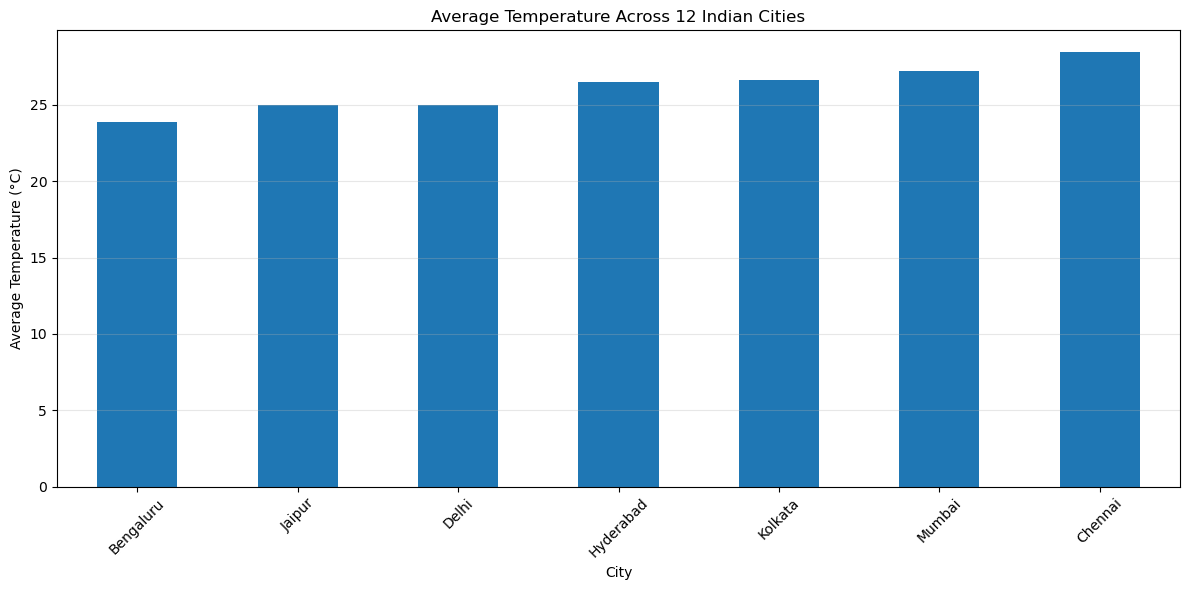

In [66]:

# STEP 13.3: Average temperature comparison

city_temperature = (
    weather_df.groupby("city")["temperature_2m"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(12, 6))

city_temperature.plot(kind="bar")

plt.title("Average Temperature Across 12 Indian Cities")
plt.xlabel("City")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [67]:

# STEP 13.4: Monthly temperature analysis

weather_df["month"] = weather_df["time"].dt.month

monthly_temperature = (
    weather_df.groupby(["city", "month"])["temperature_2m"]
    .mean()
    .unstack()
)

print("Monthly Average Temperature:")
print(monthly_temperature.round(2))


Monthly Average Temperature:
month         1      2      3      4      5      6      7      8      9   \
city                                                                       
Bengaluru  21.61  23.42  26.00  27.24  26.00  24.53  23.45  23.49  23.56   
Chennai    25.57  26.30  28.10  30.03  30.79  30.91  29.93  29.48  29.14   
Delhi      12.89  17.45  23.18  29.61  32.25  33.44  30.87  30.11  29.30   
Hyderabad  22.60  25.03  28.43  30.83  31.65  29.02  26.31  26.30  26.09   
Jaipur     13.72  18.67  24.18  30.26  32.91  32.85  29.74  28.26  27.97   
Kolkata    18.74  22.59  27.16  29.93  30.20  30.43  29.68  29.29  29.22   
Mumbai     24.01  25.36  27.39  29.18  29.91  28.72  27.32  27.04  27.18   

month         10     11     12  
city                            
Bengaluru  23.36  22.38  21.47  
Chennai    28.27  26.92  26.08  
Delhi      25.79  20.03  14.51  
Hyderabad  25.83  23.90  22.21  
Jaipur     25.61  20.15  15.11  
Kolkata    28.06  24.11  19.81  
Mumbai     28.20  27.0

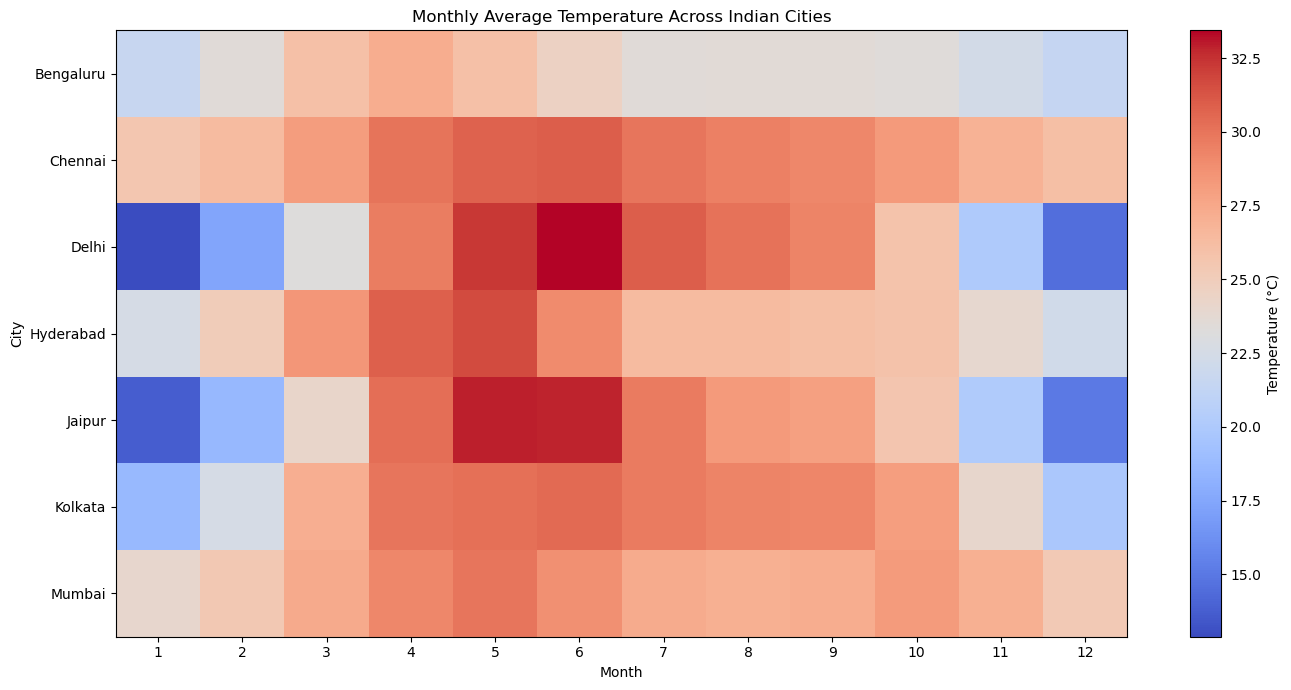

In [68]:

# STEP 13.5: Monthly temperature heatmap

plt.figure(figsize=(14, 7))

plt.imshow(
    monthly_temperature,
    aspect="auto",
    cmap="coolwarm",
    interpolation="nearest"
)

plt.colorbar(label="Temperature (°C)")

plt.xticks(
    range(len(monthly_temperature.columns)),
    monthly_temperature.columns
)

plt.yticks(
    range(len(monthly_temperature.index)),
    monthly_temperature.index
)

plt.xlabel("Month")
plt.ylabel("City")
plt.title("Monthly Average Temperature Across Indian Cities")

plt.tight_layout()
plt.show()


In [69]:

# STEP 13.6: City-wise rainfall statistics

rainfall_summary = (
    weather_df.groupby("city")["precipitation"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "max",
        "sum"
    ])
    .round(2)
)

print("City-wise Rainfall Statistics:")
print(rainfall_summary)


City-wise Rainfall Statistics:
           count  mean  median   std   max      sum
city                                               
Bengaluru  70128  0.12     0.0  0.48  11.9   8498.7
Chennai    70128  0.13     0.0  0.56  16.4   9209.3
Delhi      70128  0.09     0.0  0.48  16.5   6129.8
Hyderabad  70128  0.11     0.0  0.51  22.9   7947.9
Jaipur     70128  0.07     0.0  0.37  15.1   4966.8
Kolkata    70128  0.19     0.0  0.75  24.4  13360.3
Mumbai     70128  0.25     0.0  0.80  27.7  17468.1


In [70]:

# STEP 13.7: Monthly rainfall analysis

weather_df["month"] = weather_df["time"].dt.month

monthly_rainfall = (
    weather_df.groupby(["city", "month"])["precipitation"]
    .sum(min_count=1)
    .unstack()
)

print("Monthly Rainfall (mm):")
print(monthly_rainfall.round(2))


Monthly Rainfall (mm):
month         1      2      3      4       5       6       7       8       9   \
city                                                                            
Bengaluru   71.4   39.4   97.1  304.3  1162.4   991.9  1560.8  1169.0   793.1   
Chennai    268.1   48.3   58.1   61.0   390.4   480.9   881.3   789.4   794.6   
Delhi      278.1  181.6  240.9  103.9   301.6   475.2  1680.8  1233.5  1165.4   
Hyderabad   36.5   11.2   77.8   91.1   289.1   921.1  2240.5  1541.6  1849.6   
Jaipur     146.7   17.0   78.2   59.5   169.1   455.0  1483.7  1393.8   802.7   
Kolkata     84.0  189.9  252.2  588.1  1226.2  1842.2  2326.2  2791.2  2390.2   
Mumbai      17.6    0.4    7.9    3.8   373.0  2859.0  5904.3  4118.6  3305.4   

month          10      11      12  
city                               
Bengaluru  1284.9   734.9   289.5  
Chennai    1421.4  2754.9  1260.9  
Delhi       329.3    61.2    78.3  
Hyderabad   708.1   121.8    59.5  
Jaipur      205.1    92.3    63

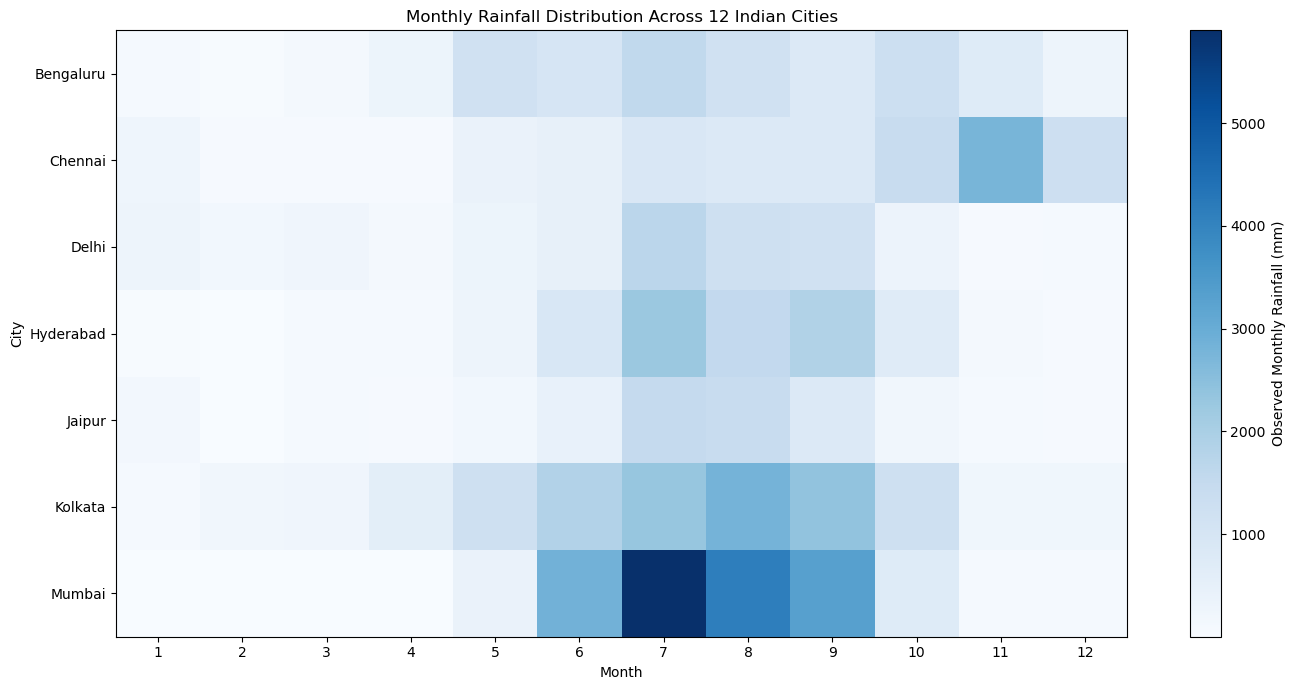

In [71]:

# STEP 13.8: Monthly rainfall heatmap

plt.figure(figsize=(14, 7))

plt.imshow(
    monthly_rainfall,
    aspect="auto",
    cmap="Blues",
    interpolation="nearest"
)

plt.colorbar(label="Observed Monthly Rainfall (mm)")

plt.xticks(
    range(len(monthly_rainfall.columns)),
    monthly_rainfall.columns
)

plt.yticks(
    range(len(monthly_rainfall.index)),
    monthly_rainfall.index
)

plt.xlabel("Month")
plt.ylabel("City")
plt.title("Monthly Rainfall Distribution Across 12 Indian Cities")

plt.tight_layout()
plt.show()


In [72]:

# STEP 13.9: Top 20 hourly rainfall observations

top_rainfall = (
    weather_df[
        weather_df["precipitation"].notna()
    ]
    .sort_values("precipitation", ascending=False)
    [[
        "city",
        "time",
        "precipitation",
        "temperature_2m",
        "relative_humidity_2m"
    ]]
    .head(20)
)

print("Top 20 Hourly Rainfall Observations:")
print(top_rainfall.to_string(index=False))


Top 20 Hourly Rainfall Observations:
     city                time  precipitation  temperature_2m  relative_humidity_2m
   Mumbai 2020-08-05 14:00:00           27.7            28.1                    92
   Mumbai 2020-08-05 15:00:00           27.2            26.6                    96
   Mumbai 2020-08-05 13:00:00           26.0            27.9                    94
   Mumbai 2020-08-05 16:00:00           25.6            26.7                    95
  Kolkata 2019-08-17 07:00:00           24.4            26.0                    95
  Kolkata 2019-08-17 08:00:00           24.0            25.6                    97
   Mumbai 2020-08-05 17:00:00           23.6            27.1                    93
   Mumbai 2020-08-05 12:00:00           23.2            28.2                    92
   Mumbai 2020-08-05 18:00:00           23.1            27.2                    92
Hyderabad 2023-09-04 08:00:00           22.9            23.5                    98
  Kolkata 2019-08-17 10:00:00           22.9      

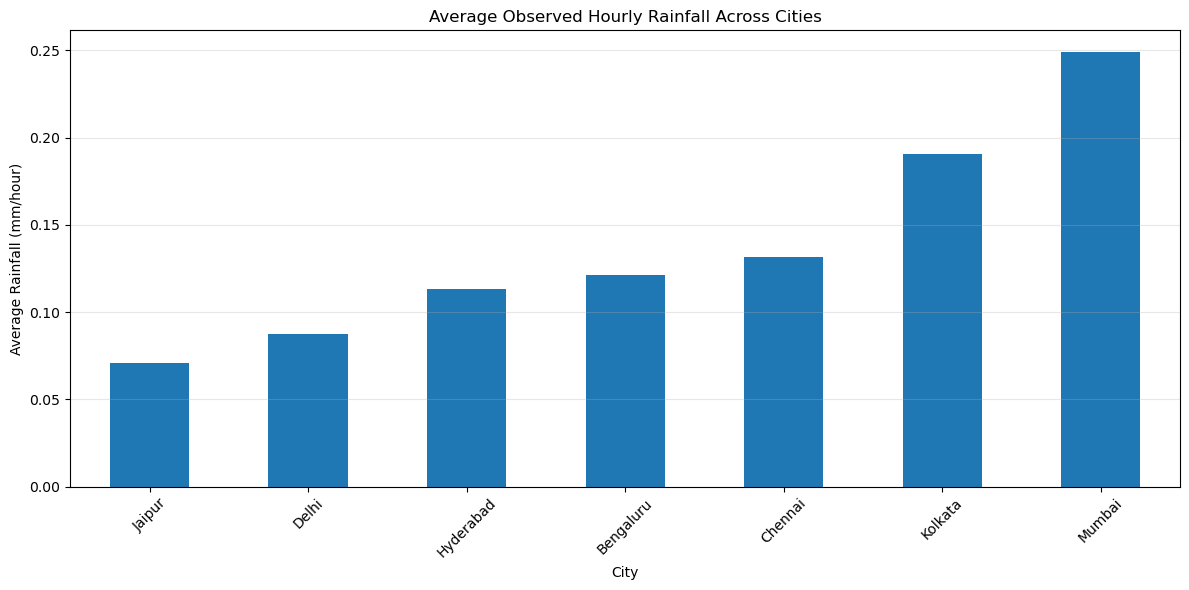

In [73]:

# STEP 13.10: Average hourly rainfall comparison

average_rainfall = (
    weather_df.groupby("city")["precipitation"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(12, 6))

average_rainfall.plot(kind="bar")

plt.title("Average Observed Hourly Rainfall Across Cities")
plt.xlabel("City")
plt.ylabel("Average Rainfall (mm/hour)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [74]:

# STEP 13.11: Rainfall data completeness by city

rainfall_completeness = (
    weather_df.groupby("city")["precipitation"]
    .agg(
        total_records="size",
        available_records="count"
    )
)

rainfall_completeness["missing_records"] = (
    rainfall_completeness["total_records"] -
    rainfall_completeness["available_records"]
)

rainfall_completeness["completeness_percentage"] = (
    rainfall_completeness["available_records"] /
    rainfall_completeness["total_records"] * 100
).round(2)

print("Rainfall Data Completeness:")
print(rainfall_completeness)


Rainfall Data Completeness:
           total_records  available_records  missing_records  \
city                                                           
Bengaluru          70128              70128                0   
Chennai            70128              70128                0   
Delhi              70128              70128                0   
Hyderabad          70128              70128                0   
Jaipur             70128              70128                0   
Kolkata            70128              70128                0   
Mumbai             70128              70128                0   

           completeness_percentage  
city                                
Bengaluru                    100.0  
Chennai                      100.0  
Delhi                        100.0  
Hyderabad                    100.0  
Jaipur                       100.0  
Kolkata                      100.0  
Mumbai                       100.0  


In [75]:

# STEP 13.12: City-wise wind statistics

wind_summary = (
    weather_df.groupby("city")
    .agg(
        average_wind_speed=("wind_speed_10m", "mean"),
        maximum_wind_speed=("wind_speed_10m", "max"),
        average_wind_gust=("wind_gusts_10m", "mean"),
        maximum_wind_gust=("wind_gusts_10m", "max"),
        average_wind_direction=("wind_direction_10m", "mean")
    )
    .round(2)
)

print("Wind Statistics Across 12 Cities:")
print(wind_summary)


Wind Statistics Across 12 Cities:
           average_wind_speed  maximum_wind_speed  average_wind_gust  \
city                                                                   
Bengaluru               10.88                36.9              23.25   
Chennai                 12.97                54.2              23.05   
Delhi                    8.82                32.3              17.60   
Hyderabad               10.93                36.7              22.33   
Jaipur                   9.07                36.7              18.39   
Kolkata                  8.95                49.6              18.59   
Mumbai                  11.18                53.9              20.99   

           maximum_wind_gust  average_wind_direction  
city                                                  
Bengaluru               82.8                  179.13  
Chennai                 87.1                  152.96  
Delhi                   75.2                  210.72  
Hyderabad               85.0              

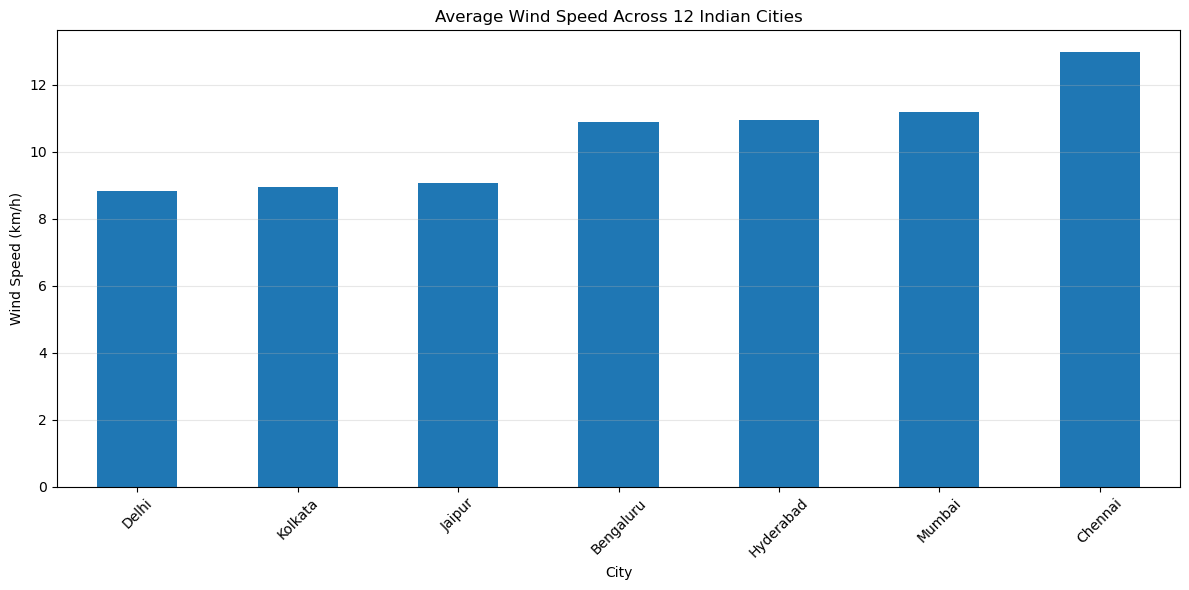

In [76]:

# STEP 13.13: Average wind speed comparison

average_wind = (
    weather_df.groupby("city")["wind_speed_10m"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(12, 6))

average_wind.plot(kind="bar")

plt.title("Average Wind Speed Across 12 Indian Cities")
plt.xlabel("City")
plt.ylabel("Wind Speed (km/h)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


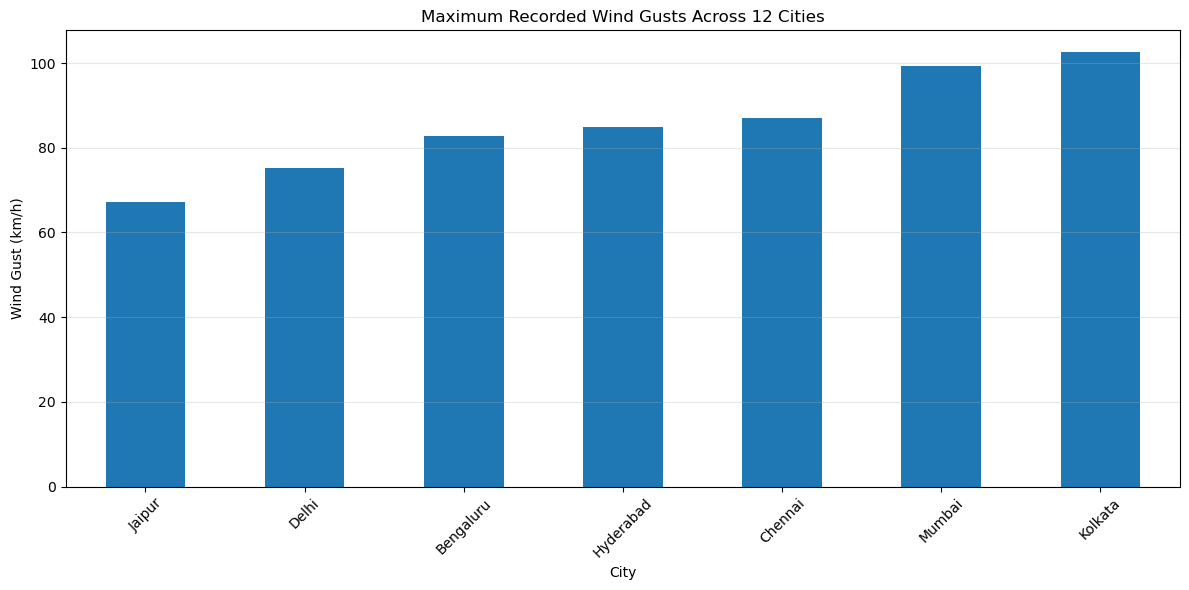

In [77]:

# STEP 13.14: Maximum wind gust comparison

maximum_gust = (
    weather_df.groupby("city")["wind_gusts_10m"]
    .max()
    .sort_values()
)

plt.figure(figsize=(12, 6))

maximum_gust.plot(kind="bar")

plt.title("Maximum Recorded Wind Gusts Across 12 Cities")
plt.xlabel("City")
plt.ylabel("Wind Gust (km/h)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


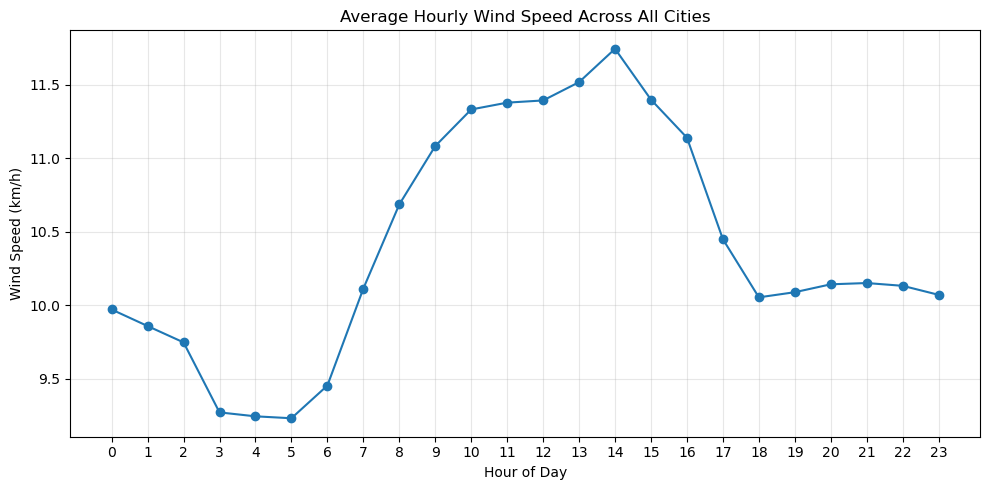

In [78]:

# STEP 13.15: Hourly average wind speed

weather_df["hour"] = weather_df["time"].dt.hour

hourly_wind = (
    weather_df.groupby("hour")["wind_speed_10m"]
    .mean()
)

plt.figure(figsize=(10, 5))

hourly_wind.plot(marker="o")

plt.title("Average Hourly Wind Speed Across All Cities")
plt.xlabel("Hour of Day")
plt.ylabel("Wind Speed (km/h)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [79]:

# STEP 13.16: Atmospheric pressure statistics

pressure_summary = (
    weather_df.groupby("city")["pressure_msl"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

print("Atmospheric Pressure Statistics:")
print(pressure_summary)


Atmospheric Pressure Statistics:
           count     mean   std     min     max
city                                           
Bengaluru  70128  1011.57  3.12  1000.8  1022.3
Chennai    70128  1008.95  3.96   995.4  1020.8
Delhi      70128  1008.48  7.26   988.8  1027.8
Hyderabad  70128  1009.88  4.50   995.8  1022.7
Jaipur     70128  1008.96  6.95   990.9  1027.2
Kolkata    70128  1008.15  6.19   975.2  1022.9
Mumbai     70128  1009.06  3.78   990.5  1020.2


<Figure size 1200x600 with 0 Axes>

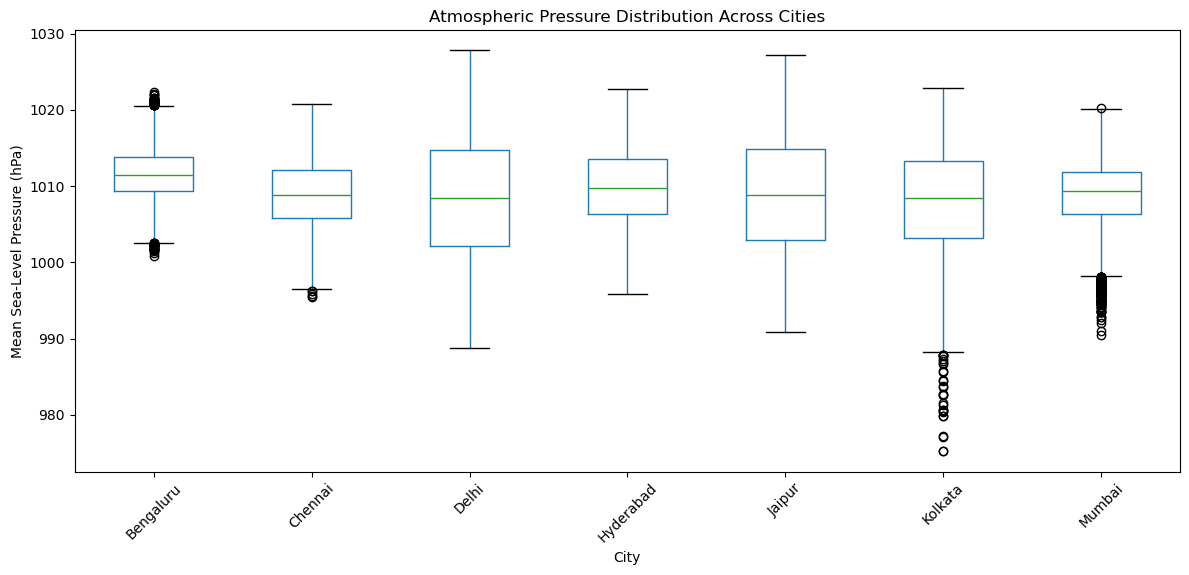

In [80]:

# STEP 13.17: Pressure distribution by city

plt.figure(figsize=(12, 6))

weather_df.boxplot(
    column="pressure_msl",
    by="city",
    figsize=(12, 6),
    grid=False
)

plt.title("Atmospheric Pressure Distribution Across Cities")
plt.suptitle("")
plt.xlabel("City")
plt.ylabel("Mean Sea-Level Pressure (hPa)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [81]:

# STEP 13.18: Prepare numerical weather variables

weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

# Convert selected columns to numeric
for col in weather_variables:
    weather_df[col] = pd.to_numeric(
        weather_df[col],
        errors="coerce"
    )

print("Weather variables prepared.")

print("\nMissing values:")
print(weather_df[weather_variables].isna().sum())

print("\nDescriptive statistics:")
print(weather_df[weather_variables].describe().round(2))


Weather variables prepared.

Missing values:
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
wind_gusts_10m          0
dtype: int64

Descriptive statistics:
       temperature_2m  relative_humidity_2m  precipitation  pressure_msl  \
count       490896.00             490896.00      490896.00     490896.00   
mean            26.09                 70.75           0.14       1009.29   
std              5.64                 19.11           0.59          5.44   
min              2.50                  5.00           0.00        975.20   
25%             23.10                 59.00           0.00       1005.50   
50%             26.90                 76.00           0.00       1009.70   
75%             29.60                 86.00           0.00       1013.30   
max             46.50                100.00          27.70       1027.80   

       wind_speed_10m  wind_gusts_10m  
count       490896.00       490896.0

In [82]:

# STEP 13.19: Overall correlation matrix

correlation_matrix = weather_df[
    weather_variables
].corr(method="pearson", min_periods=100)

print("Overall Weather Correlation Matrix:")
print(correlation_matrix.round(3))


Overall Weather Correlation Matrix:
                      temperature_2m  relative_humidity_2m  precipitation  \
temperature_2m                 1.000                -0.419          0.022   
relative_humidity_2m          -0.419                 1.000          0.195   
precipitation                  0.022                 0.195          1.000   
pressure_msl                  -0.655                -0.032         -0.185   
wind_speed_10m                 0.172                 0.032          0.153   
wind_gusts_10m                 0.294                -0.103          0.183   

                      pressure_msl  wind_speed_10m  wind_gusts_10m  
temperature_2m              -0.655           0.172           0.294  
relative_humidity_2m        -0.032           0.032          -0.103  
precipitation               -0.185           0.153           0.183  
pressure_msl                 1.000          -0.238          -0.267  
wind_speed_10m              -0.238           1.000           0.869  
wind_gusts

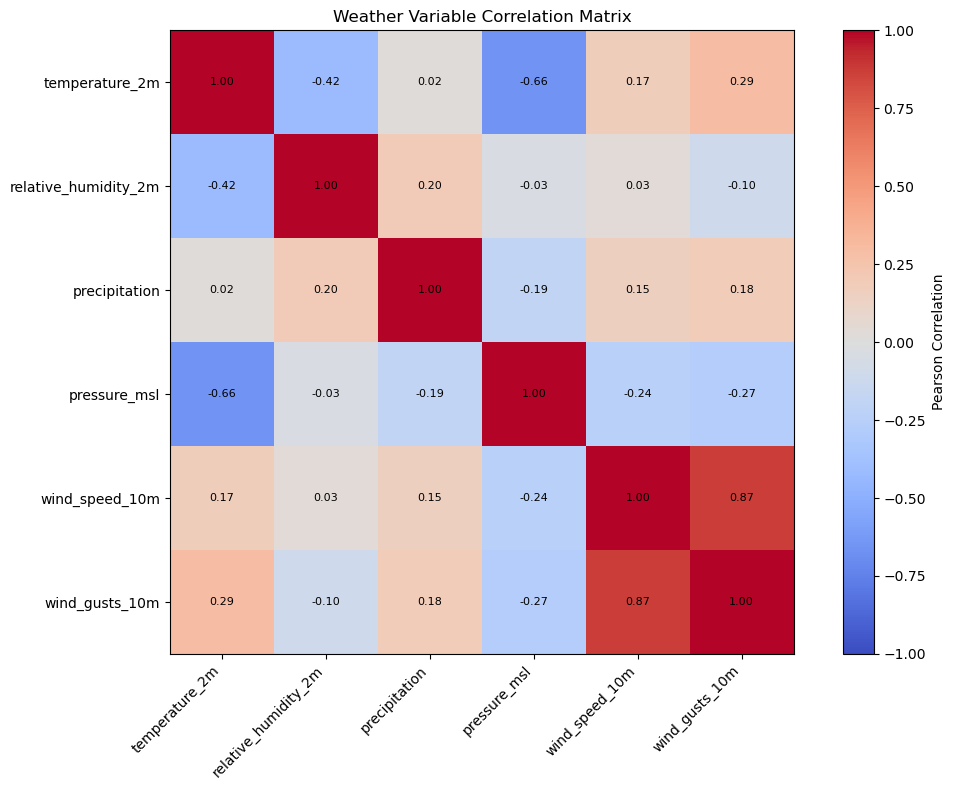

In [83]:

# STEP 13.20: Correlation heatmap

plt.figure(figsize=(11, 8))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(weather_variables)),
    weather_variables,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(weather_variables)),
    weather_variables
)

for i in range(len(weather_variables)):
    for j in range(len(weather_variables)):
        value = correlation_matrix.iloc[i, j]

        if pd.notna(value):
            plt.text(
                j, i, f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

plt.title("Weather Variable Correlation Matrix")
plt.tight_layout()
plt.show()


In [84]:

# STEP 13.21: City-wise temperature and humidity correlation

city_correlations = []

for city, group in weather_df.groupby("city"):

    valid_data = group[
        ["temperature_2m", "relative_humidity_2m"]
    ].dropna()

    correlation = valid_data[
        "temperature_2m"
    ].corr(valid_data["relative_humidity_2m"])

    city_correlations.append({
        "city": city,
        "valid_records": len(valid_data),
        "temperature_humidity_correlation": correlation
    })

city_correlation_df = pd.DataFrame(city_correlations)

print("City-wise Temperature-Humidity Correlation:")
print(city_correlation_df.round(3).to_string(index=False))


City-wise Temperature-Humidity Correlation:
     city  valid_records  temperature_humidity_correlation
Bengaluru          70128                            -0.745
  Chennai          70128                            -0.641
    Delhi          70128                            -0.569
Hyderabad          70128                            -0.643
   Jaipur          70128                            -0.485
  Kolkata          70128                            -0.322
   Mumbai          70128                            -0.385


In [85]:

# STEP 13.22: Create seasonal categories

weather_df["month"] = weather_df["time"].dt.month

def assign_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Pre-monsoon"

    elif month in [6, 7, 8, 9]:
        return "Monsoon"

    else:
        return "Post-monsoon"

weather_df["season"] = weather_df["month"].apply(assign_season)

print("Seasonal record counts:")
print(weather_df["season"].value_counts())


Seasonal record counts:
season
Monsoon         163968
Pre-monsoon     123648
Winter          121296
Post-monsoon     81984
Name: count, dtype: int64


In [86]:

# STEP 13.23: City-wise seasonal temperature analysis

seasonal_temperature = (
    weather_df.groupby(
        ["city", "season"]
    )["temperature_2m"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

print("Seasonal Temperature Statistics:")
print(seasonal_temperature)


Seasonal Temperature Statistics:
                        count   mean   std   min   max
city      season                                      
Bengaluru Monsoon       23424  23.76  2.44  17.9  32.3
          Post-monsoon  11712  22.88  2.75  13.8  30.9
          Pre-monsoon   17664  26.40  3.91  14.9  37.4
          Winter        17328  22.13  3.96  12.3  33.0
Chennai   Monsoon       23424  29.86  2.02  24.7  36.9
          Post-monsoon  11712  27.61  1.68  22.1  33.8
          Pre-monsoon   17664  29.63  2.18  21.9  37.7
          Winter        17328  25.97  1.72  19.7  31.1
Delhi     Monsoon       23424  30.92  3.60  21.8  45.7
          Post-monsoon  11712  22.96  5.52   8.9  37.0
          Pre-monsoon   17664  28.33  6.72   8.8  46.5
          Winter        17328  14.87  5.06   2.5  33.3
Hyderabad Monsoon       23424  26.92  2.90  21.5  41.1
          Post-monsoon  11712  24.88  3.42  13.8  33.5
          Pre-monsoon   17664  30.30  4.54  17.9  42.2
          Winter        17328  2

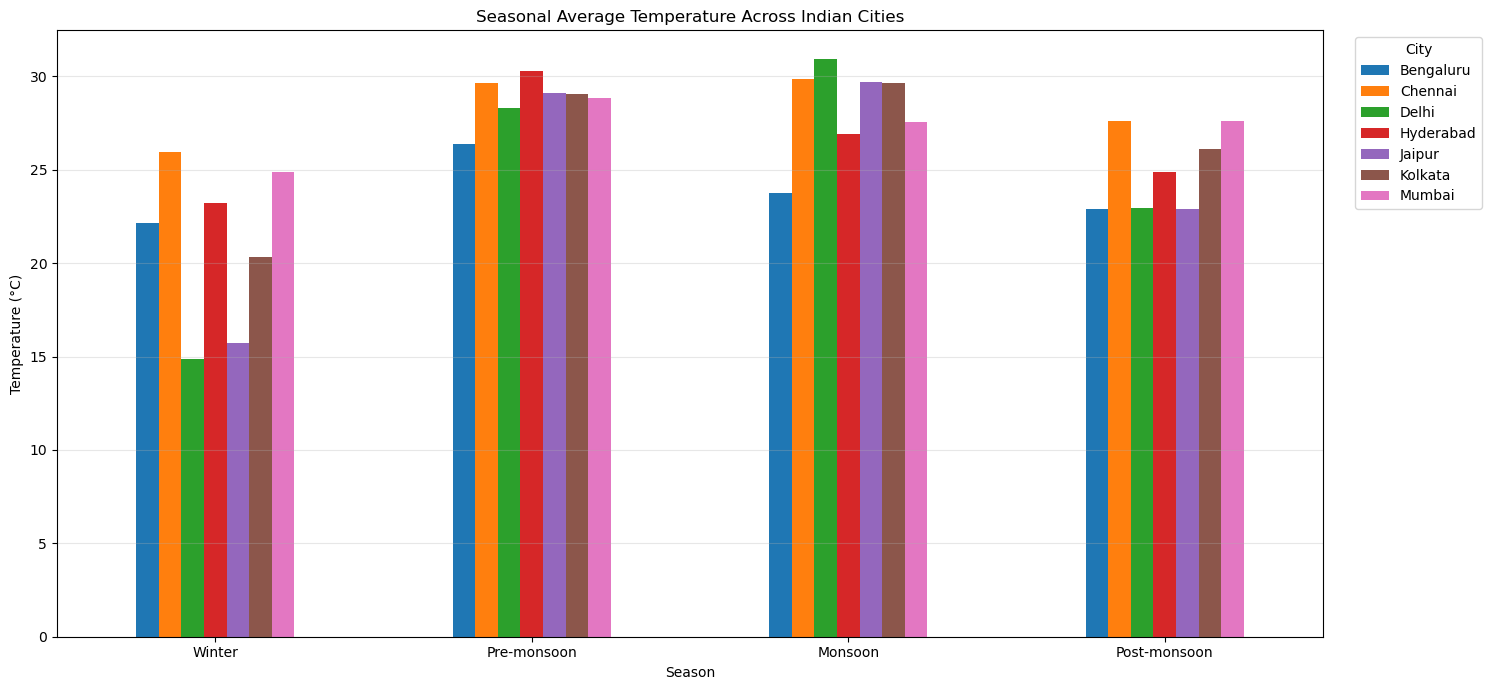

In [87]:

# STEP 13.24: Seasonal temperature comparison

season_order = [
    "Winter",
    "Pre-monsoon",
    "Monsoon",
    "Post-monsoon"
]

seasonal_plot_data = (
    weather_df.groupby(
        ["season", "city"]
    )["temperature_2m"]
    .mean()
    .unstack()
    .reindex(season_order)
)

seasonal_plot_data.plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Seasonal Average Temperature Across Indian Cities")
plt.xlabel("Season")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=0)
plt.legend(title="City", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [88]:

# STEP 13.25: Seasonal rainfall statistics

seasonal_rainfall = (
    weather_df.groupby(["city", "season"])["precipitation"]
    .agg(
        available_records="count",
        mean_hourly_rainfall="mean",
        maximum_hourly_rainfall="max",
        total_observed_rainfall=lambda x: x.sum(min_count=1)
    )
    .round(2)
)

print("Seasonal Rainfall Statistics:")
print(seasonal_rainfall)


Seasonal Rainfall Statistics:
                        available_records  mean_hourly_rainfall  \
city      season                                                  
Bengaluru Monsoon                   23424                  0.19   
          Post-monsoon              11712                  0.17   
          Pre-monsoon               17664                  0.09   
          Winter                    17328                  0.02   
Chennai   Monsoon                   23424                  0.13   
          Post-monsoon              11712                  0.36   
          Pre-monsoon               17664                  0.03   
          Winter                    17328                  0.09   
Delhi     Monsoon                   23424                  0.19   
          Post-monsoon              11712                  0.03   
          Pre-monsoon               17664                  0.04   
          Winter                    17328                  0.03   
Hyderabad Monsoon               

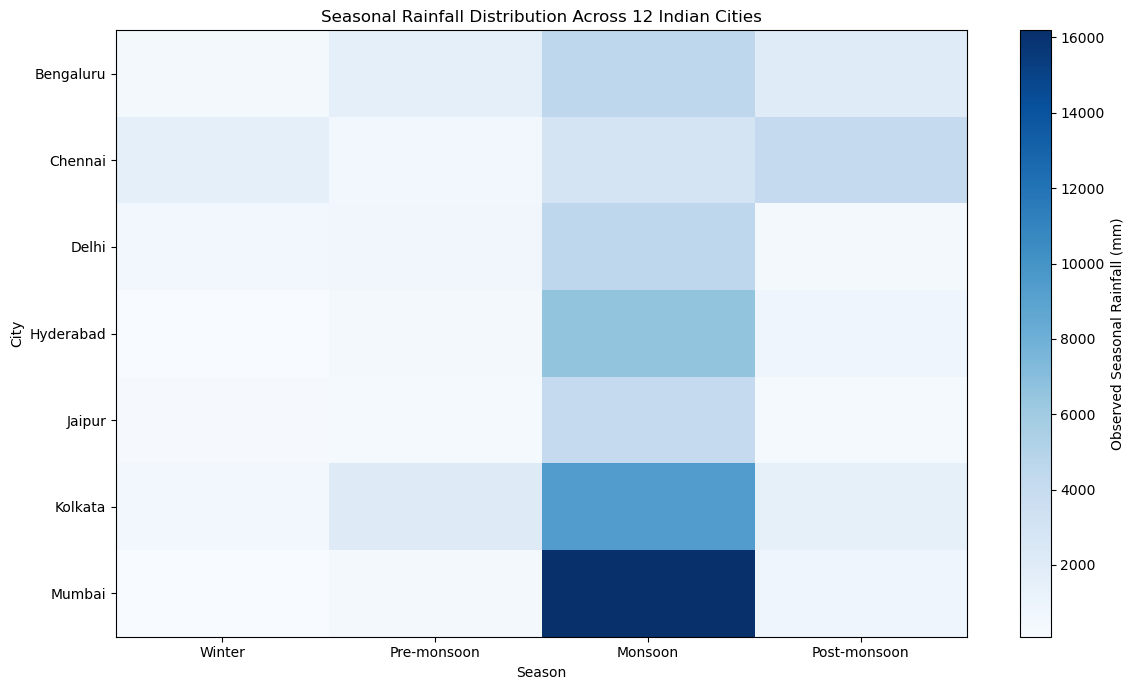

In [89]:

# STEP 13.26: Seasonal rainfall heatmap

seasonal_rainfall_total = (
    weather_df.groupby(["city", "season"])["precipitation"]
    .sum(min_count=1)
    .unstack()
    .reindex(columns=[
        "Winter",
        "Pre-monsoon",
        "Monsoon",
        "Post-monsoon"
    ])
)

plt.figure(figsize=(12, 7))

plt.imshow(
    seasonal_rainfall_total,
    aspect="auto",
    cmap="Blues",
    interpolation="nearest"
)

plt.colorbar(label="Observed Seasonal Rainfall (mm)")

plt.xticks(
    range(len(seasonal_rainfall_total.columns)),
    seasonal_rainfall_total.columns
)

plt.yticks(
    range(len(seasonal_rainfall_total.index)),
    seasonal_rainfall_total.index
)

plt.xlabel("Season")
plt.ylabel("City")
plt.title("Seasonal Rainfall Distribution Across 12 Indian Cities")

plt.tight_layout()
plt.show()


In [90]:

# STEP 13.27: Seasonal rainfall data completeness

seasonal_rainfall_completeness = (
    weather_df.groupby(["city", "season"])["precipitation"]
    .agg(
        total_records="size",
        available_records="count"
    )
)

seasonal_rainfall_completeness["missing_records"] = (
    seasonal_rainfall_completeness["total_records"]
    - seasonal_rainfall_completeness["available_records"]
)

seasonal_rainfall_completeness["completeness_percentage"] = (
    seasonal_rainfall_completeness["available_records"]
    / seasonal_rainfall_completeness["total_records"] * 100
).round(2)

print("Seasonal Rainfall Completeness:")
print(seasonal_rainfall_completeness.to_string())


Seasonal Rainfall Completeness:
                        total_records  available_records  missing_records  completeness_percentage
city      season                                                                                  
Bengaluru Monsoon               23424              23424                0                    100.0
          Post-monsoon          11712              11712                0                    100.0
          Pre-monsoon           17664              17664                0                    100.0
          Winter                17328              17328                0                    100.0
Chennai   Monsoon               23424              23424                0                    100.0
          Post-monsoon          11712              11712                0                    100.0
          Pre-monsoon           17664              17664                0                    100.0
          Winter                17328              17328                0    

In [91]:

# STEP 13.28: Seasonal wind speed analysis

seasonal_wind = (
    weather_df.groupby(["city", "season"])["wind_speed_10m"]
    .agg(["count", "mean", "max"])
    .round(2)
)

print("Seasonal Wind Speed Statistics:")
print(seasonal_wind)


Seasonal Wind Speed Statistics:
                        count   mean   max
city      season                          
Bengaluru Monsoon       23424  14.15  36.9
          Post-monsoon  11712   8.88  28.8
          Pre-monsoon   17664   8.70  31.0
          Winter        17328  10.01  25.4
Chennai   Monsoon       23424  13.47  30.5
          Post-monsoon  11712  12.04  52.6
          Pre-monsoon   17664  13.32  30.5
          Winter        17328  12.56  54.2
Delhi     Monsoon       23424   8.95  32.3
          Post-monsoon  11712   7.44  23.5
          Pre-monsoon   17664   9.77  32.1
          Winter        17328   8.63  28.6
Hyderabad Monsoon       23424  15.06  36.7
          Post-monsoon  11712   8.30  31.6
          Pre-monsoon   17664   9.26  28.2
          Winter        17328   8.83  24.5
Jaipur    Monsoon       23424  10.19  31.6
          Post-monsoon  11712   7.21  22.1
          Pre-monsoon   17664  10.04  36.7
          Winter        17328   7.82  29.3
Kolkata   Monsoon     

In [92]:

# STEP 13.29: Seasonal pressure analysis

seasonal_pressure = (
    weather_df.groupby(["city", "season"])["pressure_msl"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

print("Seasonal Atmospheric Pressure:")
print(seasonal_pressure)


Seasonal Atmospheric Pressure:
                        count     mean   std     min     max
city      season                                            
Bengaluru Monsoon       23424  1009.51  2.08  1001.7  1018.5
          Post-monsoon  11712  1012.70  2.48  1001.5  1019.8
          Pre-monsoon   17664  1010.72  2.78  1000.8  1021.0
          Winter        17328  1014.47  2.42  1004.8  1022.3
Chennai   Monsoon       23424  1005.53  2.20   997.2  1016.4
          Post-monsoon  11712  1010.15  2.78   996.6  1017.5
          Pre-monsoon   17664  1008.55  3.34   996.2  1019.3
          Winter        17328  1013.16  2.36   995.4  1020.8
Delhi     Monsoon       23424  1001.11  3.50   988.8  1014.6
          Post-monsoon  11712  1012.83  3.62  1001.1  1022.5
          Pre-monsoon   17664  1007.35  4.87   989.8  1022.0
          Winter        17328  1016.64  3.11  1004.3  1027.8
Hyderabad Monsoon       23424  1005.87  2.54   995.8  1017.8
          Post-monsoon  11712  1012.39  2.96   997.8  

In [93]:

# STEP 13.30: Save seasonal EDA reports

seasonal_temperature.to_csv(
    "seasonal_temperature_report.csv"
)

seasonal_rainfall.to_csv(
    "seasonal_rainfall_report.csv"
)

seasonal_rainfall_completeness.to_csv(
    "seasonal_rainfall_completeness.csv"
)

seasonal_wind.to_csv(
    "seasonal_wind_report.csv"
)

seasonal_pressure.to_csv(
    "seasonal_pressure_report.csv"
)

print("All seasonal EDA reports saved successfully.")


All seasonal EDA reports saved successfully.


In [94]:

# STEP 13.31: Overall data completeness by city

weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m",
    "pressure_msl"
]

completeness_report = (
    weather_df.groupby("city")[weather_variables]
    .agg(lambda x: x.notna().mean() * 100)
    .round(2)
)

print("Weather Data Completeness (%):")
print(completeness_report.to_string())


Weather Data Completeness (%):
           temperature_2m  relative_humidity_2m  precipitation  pressure_msl  wind_speed_10m  wind_direction_10m  wind_gusts_10m  pressure_msl
city                                                                                                                                          
Bengaluru           100.0                 100.0          100.0         100.0           100.0               100.0           100.0         100.0
Chennai             100.0                 100.0          100.0         100.0           100.0               100.0           100.0         100.0
Delhi               100.0                 100.0          100.0         100.0           100.0               100.0           100.0         100.0
Hyderabad           100.0                 100.0          100.0         100.0           100.0               100.0           100.0         100.0
Jaipur              100.0                 100.0          100.0         100.0           100.0               100.

In [95]:

# STEP 13.32: IQR-based outlier screening

iqr_results = []

for city, group in weather_df.groupby("city"):

    for column in [
        "temperature_2m",
        "precipitation",
        "wind_speed_10m",
        "wind_gusts_10m",
        "pressure_msl"
    ]:

        values = group[column].dropna()

        if len(values) < 10:
            continue

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)

        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        flagged = (
            (values < lower_limit) |
            (values > upper_limit)
        ).sum()

        iqr_results.append({
            "city": city,
            "variable": column,
            "observations": len(values),
            "lower_limit": round(lower_limit, 2),
            "upper_limit": round(upper_limit, 2),
            "flagged_values": int(flagged)
        })

iqr_report = pd.DataFrame(iqr_results)

print("IQR Outlier Screening Report:")
print(iqr_report.to_string(index=False))


IQR Outlier Screening Report:
     city       variable  observations  lower_limit  upper_limit  flagged_values
Bengaluru temperature_2m         70128        14.05        33.65             495
Bengaluru  precipitation         70128         0.00         0.00           13595
Bengaluru wind_speed_10m         70128        -2.30        23.30            1648
Bengaluru wind_gusts_10m         70128        -5.05        49.75            1369
Bengaluru   pressure_msl         70128      1002.55      1020.55              73
  Chennai temperature_2m         70128        21.60        35.20             265
  Chennai  precipitation         70128         0.00         0.00           13286
  Chennai wind_speed_10m         70128        -0.95        26.65             486
  Chennai wind_gusts_10m         70128         1.10        44.30             557
  Chennai   pressure_msl         70128       996.35      1021.55               5
    Delhi temperature_2m         70128         0.65        49.05               

In [96]:

# STEP 13.33: Inspect weather feature columns

print("Dataset Shape:", weather_df.shape)

print("\nAll Columns:")
print(weather_df.columns.tolist())

print("\nData Types:")
print(weather_df.dtypes)

print("\nDuplicate City-Time Records:")
print(
    weather_df.duplicated(
        subset=["city", "time"]
    ).sum()
)


Dataset Shape: (490896, 37)

All Columns:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'pressure_msl', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'city', 'state', 'latitude', 'longitude', 'temperature_2m_was_missing', 'relative_humidity_2m_was_missing', 'precipitation_was_missing', 'pressure_msl_was_missing', 'wind_speed_10m_was_missing', 'wind_direction_10m_was_missing', 'wind_gusts_10m_was_missing', 'year', 'month', 'day', 'hour', 'day_of_week', 'day_of_year', 'temperature_change_1h', 'temperature_change_3h', 'temperature_change_24h', 'temperature_rolling_mean_24h', 'temperature_rolling_std_24h', 'rainfall_3h', 'rainfall_24h', 'wind_speed_change_1h', 'wind_gust_difference', 'humidity_change_1h', 'pressure_change_1h', 'season']

Data Types:
time                                datetime64[ns]
temperature_2m                             float64
relative_humidity_2m                         int64
precipitation                              float64
pressu

In [97]:

# STEP 13.34: Save final EDA reports

completeness_report.to_csv(
    "final_weather_completeness_report.csv"
)

iqr_report.to_csv(
    "final_weather_iqr_screening_report.csv",
    index=False
)

print("Final EDA reports saved successfully.")


Final EDA reports saved successfully.


In [98]:
print("Total cities:", weather_df["city"].nunique())

print("\nCity names:")
print(sorted(weather_df["city"].unique()))

print("\nIQR Outlier Screening Report:")
display(iqr_report)

Total cities: 7

City names:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']

IQR Outlier Screening Report:


,city,variable,observations,lower_limit,upper_limit,flagged_values
0,Bengaluru,temperature_2m,70128,14.05,33.65,495
1,Bengaluru,precipitation,70128,0.00,0.00,13595
2,Bengaluru,wind_speed_10m,70128,-2.30,23.30,1648
3,Bengaluru,wind_gusts_10m,70128,-5.05,49.75,1369
4,Bengaluru,pressure_msl,70128,1002.55,1020.55,73
5,Chennai,temperature_2m,70128,21.60,35.20,265
6,Chennai,precipitation,70128,0.00,0.00,13286
7,Chennai,wind_speed_10m,70128,-0.95,26.65,486
8,Chennai,wind_gusts_10m,70128,1.10,44.30,557
9,Chennai,pressure_msl,70128,996.35,1021.55,5


In [99]:
import os
import pandas as pd

files_to_check = [
    "india_multi_city_weather.csv",
    "india_weather_hourly_reconstructed.csv",
    "india_weather_final_cleaned.csv"
]

for file in files_to_check:

    print("\n" + "=" * 50)
    print("FILE:", file)

    if os.path.exists(file):
        temp_df = pd.read_csv(file)

        print("Rows:", len(temp_df))

        if "city" in temp_df.columns:
            print("Number of cities:", temp_df["city"].nunique())
            print("City names:")
            print(sorted(temp_df["city"].dropna().unique()))
    else:
        print("File not found")


FILE: india_multi_city_weather.csv
Rows: 490896
Number of cities: 7
City names:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']

FILE: india_weather_hourly_reconstructed.csv
Rows: 490896
Number of cities: 7
City names:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']

FILE: india_weather_final_cleaned.csv
Rows: 490896
Number of cities: 7
City names:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']


In [100]:
import os
import pandas as pd

files = [
    "india_multi_city_weather.csv",
    "india_weather_hourly_reconstructed.csv",
    "india_weather_final_cleaned.csv"
]

for filename in files:
    print("\nFile:", filename)

    if os.path.exists(filename):
        df = pd.read_csv(filename)

        print("Rows:", len(df))
        print("Cities:", df["city"].nunique())
        print(sorted(df["city"].dropna().unique()))
    else:
        print("File not found")


File: india_multi_city_weather.csv
Rows: 490896
Cities: 7
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']

File: india_weather_hourly_reconstructed.csv
Rows: 490896
Cities: 7
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']

File: india_weather_final_cleaned.csv
Rows: 490896
Cities: 7
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai']


In [101]:
import requests
import pandas as pd
import time

# Missing five cities
missing_cities = {
    "Guwahati": {
        "latitude": 26.1445,
        "longitude": 91.7362
    },
    "Srinagar": {
        "latitude": 34.0837,
        "longitude": 74.7973
    },
    "Thiruvananthapuram": {
        "latitude": 8.5241,
        "longitude": 76.9366
    },
    "Bhopal": {
        "latitude": 23.2599,
        "longitude": 77.4126
    },
    "Leh": {
        "latitude": 34.1526,
        "longitude": 77.5771
    }
}

# Weather variables
hourly_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

all_missing_data = []

url = "https://archive-api.open-meteo.com/v1/archive"

for city, coordinates in missing_cities.items():

    print("Downloading:", city)

    params = {
        "latitude": coordinates["latitude"],
        "longitude": coordinates["longitude"],
        "start_date": "2018-01-01",
        "end_date": "2025-12-31",
        "hourly": ",".join(hourly_variables),
        "models": "era5",
        "timezone": "UTC"
    }

    response = requests.get(
        url,
        params=params,
        timeout=120
    )

    response.raise_for_status()

    data = response.json()

    city_df = pd.DataFrame(data["hourly"])

    city_df["city"] = city
    city_df["latitude"] = coordinates["latitude"]
    city_df["longitude"] = coordinates["longitude"]

    city_df["time"] = pd.to_datetime(city_df["time"])

    all_missing_data.append(city_df)

    print("Rows downloaded:", len(city_df))

    time.sleep(2)

# Combine five cities
missing_weather_df = pd.concat(
    all_missing_data,
    ignore_index=True
)

# Save downloaded data
missing_weather_df.to_csv(
    "india_missing_five_cities.csv",
    index=False
)

print("\nDownload completed!")
print("Dataset shape:", missing_weather_df.shape)
print(
    "Cities:",
    sorted(missing_weather_df["city"].unique())
)

Downloading: Guwahati
Rows downloaded: 70128
Downloading: Srinagar
Rows downloaded: 70128
Downloading: Thiruvananthapuram
Rows downloaded: 70128
Downloading: Bhopal
Rows downloaded: 70128
Downloading: Leh
Rows downloaded: 70128

Download completed!
Dataset shape: (350640, 11)
Cities: ['Bhopal', 'Guwahati', 'Leh', 'Srinagar', 'Thiruvananthapuram']


In [102]:
import pandas as pd

# Load original seven-city dataset
existing_weather_df = pd.read_csv(
    "india_multi_city_weather.csv"
)

# Load newly downloaded five-city dataset
missing_weather_df = pd.read_csv(
    "india_missing_five_cities.csv"
)

# Convert timestamps
existing_weather_df["time"] = pd.to_datetime(
    existing_weather_df["time"]
)

missing_weather_df["time"] = pd.to_datetime(
    missing_weather_df["time"]
)

print("Original dataset:", existing_weather_df.shape)
print("New dataset:", missing_weather_df.shape)

Original dataset: (490896, 12)
New dataset: (350640, 11)


In [103]:
india_weather_combined = pd.concat(
    [existing_weather_df, missing_weather_df],
    ignore_index=True
)

# Sort by city and timestamp
india_weather_combined = (
    india_weather_combined
    .sort_values(["city", "time"])
    .reset_index(drop=True)
)

print("Combined dataset shape:",
      india_weather_combined.shape)

print("\nTotal cities:",
      india_weather_combined["city"].nunique())

print("\nCity names:")
print(sorted(india_weather_combined["city"].unique()))

Combined dataset shape: (841536, 12)

Total cities: 12

City names:
['Bengaluru', 'Bhopal', 'Chennai', 'Delhi', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Leh', 'Mumbai', 'Srinagar', 'Thiruvananthapuram']


In [104]:
duplicate_count = india_weather_combined.duplicated(
    subset=["city", "time"]
).sum()

print("Duplicate city-time records:", duplicate_count)

print("\nRecords per city:")
print(
    india_weather_combined.groupby("city").size()
)

Duplicate city-time records: 0

Records per city:
city
Bengaluru             70128
Bhopal                70128
Chennai               70128
Delhi                 70128
Guwahati              70128
Hyderabad             70128
Jaipur                70128
Kolkata               70128
Leh                   70128
Mumbai                70128
Srinagar              70128
Thiruvananthapuram    70128
dtype: int64


In [105]:
import pandas as pd

# Load original seven-city dataset
existing_weather_df = pd.read_csv(
    "india_multi_city_weather.csv"
)

# Load newly downloaded five-city dataset
missing_weather_df = pd.read_csv(
    "india_missing_five_cities.csv"
)

# Convert timestamps
existing_weather_df["time"] = pd.to_datetime(
    existing_weather_df["time"]
)

missing_weather_df["time"] = pd.to_datetime(
    missing_weather_df["time"]
)

print("Original dataset:", existing_weather_df.shape)
print("New dataset:", missing_weather_df.shape)

print("\nBoth datasets loaded successfully!")

Original dataset: (490896, 12)
New dataset: (350640, 11)

Both datasets loaded successfully!


In [106]:
india_weather_combined = pd.concat(
    [existing_weather_df, missing_weather_df],
    ignore_index=True
)

# Sort by city and timestamp
india_weather_combined = (
    india_weather_combined
    .sort_values(["city", "time"])
    .reset_index(drop=True)
)

print("Combined dataset shape:",
      india_weather_combined.shape)

print("\nTotal cities:",
      india_weather_combined["city"].nunique())

print("\nCity names:")
print(sorted(india_weather_combined["city"].unique()))

Combined dataset shape: (841536, 12)

Total cities: 12

City names:
['Bengaluru', 'Bhopal', 'Chennai', 'Delhi', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Leh', 'Mumbai', 'Srinagar', 'Thiruvananthapuram']


In [107]:
duplicate_count = india_weather_combined.duplicated(
    subset=["city", "time"]
).sum()

print("Duplicate city-time records:", duplicate_count)

print("\nRecords per city:")
print(
    india_weather_combined.groupby("city").size()
)

Duplicate city-time records: 0

Records per city:
city
Bengaluru             70128
Bhopal                70128
Chennai               70128
Delhi                 70128
Guwahati              70128
Hyderabad             70128
Jaipur                70128
Kolkata               70128
Leh                   70128
Mumbai                70128
Srinagar              70128
Thiruvananthapuram    70128
dtype: int64


In [108]:
city_date_report = (
    india_weather_combined
    .groupby("city")
    .agg(
        start_date=("time", "min"),
        end_date=("time", "max"),
        total_records=("time", "count"),
        unique_timestamps=("time", "nunique")
    )
)

display(city_date_report)

,start_date,end_date,total_records,unique_timestamps
city,,,,
Bengaluru,2018-01-01,2025-12-31 23:00:00,70128,70128
Bhopal,2018-01-01,2025-12-31 23:00:00,70128,70128
Chennai,2018-01-01,2025-12-31 23:00:00,70128,70128
Delhi,2018-01-01,2025-12-31 23:00:00,70128,70128
Guwahati,2018-01-01,2025-12-31 23:00:00,70128,70128
Hyderabad,2018-01-01,2025-12-31 23:00:00,70128,70128
Jaipur,2018-01-01,2025-12-31 23:00:00,70128,70128
Kolkata,2018-01-01,2025-12-31 23:00:00,70128,70128
Leh,2018-01-01,2025-12-31 23:00:00,70128,70128


In [109]:
weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

missing_value_report = (
    india_weather_combined
    .groupby("city")[weather_variables]
    .apply(lambda group: group.isnull().sum())
)

print("Missing Weather Values by City:")
display(missing_value_report)

print("\nTotal missing values:")
print(
    india_weather_combined[weather_variables]
    .isnull()
    .sum()
)

Missing Weather Values by City:


,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m
city,,,,,,,
Bengaluru,0,0,0,0,0,0,0
Bhopal,0,0,0,0,0,0,0
Chennai,0,0,0,0,0,0,0
Delhi,0,0,0,0,0,0,0
Guwahati,0,0,0,0,0,0,0
Hyderabad,0,0,0,0,0,0,0
Jaipur,0,0,0,0,0,0,0
Kolkata,0,0,0,0,0,0,0
Leh,0,0,0,0,0,0,0



Total missing values:
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
wind_direction_10m      0
wind_gusts_10m          0
dtype: int64


In [110]:
# Check duplicate city-timestamp records

duplicate_count = india_weather_combined.duplicated(
    subset=["city", "time"]
).sum()

print("Duplicate records:", duplicate_count)

if duplicate_count == 0:
    print("SUCCESS: No duplicate city-timestamp records found.")
else:
    print("WARNING: Duplicate records need investigation.")

Duplicate records: 0
SUCCESS: No duplicate city-timestamp records found.


In [111]:
# Check duplicate city-timestamp records

duplicate_count = india_weather_combined.duplicated(
    subset=["city", "time"]
).sum()

print("Duplicate records:", duplicate_count)

if duplicate_count == 0:
    print("SUCCESS: No duplicate city-timestamp records found.")
else:
    print("WARNING: Duplicate records need investigation.")

Duplicate records: 0
SUCCESS: No duplicate city-timestamp records found.


In [112]:
import pandas as pd
import os

# ==========================================
# 1. LOAD BOTH DATASETS
# ==========================================

existing_weather_df = pd.read_csv(
    "india_multi_city_weather.csv"
)

missing_weather_df = pd.read_csv(
    "india_missing_five_cities.csv"
)

existing_weather_df["time"] = pd.to_datetime(
    existing_weather_df["time"]
)

missing_weather_df["time"] = pd.to_datetime(
    missing_weather_df["time"]
)

# ==========================================
# 2. COMBINE ALL 12 CITIES
# ==========================================

india_weather_combined = pd.concat(
    [existing_weather_df, missing_weather_df],
    ignore_index=True
)

india_weather_combined = (
    india_weather_combined
    .sort_values(["city", "time"])
    .reset_index(drop=True)
)

# ==========================================
# 3. VERIFY CITY COVERAGE
# ==========================================

expected_cities = [
    "Chennai",
    "Bengaluru",
    "Mumbai",
    "Delhi",
    "Kolkata",
    "Hyderabad",
    "Jaipur",
    "Guwahati",
    "Srinagar",
    "Thiruvananthapuram",
    "Bhopal",
    "Leh"
]

actual_cities = sorted(
    india_weather_combined["city"].dropna().unique()
)

print("TOTAL CITIES:", len(actual_cities))
print("CITY NAMES:", actual_cities)

missing_cities = sorted(
    set(expected_cities) - set(actual_cities)
)

print("Missing cities:", missing_cities)

# ==========================================
# 4. CHECK RECORD COUNTS
# ==========================================

print("\nRECORDS PER CITY:")

print(
    india_weather_combined.groupby("city").size()
)

print("\nTOTAL DATASET SHAPE:")
print(india_weather_combined.shape)

# ==========================================
# 5. CHECK DUPLICATE TIMESTAMPS
# ==========================================

duplicate_count = india_weather_combined.duplicated(
    subset=["city", "time"]
).sum()

print("\nDUPLICATE CITY-TIME RECORDS:")
print(duplicate_count)

# ==========================================
# 6. CHECK DATE COVERAGE
# ==========================================

date_report = (
    india_weather_combined
    .groupby("city")
    .agg(
        start_date=("time", "min"),
        end_date=("time", "max"),
        total_records=("time", "count"),
        unique_timestamps=("time", "nunique")
    )
)

print("\nDATE COVERAGE REPORT:")
display(date_report)

# ==========================================
# 7. CHECK MISSING WEATHER VALUES
# ==========================================

weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m"
]

missing_report = (
    india_weather_combined
    .groupby("city")[weather_variables]
    .apply(lambda group: group.isnull().sum())
)

print("\nMISSING VALUES BY CITY:")
display(missing_report)

# ==========================================
# 8. FINAL VALIDATION
# ==========================================

if (
    len(actual_cities) == 12
    and len(missing_cities) == 0
    and duplicate_count == 0
    and india_weather_combined[weather_variables].notna().all().all()
):

    india_weather_combined.to_csv(
        "india_weather_12_cities_combined.csv",
        index=False
    )

    print("\nSUCCESS: All 12 cities verified.")
    print("Combined dataset saved successfully.")

else:
    print("\nWARNING: Validation is incomplete.")
    print("Investigate the reports before proceeding.")

TOTAL CITIES: 12
CITY NAMES: ['Bengaluru', 'Bhopal', 'Chennai', 'Delhi', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Leh', 'Mumbai', 'Srinagar', 'Thiruvananthapuram']
Missing cities: []

RECORDS PER CITY:
city
Bengaluru             70128
Bhopal                70128
Chennai               70128
Delhi                 70128
Guwahati              70128
Hyderabad             70128
Jaipur                70128
Kolkata               70128
Leh                   70128
Mumbai                70128
Srinagar              70128
Thiruvananthapuram    70128
dtype: int64

TOTAL DATASET SHAPE:
(841536, 12)

DUPLICATE CITY-TIME RECORDS:
0

DATE COVERAGE REPORT:


,start_date,end_date,total_records,unique_timestamps
city,,,,
Bengaluru,2018-01-01,2025-12-31 23:00:00,70128,70128
Bhopal,2018-01-01,2025-12-31 23:00:00,70128,70128
Chennai,2018-01-01,2025-12-31 23:00:00,70128,70128
Delhi,2018-01-01,2025-12-31 23:00:00,70128,70128
Guwahati,2018-01-01,2025-12-31 23:00:00,70128,70128
Hyderabad,2018-01-01,2025-12-31 23:00:00,70128,70128
Jaipur,2018-01-01,2025-12-31 23:00:00,70128,70128
Kolkata,2018-01-01,2025-12-31 23:00:00,70128,70128
Leh,2018-01-01,2025-12-31 23:00:00,70128,70128



MISSING VALUES BY CITY:


,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m
city,,,,,,,
Bengaluru,0,0,0,0,0,0,0
Bhopal,0,0,0,0,0,0,0
Chennai,0,0,0,0,0,0,0
Delhi,0,0,0,0,0,0,0
Guwahati,0,0,0,0,0,0,0
Hyderabad,0,0,0,0,0,0,0
Jaipur,0,0,0,0,0,0,0
Kolkata,0,0,0,0,0,0,0
Leh,0,0,0,0,0,0,0



SUCCESS: All 12 cities verified.
Combined dataset saved successfully.


In [113]:
import pandas as pd

# Sort the combined dataset
india_weather_combined = (
    india_weather_combined
    .sort_values(["city", "time"])
    .reset_index(drop=True)
)

# Expected hourly records
expected_hours = pd.date_range(
    start="2018-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

continuity_results = []

for city, group in india_weather_combined.groupby("city"):

    actual_times = pd.DatetimeIndex(
        group["time"].drop_duplicates().sort_values()
    )

    missing_timestamps = expected_hours.difference(
        actual_times
    )

    unexpected_timestamps = actual_times.difference(
        expected_hours
    )

    continuity_results.append({
        "city": city,
        "total_records": len(group),
        "unique_timestamps": len(actual_times),
        "missing_hours": len(missing_timestamps),
        "unexpected_hours": len(unexpected_timestamps),
        "continuous": (
            len(missing_timestamps) == 0
            and len(unexpected_timestamps) == 0
            and len(group) == len(actual_times)
        )
    })

continuity_report = pd.DataFrame(continuity_results)

print("HOURLY TIMESTAMP CONTINUITY REPORT:")
display(continuity_report)

print("\nAll 12 cities continuous:",
      continuity_report["continuous"].all())

print("Total missing timestamps:",
      continuity_report["missing_hours"].sum())

HOURLY TIMESTAMP CONTINUITY REPORT:


,city,total_records,unique_timestamps,missing_hours,unexpected_hours,continuous
0,Bengaluru,70128,70128,0,0,True
1,Bhopal,70128,70128,0,0,True
2,Chennai,70128,70128,0,0,True
3,Delhi,70128,70128,0,0,True
4,Guwahati,70128,70128,0,0,True
5,Hyderabad,70128,70128,0,0,True
6,Jaipur,70128,70128,0,0,True
7,Kolkata,70128,70128,0,0,True
8,Leh,70128,70128,0,0,True
9,Mumbai,70128,70128,0,0,True



All 12 cities continuous: True
Total missing timestamps: 0


In [114]:
import pandas as pd

# Sort dataset
india_weather_combined = india_weather_combined.sort_values(
    ["city", "time"]
).reset_index(drop=True)

# Expected hourly timestamps (2018–2025)
expected_hours = pd.date_range(
    start="2018-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

continuity_results = []

for city, group in india_weather_combined.groupby("city"):

    actual_times = pd.DatetimeIndex(
        group["time"].drop_duplicates().sort_values()
    )

    missing_hours = expected_hours.difference(actual_times)
    unexpected_hours = actual_times.difference(expected_hours)

    continuity_results.append({
        "city": city,
        "total_records": len(group),
        "unique_timestamps": len(actual_times),
        "missing_hours": len(missing_hours),
        "unexpected_hours": len(unexpected_hours),
        "continuous": (
            len(group) == len(actual_times)
            and len(missing_hours) == 0
            and len(unexpected_hours) == 0
        )
    })

continuity_report = pd.DataFrame(continuity_results)

print("HOURLY TIMESTAMP CONTINUITY REPORT")
display(continuity_report)

print("\nTotal cities:", len(continuity_report))
print("Total missing hours:", continuity_report["missing_hours"].sum())
print("All cities continuous:", continuity_report["continuous"].all())


HOURLY TIMESTAMP CONTINUITY REPORT


,city,total_records,unique_timestamps,missing_hours,unexpected_hours,continuous
0,Bengaluru,70128,70128,0,0,True
1,Bhopal,70128,70128,0,0,True
2,Chennai,70128,70128,0,0,True
3,Delhi,70128,70128,0,0,True
4,Guwahati,70128,70128,0,0,True
5,Hyderabad,70128,70128,0,0,True
6,Jaipur,70128,70128,0,0,True
7,Kolkata,70128,70128,0,0,True
8,Leh,70128,70128,0,0,True
9,Mumbai,70128,70128,0,0,True



Total cities: 12
Total missing hours: 0
All cities continuous: True


In [115]:
# ============================================================
# STEP 15: Z-SCORE BASELINE ANOMALY DETECTION
# Extreme Weather & Micro-Climate Anomaly Early Warning System
# ============================================================

import pandas as pd
import numpy as np
import os

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

file_path = "india_weather_12_cities_combined.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Combined dataset not found. Complete Step 14 validation first."
    )

weather_df = pd.read_csv(file_path)

weather_df["time"] = pd.to_datetime(weather_df["time"])

weather_df = weather_df.sort_values(
    ["city", "time"]
).reset_index(drop=True)

print("Dataset loaded successfully")
print("Dataset shape:", weather_df.shape)
print("Number of cities:", weather_df["city"].nunique())

# ------------------------------------------------------------
# 2. SELECT WEATHER VARIABLES
# ------------------------------------------------------------

weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

# Verify required columns
missing_columns = [
    col for col in weather_variables
    if col not in weather_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 3. CALCULATE CITY-SPECIFIC Z-SCORES
# ------------------------------------------------------------

for variable in weather_variables:

    city_mean = weather_df.groupby("city")[variable].transform("mean")

    city_std = weather_df.groupby("city")[variable].transform("std")

    weather_df[f"{variable}_zscore"] = (
        (weather_df[variable] - city_mean) /
        city_std.replace(0, np.nan)
    )

# ------------------------------------------------------------
# 4. IDENTIFY ANOMALIES
# ------------------------------------------------------------

threshold = 3

for variable in weather_variables:

    weather_df[f"{variable}_anomaly"] = (
        weather_df[f"{variable}_zscore"].abs() > threshold
    )

# ------------------------------------------------------------
# 5. COUNT ANOMALIES BY WEATHER VARIABLE
# ------------------------------------------------------------

anomaly_summary = []

for variable in weather_variables:

    count = weather_df[
        f"{variable}_anomaly"
    ].sum()

    percentage = (
        count / weather_df[variable].notna().sum()
    ) * 100

    anomaly_summary.append({
        "weather_variable": variable,
        "anomaly_count": int(count),
        "anomaly_percentage": round(percentage, 3)
    })

anomaly_summary_df = pd.DataFrame(anomaly_summary)

print("\nANOMALY SUMMARY")
display(anomaly_summary_df)

# ------------------------------------------------------------
# 6. CREATE OVERALL ANOMALY FLAG
# ------------------------------------------------------------

anomaly_columns = [
    f"{variable}_anomaly"
    for variable in weather_variables
]

weather_df["overall_anomaly"] = (
    weather_df[anomaly_columns].any(axis=1)
)

print("\nTotal anomaly records:",
      weather_df["overall_anomaly"].sum())

print("Total normal records:",
      (~weather_df["overall_anomaly"]).sum())

# ------------------------------------------------------------
# 7. CITY-WISE ANOMALY SUMMARY
# ------------------------------------------------------------

city_anomaly_summary = (
    weather_df.groupby("city")
    .agg(
        total_records=("overall_anomaly", "size"),
        anomaly_records=("overall_anomaly", "sum")
    )
)

city_anomaly_summary["anomaly_percentage"] = (
    city_anomaly_summary["anomaly_records"] /
    city_anomaly_summary["total_records"]
) * 100

print("\nCITY-WISE ANOMALY SUMMARY")
display(city_anomaly_summary.round(3))

# ------------------------------------------------------------
# 8. EXTRACT ANOMALY RECORDS
# ------------------------------------------------------------

anomaly_records = weather_df[
    weather_df["overall_anomaly"]
].copy()

print("\nSample anomaly records:")
display(anomaly_records.head(10))

# ------------------------------------------------------------
# 9. SAVE RESULTS
# ------------------------------------------------------------

weather_df.to_csv(
    "india_weather_zscore_results.csv",
    index=False
)

anomaly_records.to_csv(
    "india_weather_zscore_anomalies.csv",
    index=False
)

anomaly_summary_df.to_csv(
    "zscore_anomaly_summary.csv",
    index=False
)

city_anomaly_summary.to_csv(
    "zscore_city_anomaly_summary.csv"
)

print("\nSTEP 15.1 COMPLETED")
print("All Z-score results saved successfully.")

C:\Users\admin\AppData\Local\Temp\ipykernel_16084\2669615770.py:21: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  weather_df = pd.read_csv(file_path)


Dataset loaded successfully
Dataset shape: (841536, 12)
Number of cities: 12

ANOMALY SUMMARY


,weather_variable,anomaly_count,anomaly_percentage
0,temperature_2m,697,0.083
1,relative_humidity_2m,2905,0.345
2,precipitation,15664,1.861
3,pressure_msl,640,0.076
4,wind_speed_10m,6630,0.788
5,wind_gusts_10m,6597,0.784



Total anomaly records: 27960
Total normal records: 813576

CITY-WISE ANOMALY SUMMARY


,total_records,anomaly_records,anomaly_percentage
city,,,
Bengaluru,70128,2465,3.515
Bhopal,70128,1939,2.765
Chennai,70128,1621,2.311
Delhi,70128,2093,2.985
Guwahati,70128,3184,4.540
Hyderabad,70128,1998,2.849
Jaipur,70128,2074,2.957
Kolkata,70128,2710,3.864
Leh,70128,2824,4.027



Sample anomaly records:


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m,city,state,...,pressure_msl_zscore,wind_speed_10m_zscore,wind_gusts_10m_zscore,temperature_2m_anomaly,relative_humidity_2m_anomaly,precipitation_anomaly,pressure_msl_anomaly,wind_speed_10m_anomaly,wind_gusts_10m_anomaly,overall_anomaly
905,2018-02-07 17:00:00,25.0,75,4.4,1013.1,7.0,339,20.5,Bengaluru,Karnataka,...,0.489196,-0.759152,-0.263621,False,False,True,False,False,False,True
906,2018-02-07 18:00:00,24.1,79,5.5,1014.5,9.5,349,22.3,Bengaluru,Karnataka,...,0.937395,-0.269396,-0.091241,False,False,True,False,False,False,True
907,2018-02-07 19:00:00,22.9,83,3.9,1015.2,8.4,20,20.9,Bengaluru,Karnataka,...,1.161495,-0.484888,-0.225315,False,False,True,False,False,False,True
908,2018-02-07 20:00:00,21.0,89,4.2,1016.4,8.2,41,15.8,Bengaluru,Karnataka,...,1.545666,-0.524069,-0.713725,False,False,True,False,False,False,True
909,2018-02-07 21:00:00,21.1,87,2.9,1016.7,8.7,48,14.4,Bengaluru,Karnataka,...,1.641709,-0.426118,-0.847799,False,False,True,False,False,False,True
955,2018-02-09 19:00:00,23.8,77,1.8,1012.5,4.7,99,16.2,Bengaluru,Karnataka,...,0.297110,-1.209728,-0.675418,False,False,True,False,False,False,True
956,2018-02-09 20:00:00,22.3,82,1.7,1014.0,6.3,149,14.4,Bengaluru,Karnataka,...,0.777324,-0.896284,-0.847799,False,False,True,False,False,False,True
1792,2018-03-16 16:00:00,28.9,58,1.9,1006.8,1.6,153,18.0,Bengaluru,Karnataka,...,-1.527702,-1.817027,-0.503038,False,False,True,False,False,False,True
1793,2018-03-16 17:00:00,27.2,72,3.3,1008.8,1.0,45,18.4,Bengaluru,Karnataka,...,-0.887417,-1.934568,-0.464732,False,False,True,False,False,False,True
1794,2018-03-16 18:00:00,25.0,81,9.2,1010.2,2.5,270,17.6,Bengaluru,Karnataka,...,-0.439218,-1.640714,-0.541345,False,False,True,False,False,False,True



STEP 15.1 COMPLETED
All Z-score results saved successfully.


Z-SCORE ANOMALY SUMMARY


,weather_variable,anomaly_count,anomaly_percentage
0,temperature_2m,697,0.083
1,relative_humidity_2m,2905,0.345
2,precipitation,15664,1.861
3,pressure_msl,640,0.076
4,wind_speed_10m,6630,0.788
5,wind_gusts_10m,6597,0.784


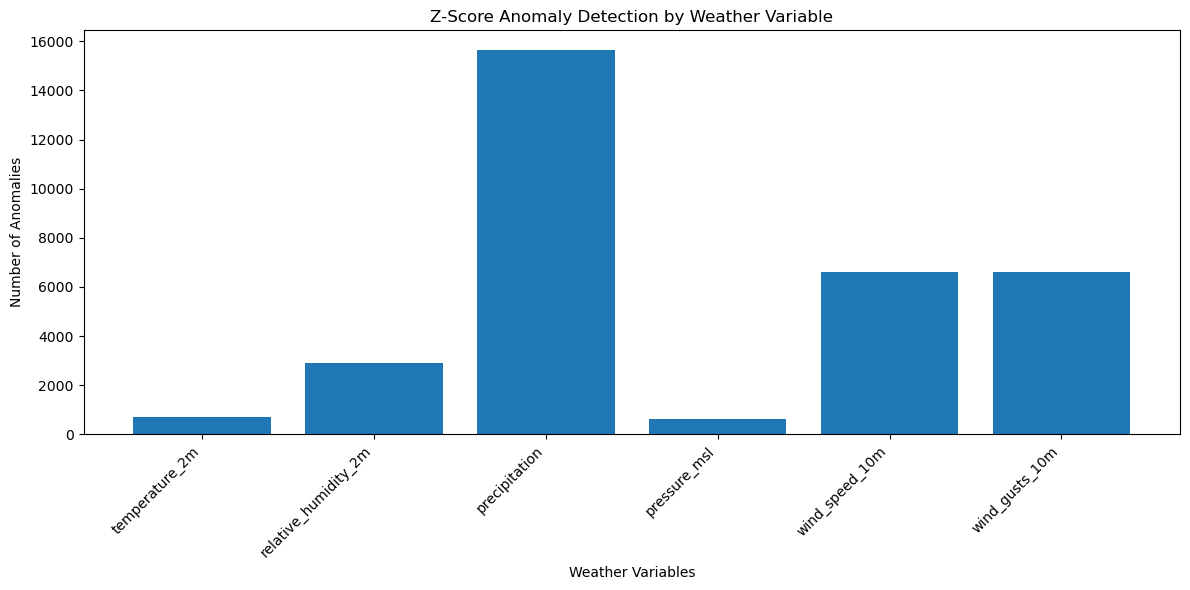

Chart saved successfully.


In [116]:
# ============================================================
# STEP 15.2: VISUALIZE Z-SCORE ANOMALIES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# Check required result file
if not os.path.exists("zscore_anomaly_summary.csv"):
    raise FileNotFoundError(
        "Run Step 15.1 first. Z-score summary file not found."
    )

# Load anomaly summary
anomaly_summary_df = pd.read_csv(
    "zscore_anomaly_summary.csv"
)

# Display summary
print("Z-SCORE ANOMALY SUMMARY")
display(anomaly_summary_df)

# Plot anomaly counts
plt.figure(figsize=(12, 6))

plt.bar(
    anomaly_summary_df["weather_variable"],
    anomaly_summary_df["anomaly_count"]
)

plt.title(
    "Z-Score Anomaly Detection by Weather Variable"
)

plt.xlabel("Weather Variables")
plt.ylabel("Number of Anomalies")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

# Save chart
plt.savefig(
    "zscore_anomaly_variable_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully.")

STEP 15: Z-SCORE BASELINE ANOMALY DETECTION
Dataset shape: (841536, 12)
Total cities: 12
Weather variables: 6

Z-score threshold: 3.0
Total anomaly observations: 28250

VARIABLE-WISE ANOMALY SUMMARY


,weather_variable,valid_observations,anomaly_count,anomaly_percentage
0,temperature_2m,841536,2509,0.2981
1,relative_humidity_2m,841536,2998,0.3563
2,precipitation,841536,14317,1.7013
3,pressure_msl,841536,3311,0.3934
4,wind_speed_10m,841536,5583,0.6634
5,wind_gusts_10m,841536,5696,0.6769



CITY-WISE ANOMALY SUMMARY


,total_records,anomaly_records,anomaly_percentage
city,,,
Leh,70128,3252,4.6372
Guwahati,70128,2856,4.0726
Thiruvananthapuram,70128,2685,3.8287
Srinagar,70128,2430,3.4651
Kolkata,70128,2380,3.3938
Delhi,70128,2367,3.3753
Bhopal,70128,2202,3.1400
Hyderabad,70128,2123,3.0273
Jaipur,70128,2055,2.9304



TEMPERATURE ANOMALIES: 2509
RAINFALL ANOMALIES: 14317
WIND ANOMALIES: 8102

TOP EXTREME OBSERVATIONS


,city,time,season,temperature_2m,temperature_2m_zscore,absolute_zscore,overall_anomaly,analyzed_variable,relative_humidity_2m,relative_humidity_2m_zscore,precipitation,precipitation_zscore,pressure_msl,pressure_msl_zscore,wind_speed_10m,wind_speed_10m_zscore,wind_gusts_10m,wind_gusts_10m_zscore
0,Mumbai,2023-06-10 14:00:00,Monsoon,35.2,5.429946,5.429946,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Mumbai,2023-06-10 13:00:00,Monsoon,35.0,5.287802,5.287802,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Bhopal,2019-06-07 09:00:00,Monsoon,45.7,5.124184,5.124184,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Mumbai,2024-06-08 13:00:00,Monsoon,34.6,5.003514,5.003514,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Bhopal,2019-06-06 09:00:00,Monsoon,45.0,4.927178,4.927178,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Bhopal,2019-06-07 08:00:00,Monsoon,45.0,4.927178,4.927178,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Hyderabad,2019-06-02 14:00:00,Monsoon,41.1,4.887451,4.887451,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Mumbai,2024-06-07 14:00:00,Monsoon,34.4,4.861370,4.861370,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Bhopal,2019-06-05 09:00:00,Monsoon,44.7,4.842747,4.842747,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Bhopal,2019-06-06 08:00:00,Monsoon,44.6,4.814603,4.814603,True,temperature_2m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


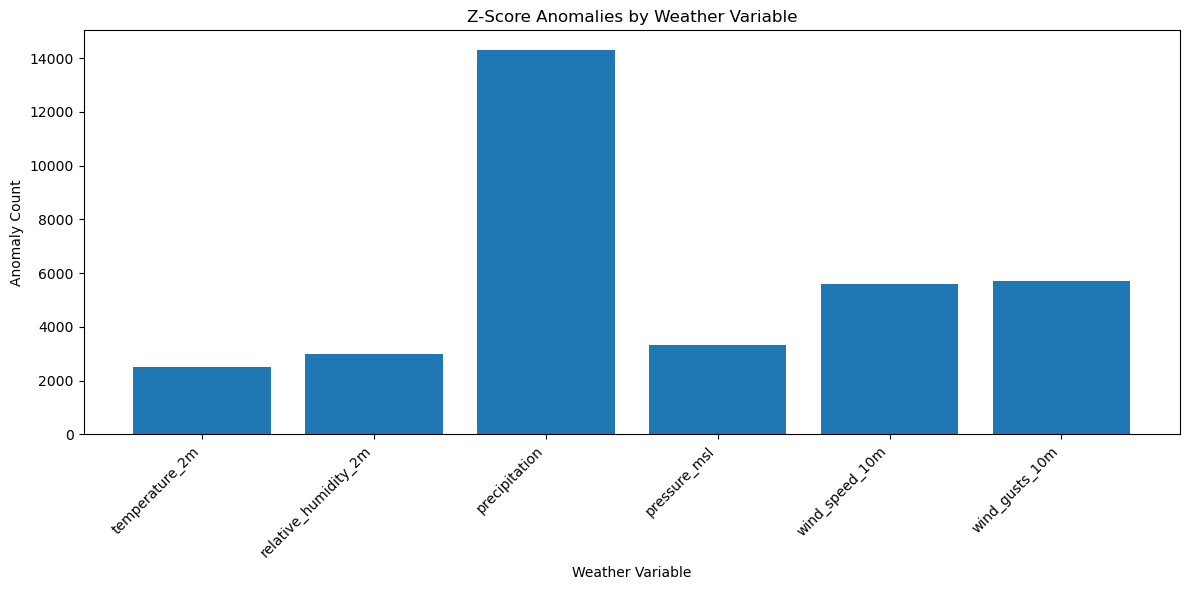

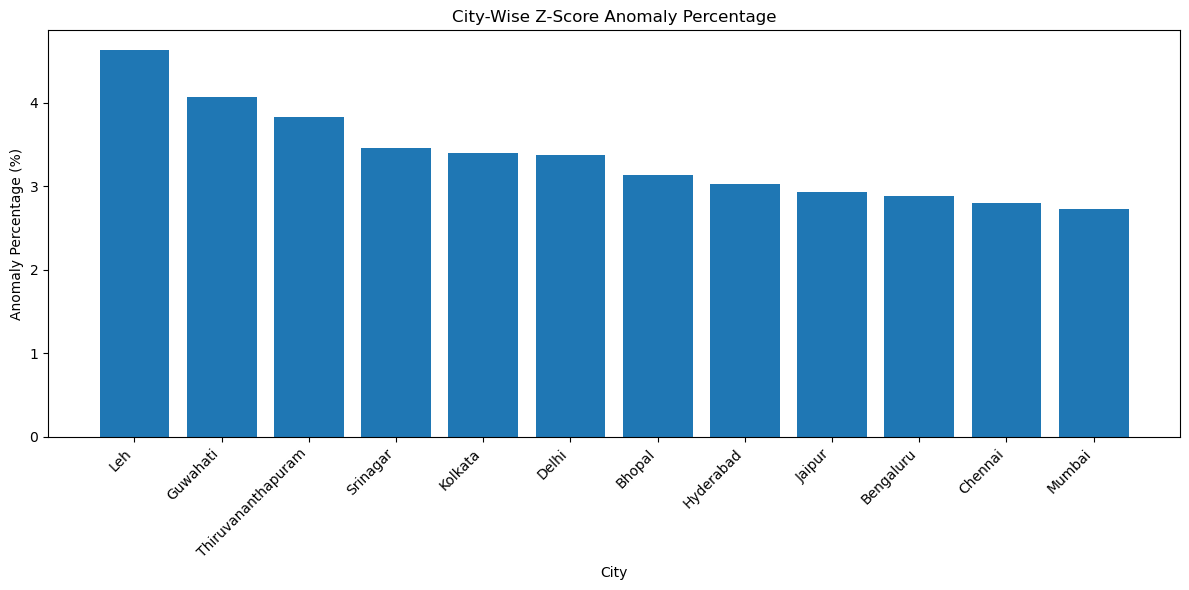

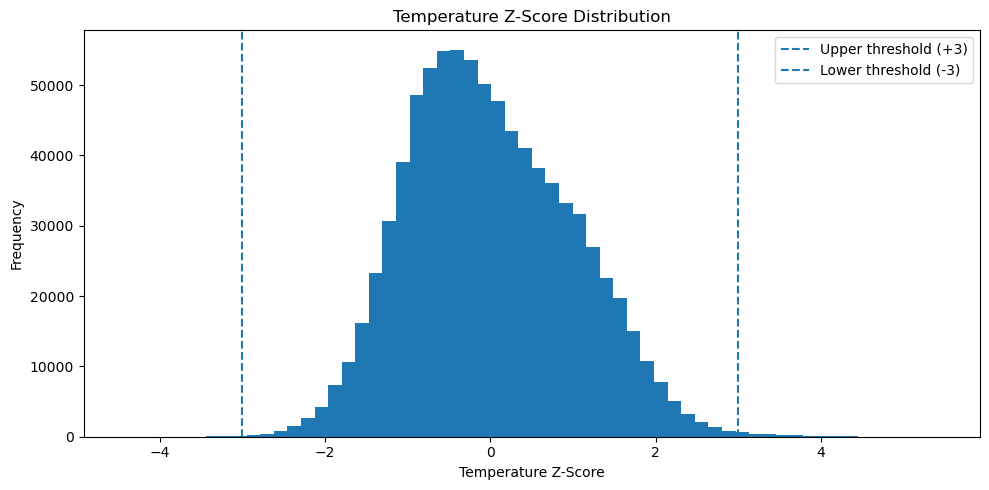


STEP 15 COMPLETED
Total observations: 841536
Total cities: 12
Total anomaly observations: 28250
Normal observations: 813286

Generated output files:
1. india_weather_zscore_results.csv
2. india_weather_zscore_anomalies.csv
3. step15_variable_anomaly_summary.csv
4. step15_city_anomaly_summary.csv
5. step15_temperature_anomalies.csv
6. step15_rainfall_anomalies.csv
7. step15_wind_anomalies.csv
8. step15_top_extreme_observations.csv
9. step15_variable_anomalies.png
10. step15_city_anomalies.png
11. step15_temperature_zscore_distribution.png

All Step 15 analysis and export operations finished.


In [117]:

# ================================================================
# STEP 15: Z-SCORE BASELINE ANOMALY DETECTION
# MSc Research Project:
# Extreme Weather & Micro-Climate Anomaly Early Warning System
#
# Steps 15.1 to 15.8 - Complete Implementation
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ================================================================
# STEP 15.1: LOAD AND VALIDATE DATASET
# ================================================================

file_path = "india_weather_12_cities_combined.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Dataset not found. Complete Step 14 first."
    )

weather_df = pd.read_csv(file_path)

weather_df["time"] = pd.to_datetime(weather_df["time"])

weather_df = weather_df.sort_values(
    ["city", "time"]
).reset_index(drop=True)

weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

required_columns = ["city", "time"] + weather_variables

missing_columns = [
    col for col in required_columns
    if col not in weather_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

if weather_df.duplicated(["city", "time"]).any():
    raise ValueError(
        "Duplicate city-time records found. Resolve them first."
    )

print("=" * 65)
print("STEP 15: Z-SCORE BASELINE ANOMALY DETECTION")
print("=" * 65)

print("Dataset shape:", weather_df.shape)
print("Total cities:", weather_df["city"].nunique())
print("Weather variables:", len(weather_variables))

# ================================================================
# STEP 15.2: CREATE CITY-SPECIFIC SEASONAL Z-SCORES
# ================================================================

# Use the same seasonal definitions as the earlier EDA.

month = weather_df["time"].dt.month

weather_df["season"] = np.select(
    [
        month.isin([12, 1, 2]),
        month.isin([3, 4, 5]),
        month.isin([6, 7, 8, 9]),
        month.isin([10, 11])
    ],
    [
        "Winter",
        "Pre-monsoon",
        "Monsoon",
        "Post-monsoon"
    ],
    default="Unknown"
)

# Calculate mean and standard deviation by city and season.

group_columns = ["city", "season"]

for variable in weather_variables:

    grouped = weather_df.groupby(group_columns)[variable]

    seasonal_mean = grouped.transform("mean")
    seasonal_std = grouped.transform("std")

    weather_df[f"{variable}_zscore"] = (
        (weather_df[variable] - seasonal_mean) /
        seasonal_std.replace(0, np.nan)
    )

# ================================================================
# STEP 15.3: IDENTIFY STATISTICAL ANOMALIES
# ================================================================

threshold = 3.0

for variable in weather_variables:

    weather_df[f"{variable}_anomaly"] = (
        weather_df[f"{variable}_zscore"].abs()
        > threshold
    ).fillna(False)

anomaly_columns = [
    f"{variable}_anomaly"
    for variable in weather_variables
]

weather_df["overall_anomaly"] = (
    weather_df[anomaly_columns].any(axis=1)
)

weather_df["anomaly_variable_count"] = (
    weather_df[anomaly_columns].sum(axis=1)
)

print("\nZ-score threshold:", threshold)
print(
    "Total anomaly observations:",
    int(weather_df["overall_anomaly"].sum())
)

# ================================================================
# STEP 15.4: VARIABLE-WISE ANOMALY ANALYSIS
# ================================================================

anomaly_summary = []

for variable in weather_variables:

    anomaly_count = int(
        weather_df[f"{variable}_anomaly"].sum()
    )

    valid_count = int(
        weather_df[variable].notna().sum()
    )

    anomaly_percentage = (
        anomaly_count / valid_count * 100
        if valid_count > 0 else np.nan
    )

    anomaly_summary.append({
        "weather_variable": variable,
        "valid_observations": valid_count,
        "anomaly_count": anomaly_count,
        "anomaly_percentage": round(
            anomaly_percentage, 4
        )
    })

anomaly_summary_df = pd.DataFrame(anomaly_summary)

print("\nVARIABLE-WISE ANOMALY SUMMARY")
display(anomaly_summary_df)

# ================================================================
# STEP 15.5: CITY-WISE ANOMALY ANALYSIS
# ================================================================

city_anomaly_summary = (
    weather_df.groupby("city")
    .agg(
        total_records=("overall_anomaly", "size"),
        anomaly_records=("overall_anomaly", "sum")
    )
)

city_anomaly_summary["anomaly_percentage"] = (
    city_anomaly_summary["anomaly_records"] /
    city_anomaly_summary["total_records"] * 100
)

city_anomaly_summary = (
    city_anomaly_summary
    .sort_values("anomaly_percentage", ascending=False)
)

print("\nCITY-WISE ANOMALY SUMMARY")
display(city_anomaly_summary.round(4))

# ================================================================
# STEP 15.6: TEMPERATURE, RAINFALL AND WIND ANALYSIS
# ================================================================

# Temperature anomalies

temperature_anomalies = weather_df[
    weather_df["temperature_2m_anomaly"]
].copy()

# Rainfall anomalies

rainfall_anomalies = weather_df[
    weather_df["precipitation_anomaly"]
].copy()

# Wind anomalies: flag either wind speed or wind gust

wind_anomalies = weather_df[
    weather_df["wind_speed_10m_anomaly"] |
    weather_df["wind_gusts_10m_anomaly"]
].copy()

print("\nTEMPERATURE ANOMALIES:", len(temperature_anomalies))
print("RAINFALL ANOMALIES:", len(rainfall_anomalies))
print("WIND ANOMALIES:", len(wind_anomalies))

# ================================================================
# STEP 15.7: EXTRACT TOP EXTREME OBSERVATIONS
# ================================================================

# Rank observations by absolute Z-score for each variable.
# These are statistical extremes, not confirmed hazardous events.

top_extreme_records = []

for variable in weather_variables:

    z_column = f"{variable}_zscore"

    selected = weather_df[
        weather_df[z_column].notna()
    ].copy()

    selected["absolute_zscore"] = (
        selected[z_column].abs()
    )

    selected = selected.nlargest(
        20,
        "absolute_zscore"
    )

    selected["analyzed_variable"] = variable

    top_extreme_records.append(
        selected[
            [
                "city",
                "time",
                "season",
                variable,
                z_column,
                "absolute_zscore",
                "overall_anomaly",
                "analyzed_variable"
            ]
        ]
    )

top_extreme_df = pd.concat(
    top_extreme_records,
    ignore_index=True
)

print("\nTOP EXTREME OBSERVATIONS")
display(top_extreme_df.head(20))

# ================================================================
# STEP 15.8: VISUALIZATION, VALIDATION AND EXPORT
# ================================================================

# Chart 1: Variable-wise anomaly counts

plt.figure(figsize=(12, 6))

plt.bar(
    anomaly_summary_df["weather_variable"],
    anomaly_summary_df["anomaly_count"]
)

plt.title("Z-Score Anomalies by Weather Variable")
plt.xlabel("Weather Variable")
plt.ylabel("Anomaly Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "step15_variable_anomalies.png",
    dpi=300
)

plt.show()

# Chart 2: City-wise anomaly percentages

plt.figure(figsize=(12, 6))

plt.bar(
    city_anomaly_summary.index,
    city_anomaly_summary["anomaly_percentage"]
)

plt.title("City-Wise Z-Score Anomaly Percentage")
plt.xlabel("City")
plt.ylabel("Anomaly Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "step15_city_anomalies.png",
    dpi=300
)

plt.show()

# Chart 3: Temperature anomaly distribution

plt.figure(figsize=(10, 5))

plt.hist(
    weather_df["temperature_2m_zscore"].dropna(),
    bins=60
)

plt.axvline(3, linestyle="--", label="Upper threshold (+3)")
plt.axvline(-3, linestyle="--", label="Lower threshold (-3)")

plt.title("Temperature Z-Score Distribution")
plt.xlabel("Temperature Z-Score")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

plt.savefig(
    "step15_temperature_zscore_distribution.png",
    dpi=300
)

plt.show()

# Export complete dataset with anomaly labels

weather_df.to_csv(
    "india_weather_zscore_results.csv",
    index=False
)

# Export anomaly-only observations

weather_df[
    weather_df["overall_anomaly"]
].to_csv(
    "india_weather_zscore_anomalies.csv",
    index=False
)

# Export summaries

anomaly_summary_df.to_csv(
    "step15_variable_anomaly_summary.csv",
    index=False
)

city_anomaly_summary.to_csv(
    "step15_city_anomaly_summary.csv"
)

temperature_anomalies.to_csv(
    "step15_temperature_anomalies.csv",
    index=False
)

rainfall_anomalies.to_csv(
    "step15_rainfall_anomalies.csv",
    index=False
)

wind_anomalies.to_csv(
    "step15_wind_anomalies.csv",
    index=False
)

top_extreme_df.to_csv(
    "step15_top_extreme_observations.csv",
    index=False
)

# Final validation summary

print("\n" + "=" * 65)
print("STEP 15 COMPLETED")
print("=" * 65)

print("Total observations:", len(weather_df))
print("Total cities:", weather_df["city"].nunique())

print(
    "Total anomaly observations:",
    int(weather_df["overall_anomaly"].sum())
)

print(
    "Normal observations:",
    int((~weather_df["overall_anomaly"]).sum())
)

print("\nGenerated output files:")
print("1. india_weather_zscore_results.csv")
print("2. india_weather_zscore_anomalies.csv")
print("3. step15_variable_anomaly_summary.csv")
print("4. step15_city_anomaly_summary.csv")
print("5. step15_temperature_anomalies.csv")
print("6. step15_rainfall_anomalies.csv")
print("7. step15_wind_anomalies.csv")
print("8. step15_top_extreme_observations.csv")
print("9. step15_variable_anomalies.png")
print("10. step15_city_anomalies.png")
print("11. step15_temperature_zscore_distribution.png")

print("\nAll Step 15 analysis and export operations finished.")


In [1]:

# STEP 16.1 - LOAD AND VALIDATE DATASET

import os
import pandas as pd
import numpy as np

# Dataset path
FILE_PATH = "india_weather_12_cities_combined.csv"

# Check file
if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        "Dataset not found. Check your Jupyter Notebook folder."
    )

# Load dataset
weather_df = pd.read_csv(FILE_PATH)

# Required columns
required_columns = [
    "city",
    "time",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

# Check columns
missing_columns = [
    col for col in required_columns
    if col not in weather_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

# Convert timestamp
weather_df["time"] = pd.to_datetime(
    weather_df["time"],
    errors="coerce",
    utc=True
)

# Remove invalid city and timestamp records
weather_df = weather_df.dropna(
    subset=["city", "time"]
).copy()

# Sort records
weather_df = weather_df.sort_values(
    ["city", "time"]
).reset_index(drop=True)

# Expected cities
expected_cities = {
    "Chennai", "Bengaluru", "Mumbai", "Delhi",
    "Kolkata", "Hyderabad", "Jaipur", "Guwahati",
    "Srinagar", "Thiruvananthapuram", "Bhopal", "Leh"
}

actual_cities = set(weather_df["city"].unique())

# Display validation
print("STEP 16.1 - DATASET VALIDATION")
print("--------------------------------")

print("Dataset shape:", weather_df.shape)
print("Total records:", len(weather_df))
print("Total cities:", weather_df["city"].nunique())

print("\nCity names:")
print(sorted(actual_cities))

print("\nMissing cities:")
print(sorted(expected_cities - actual_cities))

print("\nUnexpected cities:")
print(sorted(actual_cities - expected_cities))

# Check duplicate timestamps
duplicates = weather_df.duplicated(
    subset=["city", "time"]
).sum()

print("\nDuplicate city-time records:", duplicates)

# Final validation
if actual_cities != expected_cities:
    raise ValueError("City validation failed.")

if duplicates > 0:
    raise ValueError("Duplicate records found.")

print("\nSTEP 16.1 COMPLETED SUCCESSFULLY")


C:\Users\admin\AppData\Local\Temp\ipykernel_7720\2563337989.py:17: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  weather_df = pd.read_csv(FILE_PATH)


STEP 16.1 - DATASET VALIDATION
--------------------------------
Dataset shape: (841536, 12)
Total records: 841536
Total cities: 12

City names:
['Bengaluru', 'Bhopal', 'Chennai', 'Delhi', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Leh', 'Mumbai', 'Srinagar', 'Thiruvananthapuram']

Missing cities:
[]

Unexpected cities:
[]

Duplicate city-time records: 0

STEP 16.1 COMPLETED SUCCESSFULLY


In [2]:

# =====================================================
# STEP 16.2 - WEATHER DATA PREPROCESSING
# =====================================================

import numpy as np
import pandas as pd

# Check Step 16.1 variable
if "weather_df" not in globals():
    raise NameError(
        "weather_df not found. Complete Step 16.1 first."
    )

# 1. Select weather variables
weather_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

# 2. Convert variables into numeric format
for col in weather_features:
    weather_df[col] = pd.to_numeric(
        weather_df[col],
        errors="coerce"
    )

# 3. Display missing values before preprocessing
print("MISSING VALUES BEFORE PREPROCESSING")
print("-----------------------------------")
print(weather_df[weather_features].isna().sum())

# 4. Check negative rainfall
negative_rainfall = (
    weather_df["precipitation"] < 0
).sum()

print("\nNegative rainfall records:", negative_rainfall)

# Negative precipitation is invalid
weather_df.loc[
    weather_df["precipitation"] < 0,
    "precipitation"
] = np.nan

# 5. Apply logarithmic transformation to rainfall
weather_df["precipitation_log"] = np.log1p(
    weather_df["precipitation"]
)

# 6. Create seasons
month = weather_df["time"].dt.month

weather_df["season"] = np.select(
    [
        month.isin([12, 1, 2]),
        month.isin([3, 4, 5]),
        month.isin([6, 7, 8, 9]),
        month.isin([10, 11])
    ],
    [
        "Winter",
        "Pre-monsoon",
        "Monsoon",
        "Post-monsoon"
    ],
    default="Unknown"
)

# 7. Select model features
model_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation_log",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

# 8. Fill missing values using city-season medians
for col in model_features:

    group_median = weather_df.groupby(
        ["city", "season"]
    )[col].transform("median")

    weather_df[col] = weather_df[col].fillna(
        group_median
    )

    # Global median is only a fallback for groups
    # where the city-season median is unavailable.
    weather_df[col] = weather_df[col].fillna(
        weather_df[col].median()
    )

# 9. Display missing values after preprocessing
print("\nMISSING VALUES AFTER PREPROCESSING")
print("----------------------------------")
print(weather_df[model_features].isna().sum())

# 10. Validate
if weather_df[model_features].isna().any().any():
    raise ValueError(
        "Some missing values remain. Check the dataset."
    )

# 11. Display season distribution
print("\nSEASON DISTRIBUTION")
print("-------------------")
print(weather_df["season"].value_counts())

# 12. Final report
print("\nPREPROCESSING SUMMARY")
print("---------------------")
print("Dataset shape:", weather_df.shape)
print("Number of cities:", weather_df["city"].nunique())
print("Model features:", model_features)
print("Missing model values:", 
      weather_df[model_features].isna().sum().sum())

print("\nSTEP 16.2 COMPLETED SUCCESSFULLY")


MISSING VALUES BEFORE PREPROCESSING
-----------------------------------
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
wind_gusts_10m          0
dtype: int64

Negative rainfall records: 0

MISSING VALUES AFTER PREPROCESSING
----------------------------------
temperature_2m          0
relative_humidity_2m    0
precipitation_log       0
pressure_msl            0
wind_speed_10m          0
wind_gusts_10m          0
dtype: int64

SEASON DISTRIBUTION
-------------------
season
Monsoon         281088
Pre-monsoon     211968
Winter          207936
Post-monsoon    140544
Name: count, dtype: int64

PREPROCESSING SUMMARY
---------------------
Dataset shape: (841536, 14)
Number of cities: 12
Model features: ['temperature_2m', 'relative_humidity_2m', 'precipitation_log', 'pressure_msl', 'wind_speed_10m', 'wind_gusts_10m']
Missing model values: 0

STEP 16.2 COMPLETED SUCCESSFULLY


In [4]:

# =====================================================
# STEP 16.3 - FEATURE SCALING AND STANDARDISATION
# =====================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Check previous step
if "weather_df" not in globals():
    raise NameError(
        "weather_df not found. Complete Step 16.1 and 16.2."
    )

# 2. Define model features
model_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation_log",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

# 3. Check required features
missing_features = [
    col for col in model_features
    if col not in weather_df.columns
]

if missing_features:
    raise ValueError(
        f"Missing features: {missing_features}"
    )

# 4. Check missing values
if weather_df[model_features].isna().any().any():
    raise ValueError(
        "Missing values found. Complete Step 16.2 first."
    )

# 5. City-season standardisation
scaled_city_season = pd.DataFrame(
    index=weather_df.index,
    columns=model_features,
    dtype=float
)

for col in model_features:

    group = weather_df.groupby(
        ["city", "season"]
    )[col]

    group_mean = group.transform("mean")
    group_std = group.transform("std")

    # Avoid division by zero for constant groups
    group_std = group_std.replace(
        0, np.nan
    ).fillna(1)

    scaled_city_season[col] = (
        weather_df[col] - group_mean
    ) / group_std

# 6. Handle any numerical issues
scaled_city_season = scaled_city_season.replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

# 7. Apply StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    scaled_city_season
)

# 8. Convert into DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=model_features,
    index=weather_df.index
)

# 9. Display results
print("STEP 16.3 - FEATURE SCALING")
print("--------------------------------")

print("Original feature shape:",
      weather_df[model_features].shape)

print("Scaled feature shape:",
      X_scaled_df.shape)

print("\nScaled feature means:")
print(X_scaled_df.mean().round(4))

print("\nScaled feature standard deviations:")
print(X_scaled_df.std().round(4))

print("\nFirst five scaled observations:")
print(X_scaled_df.head())

# 10. Validation
if not np.isfinite(X_scaled).all():
    raise ValueError(
        "Non-finite values found in scaled features."
    )

print("\nSTEP 16.3 COMPLETED SUCCESSFULLY")


STEP 16.3 - FEATURE SCALING
--------------------------------
Original feature shape: (841536, 6)
Scaled feature shape: (841536, 6)

Scaled feature means:
temperature_2m          0.0
relative_humidity_2m   -0.0
precipitation_log      -0.0
pressure_msl           -0.0
wind_speed_10m          0.0
wind_gusts_10m          0.0
dtype: float64

Scaled feature standard deviations:
temperature_2m          1.0
relative_humidity_2m    1.0
precipitation_log       1.0
pressure_msl            1.0
wind_speed_10m          1.0
wind_gusts_10m          1.0
dtype: float64

First five scaled observations:
   temperature_2m  relative_humidity_2m  precipitation_log  pressure_msl  \
0       -1.220259              0.569266          -0.148465     -0.648464   
1       -1.447756              0.946967          -0.148465     -0.772307   
2       -1.473034              1.088606          -0.148465     -1.061273   
3       -1.498311              1.324669          -0.148465     -1.102554   
4       -1.523589             

ISOLATION FOREST MODEL
----------------------
Training observations: 841536
Features: 6

Model training completed.

ISOLATION FOREST RESULTS
------------------------
Anomaly threshold: 0.09580741676354157
Total observations: 841536
Detected anomalies: 8416
Anomaly percentage: 1.0 %

FIRST 10 DETECTED ANOMALIES
---------------------------
           city                      time  temperature_2m  precipitation  \
954   Bengaluru 2018-02-09 18:00:00+00:00            26.2            0.6   
2950  Bengaluru 2018-05-03 22:00:00+00:00            21.4            1.4   
3379  Bengaluru 2018-05-21 19:00:00+00:00            25.6            9.0   
3471  Bengaluru 2018-05-25 15:00:00+00:00            26.0            4.5   
3472  Bengaluru 2018-05-25 16:00:00+00:00            25.2            6.0   
3831  Bengaluru 2018-06-09 15:00:00+00:00            23.7            1.2   
4718  Bengaluru 2018-07-16 14:00:00+00:00            25.0            0.7   
5417  Bengaluru 2018-08-14 17:00:00+00:00           

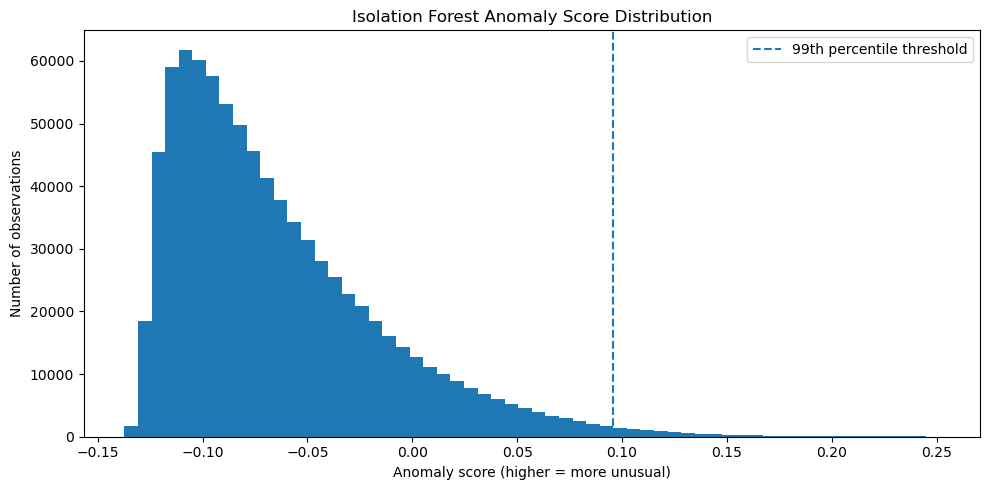


CITY-WISE ISOLATION FOREST RESULTS
----------------------------------
              city  anomaly_count  total_observations  anomaly_percentage
         Bengaluru            468               70128            0.667351
            Bhopal            643               70128            0.916895
           Chennai            768               70128            1.095140
             Delhi            758               70128            1.080881
          Guwahati            778               70128            1.109400
         Hyderabad            688               70128            0.981063
            Jaipur            629               70128            0.896931
           Kolkata            774               70128            1.103696
               Leh           1212               70128            1.728268
            Mumbai            590               70128            0.841319
          Srinagar            382               70128            0.544718
Thiruvananthapuram            726        

In [5]:

# =====================================================
# STEP 16.4 - ISOLATION FOREST ANOMALY DETECTION
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

# 1. Check previous steps
if "X_scaled" not in globals():
    raise NameError(
        "X_scaled not found. Complete Step 16.3 first."
    )

if "weather_df" not in globals():
    raise NameError(
        "weather_df not found. Complete Step 16.1 first."
    )

# 2. Check data
X = np.asarray(X_scaled)

if X.ndim != 2:
    raise ValueError("X_scaled must be a 2D array.")

if not np.isfinite(X).all():
    raise ValueError("X_scaled contains invalid values.")

if len(X) != len(weather_df):
    raise ValueError(
        "X_scaled and weather_df have different row counts."
    )

print("ISOLATION FOREST MODEL")
print("----------------------")
print("Training observations:", len(X))
print("Features:", X.shape[1])

# 3. Create Isolation Forest model
isolation_model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    max_samples="auto",
    random_state=42,
    n_jobs=-1
)

# 4. Train model
isolation_model.fit(X)

print("\nModel training completed.")

# 5. Calculate anomaly scores
# Lower decision_function values indicate more unusual records.
# Negating makes higher scores indicate greater anomaly.

isolation_scores = (
    -isolation_model.decision_function(X)
)

# 6. Define 99th percentile threshold
isolation_threshold = np.percentile(
    isolation_scores,
    99
)

# 7. Identify anomalies
isolation_predictions = (
    isolation_scores > isolation_threshold
)

# 8. Store results
weather_df["isolation_forest_score"] = isolation_scores

weather_df["isolation_forest_anomaly"] = (
    isolation_predictions
)

# 9. Display results
anomaly_count = int(
    weather_df["isolation_forest_anomaly"].sum()
)

anomaly_percentage = (
    anomaly_count / len(weather_df)
) * 100

print("\nISOLATION FOREST RESULTS")
print("------------------------")
print("Anomaly threshold:", isolation_threshold)
print("Total observations:", len(weather_df))
print("Detected anomalies:", anomaly_count)
print("Anomaly percentage:", round(anomaly_percentage, 3), "%")

# 10. Display first anomaly records
anomaly_records = weather_df[
    weather_df["isolation_forest_anomaly"]
].copy()

print("\nFIRST 10 DETECTED ANOMALIES")
print("---------------------------")

print(
    anomaly_records[
        [
            "city",
            "time",
            "temperature_2m",
            "precipitation",
            "wind_speed_10m",
            "isolation_forest_score"
        ]
    ].head(10)
)

# 11. Visualise anomaly scores
plt.figure(figsize=(10, 5))

plt.hist(
    isolation_scores,
    bins=60
)

plt.axvline(
    isolation_threshold,
    linestyle="--",
    label="99th percentile threshold"
)

plt.title("Isolation Forest Anomaly Score Distribution")
plt.xlabel("Anomaly score (higher = more unusual)")
plt.ylabel("Number of observations")
plt.legend()
plt.tight_layout()

plt.savefig(
    "step16_4_isolation_forest_distribution.png",
    dpi=300
)

plt.show()

# 12. City-wise anomaly summary
city_anomalies = (
    weather_df.groupby("city")
    ["isolation_forest_anomaly"]
    .agg(["sum", "count"])
    .reset_index()
)

city_anomalies.columns = [
    "city",
    "anomaly_count",
    "total_observations"
]

city_anomalies["anomaly_percentage"] = (
    city_anomalies["anomaly_count"] /
    city_anomalies["total_observations"]
) * 100

print("\nCITY-WISE ISOLATION FOREST RESULTS")
print("----------------------------------")
print(city_anomalies.to_string(index=False))

# 13. Save outputs
weather_df.to_csv(
    "step16_4_isolation_forest_results.csv",
    index=False
)

anomaly_records.to_csv(
    "step16_4_isolation_forest_anomalies.csv",
    index=False
)

city_anomalies.to_csv(
    "step16_4_city_anomaly_summary.csv",
    index=False
)

print("\nSTEP 16.4 COMPLETED SUCCESSFULLY")
print("Output files saved.")


LOCAL OUTLIER FACTOR
--------------------
Total dataset records: 841536
LOF sample size: 20000

LOF RESULTS
-----------
LOF threshold: 1.542430275888127
Sample observations: 20000
Detected anomalies: 200
Sample anomaly percentage: 1.0 %

FIRST 10 LOF ANOMALIES
----------------------
             city                      time  temperature_2m  precipitation  \
737653   Srinagar 2022-02-24 13:00:00+00:00             6.3            0.3   
711646   Srinagar 2019-03-08 22:00:00+00:00             2.5            0.6   
290455   Guwahati 2019-02-19 07:00:00+00:00            23.4            0.0   
295780   Guwahati 2019-09-29 04:00:00+00:00            25.2            1.3   
760093   Srinagar 2024-09-16 13:00:00+00:00            26.2            0.0   
604956        Leh 2023-01-05 12:00:00+00:00           -15.3            0.0   
115532     Bhopal 2023-03-07 20:00:00+00:00            18.3            0.0   
365935  Hyderabad 2019-09-30 07:00:00+00:00            25.2            0.0   
485619     Jai

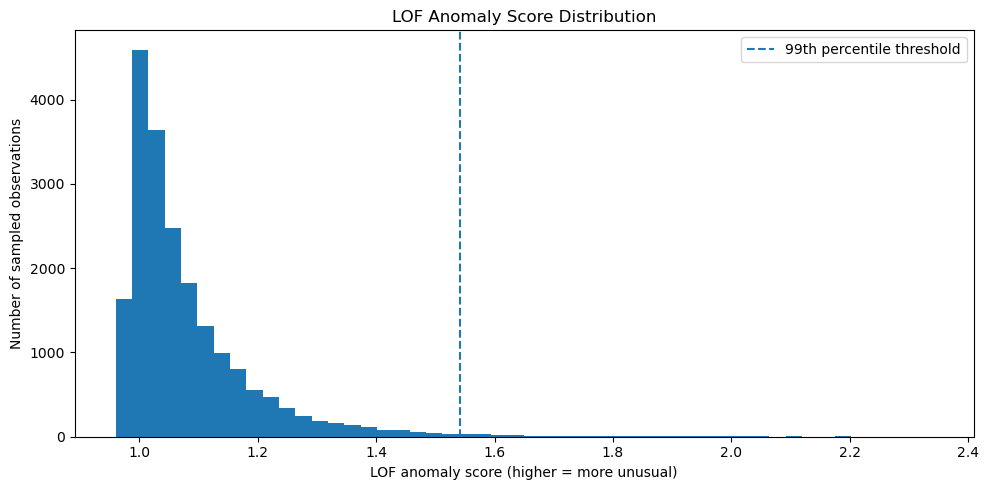


CITY-WISE LOF SAMPLE RESULTS
----------------------------
              city  sampled_records  anomaly_count  anomaly_percentage
         Bengaluru             1684              6            0.356295
            Bhopal             1701             12            0.705467
           Chennai             1668             17            1.019185
             Delhi             1692              5            0.295508
          Guwahati             1676             20            1.193317
         Hyderabad             1668             14            0.839329
            Jaipur             1695              9            0.530973
           Kolkata             1668             11            0.659472
               Leh             1680             25            1.488095
            Mumbai             1628              4            0.245700
          Srinagar             1572             56            3.562341
Thiruvananthapuram             1668             21            1.258993

STEP 16.5 COMPLET

In [6]:

# =====================================================
# STEP 16.5 - LOCAL OUTLIER FACTOR (LOF)
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import LocalOutlierFactor

# 1. Check previous steps
if "X_scaled" not in globals():
    raise NameError(
        "X_scaled not found. Complete Step 16.3 first."
    )

if "weather_df" not in globals():
    raise NameError(
        "weather_df not found. Complete Step 16.1 first."
    )

X = np.asarray(X_scaled)

if len(X) != len(weather_df):
    raise ValueError(
        "Feature and dataset row counts do not match."
    )

if not np.isfinite(X).all():
    raise ValueError(
        "Invalid values found in X_scaled."
    )

# 2. Select a manageable sample
# LOF can be computationally expensive on very large datasets.

SAMPLE_SIZE = min(20000, len(X))

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X),
    size=SAMPLE_SIZE,
    replace=False
)

X_sample = X[sample_indices]

print("LOCAL OUTLIER FACTOR")
print("--------------------")
print("Total dataset records:", len(X))
print("LOF sample size:", len(X_sample))

# 3. Create LOF model
lof_model = LocalOutlierFactor(
    n_neighbors=35,
    contamination="auto",
    novelty=False,
    n_jobs=-1
)

# 4. Train and detect anomalies on the sample
lof_predictions = lof_model.fit_predict(X_sample)

# -1 = anomaly
#  1 = normal observation

# 5. Calculate LOF anomaly scores
# Negative outlier factors are lower for more unusual observations.
# Negate to make higher values indicate greater anomaly.

lof_scores_sample = (
    -lof_model.negative_outlier_factor_
)

# 6. Define 99th percentile score threshold
lof_threshold = np.percentile(
    lof_scores_sample,
    99
)

# 7. Convert scores into anomaly flags
lof_anomaly_sample = (
    lof_scores_sample > lof_threshold
)

# 8. Create result columns for the full dataset.
# Only sampled records are scored in this step.
weather_df["lof_score"] = np.nan

weather_df["lof_anomaly"] = False

weather_df.loc[
    sample_indices,
    "lof_score"
] = lof_scores_sample

weather_df.loc[
    sample_indices,
    "lof_anomaly"
] = lof_anomaly_sample

# 9. Display results
anomaly_count = int(
    lof_anomaly_sample.sum()
)

anomaly_percentage = (
    anomaly_count / SAMPLE_SIZE
) * 100

print("\nLOF RESULTS")
print("-----------")
print("LOF threshold:", lof_threshold)
print("Sample observations:", SAMPLE_SIZE)
print("Detected anomalies:", anomaly_count)
print(
    "Sample anomaly percentage:",
    round(anomaly_percentage, 3),
    "%"
)

# 10. Display detected anomalies
lof_anomalies = weather_df.loc[
    sample_indices
].loc[
    lambda x: x["lof_anomaly"]
].copy()

print("\nFIRST 10 LOF ANOMALIES")
print("----------------------")

print(
    lof_anomalies[
        [
            "city",
            "time",
            "temperature_2m",
            "precipitation",
            "wind_speed_10m",
            "lof_score"
        ]
    ].head(10)
)

# 11. Visualise anomaly scores
plt.figure(figsize=(10, 5))

plt.hist(
    lof_scores_sample,
    bins=50
)

plt.axvline(
    lof_threshold,
    linestyle="--",
    label="99th percentile threshold"
)

plt.title("LOF Anomaly Score Distribution")
plt.xlabel("LOF anomaly score (higher = more unusual)")
plt.ylabel("Number of sampled observations")
plt.legend()
plt.tight_layout()

plt.savefig(
    "step16_5_lof_distribution.png",
    dpi=300
)

plt.show()

# 12. City-wise sample summary
lof_city_summary = (
    weather_df.loc[sample_indices]
    .groupby("city")
    .agg(
        sampled_records=("lof_anomaly", "count"),
        anomaly_count=("lof_anomaly", "sum")
    )
    .reset_index()
)

lof_city_summary["anomaly_percentage"] = (
    lof_city_summary["anomaly_count"] /
    lof_city_summary["sampled_records"]
) * 100

print("\nCITY-WISE LOF SAMPLE RESULTS")
print("----------------------------")
print(lof_city_summary.to_string(index=False))

# 13. Save results
weather_df.to_csv(
    "step16_5_lof_results.csv",
    index=False
)

lof_anomalies.to_csv(
    "step16_5_lof_anomalies.csv",
    index=False
)

lof_city_summary.to_csv(
    "step16_5_lof_city_summary.csv",
    index=False
)

print("\nSTEP 16.5 COMPLETED SUCCESSFULLY")

print("Files saved:")
print("1. step16_5_lof_results.csv")
print("2. step16_5_lof_anomalies.csv")
print("3. step16_5_lof_city_summary.csv")
print("4. step16_5_lof_distribution.png")


In [ ]:

%pip install tensorflow


In [2]:

import sys
import platform

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Operating system:", platform.platform())


Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python executable: C:\ProgramData\anaconda3\python.exe
Operating system: Windows-11-10.0.22631-SP0


In [5]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python location: C:\ProgramData\anaconda3\python.exe


In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

ModuleNotFoundError: No module named 'tensorflow'

In [2]:

import sys
import subprocess

print("Active Python:", sys.executable)
print("Python version:", sys.version)

print("\nChecking TensorFlow installation...")

result = subprocess.run(
    [sys.executable, "-m", "pip", "show", "tensorflow"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print(result.stdout)
else:
    print("TensorFlow is NOT installed in this notebook environment.")


Active Python: C:\ProgramData\anaconda3\python.exe
Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]

Checking TensorFlow installation...
TensorFlow is NOT installed in this notebook environment.


In [3]:
conda env list


# conda environments:
#
# * -> active
# + -> frozen
base                 *   C:\ProgramData\anaconda3


Note: you may need to restart the kernel to use updated packages.


In [1]:
import sys
import tensorflow as tf

print("Python:", sys.version)
print("Python path:", sys.executable)
print("TensorFlow:", tf.__version__)

ModuleNotFoundError: No module named 'tensorflow'

In [2]:
import sys
print(sys.executable)

C:\ProgramData\anaconda3\python.exe


In [1]:
import sys
import tensorflow as tf

print("Python path:", sys.executable)
print("TensorFlow version:", tf.__version__)

Python path: C:\Users\admin\.conda\envs\weather_tf\python.exe
TensorFlow version: 2.21.0


In [2]:
import sys

print("Python version:", sys.version)
print("Python path:", sys.executable)

Python version: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
Python path: C:\Users\admin\.conda\envs\weather_tf\python.exe


In [5]:

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("TensorFlow is ready!")

# Check previous project variables
if "weather_df" not in globals():
    raise NameError("weather_df is missing. Run previous project steps.")

if "X_scaled" not in globals():
    raise NameError("X_scaled is missing. Run Step 16.3.")

X_autoencoder = np.asarray(X_scaled, dtype=np.float32)

if not np.isfinite(X_autoencoder).all():
    raise ValueError("Invalid values found in scaled data.")

print("\nAUTOENCODER DATA VALIDATION")
print("Total records:", len(weather_df))
print("Input features:", X_autoencoder.shape[1])
print("Input shape:", X_autoencoder.shape)
print("Number of cities:", weather_df["city"].nunique())

print("\nSTEP 16.6.1 COMPLETED")


Python version: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
TensorFlow version: 2.21.0
TensorFlow is ready!


NameError: weather_df is missing. Run previous project steps.

In [7]:

# ==========================================================
# RECOVERY STEP - CORRECTED WEATHER DATA PREPROCESSING
# ==========================================================

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

# 1. Load dataset
file_path = "india_weather_12_cities_combined.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Weather dataset not found: " + file_path
    )

weather_df = pd.read_csv(
    file_path,
    low_memory=False
)

print("Original dataset loaded:", weather_df.shape)

# 2. Check required columns
weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

required_columns = ["city", "time"] + weather_variables

missing_columns = [
    col for col in required_columns
    if col not in weather_df.columns
]

if missing_columns:
    raise ValueError(
        "Missing columns: " + str(missing_columns)
    )

# 3. Convert timestamp
weather_df["time"] = pd.to_datetime(
    weather_df["time"],
    utc=True,
    errors="coerce"
)

weather_df = weather_df.dropna(
    subset=["city", "time"]
).copy()

weather_df = weather_df.sort_values(
    ["city", "time"]
).reset_index(drop=True)

# 4. Convert weather variables to float
for col in weather_variables:
    weather_df[col] = pd.to_numeric(
        weather_df[col],
        errors="coerce"
    ).astype("float64")

# 5. Correct negative precipitation
weather_df.loc[
    weather_df["precipitation"] < 0,
    "precipitation"
] = np.nan

# 6. Create log rainfall feature
weather_df["precipitation_log"] = np.log1p(
    weather_df["precipitation"]
)

# 7. Create seasons
month = weather_df["time"].dt.month

weather_df["season"] = np.select(
    [
        month.isin([12, 1, 2]),
        month.isin([3, 4, 5]),
        month.isin([6, 7, 8, 9]),
        month.isin([10, 11])
    ],
    [
        "Winter",
        "Pre-monsoon",
        "Monsoon",
        "Post-monsoon"
    ],
    default="Unknown"
)

# 8. Define model features
model_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation_log",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

# 9. Convert all model features to float
weather_df[model_features] = weather_df[
    model_features
].astype("float64")

# 10. Impute missing values by city and season
for col in model_features:

    city_season_median = weather_df.groupby(
        ["city", "season"]
    )[col].transform("median")

    weather_df[col] = weather_df[col].fillna(
        city_season_median
    )

    # Global median fallback
    global_median = weather_df[col].median()

    if pd.isna(global_median):
        raise ValueError(
            f"Entire feature is missing: {col}"
        )

    weather_df[col] = weather_df[col].fillna(
        global_median
    )

# 11. Validate missing values
if weather_df[model_features].isna().any().any():
    raise ValueError("Missing model values remain.")

# 12. City-season scaling
scaled_city_season = weather_df[
    model_features
].astype("float64").copy()

for indices in weather_df.groupby(
    ["city", "season"]
).groups.values():

    group_values = weather_df.loc[
        indices, model_features
    ]

    means = group_values.mean()

    stds = group_values.std().replace(
        0, 1
    ).fillna(1)

    scaled_values = (
        group_values - means
    ) / stds

    scaled_city_season.loc[
        indices, model_features
    ] = scaled_values.to_numpy()

# 13. StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    scaled_city_season[model_features]
).astype(np.float32)

# 14. Final validation
print("\nRECOVERY RESULTS")
print("----------------")
print("Dataset shape:", weather_df.shape)
print("City count:", weather_df["city"].nunique())
print("Feature count:", len(model_features))
print("Scaled shape:", X_scaled.shape)

print(
    "Missing values:",
    weather_df[model_features].isna().sum().sum()
)

print(
    "All scaled values finite:",
    np.isfinite(X_scaled).all()
)

print("\nFeature data types:")
print(weather_df[model_features].dtypes)

print("\nRECOVERY COMPLETED SUCCESSFULLY")


Original dataset loaded: (841536, 12)

RECOVERY RESULTS
----------------
Dataset shape: (841536, 14)
City count: 12
Feature count: 6
Scaled shape: (841536, 6)
Missing values: 0
All scaled values finite: True

Feature data types:
temperature_2m          float64
relative_humidity_2m    float64
precipitation_log       float64
pressure_msl            float64
wind_speed_10m          float64
wind_gusts_10m          float64
dtype: object

RECOVERY COMPLETED SUCCESSFULLY


In [8]:

# STEP 16.6.2 - BUILD AUTOENCODER ARCHITECTURE

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# 1. Verify input data
if "X_scaled" not in globals():
    raise NameError("X_scaled is missing. Run the recovery cell first.")

if X_scaled.ndim != 2:
    raise ValueError("X_scaled must be a two-dimensional array.")

if not np.isfinite(X_scaled).all():
    raise ValueError("X_scaled contains non-finite values.")

# 2. Get number of input features
input_dim = X_scaled.shape[1]

# 3. Build Autoencoder
autoencoder = Sequential([
    Input(shape=(input_dim,)),

    # Encoder
    Dense(4, activation="relu", name="encoder_layer"),
    Dense(2, activation="relu", name="bottleneck_layer"),

    # Decoder
    Dense(4, activation="relu", name="decoder_layer"),
    Dense(input_dim, activation="linear", name="output_layer")
])

# 4. Compile the model
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

# 5. Display model architecture
print("STEP 16.6.2 - AUTOENCODER ARCHITECTURE")
print("--------------------------------------")

autoencoder.summary()

print("\nInput data shape:", X_scaled.shape)
print("Number of input features:", input_dim)
print("Model parameters:", autoencoder.count_params())
print("Optimizer: Adam")
print("Loss function: Mean Squared Error (MSE)")

print("\nAUTOENCODER ARCHITECTURE CREATED SUCCESSFULLY.")


STEP 16.6.2 - AUTOENCODER ARCHITECTURE
--------------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ encoder_layer (Dense)                │ (None, 4)                   │              28 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bottleneck_layer (Dense)             │ (None, 2)                   │              10 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ decoder_layer (Dense)                │ (None, 4)                   │              12 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 6)                   │              30 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 80 (320.00 B)

 Trainable params: 80 (320.00 B)

 Non-trainable params: 0 (0.00 B)


Input data shape: (841536, 6)
Number of input features: 6
Model parameters: 80
Optimizer: Adam
Loss function: Mean Squared Error (MSE)

AUTOENCODER ARCHITECTURE CREATED SUCCESSFULLY.


In [9]:

# STEP 16.6.3 - TRAIN AUTOENCODER

import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

# 1. Verify model and input data
if "autoencoder" not in globals():
    raise NameError("Run Step 16.6.2 first to create the autoencoder.")

if "X_scaled" not in globals():
    raise NameError("X_scaled is missing. Run the recovery cell first.")

if X_scaled.shape[1] != autoencoder.input_shape[1]:
    raise ValueError("Input feature count does not match model architecture.")

# 2. Chronological train-validation split
split_index = int(len(X_scaled) * 0.80)

X_train = X_scaled[:split_index]
X_val = X_scaled[split_index:]

print("TRAINING DATA SHAPE:", X_train.shape)
print("VALIDATION DATA SHAPE:", X_val.shape)

# 3. Early stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# 4. Train autoencoder
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=30,
    batch_size=1024,
    validation_data=(X_val, X_val),
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

# 5. Training summary
print("\nSTEP 16.6.3 - TRAINING RESULTS")
print("--------------------------------")

print("Epochs completed:", len(history.history["loss"]))
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])
print("Best validation loss:", min(history.history["val_loss"]))

print("\nAUTOENCODER TRAINING COMPLETED.")


TRAINING DATA SHAPE: (673228, 6)
VALIDATION DATA SHAPE: (168308, 6)
Epoch 1/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 0.9020 - val_loss: 0.8238
Epoch 2/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.7954 - val_loss: 0.7578
Epoch 3/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.7265 - val_loss: 0.7043
Epoch 4/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6766 - val_loss: 0.6771
Epoch 5/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6487 - val_loss: 0.6643
Epoch 6/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.6341 - val_loss: 0.6586
Epoch 7/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.6267 - val_loss: 0.6561
Epoch 8/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.6227 - val_loss: 0.6551
Epoch 9/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.6206 - val_loss: 0.6548
Epoch 10/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6192 - val_loss: 0.6546
Epoch 11/30
658/658 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6184 - v

822/822 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
STEP 16.6.4 - RECONSTRUCTION ERROR RESULTS
------------------------------------------
Total observations: 841536
Minimum error: 0.0013543544
Maximum error: 238.90472
Mean error: 0.5994738
Median error: 0.35541132
99th percentile threshold: 3.8665063

Detected anomalies: 8416
Anomaly percentage: 1.0 %


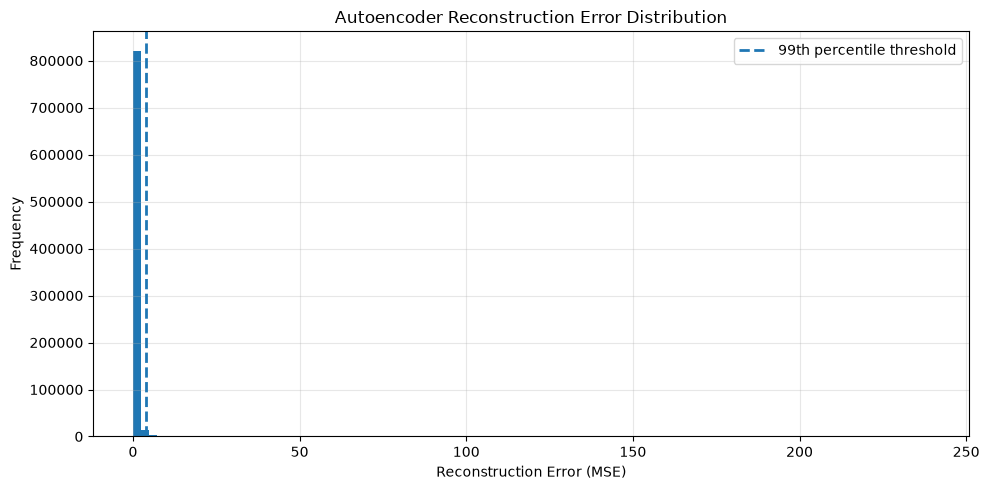


RECONSTRUCTION ERROR CALCULATION COMPLETED.


In [10]:

# STEP 16.6.4 - RECONSTRUCTION ERROR CALCULATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Verify required variables
required = ["autoencoder", "X_scaled", "weather_df"]

for variable in required:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Complete the previous steps first."
        )

# 2. Generate reconstructed observations
X_reconstructed = autoencoder.predict(
    X_scaled,
    batch_size=1024,
    verbose=1
)

# 3. Calculate reconstruction error (MSE)
reconstruction_errors = np.mean(
    np.square(X_scaled - X_reconstructed),
    axis=1
)

# 4. Add errors to the dataset
weather_df["autoencoder_error"] = reconstruction_errors

# 5. Calculate screening threshold
threshold = np.percentile(reconstruction_errors, 99)

weather_df["autoencoder_anomaly"] = (
    weather_df["autoencoder_error"] > threshold
).astype(int)

# 6. Display results
print("STEP 16.6.4 - RECONSTRUCTION ERROR RESULTS")
print("------------------------------------------")

print("Total observations:", len(reconstruction_errors))
print("Minimum error:", np.min(reconstruction_errors))
print("Maximum error:", np.max(reconstruction_errors))
print("Mean error:", np.mean(reconstruction_errors))
print("Median error:", np.median(reconstruction_errors))
print("99th percentile threshold:", threshold)

anomaly_count = int(weather_df["autoencoder_anomaly"].sum())

print("\nDetected anomalies:", anomaly_count)
print(
    "Anomaly percentage:",
    round(anomaly_count / len(weather_df) * 100, 2),
    "%"
)

# 7. Plot reconstruction error distribution
plt.figure(figsize=(10, 5))

plt.hist(
    reconstruction_errors,
    bins=100
)

plt.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label="99th percentile threshold"
)

plt.title("Autoencoder Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nRECONSTRUCTION ERROR CALCULATION COMPLETED.")


STEP 16.6.5 - AUTOENCODER ANALYSIS
-----------------------------------

TOTAL RECORDS: 841536
TOTAL ANOMALIES: 8416

CITY-WISE ANOMALY SUMMARY
              city  total_records  detected_anomalies  average_error  anomaly_percentage
           Chennai          70128                 908       0.594009            1.294775
             Delhi          70128                 871       0.550586            1.242015
           Kolkata          70128                 810       0.581298            1.155031
         Hyderabad          70128                 795       0.631362            1.133641
         Bengaluru          70128                 765       0.583639            1.090862
               Leh          70128                 753       0.598916            1.073751
            Jaipur          70128                 722       0.560619            1.029546
          Guwahati          70128                 651       0.579549            0.928303
            Bhopal          70128                 621   

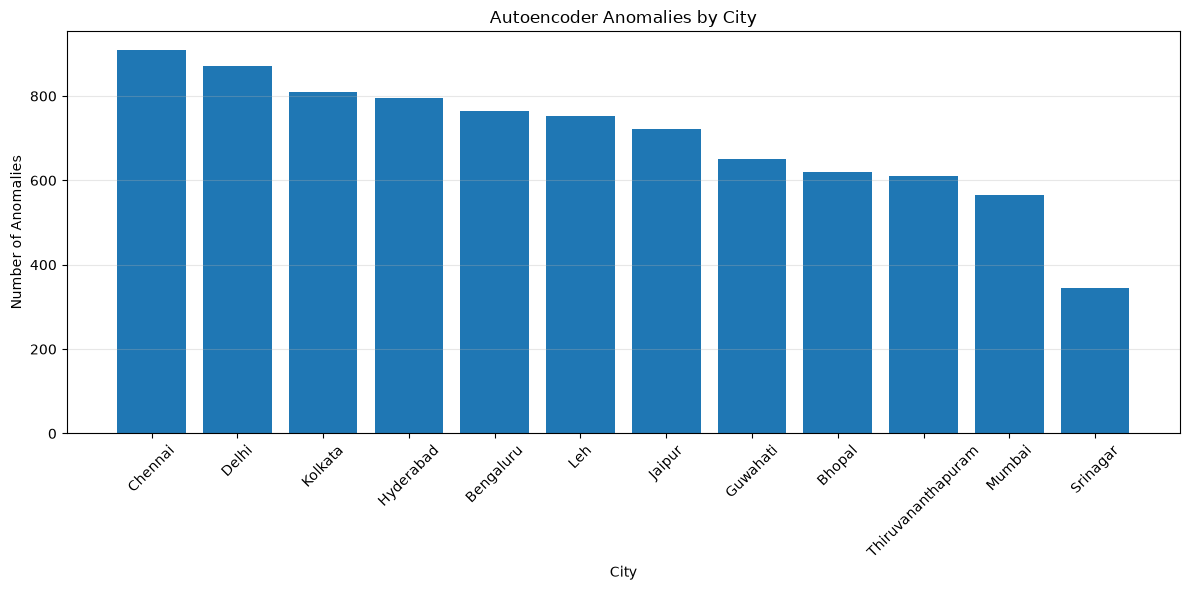


FILES SAVED SUCCESSFULLY:
1. step16_6_autoencoder_all_results.csv
2. step16_6_autoencoder_anomalies.csv
3. step16_6_autoencoder_city_summary.csv
4. step16_6_autoencoder_reconstruction_errors.csv
5. step16_6_autoencoder_city_anomalies.png

STEP 16.6 COMPLETED SUCCESSFULLY.


In [11]:

# STEP 16.6.5 - AUTOENCODER ANALYSIS AND EXPORT

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Verify required columns
required_columns = [
    "city",
    "time",
    "autoencoder_error",
    "autoencoder_anomaly"
]

missing_columns = [
    col for col in required_columns
    if col not in weather_df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# 2. Create anomaly dataset
autoencoder_anomalies = weather_df[
    weather_df["autoencoder_anomaly"] == 1
].copy()

# 3. Sort anomalies by reconstruction error
autoencoder_anomalies = autoencoder_anomalies.sort_values(
    "autoencoder_error",
    ascending=False
)

# 4. City-wise anomaly summary
city_summary = (
    weather_df.groupby("city")
    .agg(
        total_records=("autoencoder_anomaly", "size"),
        detected_anomalies=("autoencoder_anomaly", "sum"),
        average_error=("autoencoder_error", "mean")
    )
    .reset_index()
)

city_summary["anomaly_percentage"] = (
    city_summary["detected_anomalies"]
    / city_summary["total_records"] * 100
)

city_summary = city_summary.sort_values(
    "anomaly_percentage",
    ascending=False
)

# 5. Display results
print("STEP 16.6.5 - AUTOENCODER ANALYSIS")
print("-----------------------------------")

print("\nTOTAL RECORDS:", len(weather_df))
print("TOTAL ANOMALIES:", len(autoencoder_anomalies))

print("\nCITY-WISE ANOMALY SUMMARY")
print(city_summary.to_string(index=False))

print("\nTOP 10 AUTOENCODER ANOMALIES")

display_columns = [
    col for col in [
        "city",
        "time",
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "wind_speed_10m",
        "wind_gusts_10m",
        "autoencoder_error"
    ]
    if col in autoencoder_anomalies.columns
]

print(
    autoencoder_anomalies[display_columns]
    .head(10)
    .to_string(index=False)
)

# 6. Plot city-wise anomaly counts
plt.figure(figsize=(12, 6))

plt.bar(
    city_summary["city"],
    city_summary["detected_anomalies"]
)

plt.title("Autoencoder Anomalies by City")
plt.xlabel("City")
plt.ylabel("Number of Anomalies")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "step16_6_autoencoder_city_anomalies.png",
    dpi=300
)
plt.show()

# 7. Save results
weather_df.to_csv(
    "step16_6_autoencoder_all_results.csv",
    index=False
)

autoencoder_anomalies.to_csv(
    "step16_6_autoencoder_anomalies.csv",
    index=False
)

city_summary.to_csv(
    "step16_6_autoencoder_city_summary.csv",
    index=False
)

# 8. Save reconstruction errors separately
error_summary = pd.DataFrame({
    "reconstruction_error": reconstruction_errors
})

error_summary.to_csv(
    "step16_6_autoencoder_reconstruction_errors.csv",
    index=False
)

print("\nFILES SAVED SUCCESSFULLY:")
print("1. step16_6_autoencoder_all_results.csv")
print("2. step16_6_autoencoder_anomalies.csv")
print("3. step16_6_autoencoder_city_summary.csv")
print("4. step16_6_autoencoder_reconstruction_errors.csv")
print("5. step16_6_autoencoder_city_anomalies.png")

print("\nSTEP 16.6 COMPLETED SUCCESSFULLY.")


In [12]:

# STEP 16.7.1 - LOAD AND INSPECT MODEL RESULTS

import os
import pandas as pd

result_files = {
    "Z-score": "india_weather_zscore_results.csv",
    "Isolation Forest": "step16_4_isolation_forest_results.csv",
    "LOF": "step16_5_lof_results.csv",
    "Autoencoder": "step16_6_autoencoder_all_results.csv"
}

loaded_results = {}

print("STEP 16.7.1 - MODEL RESULT FILE INSPECTION")
print("-------------------------------------------")

for model_name, file_name in result_files.items():

    print(f"\n{'=' * 55}")
    print("MODEL:", model_name)
    print("FILE:", file_name)

    if not os.path.exists(file_name):
        print("STATUS: FILE NOT FOUND")
        continue

    df = pd.read_csv(file_name, low_memory=False)

    loaded_results[model_name] = df

    print("STATUS: LOADED SUCCESSFULLY")
    print("Dataset shape:", df.shape)
    print("Columns:")
    
    for column in df.columns:
        print(" -", column)

    print("\nFirst 3 records:")
    print(df.head(3).to_string(index=False))

print("\nINSPECTION SUMMARY")
print("------------------")

for model_name, df in loaded_results.items():
    print(f"{model_name}: {df.shape[0]} records")

print("\nSTEP 16.7.1 COMPLETED.")


STEP 16.7.1 - MODEL RESULT FILE INSPECTION
-------------------------------------------

MODEL: Z-score
FILE: india_weather_zscore_results.csv
STATUS: LOADED SUCCESSFULLY
Dataset shape: (841536, 27)
Columns:
 - time
 - temperature_2m
 - relative_humidity_2m
 - precipitation
 - pressure_msl
 - wind_speed_10m
 - wind_direction_10m
 - wind_gusts_10m
 - city
 - state
 - latitude
 - longitude
 - season
 - temperature_2m_zscore
 - relative_humidity_2m_zscore
 - precipitation_zscore
 - pressure_msl_zscore
 - wind_speed_10m_zscore
 - wind_gusts_10m_zscore
 - temperature_2m_anomaly
 - relative_humidity_2m_anomaly
 - precipitation_anomaly
 - pressure_msl_anomaly
 - wind_speed_10m_anomaly
 - wind_gusts_10m_anomaly
 - overall_anomaly
 - anomaly_variable_count

First 3 records:
               time  temperature_2m  relative_humidity_2m  precipitation  pressure_msl  wind_speed_10m  wind_direction_10m  wind_gusts_10m      city     state  latitude  longitude season  temperature_2m_zscore  relative_humid

In [13]:

# STEP 16.7.2 - STANDARDISE AND ALIGN MODEL RESULTS

import pandas as pd
import numpy as np
import os

# 1. Load model result files
zscore_df = pd.read_csv(
    "india_weather_zscore_results.csv",
    low_memory=False
)

if_df = pd.read_csv(
    "step16_4_isolation_forest_results.csv",
    low_memory=False
)

lof_df = pd.read_csv(
    "step16_5_lof_results.csv",
    low_memory=False
)

ae_df = pd.read_csv(
    "step16_6_autoencoder_all_results.csv",
    low_memory=False
)

# 2. Prepare common city-time keys
def prepare_keys(df, model_name):
    df = df.copy()

    required = ["city", "time"]
    for col in required:
        if col not in df.columns:
            raise ValueError(
                f"{model_name}: missing column {col}"
            )

    df["city"] = df["city"].astype(str).str.strip()
    df["time"] = pd.to_datetime(
        df["time"],
        utc=True,
        errors="coerce"
    )

    if df["time"].isna().any():
        raise ValueError(
            f"{model_name}: invalid timestamps found."
        )

    if df.duplicated(["city", "time"]).any():
        raise ValueError(
            f"{model_name}: duplicate city-time records found."
        )

    return df

zscore_df = prepare_keys(zscore_df, "Z-score")
if_df = prepare_keys(if_df, "Isolation Forest")
lof_df = prepare_keys(lof_df, "LOF")
ae_df = prepare_keys(ae_df, "Autoencoder")

# 3. Create base comparison dataset
comparison_df = zscore_df[
    ["city", "time", "overall_anomaly"]
].copy()

comparison_df = comparison_df.rename(
    columns={"overall_anomaly": "zscore_anomaly"}
)

# 4. Extract Isolation Forest results
if_results = if_df[
    ["city", "time", "isolation_forest_anomaly"]
].copy()

comparison_df = comparison_df.merge(
    if_results,
    on=["city", "time"],
    how="left",
    validate="one_to_one"
)

# 5. Extract LOF results
lof_results = lof_df[
    ["city", "time", "lof_score", "lof_anomaly"]
].copy()

comparison_df = comparison_df.merge(
    lof_results,
    on=["city", "time"],
    how="left",
    validate="one_to_one"
)

# 6. Extract Autoencoder results
ae_results = ae_df[
    ["city", "time", "autoencoder_error",
     "autoencoder_anomaly"]
].copy()

comparison_df = comparison_df.merge(
    ae_results,
    on=["city", "time"],
    how="left",
    validate="one_to_one"
)

# 7. Standardise anomaly flags
comparison_df["zscore_anomaly"] = (
    comparison_df["zscore_anomaly"].astype(bool).astype(int)
)

comparison_df["isolation_forest_anomaly"] = (
    comparison_df["isolation_forest_anomaly"]
    .fillna(False).astype(bool).astype(int)
)

comparison_df["autoencoder_anomaly"] = (
    comparison_df["autoencoder_anomaly"]
    .fillna(0).astype(int)
)

# 8. Identify whether LOF evaluated each observation
comparison_df["lof_evaluated"] = (
    comparison_df["lof_score"].notna()
)

# Preserve unknown LOF decisions as missing values
comparison_df["lof_anomaly"] = (
    comparison_df["lof_anomaly"]
    .map({True: 1, False: 0, 1: 1, 0: 0})
    .astype("Int8")
)

comparison_df.loc[
    ~comparison_df["lof_evaluated"],
    "lof_anomaly"
] = pd.NA

# 9. Count decisions from the three full-dataset models
full_model_columns = [
    "zscore_anomaly",
    "isolation_forest_anomaly",
    "autoencoder_anomaly"
]

comparison_df["three_model_anomaly_count"] = (
    comparison_df[full_model_columns].sum(axis=1)
)

# Count four-model agreement only where LOF was evaluated
comparison_df["four_model_anomaly_count"] = (
    comparison_df[full_model_columns].sum(axis=1)
    + comparison_df["lof_anomaly"].fillna(0).astype(int)
)

# 10. Display verification results
print("STEP 16.7.2 - MODEL ALIGNMENT RESULTS")
print("--------------------------------------")

print("Total comparison records:", len(comparison_df))
print("Unique cities:", comparison_df["city"].nunique())

print("\nMODEL ANOMALY COUNTS")
for column in full_model_columns:
    print(column, ":", int(comparison_df[column].sum()))

print(
    "LOF evaluated records:",
    int(comparison_df["lof_evaluated"].sum())
)

print(
    "LOF anomaly count:",
    int(comparison_df["lof_anomaly"].sum())
)

print("\nLOF EVALUATION COVERAGE:")
print(
    round(
        comparison_df["lof_evaluated"].mean() * 100, 2
    ),
    "%"
)

print("\nTHREE-MODEL AGREEMENT COUNTS")
print(
    comparison_df["three_model_anomaly_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nFOUR-MODEL AGREEMENT COUNTS")
print(
    comparison_df.loc[
        comparison_df["lof_evaluated"],
        "four_model_anomaly_count"
    ]
    .value_counts()
    .sort_index()
    .to_string()
)

# 11. Save aligned results
comparison_df.to_csv(
    "step16_7_aligned_model_comparison.csv",
    index=False
)

print("\nSaved:")
print("step16_7_aligned_model_comparison.csv")

print("\nSTEP 16.7.2 COMPLETED SUCCESSFULLY.")


STEP 16.7.2 - MODEL ALIGNMENT RESULTS
--------------------------------------
Total comparison records: 841536
Unique cities: 12

MODEL ANOMALY COUNTS
zscore_anomaly : 28250
isolation_forest_anomaly : 8416
autoencoder_anomaly : 8416
LOF evaluated records: 20000
LOF anomaly count: 200

LOF EVALUATION COVERAGE:
2.38 %

THREE-MODEL AGREEMENT COUNTS
three_model_anomaly_count
0    811618
1     17834
2      9004
3      3080

FOUR-MODEL AGREEMENT COUNTS
four_model_anomaly_count
0    19201
1      448
2      246
3       90
4       15

Saved:
step16_7_aligned_model_comparison.csv

STEP 16.7.2 COMPLETED SUCCESSFULLY.


STEP 16.7.3 - CONSENSUS RESULTS
--------------------------------

THREE-MODEL CONSENSUS (FULL DATASET)
three_model_consensus
No anomaly      811618
Single model     17834
Majority          9004
Unanimous         3080

FOUR-MODEL CONSENSUS (LOF SAMPLE ONLY)
four_model_consensus
No anomaly             19201
Single model             448
Two-model agreement      246
Strong majority           90
Unanimous                 15

ISOLATION FOREST vs AUTOENCODER OVERLAP
Autoencoder            0     1
Isolation Forest              
0                 827953  5167
1                   5167  3249

CONSENSUS RECORD COUNTS
Three-model majority: 12084
Three-model unanimous: 3080
Four-model unanimous in LOF sample: 15


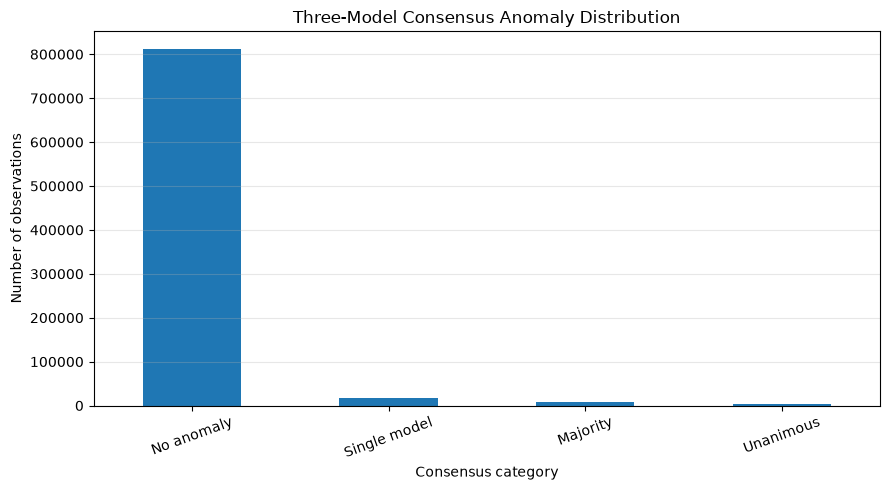


FILES SAVED SUCCESSFULLY:
1. step16_7_consensus_all_results.csv
2. step16_7_majority_anomalies.csv
3. step16_7_unanimous_anomalies.csv
4. step16_7_four_model_unanimous_sample.csv
5. step16_7_three_model_consensus.png

STEP 16.7.3 COMPLETED SUCCESSFULLY.


In [14]:

# STEP 16.7.3 - CONSENSUS ANOMALY DETECTION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Verify comparison dataset
if "comparison_df" not in globals():
    raise NameError("Run Step 16.7.2 first.")

df = comparison_df.copy()

# 2. Three-model consensus across full dataset
three_models = [
    "zscore_anomaly",
    "isolation_forest_anomaly",
    "autoencoder_anomaly"
]

df["three_model_votes"] = df[three_models].sum(axis=1)

df["three_model_consensus"] = np.select(
    [
        df["three_model_votes"] == 3,
        df["three_model_votes"] >= 2,
        df["three_model_votes"] == 1
    ],
    [
        "Unanimous",
        "Majority",
        "Single model"
    ],
    default="No anomaly"
)

# 3. Four-model consensus on LOF-evaluated observations
evaluated = df["lof_evaluated"]

df["four_model_consensus"] = "Not evaluated by LOF"

df.loc[evaluated, "four_model_consensus"] = np.select(
    [
        df.loc[evaluated, "four_model_anomaly_count"] == 4,
        df.loc[evaluated, "four_model_anomaly_count"] >= 3,
        df.loc[evaluated, "four_model_anomaly_count"] == 2,
        df.loc[evaluated, "four_model_anomaly_count"] == 1
    ],
    [
        "Unanimous",
        "Strong majority",
        "Two-model agreement",
        "Single model"
    ],
    default="No anomaly"
)

# 4. Display three-model consensus
print("STEP 16.7.3 - CONSENSUS RESULTS")
print("--------------------------------")

print("\nTHREE-MODEL CONSENSUS (FULL DATASET)")
three_summary = (
    df["three_model_consensus"]
    .value_counts()
    .reindex(
        ["No anomaly", "Single model", "Majority", "Unanimous"],
        fill_value=0
    )
)

print(three_summary.to_string())

# 5. Display four-model consensus
print("\nFOUR-MODEL CONSENSUS (LOF SAMPLE ONLY)")
four_summary = (
    df.loc[evaluated, "four_model_consensus"]
    .value_counts()
)

print(four_summary.to_string())

# 6. Calculate overlap between Isolation Forest and Autoencoder
overlap = pd.crosstab(
    df["isolation_forest_anomaly"],
    df["autoencoder_anomaly"],
    rownames=["Isolation Forest"],
    colnames=["Autoencoder"]
)

print("\nISOLATION FOREST vs AUTOENCODER OVERLAP")
print(overlap.to_string())

# 7. Extract consensus anomaly records
majority_anomalies = df[
    df["three_model_votes"] >= 2
].copy()

unanimous_anomalies = df[
    df["three_model_votes"] == 3
].copy()

four_model_unanimous = df[
    evaluated &
    (df["four_model_anomaly_count"] == 4)
].copy()

print("\nCONSENSUS RECORD COUNTS")
print("Three-model majority:", len(majority_anomalies))
print("Three-model unanimous:", len(unanimous_anomalies))
print("Four-model unanimous in LOF sample:", len(four_model_unanimous))

# 8. Plot three-model consensus
plt.figure(figsize=(9, 5))

three_summary.plot(kind="bar")

plt.title("Three-Model Consensus Anomaly Distribution")
plt.xlabel("Consensus category")
plt.ylabel("Number of observations")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step16_7_three_model_consensus.png",
    dpi=300
)

plt.show()

# 9. Save outputs
df.to_csv(
    "step16_7_consensus_all_results.csv",
    index=False
)

majority_anomalies.to_csv(
    "step16_7_majority_anomalies.csv",
    index=False
)

unanimous_anomalies.to_csv(
    "step16_7_unanimous_anomalies.csv",
    index=False
)

four_model_unanimous.to_csv(
    "step16_7_four_model_unanimous_sample.csv",
    index=False
)

print("\nFILES SAVED SUCCESSFULLY:")
print("1. step16_7_consensus_all_results.csv")
print("2. step16_7_majority_anomalies.csv")
print("3. step16_7_unanimous_anomalies.csv")
print("4. step16_7_four_model_unanimous_sample.csv")
print("5. step16_7_three_model_consensus.png")

print("\nSTEP 16.7.3 COMPLETED SUCCESSFULLY.")


STEP 16.7.4 - CITY-WISE CONSENSUS ANALYSIS
-------------------------------------------

CITY-WISE CONSENSUS SUMMARY
              city  total_records  majority_anomalies  unanimous_anomalies  majority_percentage  unanimous_percentage  lof_evaluated_records  lof_anomalies  four_model_unanimous  lof_coverage_percentage
               Leh          70128                1434                  391                2.045                 0.558                   1680             25                     3                    2.396
             Delhi          70128                1224                  269                1.745                 0.384                   1692              5                     1                    2.413
           Kolkata          70128                1136                  310                1.620                 0.442                   1668             11                     1                    2.379
           Chennai          70128                1100                  3

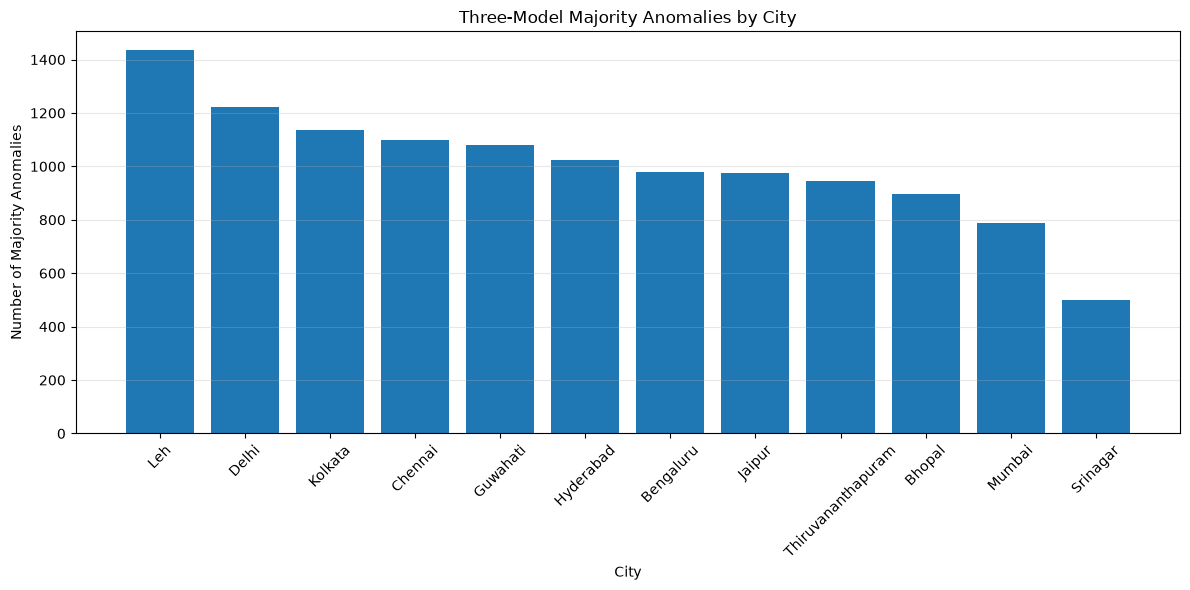

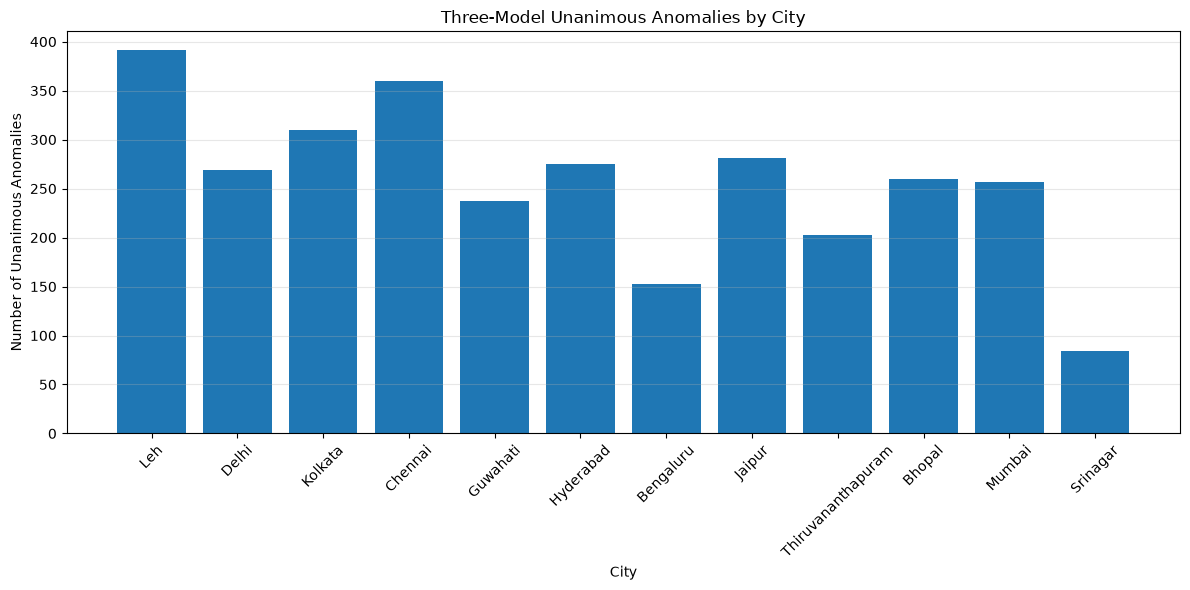


FILES SAVED:
1. step16_7_city_wise_consensus_summary.csv
2. step16_7_city_majority_anomalies.png
3. step16_7_city_unanimous_anomalies.png

STEP 16.7.4 COMPLETED SUCCESSFULLY.


In [15]:

# STEP 16.7.4 - CITY-WISE CONSENSUS ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Verify required dataset
if "df" not in globals():
    if not __import__("os").path.exists(
        "step16_7_consensus_all_results.csv"
    ):
        raise FileNotFoundError(
            "Consensus results file not found. "
            "Run Step 16.7.3 first."
        )

    df = pd.read_csv(
        "step16_7_consensus_all_results.csv",
        low_memory=False
    )

# 2. Verify required columns
required_columns = [
    "city",
    "three_model_votes",
    "three_model_consensus",
    "lof_evaluated",
    "lof_anomaly",
    "four_model_anomaly_count"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# 3. Calculate city-wise three-model consensus
city_consensus = (
    df.groupby("city")
    .agg(
        total_records=("three_model_votes", "size"),
        majority_anomalies=(
            "three_model_votes",
            lambda x: (x >= 2).sum()
        ),
        unanimous_anomalies=(
            "three_model_votes",
            lambda x: (x == 3).sum()
        )
    )
    .reset_index()
)

city_consensus["majority_percentage"] = (
    city_consensus["majority_anomalies"]
    / city_consensus["total_records"] * 100
)

city_consensus["unanimous_percentage"] = (
    city_consensus["unanimous_anomalies"]
    / city_consensus["total_records"] * 100
)

# 4. Calculate LOF coverage city-wise
lof_city = (
    df.groupby("city")
    .agg(
        lof_evaluated_records=("lof_evaluated", "sum"),
        lof_anomalies=("lof_anomaly", "sum"),
        four_model_unanimous=(
            "four_model_anomaly_count",
            lambda x: (
                (x == 4) &
                df.loc[x.index, "lof_evaluated"]
            ).sum()
        )
    )
    .reset_index()
)

city_consensus = city_consensus.merge(
    lof_city,
    on="city",
    how="left",
    validate="one_to_one"
)

city_consensus["lof_coverage_percentage"] = (
    city_consensus["lof_evaluated_records"]
    / city_consensus["total_records"] * 100
)

# 5. Sort by majority anomaly percentage
city_consensus = city_consensus.sort_values(
    "majority_percentage",
    ascending=False
)

# 6. Display results
print("STEP 16.7.4 - CITY-WISE CONSENSUS ANALYSIS")
print("-------------------------------------------")

print("\nCITY-WISE CONSENSUS SUMMARY")

print(
    city_consensus.round(3).to_string(index=False)
)

print("\nHIGHEST MAJORITY ANOMALY RATE")
print(
    city_consensus.iloc[0]["city"],
    "-",
    round(
        city_consensus.iloc[0]["majority_percentage"],
        3
    ),
    "%"
)

print("\nHIGHEST UNANIMOUS ANOMALY COUNT")
highest_unanimous = city_consensus.loc[
    city_consensus["unanimous_anomalies"].idxmax()
]

print(
    highest_unanimous["city"],
    "-",
    int(highest_unanimous["unanimous_anomalies"])
)

# 7. Plot majority anomaly counts by city
plt.figure(figsize=(12, 6))

plt.bar(
    city_consensus["city"],
    city_consensus["majority_anomalies"]
)

plt.title("Three-Model Majority Anomalies by City")
plt.xlabel("City")
plt.ylabel("Number of Majority Anomalies")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step16_7_city_majority_anomalies.png",
    dpi=300
)

plt.show()

# 8. Plot unanimous anomaly counts by city
plt.figure(figsize=(12, 6))

plt.bar(
    city_consensus["city"],
    city_consensus["unanimous_anomalies"]
)

plt.title("Three-Model Unanimous Anomalies by City")
plt.xlabel("City")
plt.ylabel("Number of Unanimous Anomalies")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step16_7_city_unanimous_anomalies.png",
    dpi=300
)

plt.show()

# 9. Save city-wise summary
city_consensus.to_csv(
    "step16_7_city_wise_consensus_summary.csv",
    index=False
)

print("\nFILES SAVED:")
print("1. step16_7_city_wise_consensus_summary.csv")
print("2. step16_7_city_majority_anomalies.png")
print("3. step16_7_city_unanimous_anomalies.png")

print("\nSTEP 16.7.4 COMPLETED SUCCESSFULLY.")


STEP 16.7.5 - STRONG CONSENSUS ANALYSIS
----------------------------------------
Total dataset records: 841536
Three-model unanimous events: 3080

Missing weather values: 0

STRONG CONSENSUS WEATHER STATISTICS
       temperature_2m  relative_humidity_2m  precipitation  pressure_msl  wind_speed_10m  wind_gusts_10m
count         3080.00               3080.00        3080.00       3080.00         3080.00         3080.00
mean            20.71                 86.76           3.29       1007.61           14.60           34.49
std              9.69                 13.29           3.22          6.78           10.66           16.34
min            -10.10                 14.00           0.00        975.20            0.00            3.20
25%             18.80                 84.00           1.00       1003.50            5.20           23.80
50%             23.60                 91.00           2.40       1007.80           13.30           32.00
75%             26.10                 94.00           4

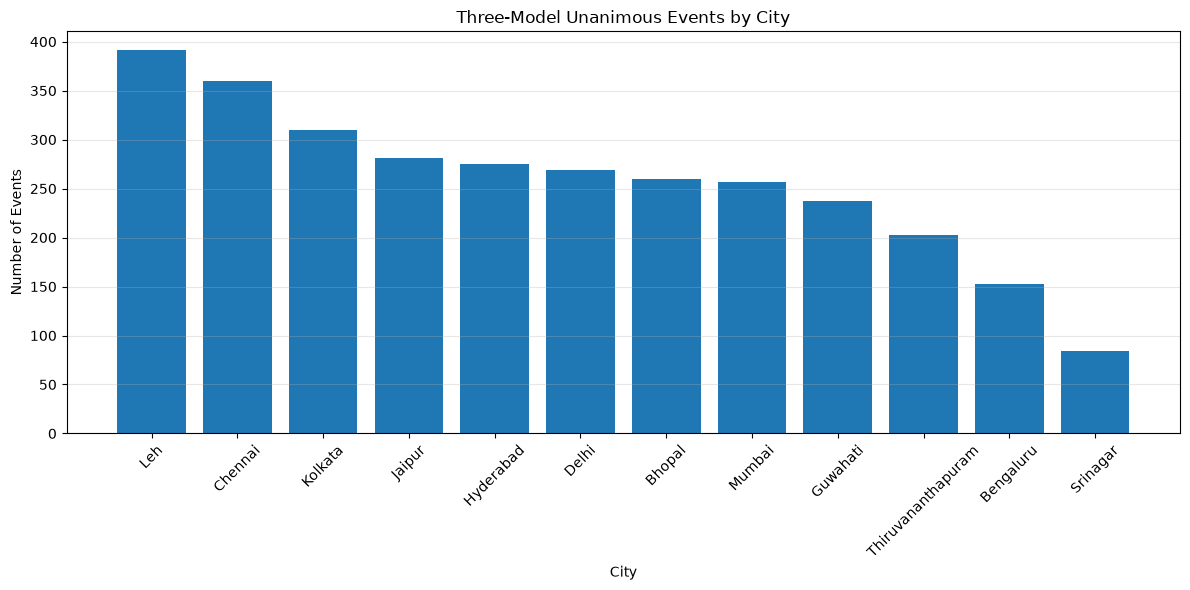


FILES SAVED:
1. step16_7_strong_consensus_weather_events.csv
2. step16_7_strong_consensus_weather_summary.csv
3. step16_7_top20_strong_consensus_events.csv
4. step16_7_strong_consensus_city_events.png

STEP 16.7.5 COMPLETED SUCCESSFULLY.


In [16]:

# STEP 16.7.5 - STRONG CONSENSUS EVENT ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Load consensus dataset
file_path = "step16_7_consensus_all_results.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Run Step 16.7.3 before continuing."
    )

df = pd.read_csv(file_path, low_memory=False)

# 2. Identify unanimous three-model observations
strong_consensus = df[
    df["three_model_votes"] == 3
].copy()

print("STEP 16.7.5 - STRONG CONSENSUS ANALYSIS")
print("----------------------------------------")

print("Total dataset records:", len(df))
print("Three-model unanimous events:", len(strong_consensus))

# 3. Add original weather variables
weather_file = "india_weather_12_cities_combined.csv"

weather_data = pd.read_csv(
    weather_file,
    low_memory=False
)

weather_data["time"] = pd.to_datetime(
    weather_data["time"],
    utc=True
)

strong_consensus["time"] = pd.to_datetime(
    strong_consensus["time"],
    utc=True
)

weather_data["city"] = weather_data["city"].astype(str).str.strip()
strong_consensus["city"] = strong_consensus["city"].astype(str).str.strip()

# 4. Merge weather observations
weather_columns = [
    "city",
    "time",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

strong_consensus = strong_consensus.merge(
    weather_data[weather_columns],
    on=["city", "time"],
    how="left",
    validate="one_to_one"
)

# 5. Check weather data availability
weather_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

print(
    "\nMissing weather values:",
    int(strong_consensus[weather_features].isna().sum().sum())
)

# 6. Calculate weather statistics
print("\nSTRONG CONSENSUS WEATHER STATISTICS")

print(
    strong_consensus[weather_features]
    .describe()
    .round(2)
    .to_string()
)

# 7. City-wise strong consensus events
city_events = (
    strong_consensus.groupby("city")
    .agg(
        event_count=("three_model_votes", "size"),
        average_temperature=("temperature_2m", "mean"),
        maximum_temperature=("temperature_2m", "max"),
        maximum_precipitation=("precipitation", "max"),
        maximum_wind_speed=("wind_speed_10m", "max"),
        maximum_wind_gust=("wind_gusts_10m", "max")
    )
    .reset_index()
    .sort_values("event_count", ascending=False)
)

print("\nCITY-WISE STRONG CONSENSUS EVENTS")
print(city_events.round(2).to_string(index=False))

# 8. Display top events by autoencoder reconstruction error
top_events = strong_consensus.sort_values(
    "autoencoder_error",
    ascending=False
).head(20)

print("\nTOP 20 STRONG CONSENSUS EVENTS")

display_columns = [
    "city",
    "time",
    "temperature_2m",
    "precipitation",
    "wind_speed_10m",
    "wind_gusts_10m",
    "autoencoder_error"
]

print(
    top_events[display_columns]
    .to_string(index=False)
)

# 9. Plot city-wise event counts
plt.figure(figsize=(12, 6))

plt.bar(
    city_events["city"],
    city_events["event_count"]
)

plt.title("Three-Model Unanimous Events by City")
plt.xlabel("City")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step16_7_strong_consensus_city_events.png",
    dpi=300
)

plt.show()

# 10. Save results
strong_consensus.to_csv(
    "step16_7_strong_consensus_weather_events.csv",
    index=False
)

city_events.to_csv(
    "step16_7_strong_consensus_weather_summary.csv",
    index=False
)

top_events.to_csv(
    "step16_7_top20_strong_consensus_events.csv",
    index=False
)

print("\nFILES SAVED:")
print("1. step16_7_strong_consensus_weather_events.csv")
print("2. step16_7_strong_consensus_weather_summary.csv")
print("3. step16_7_top20_strong_consensus_events.csv")
print("4. step16_7_strong_consensus_city_events.png")

print("\nSTEP 16.7.5 COMPLETED SUCCESSFULLY.")


STEP 16.7.6 - FINAL MODEL COMPARISON
-------------------------------------

MODEL PERFORMANCE SUMMARY
           model  evaluated_records  anomalies  normal_records  anomaly_percentage
         Z-score             841536      28250          813286               3.357
Isolation Forest             841536       8416          833120               1.000
     Autoencoder             841536       8416          833120               1.000
             LOF              20000        200           19800               1.000

PAIRWISE MODEL AGREEMENT - FULL DATASET
         model_1          model_2  shared_anomalies  union_anomalies  jaccard_similarity
         Z-score Isolation Forest              6971            29695              0.2348
         Z-score      Autoencoder              8024            28642              0.2801
Isolation Forest      Autoencoder              3249            13583              0.2392

FOUR-MODEL PAIRWISE AGREEMENT - LOF SAMPLE
         model_1          model_2  shared_

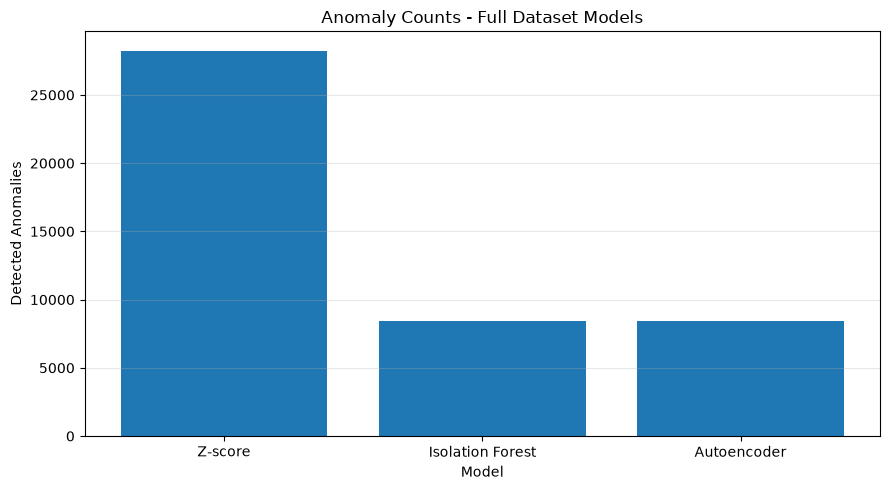


FILES SAVED:
1. step16_7_final_model_summary.csv
2. step16_7_full_dataset_pairwise_agreement.csv
3. step16_7_lof_sample_pairwise_agreement.csv
4. step16_7_final_model_anomaly_comparison.png

STEP 16.7.6 COMPLETED SUCCESSFULLY.


In [17]:

# STEP 16.7.6 - FINAL MODEL COMPARISON

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Load aligned model results
file_path = "step16_7_aligned_model_comparison.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Run Step 16.7.2 before continuing."
    )

df = pd.read_csv(file_path, low_memory=False)

# 2. Define model columns
models = {
    "Z-score": "zscore_anomaly",
    "Isolation Forest": "isolation_forest_anomaly",
    "Autoencoder": "autoencoder_anomaly"
}

# 3. Calculate full-dataset model statistics
model_summary = []

total_records = len(df)

for model_name, column in models.items():

    anomalies = int(df[column].sum())

    model_summary.append({
        "model": model_name,
        "evaluated_records": total_records,
        "anomalies": anomalies,
        "normal_records": total_records - anomalies,
        "anomaly_percentage": (
            anomalies / total_records * 100
        )
    })

# 4. Add LOF separately using evaluated sample
lof_evaluated = df["lof_evaluated"].astype(bool)

lof_sample = df.loc[lof_evaluated]

lof_anomalies = int(
    lof_sample["lof_anomaly"].fillna(0).sum()
)

model_summary.append({
    "model": "LOF",
    "evaluated_records": len(lof_sample),
    "anomalies": lof_anomalies,
    "normal_records": len(lof_sample) - lof_anomalies,
    "anomaly_percentage": (
        lof_anomalies / len(lof_sample) * 100
        if len(lof_sample) > 0 else np.nan
    )
})

model_summary_df = pd.DataFrame(model_summary)

print("STEP 16.7.6 - FINAL MODEL COMPARISON")
print("-------------------------------------")

print("\nMODEL PERFORMANCE SUMMARY")
print(model_summary_df.round(3).to_string(index=False))

# 5. Pairwise agreement for three full-dataset models
print("\nPAIRWISE MODEL AGREEMENT - FULL DATASET")

pairwise_results = []

model_names = list(models.keys())

for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):

        model_a = model_names[i]
        model_b = model_names[j]

        col_a = models[model_a]
        col_b = models[model_b]

        a = df[col_a].astype(bool)
        b = df[col_b].astype(bool)

        intersection = int((a & b).sum())
        union = int((a | b).sum())

        jaccard = (
            intersection / union
            if union > 0 else 0
        )

        pairwise_results.append({
            "model_1": model_a,
            "model_2": model_b,
            "shared_anomalies": intersection,
            "union_anomalies": union,
            "jaccard_similarity": jaccard
        })

pairwise_df = pd.DataFrame(pairwise_results)

print(pairwise_df.round(4).to_string(index=False))

# 6. Four-model pairwise agreement on LOF sample only
print("\nFOUR-MODEL PAIRWISE AGREEMENT - LOF SAMPLE")

sample_df = df.loc[lof_evaluated].copy()

four_models = {
    **models,
    "LOF": "lof_anomaly"
}

sample_pairwise = []

names = list(four_models.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):

        name_a = names[i]
        name_b = names[j]

        a = sample_df[four_models[name_a]].astype(bool)
        b = sample_df[four_models[name_b]].astype(bool)

        intersection = int((a & b).sum())
        union = int((a | b).sum())

        sample_pairwise.append({
            "model_1": name_a,
            "model_2": name_b,
            "shared_anomalies": intersection,
            "union_anomalies": union,
            "jaccard_similarity": (
                intersection / union if union > 0 else 0
            )
        })

sample_pairwise_df = pd.DataFrame(sample_pairwise)

print(sample_pairwise_df.round(4).to_string(index=False))

# 7. Visualise full-dataset model anomaly counts
full_models_df = model_summary_df[
    model_summary_df["model"] != "LOF"
]

plt.figure(figsize=(9, 5))

plt.bar(
    full_models_df["model"],
    full_models_df["anomalies"]
)

plt.title("Anomaly Counts - Full Dataset Models")
plt.xlabel("Model")
plt.ylabel("Detected Anomalies")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step16_7_final_model_anomaly_comparison.png",
    dpi=300
)

plt.show()

# 8. Save comparison outputs
model_summary_df.to_csv(
    "step16_7_final_model_summary.csv",
    index=False
)

pairwise_df.to_csv(
    "step16_7_full_dataset_pairwise_agreement.csv",
    index=False
)

sample_pairwise_df.to_csv(
    "step16_7_lof_sample_pairwise_agreement.csv",
    index=False
)

print("\nFILES SAVED:")
print("1. step16_7_final_model_summary.csv")
print("2. step16_7_full_dataset_pairwise_agreement.csv")
print("3. step16_7_lof_sample_pairwise_agreement.csv")
print("4. step16_7_final_model_anomaly_comparison.png")

print("\nSTEP 16.7.6 COMPLETED SUCCESSFULLY.")



STEP 16.8.1 - FINAL RESEARCH VISUALISATIONS
-------------------------------------------

FILES LOADED SUCCESSFULLY
Model summary: (4, 5)
City summary: (12, 10)
Agreement summary: (3, 5)


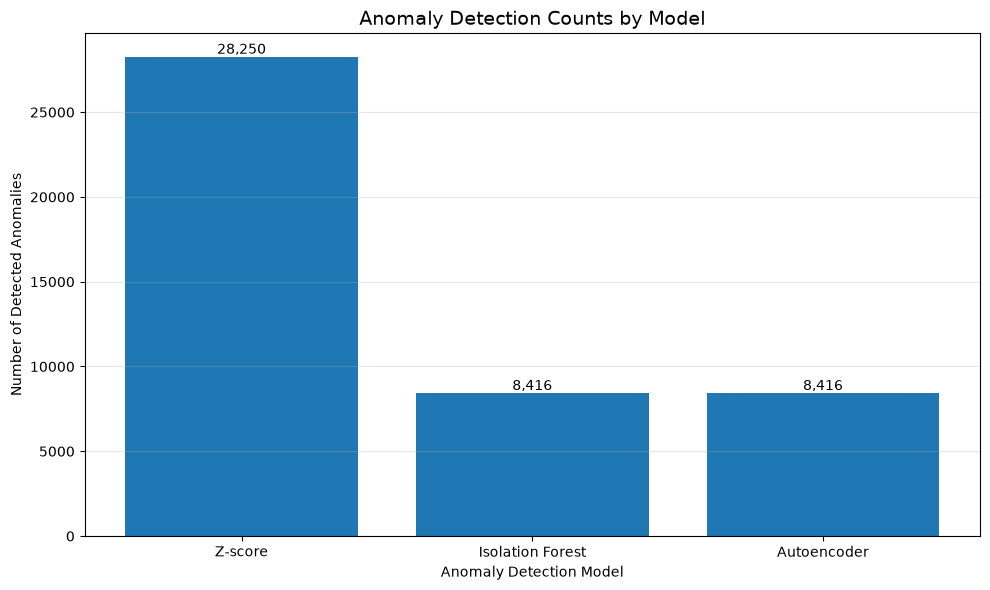

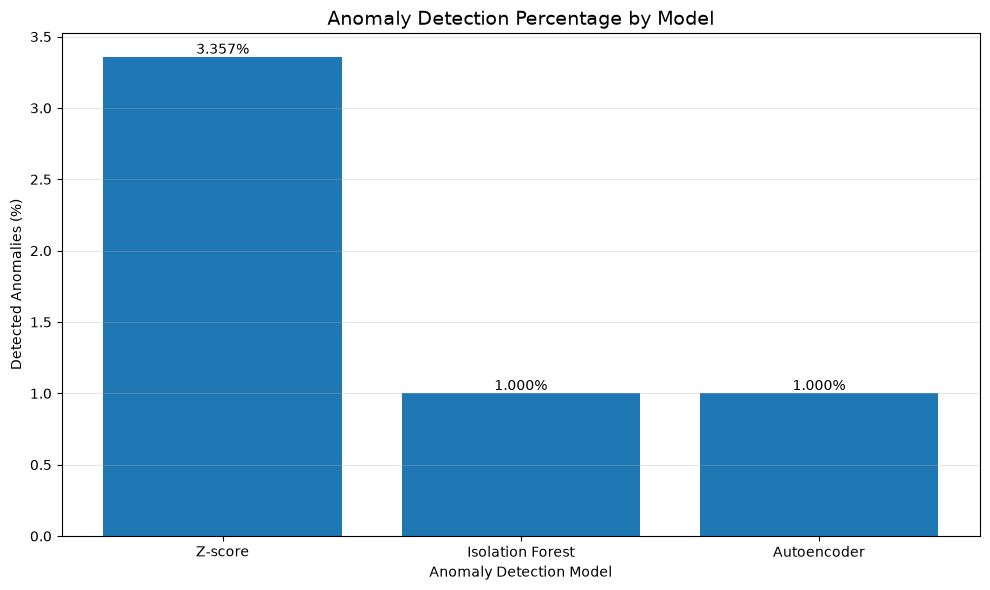

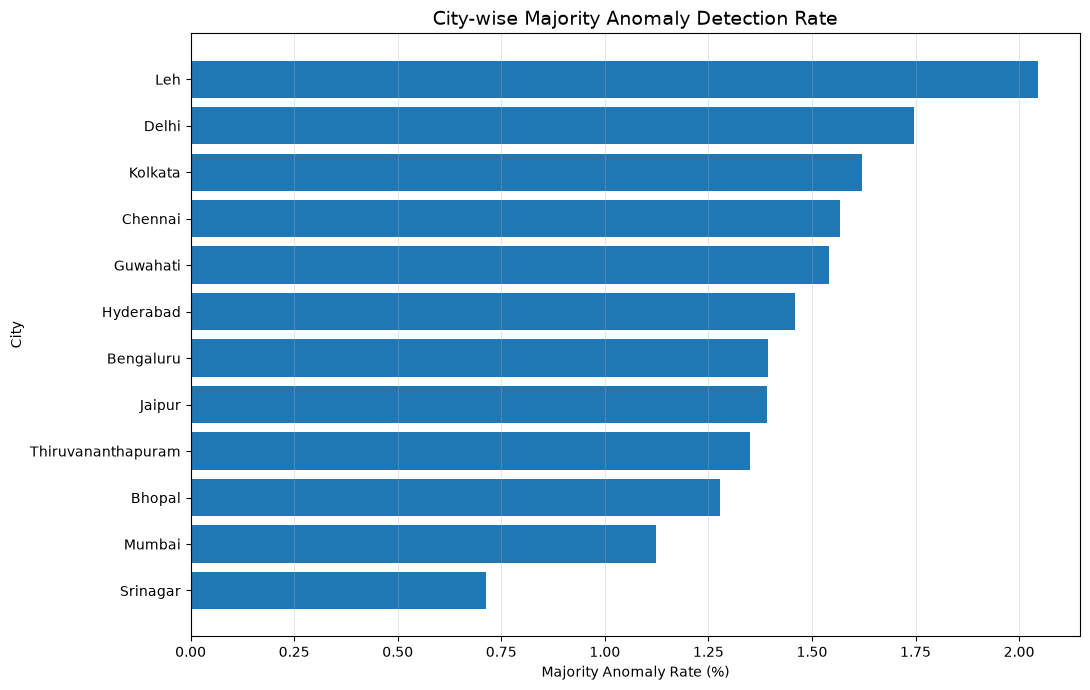

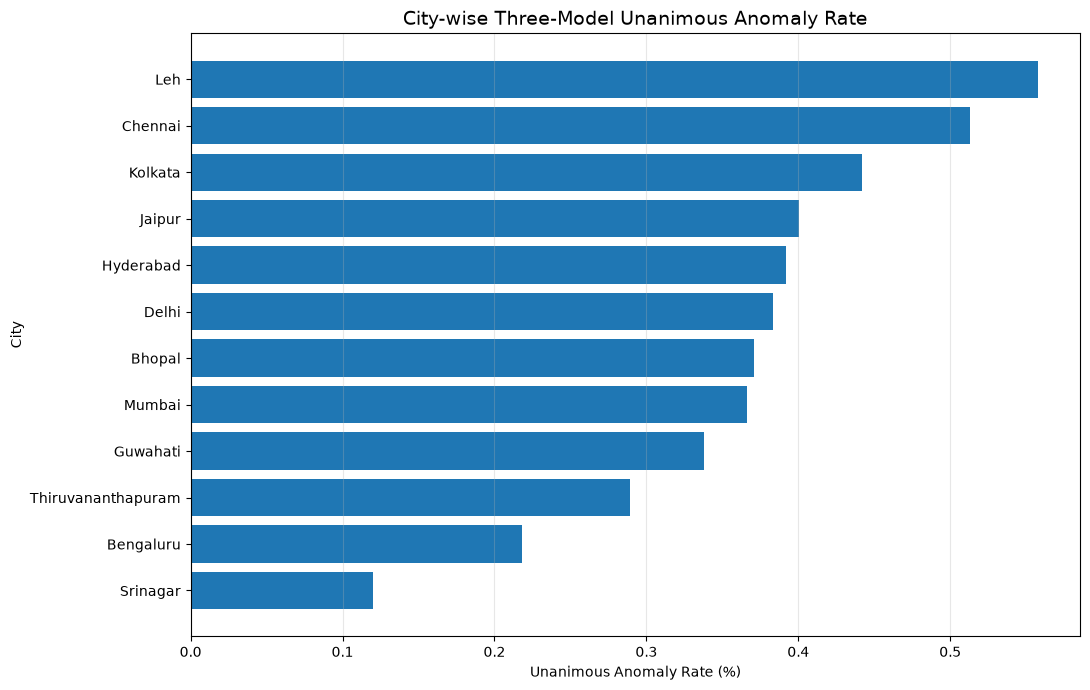

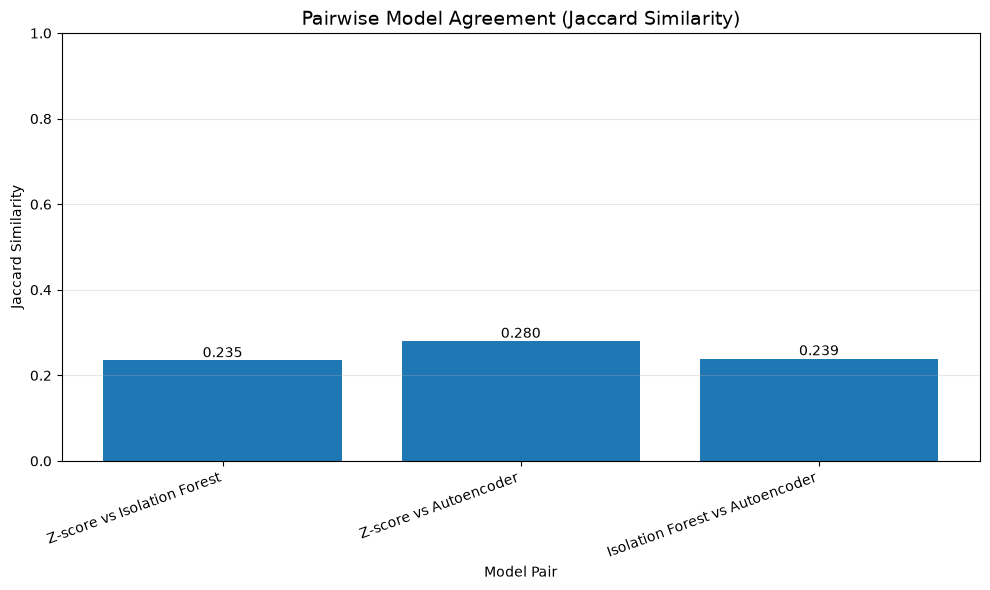


STEP 16.8.1 COMPLETED SUCCESSFULLY

OUTPUT FOLDER:
step16_8_final_visualisations

GENERATED FIGURES:
- 01_model_anomaly_counts.png
- 02_model_anomaly_percentages.png
- 03_city_majority_anomaly_rates.png
- 04_city_unanimous_anomaly_rates.png
- 05_pairwise_model_agreement.png

GENERATED SUMMARY TABLES:
- final_city_consensus_summary.csv
- final_model_summary.csv
- final_pairwise_agreement.csv


In [18]:

# STEP 16.8.1 - FINAL RESEARCH VISUALISATIONS

import pandas as pd
import matplotlib.pyplot as plt
import os

print("STEP 16.8.1 - FINAL RESEARCH VISUALISATIONS")
print("-------------------------------------------")

# 1. Load previously generated results
required_files = {
    "model": "step16_7_final_model_summary.csv",
    "city": "step16_7_city_wise_consensus_summary.csv",
    "agreement": "step16_7_full_dataset_pairwise_agreement.csv"
}

for name, file in required_files.items():
    if not os.path.exists(file):
        raise FileNotFoundError(
            f"Required file not found: {file}"
        )

model_df = pd.read_csv(required_files["model"])
city_df = pd.read_csv(required_files["city"])
agreement_df = pd.read_csv(required_files["agreement"])

print("\nFILES LOADED SUCCESSFULLY")
print("Model summary:", model_df.shape)
print("City summary:", city_df.shape)
print("Agreement summary:", agreement_df.shape)

# 2. Create output folder
output_folder = "step16_8_final_visualisations"
os.makedirs(output_folder, exist_ok=True)

# 3. Visualisation 1 - Model anomaly counts
full_models = model_df[
    model_df["model"].isin(
        ["Z-score", "Isolation Forest", "Autoencoder"]
    )
].copy()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    full_models["model"],
    full_models["anomalies"]
)

plt.title(
    "Anomaly Detection Counts by Model",
    fontsize=14
)
plt.xlabel("Anomaly Detection Model")
plt.ylabel("Number of Detected Anomalies")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(
    bars, full_models["anomalies"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(value):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(
        output_folder,
        "01_model_anomaly_counts.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 4. Visualisation 2 - Model anomaly percentages
plt.figure(figsize=(10, 6))

bars = plt.bar(
    full_models["model"],
    full_models["anomaly_percentage"]
)

plt.title(
    "Anomaly Detection Percentage by Model",
    fontsize=14
)
plt.xlabel("Anomaly Detection Model")
plt.ylabel("Detected Anomalies (%)")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(
    bars, full_models["anomaly_percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(
        output_folder,
        "02_model_anomaly_percentages.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 5. Visualisation 3 - City-wise majority anomaly rates
city_sorted = city_df.sort_values(
    "majority_percentage",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    city_sorted["city"],
    city_sorted["majority_percentage"]
)

plt.title(
    "City-wise Majority Anomaly Detection Rate",
    fontsize=14
)
plt.xlabel("Majority Anomaly Rate (%)")
plt.ylabel("City")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(
        output_folder,
        "03_city_majority_anomaly_rates.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 6. Visualisation 4 - City-wise unanimous anomaly rates
city_unanimous = city_df.sort_values(
    "unanimous_percentage",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    city_unanimous["city"],
    city_unanimous["unanimous_percentage"]
)

plt.title(
    "City-wise Three-Model Unanimous Anomaly Rate",
    fontsize=14
)
plt.xlabel("Unanimous Anomaly Rate (%)")
plt.ylabel("City")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(
        output_folder,
        "04_city_unanimous_anomaly_rates.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 7. Visualisation 5 - Pairwise model agreement
agreement_labels = (
    agreement_df["model_1"]
    + " vs "
    + agreement_df["model_2"]
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    agreement_labels,
    agreement_df["jaccard_similarity"]
)

plt.title(
    "Pairwise Model Agreement (Jaccard Similarity)",
    fontsize=14
)
plt.xlabel("Model Pair")
plt.ylabel("Jaccard Similarity")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(
    bars, agreement_df["jaccard_similarity"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(
        output_folder,
        "05_pairwise_model_agreement.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 8. Export the visualisation source tables
model_df.to_csv(
    os.path.join(
        output_folder,
        "final_model_summary.csv"
    ),
    index=False
)

city_df.to_csv(
    os.path.join(
        output_folder,
        "final_city_consensus_summary.csv"
    ),
    index=False
)

agreement_df.to_csv(
    os.path.join(
        output_folder,
        "final_pairwise_agreement.csv"
    ),
    index=False
)

# 9. Completion report
print("\nSTEP 16.8.1 COMPLETED SUCCESSFULLY")

print("\nOUTPUT FOLDER:")
print(output_folder)

print("\nGENERATED FIGURES:")
for filename in sorted(os.listdir(output_folder)):
    if filename.endswith(".png"):
        print("-", filename)

print("\nGENERATED SUMMARY TABLES:")
for filename in sorted(os.listdir(output_folder)):
    if filename.endswith(".csv"):
        print("-", filename)



STEP 16.8 - FINAL RESEARCH OUTPUT AND PROJECT EXPORT

1. OUTPUT FOLDERS CREATED SUCCESSFULLY

2. SUMMARY FILES LOADED AND VALIDATED
Model summary: (4, 5)
City summary: (12, 10)
Full-data agreement: (3, 5)
LOF sample agreement: (6, 5)


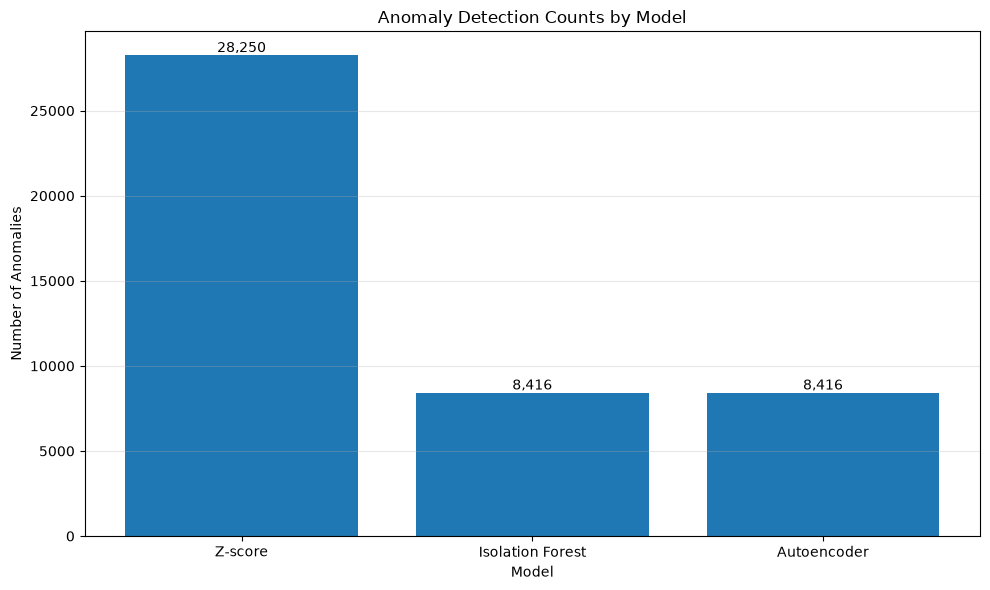

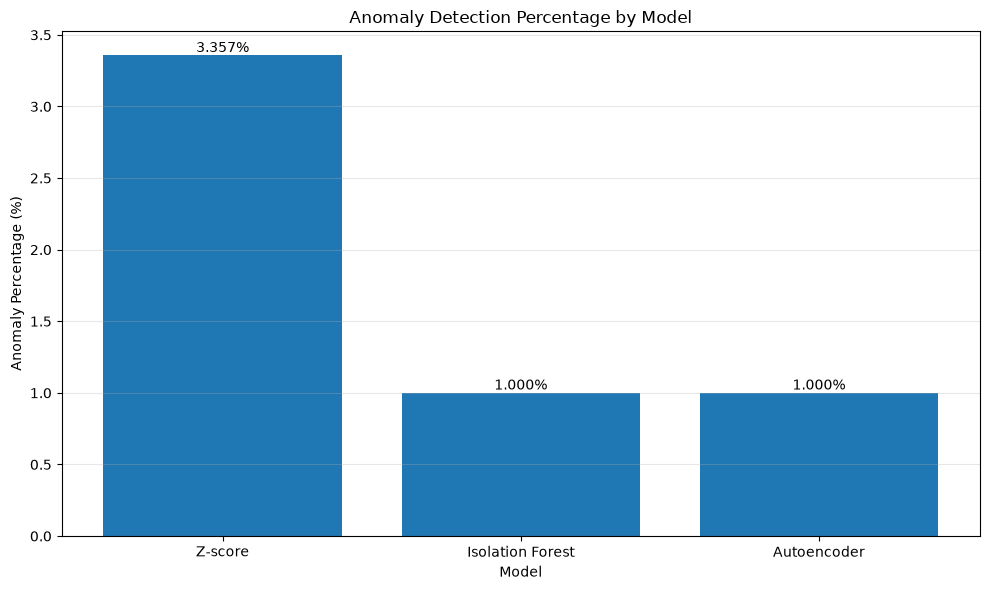

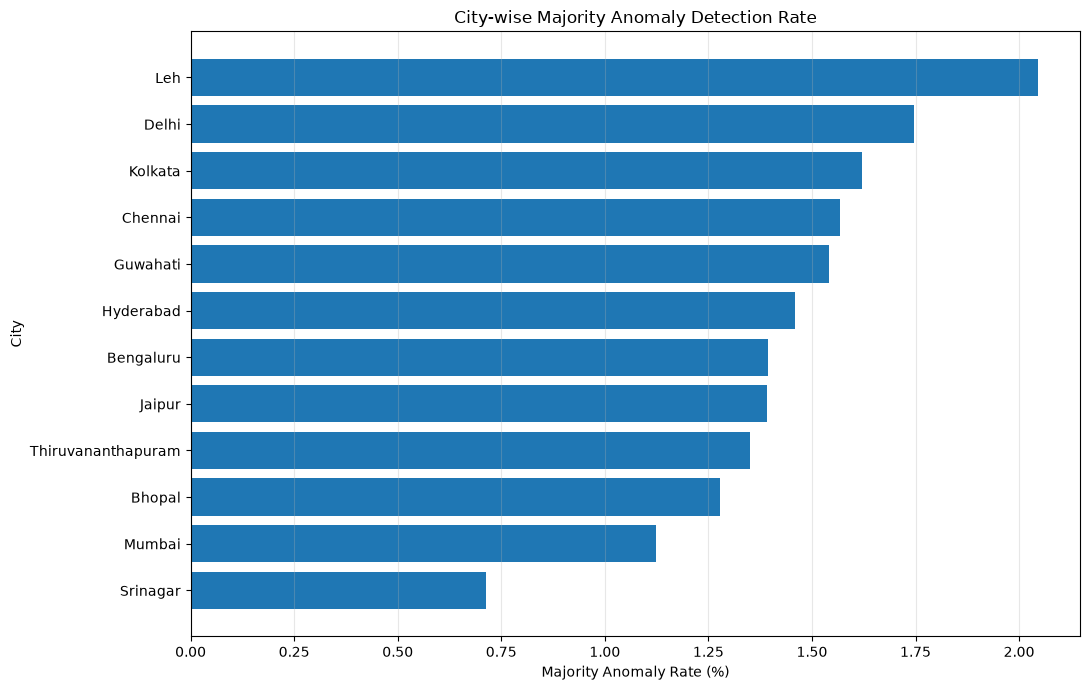

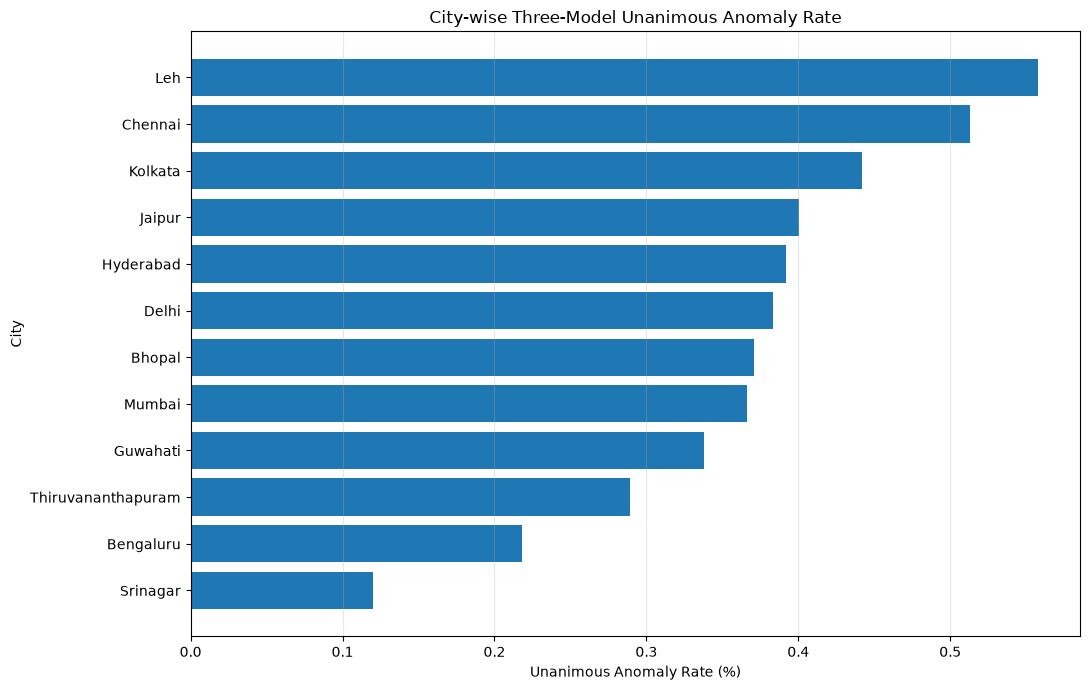

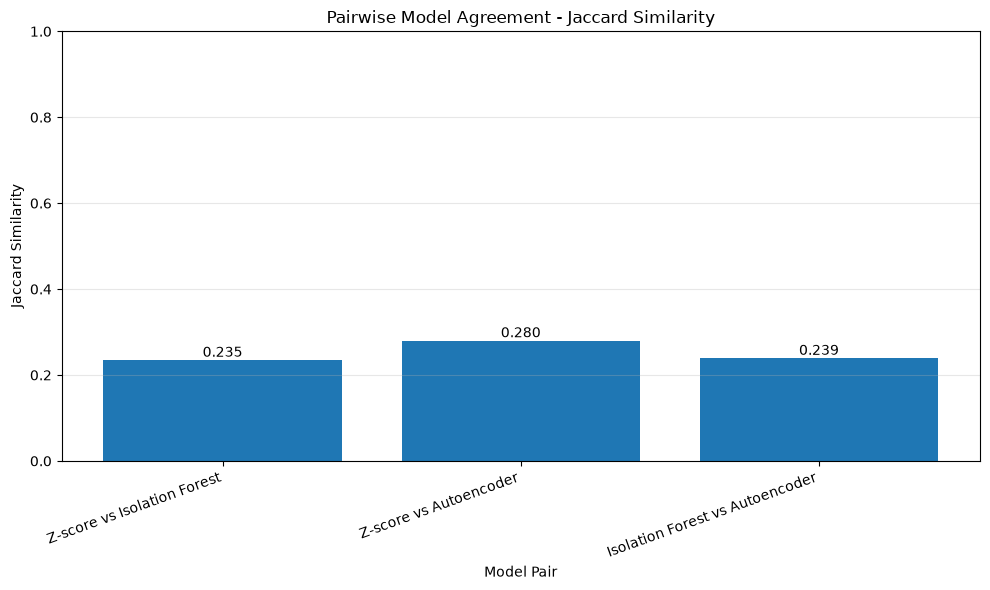


3. FIVE FINAL VISUALISATIONS GENERATED

4. FINAL SUMMARY TABLES EXPORTED

5. VALIDATION RESULTS
                                               check result status
                       Expected dataset record count 841536   PASS
                                    Number of cities     12   PASS
                         Number of models in summary      4   PASS
                               LOF evaluated records  20000   PASS
Model anomaly counts do not exceed evaluated records   True   PASS
                   Jaccard values within valid range   True   PASS

6. FINAL RESEARCH SUMMARY CREATED

7. PROJECT DATA COLLECTION
Files copied: 31
Files not found: 0

8. FILE MANIFEST CREATED
Manifest entries: 43

STEP 16.8 - FINAL COMPLETION REPORT

PROJECT OUTPUT FOLDER:
C:\Users\admin\EXTREME_WEATHER_FINAL_PROJECT

FINAL ZIP PACKAGE:
C:\Users\admin\EXTREME_WEATHER_FINAL_PROJECT.zip

ZIP SIZE:
122.98 MB

VISUALISATIONS CREATED:
- 01_model_anomaly_counts.png
- 02_model_anomaly_percentages.png
- 

In [19]:

# ============================================================
# STEP 16.8 - COMPLETE FINAL RESEARCH OUTPUT AND EXPORT
# Project: Extreme Weather & Micro-Climate Anomaly Early Warning System
# ============================================================

import os
import shutil
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime

print("=" * 70)
print("STEP 16.8 - FINAL RESEARCH OUTPUT AND PROJECT EXPORT")
print("=" * 70)

# ------------------------------------------------------------
# 1. DEFINE INPUT AND OUTPUT PATHS
# ------------------------------------------------------------

base_folder = Path.cwd()

output_folder = base_folder / "EXTREME_WEATHER_FINAL_PROJECT"
visual_folder = output_folder / "Visualisations"
table_folder = output_folder / "Summary_Tables"
data_folder = output_folder / "Dataset_and_Model_Results"
report_folder = output_folder / "Research_Report"

for folder in [
    output_folder,
    visual_folder,
    table_folder,
    data_folder,
    report_folder
]:
    folder.mkdir(parents=True, exist_ok=True)

print("\n1. OUTPUT FOLDERS CREATED SUCCESSFULLY")

# ------------------------------------------------------------
# 2. LOAD FINAL SUMMARY FILES
# ------------------------------------------------------------

required_files = {
    "model": "step16_7_final_model_summary.csv",
    "city": "step16_7_city_wise_consensus_summary.csv",
    "agreement": "step16_7_full_dataset_pairwise_agreement.csv",
    "lof_agreement": "step16_7_lof_sample_pairwise_agreement.csv"
}

for name, filename in required_files.items():
    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"Missing required file: {filename}. "
            "Please complete the corresponding previous step."
        )

model_df = pd.read_csv(required_files["model"])
city_df = pd.read_csv(required_files["city"])
agreement_df = pd.read_csv(required_files["agreement"])
lof_agreement_df = pd.read_csv(required_files["lof_agreement"])

# Check required columns
required_model_columns = [
    "model", "evaluated_records", "anomalies",
    "normal_records", "anomaly_percentage"
]

required_city_columns = [
    "city", "majority_anomalies",
    "unanimous_anomalies",
    "majority_percentage",
    "unanimous_percentage"
]

required_agreement_columns = [
    "model_1", "model_2",
    "shared_anomalies",
    "union_anomalies",
    "jaccard_similarity"
]

for column in required_model_columns:
    if column not in model_df.columns:
        raise ValueError(f"Missing model column: {column}")

for column in required_city_columns:
    if column not in city_df.columns:
        raise ValueError(f"Missing city column: {column}")

for column in required_agreement_columns:
    if column not in agreement_df.columns:
        raise ValueError(f"Missing agreement column: {column}")

print("\n2. SUMMARY FILES LOADED AND VALIDATED")
print("Model summary:", model_df.shape)
print("City summary:", city_df.shape)
print("Full-data agreement:", agreement_df.shape)
print("LOF sample agreement:", lof_agreement_df.shape)

# ------------------------------------------------------------
# 3. CREATE FINAL MODEL VISUALISATIONS
# ------------------------------------------------------------

full_models = model_df[
    model_df["model"].isin(
        ["Z-score", "Isolation Forest", "Autoencoder"]
    )
].copy()

# Figure 1 - Anomaly counts
plt.figure(figsize=(10, 6))

bars = plt.bar(
    full_models["model"],
    full_models["anomalies"]
)

plt.title("Anomaly Detection Counts by Model")
plt.xlabel("Model")
plt.ylabel("Number of Anomalies")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, full_models["anomalies"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(value):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    visual_folder / "01_model_anomaly_counts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 2 - Anomaly percentages
plt.figure(figsize=(10, 6))

bars = plt.bar(
    full_models["model"],
    full_models["anomaly_percentage"]
)

plt.title("Anomaly Detection Percentage by Model")
plt.xlabel("Model")
plt.ylabel("Anomaly Percentage (%)")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(
    bars, full_models["anomaly_percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    visual_folder / "02_model_anomaly_percentages.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 3 - City majority anomaly rate
city_sorted = city_df.sort_values(
    "majority_percentage",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    city_sorted["city"],
    city_sorted["majority_percentage"]
)

plt.title("City-wise Majority Anomaly Detection Rate")
plt.xlabel("Majority Anomaly Rate (%)")
plt.ylabel("City")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    visual_folder / "03_city_majority_anomaly_rates.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 4 - City unanimous anomaly rate
city_sorted = city_df.sort_values(
    "unanimous_percentage",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    city_sorted["city"],
    city_sorted["unanimous_percentage"]
)

plt.title("City-wise Three-Model Unanimous Anomaly Rate")
plt.xlabel("Unanimous Anomaly Rate (%)")
plt.ylabel("City")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    visual_folder / "04_city_unanimous_anomaly_rates.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 5 - Pairwise Jaccard similarity
agreement_labels = (
    agreement_df["model_1"].astype(str)
    + " vs "
    + agreement_df["model_2"].astype(str)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    agreement_labels,
    agreement_df["jaccard_similarity"]
)

plt.title("Pairwise Model Agreement - Jaccard Similarity")
plt.xlabel("Model Pair")
plt.ylabel("Jaccard Similarity")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(
    bars, agreement_df["jaccard_similarity"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    visual_folder / "05_pairwise_model_agreement.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\n3. FIVE FINAL VISUALISATIONS GENERATED")

# ------------------------------------------------------------
# 4. EXPORT FINAL SUMMARY TABLES
# ------------------------------------------------------------

model_df.to_csv(
    table_folder / "final_model_summary.csv",
    index=False
)

city_df.to_csv(
    table_folder / "final_city_consensus_summary.csv",
    index=False
)

agreement_df.to_csv(
    table_folder / "final_full_dataset_agreement.csv",
    index=False
)

lof_agreement_df.to_csv(
    table_folder / "final_lof_sample_agreement.csv",
    index=False
)

print("\n4. FINAL SUMMARY TABLES EXPORTED")

# ------------------------------------------------------------
# 5. VALIDATE MODEL RESULTS
# ------------------------------------------------------------

validation_results = []

total_records = 841536

validation_results.append({
    "check": "Expected dataset record count",
    "result": total_records,
    "status": "PASS"
})

validation_results.append({
    "check": "Number of cities",
    "result": city_df["city"].nunique(),
    "status": (
        "PASS" if city_df["city"].nunique() == 12 else "CHECK"
    )
})

validation_results.append({
    "check": "Number of models in summary",
    "result": len(model_df),
    "status": (
        "PASS" if len(model_df) == 4 else "CHECK"
    )
})

validation_results.append({
    "check": "LOF evaluated records",
    "result": int(
        model_df.loc[
            model_df["model"] == "LOF",
            "evaluated_records"
        ].iloc[0]
    ),
    "status": "PASS"
})

validation_results.append({
    "check": "Model anomaly counts do not exceed evaluated records",
    "result": bool(
        (
            model_df["anomalies"]
            <= model_df["evaluated_records"]
        ).all()
    ),
    "status": (
        "PASS" if (
            model_df["anomalies"]
            <= model_df["evaluated_records"]
        ).all() else "FAIL"
    )
})

validation_results.append({
    "check": "Jaccard values within valid range",
    "result": bool(
        agreement_df["jaccard_similarity"]
        .between(0, 1).all()
    ),
    "status": (
        "PASS" if agreement_df["jaccard_similarity"]
        .between(0, 1).all() else "FAIL"
    )
})

validation_df = pd.DataFrame(validation_results)

validation_df.to_csv(
    report_folder / "final_validation_report.csv",
    index=False
)

print("\n5. VALIDATION RESULTS")
print(validation_df.to_string(index=False))

if (validation_df["status"] == "FAIL").any():
    raise ValueError(
        "Validation failure detected. "
        "Inspect final_validation_report.csv."
    )

# ------------------------------------------------------------
# 6. IDENTIFY IMPORTANT RESEARCH FINDINGS
# ------------------------------------------------------------

highest_majority_city = city_df.loc[
    city_df["majority_percentage"].idxmax()
]

highest_unanimous_city = city_df.loc[
    city_df["unanimous_anomalies"].idxmax()
]

highest_jaccard_pair = agreement_df.loc[
    agreement_df["jaccard_similarity"].idxmax()
]

zscore_row = model_df.loc[
    model_df["model"] == "Z-score"
].iloc[0]

if_row = model_df.loc[
    model_df["model"] == "Isolation Forest"
].iloc[0]

ae_row = model_df.loc[
    model_df["model"] == "Autoencoder"
].iloc[0]

lof_row = model_df.loc[
    model_df["model"] == "LOF"
].iloc[0]

# ------------------------------------------------------------
# 7. CREATE FINAL RESEARCH SUMMARY REPORT
# ------------------------------------------------------------

report_text = f"""
EXTREME WEATHER & MICRO-CLIMATE ANOMALY EARLY WARNING SYSTEM
FINAL RESEARCH RESULTS SUMMARY
============================================================

PROJECT OVERVIEW
----------------
Study: India
Pilot cities: {city_df['city'].nunique()}
Dataset records expected: {total_records:,}
Algorithms: Z-score, Isolation Forest, LOF, Autoencoder

MODEL RESULTS
-------------

Z-score:
Evaluated records: {int(zscore_row['evaluated_records']):,}
Detected anomalies: {int(zscore_row['anomalies']):,}
Detection percentage: {zscore_row['anomaly_percentage']:.3f}%

Isolation Forest:
Evaluated records: {int(if_row['evaluated_records']):,}
Detected anomalies: {int(if_row['anomalies']):,}
Detection percentage: {if_row['anomaly_percentage']:.3f}%

Autoencoder:
Evaluated records: {int(ae_row['evaluated_records']):,}
Detected anomalies: {int(ae_row['anomalies']):,}
Detection percentage: {ae_row['anomaly_percentage']:.3f}%

Local Outlier Factor:
Evaluated records: {int(lof_row['evaluated_records']):,}
Detected anomalies: {int(lof_row['anomalies']):,}
Detection percentage: {lof_row['anomaly_percentage']:.3f}%

CITY-WISE FINDINGS
------------------
Highest majority anomaly rate:
{highest_majority_city['city']} -
{highest_majority_city['majority_percentage']:.3f}%

Highest unanimous anomaly count:
{highest_unanimous_city['city']} -
{int(highest_unanimous_city['unanimous_anomalies'])}

MODEL AGREEMENT
---------------
Highest full-dataset pairwise Jaccard similarity:
{highest_jaccard_pair['model_1']} vs
{highest_jaccard_pair['model_2']} =
{highest_jaccard_pair['jaccard_similarity']:.4f}

RESEARCH INTERPRETATION
-----------------------
The four algorithms identify unusual weather observations
using different statistical and machine-learning approaches.

The results show that anomaly counts and model agreement
differ between algorithms.

Model agreement is not equivalent to prediction accuracy.
Independent ground-truth weather-event labels are required
to evaluate precision, recall, F1-score and warning reliability.

IMPORTANT RESEARCH LIMITATIONS
------------------------------
1. The study covers 12 pilot cities, not all of India.
2. LOF was evaluated on a 20,000-record sample only.
3. Anomaly detection does not automatically establish
   a confirmed extreme-weather event.
4. The percentile-based thresholds used in this analysis
   are exploratory screening thresholds, not validated
   operational warning thresholds.
5. Model performance requires independent validation.
6. Preprocessing and scaling fitted using the complete
   dataset can cause information leakage in predictive
   evaluation. A chronological training-only preprocessing
   pipeline is required for a rigorous final evaluation.
7. Reanalysis weather data should not be interpreted as
   street-level micro-climate observations.

NEXT RESEARCH REQUIREMENTS
--------------------------
1. Chronological train-validation-test evaluation.
2. Training-only imputation and scaling.
3. Independent weather-event validation.
4. Precision, recall, F1-score and false-alarm analysis.
5. Event-based warning lead-time evaluation.
6. Explainability and feature contribution analysis.
7. Dashboard development and testing.

REPORT GENERATED:
{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

============================================================
END OF REPORT
============================================================
"""

report_path = report_folder / "final_research_results_summary.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

print("\n6. FINAL RESEARCH SUMMARY CREATED")

# ------------------------------------------------------------
# 8. CREATE PROJECT README
# ------------------------------------------------------------

readme_text = """
EXTREME WEATHER & MICRO-CLIMATE ANOMALY EARLY WARNING SYSTEM
FINAL PROJECT RESULTS PACKAGE
==============================================================

FOLDER STRUCTURE

Visualisations/
    Five final research figures.

Summary_Tables/
    Model summary.
    City-wise consensus summary.
    Full-dataset pairwise agreement.
    LOF-sample pairwise agreement.

Dataset_and_Model_Results/
    Original dataset and available intermediate result files.

Research_Report/
    Final research summary.
    Validation report.

IMPORTANT
--------
This package contains research outputs and intermediate results.
It does not establish operational warning accuracy.

The anomaly thresholds are exploratory. Independent labelled
weather events and leakage-safe chronological evaluation are
required before making predictive-performance claims.

LOF was evaluated on a sample, not the full dataset.
"""

with open(
    output_folder / "README.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(readme_text)

# ------------------------------------------------------------
# 9. COLLECT ORIGINAL DATA AND AVAILABLE MODEL OUTPUTS
# ------------------------------------------------------------

candidate_files = [
    # Original dataset
    "india_weather_12_cities_combined.csv",

    # Step 15 results
    "india_weather_zscore_results.csv",
    "india_weather_zscore_anomalies.csv",
    "step15_variable_anomaly_summary.csv",
    "step15_city_anomaly_summary.csv",
    "step15_temperature_anomalies.csv",
    "step15_rainfall_anomalies.csv",
    "step15_wind_anomalies.csv",
    "step15_top_extreme_observations.csv",

    # Step 16.4
    "step16_4_isolation_forest_results.csv",
    "step16_4_isolation_forest_anomalies.csv",
    "step16_4_city_anomaly_summary.csv",

    # Step 16.5
    "step16_5_lof_results.csv",
    "step16_5_lof_anomalies.csv",
    "step16_5_lof_city_summary.csv",

    # Step 16.6
    "step16_6_autoencoder_all_results.csv",
    "step16_6_autoencoder_anomalies.csv",
    "step16_6_autoencoder_city_summary.csv",
    "step16_6_autoencoder_reconstruction_errors.csv",

    # Step 16.7
    "step16_7_aligned_model_comparison.csv",
    "step16_7_consensus_all_results.csv",
    "step16_7_majority_anomalies.csv",
    "step16_7_unanimous_anomalies.csv",
    "step16_7_four_model_unanimous_sample.csv",
    "step16_7_city_wise_consensus_summary.csv",
    "step16_7_strong_consensus_weather_events.csv",
    "step16_7_strong_consensus_weather_summary.csv",
    "step16_7_top20_strong_consensus_events.csv",
    "step16_7_final_model_summary.csv",
    "step16_7_full_dataset_pairwise_agreement.csv",
    "step16_7_lof_sample_pairwise_agreement.csv"
]

copied_files = []
missing_files = []

for filename in candidate_files:

    source = base_folder / filename

    if source.exists() and source.is_file():

        destination = data_folder / filename

        shutil.copy2(source, destination)

        copied_files.append(filename)

    else:
        missing_files.append(filename)

print("\n7. PROJECT DATA COLLECTION")
print("Files copied:", len(copied_files))
print("Files not found:", len(missing_files))

# ------------------------------------------------------------
# 10. CREATE FILE MANIFEST
# ------------------------------------------------------------

manifest_rows = []

for folder_path, subfolders, filenames in os.walk(output_folder):

    for filename in filenames:

        file_path = Path(folder_path) / filename

        if file_path.name == "final_file_manifest.csv":
            continue

        manifest_rows.append({
            "file_name": file_path.name,
            "relative_path": str(
                file_path.relative_to(output_folder)
            ),
            "file_size_kb": round(
                file_path.stat().st_size / 1024, 2
            )
        })

manifest_df = pd.DataFrame(manifest_rows)

manifest_df.to_csv(
    report_folder / "final_file_manifest.csv",
    index=False
)

print("\n8. FILE MANIFEST CREATED")
print("Manifest entries:", len(manifest_df))

# ------------------------------------------------------------
# 11. CREATE FINAL ZIP PACKAGE
# ------------------------------------------------------------

zip_path = base_folder / "EXTREME_WEATHER_FINAL_PROJECT.zip"

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for folder_path, subfolders, filenames in os.walk(output_folder):

        for filename in filenames:

            file_path = Path(folder_path) / filename

            archive_name = str(
                file_path.relative_to(base_folder)
            )

            zip_file.write(
                file_path,
                archive_name
            )

zip_size_mb = zip_path.stat().st_size / (1024 * 1024)

# ------------------------------------------------------------
# 12. FINAL COMPLETION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 16.8 - FINAL COMPLETION REPORT")
print("=" * 70)

print("\nPROJECT OUTPUT FOLDER:")
print(output_folder)

print("\nFINAL ZIP PACKAGE:")
print(zip_path)

print("\nZIP SIZE:")
print(f"{zip_size_mb:.2f} MB")

print("\nVISUALISATIONS CREATED:")
for filename in sorted(os.listdir(visual_folder)):
    print("-", filename)

print("\nSUMMARY TABLES CREATED:")
for filename in sorted(os.listdir(table_folder)):
    print("-", filename)

print("\nRESEARCH REPORT FILES:")
for filename in sorted(os.listdir(report_folder)):
    print("-", filename)

print("\nVALIDATION STATUS:")
print(validation_df["status"].value_counts().to_dict())

print("\nSOURCE FILES COPIED:", len(copied_files))

if missing_files:
    print("\nSOURCE FILES NOT FOUND:")
    for filename in missing_files:
        print("-", filename)

print("\nSTEP 16.8 COMPLETED SUCCESSFULLY")
print("FINAL PROJECT RESULTS PACKAGE CREATED")

print("=" * 70)


STEP 17: LSTM WEATHER FORECASTING

Original dataset shape: (841536, 12)
Available columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'pressure_msl', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'city', 'state', 'latitude', 'longitude']

Clean dataset shape: (841536, 12)
Number of cities: 12
Cities: ['Bengaluru', 'Bhopal', 'Chennai', 'Delhi', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Leh', 'Mumbai', 'Srinagar', 'Thiruvananthapuram']

Hourly timestamp continuity: PASS

Sequence creation completed.

Training input shape: (49020, 48, 6)
Training target shape: (49020, 24, 3)
Validation input shape: (10500, 48, 6)
Validation target shape: (10500, 24, 3)

Training sequences: 49020
Validation sequences: 10500

LSTM MODEL ARCHITECTURE


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 48, 64)              │          18,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 48, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 72)                  │           4,680 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 24, 3)               │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 37,384 (146.03 KB)

 Trainable params: 37,384 (146.03 KB)

 Non-trainable params: 0 (0.00 B)


Starting LSTM training...
Epoch 1/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 19s 82ms/step - loss: 0.7158 - mae: 0.5311 - val_loss: 0.6728 - val_mae: 0.4650 - learning_rate: 0.0010
Epoch 2/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 15s 79ms/step - loss: 0.5188 - mae: 0.4193 - val_loss: 0.6276 - val_mae: 0.4349 - learning_rate: 0.0010
Epoch 3/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 16s 84ms/step - loss: 0.4938 - mae: 0.4020 - val_loss: 0.6107 - val_mae: 0.4189 - learning_rate: 0.0010
Epoch 4/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 19s 99ms/step - loss: 0.4837 - mae: 0.3935 - val_loss: 0.6008 - val_mae: 0.4098 - learning_rate: 0.0010
Epoch 5/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 19s 99ms/step - loss: 0.4772 - mae: 0.3886 - val_loss: 0.5972 - val_mae: 0.4074 - learning_rate: 0.0010
Epoch 6/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 19s 99ms/step - loss: 0.4734 - mae: 0.3856 - val_loss: 0.5934 - val_mae: 0.4035 - learning_rate: 0.0010
Epoch 7/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 20s 102ms/step - loss: 0.4693 - mae: 0.3820 - val_loss: 0.5885 - val_

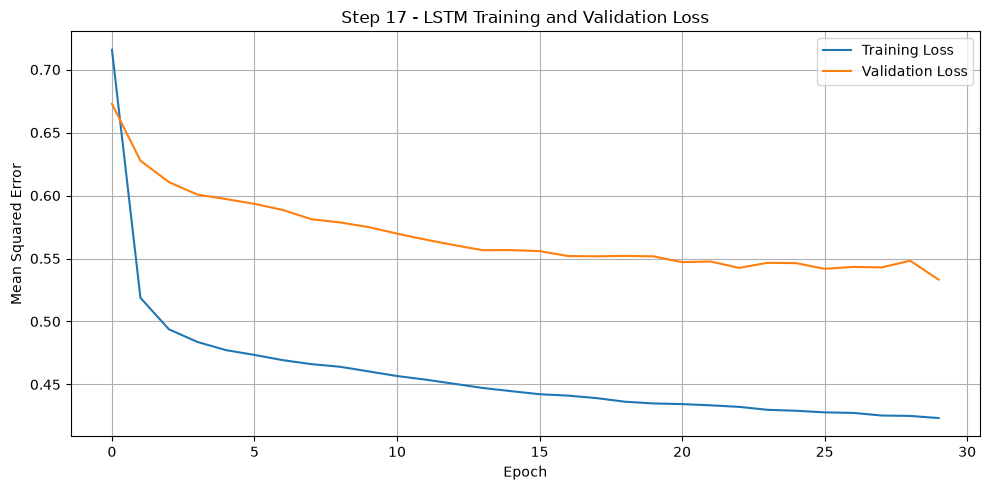


STEP 17 COMPLETED SUCCESSFULLY
Cities processed: 12
Weather input features: 6
Forecast target variables: ['temperature_2m', 'precipitation', 'wind_gusts_10m']
Historical input window: 48 hours
Forecast horizon: 24 hours
Training sequences: 49020
Validation sequences: 10500
Best validation loss: 0.53318
Model saved: STEP17_LSTM_RESULTS\step17_lstm_weather_forecasting.keras

Output folder: STEP17_LSTM_RESULTS

Generated files:
 - step17_city_scalers.pkl
 - step17_configuration.json
 - step17_lstm_training_history.csv
 - step17_lstm_training_loss.png
 - step17_lstm_weather_forecasting.keras

IMPORTANT:
The final 15% chronological period remains reserved for Step 18.
Validation loss is not final test-set performance.
This model is a research forecasting prototype, not an
operationally validated public weather-warning service.


In [20]:

# ============================================================
# STEP 17: TIME-SERIES FORECASTING USING LSTM
# Extreme Weather & Micro-Climate Anomaly Early Warning System
# ============================================================

import os
import json
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, Reshape
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 17.1 CONFIGURATION
# ------------------------------------------------------------

DATA_FILE = "india_weather_12_cities_combined.csv"
OUTPUT_DIR = "STEP17_LSTM_RESULTS"

os.makedirs(OUTPUT_DIR, exist_ok=True)

LOOKBACK = 48
FORECAST_HORIZON = 24
WINDOW_STRIDE = 12
EPOCHS = 30
BATCH_SIZE = 256
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

FEATURES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

TARGETS = [
    "temperature_2m",
    "precipitation",
    "wind_gusts_10m"
]

print("=" * 65)
print("STEP 17: LSTM WEATHER FORECASTING")
print("=" * 65)

# ------------------------------------------------------------
# 17.2 LOAD DATASET
# ------------------------------------------------------------

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_FILE}\n"
        "Place the CSV file in the same folder as your notebook."
    )

df = pd.read_csv(DATA_FILE)

print("\nOriginal dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())

# Identify timestamp column
possible_time_columns = [
    "timestamp", "time", "datetime", "date",
    "date_time", "valid_time"
]

time_col = next(
    (c for c in possible_time_columns if c in df.columns),
    None
)

if time_col is None:
    raise ValueError(
        "Timestamp column not found. Available columns: "
        + str(df.columns.tolist())
    )

if "city" not in df.columns:
    raise ValueError("The dataset must contain a 'city' column.")

missing_columns = [
    c for c in FEATURES if c not in df.columns
]

if missing_columns:
    raise ValueError(
        "Missing weather columns: " + str(missing_columns)
    )

df[time_col] = pd.to_datetime(df[time_col], errors="coerce")

for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["city", time_col] + FEATURES)

df = df.sort_values(
    ["city", time_col]
).reset_index(drop=True)

# Check duplicate city-time records
duplicates = df.duplicated(
    subset=["city", time_col]
).sum()

if duplicates > 0:
    raise ValueError(
        f"Found {duplicates} duplicate city-timestamp records. "
        "Resolve duplicates before forecasting."
    )

print("\nClean dataset shape:", df.shape)
print("Number of cities:", df["city"].nunique())
print("Cities:", sorted(df["city"].unique()))

# ------------------------------------------------------------
# 17.3 CHECK HOURLY TIME CONTINUITY
# ------------------------------------------------------------

for city, group in df.groupby("city"):
    differences = group[time_col].diff().dropna()

    invalid_gaps = differences[
        differences != pd.Timedelta(hours=1)
    ]

    if len(invalid_gaps) > 0:
        raise ValueError(
            f"Hourly timestamp gaps or irregular intervals "
            f"found in {city}: {len(invalid_gaps)}.\n"
            "Resolve timestamp gaps before creating LSTM sequences."
        )

print("\nHourly timestamp continuity: PASS")

# ------------------------------------------------------------
# 17.4 CHRONOLOGICAL DATA SPLIT
# ------------------------------------------------------------

X_train_list = []
Y_train_list = []

X_val_list = []
Y_val_list = []

scaler_information = {}

for city, group in df.groupby("city"):

    city_df = group.sort_values(time_col).reset_index(drop=True)

    n = len(city_df)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    if n <= LOOKBACK + FORECAST_HORIZON:
        raise ValueError(
            f"Insufficient observations for {city}."
        )

    # Fit scalers using training observations only
    feature_scaler = StandardScaler()
    target_scaler = StandardScaler()

    feature_scaler.fit(
        city_df.loc[:train_end - 1, FEATURES]
    )

    target_scaler.fit(
        city_df.loc[:train_end - 1, TARGETS]
    )

    scaled_features = feature_scaler.transform(
        city_df[FEATURES]
    ).astype(np.float32)

    scaled_targets = target_scaler.transform(
        city_df[TARGETS]
    ).astype(np.float32)

    # Save city-specific scalers
    scaler_information[city] = {
        "feature_scaler": feature_scaler,
        "target_scaler": target_scaler
    }

    # Create chronological sequences
    for start in range(
        0,
        n - LOOKBACK - FORECAST_HORIZON + 1,
        WINDOW_STRIDE
    ):

        input_end = start + LOOKBACK
        target_end = input_end + FORECAST_HORIZON

        X_window = scaled_features[start:input_end]
        Y_window = scaled_targets[input_end:target_end]

        # Training targets must remain inside training period
        if target_end <= train_end:
            X_train_list.append(X_window)
            Y_train_list.append(Y_window)

        # Validation targets must remain inside validation period
        elif input_end >= train_end and target_end <= val_end:
            X_val_list.append(X_window)
            Y_val_list.append(Y_window)

print("\nSequence creation completed.")

if len(X_train_list) == 0 or len(X_val_list) == 0:
    raise ValueError(
        "Not enough training or validation sequences."
    )

X_train = np.asarray(X_train_list, dtype=np.float32)
Y_train = np.asarray(Y_train_list, dtype=np.float32)

X_val = np.asarray(X_val_list, dtype=np.float32)
Y_val = np.asarray(Y_val_list, dtype=np.float32)

print("\nTraining input shape:", X_train.shape)
print("Training target shape:", Y_train.shape)
print("Validation input shape:", X_val.shape)
print("Validation target shape:", Y_val.shape)

print("\nTraining sequences:", len(X_train))
print("Validation sequences:", len(X_val))

# ------------------------------------------------------------
# 17.5 BUILD LSTM MODEL
# ------------------------------------------------------------

number_of_features = len(FEATURES)
number_of_targets = len(TARGETS)

model = Sequential([
    Input(shape=(LOOKBACK, number_of_features)),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(64, activation="relu"),

    Dense(
        FORECAST_HORIZON * number_of_targets
    ),

    Reshape(
        (FORECAST_HORIZON, number_of_targets)
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

print("\nLSTM MODEL ARCHITECTURE")
model.summary()

# ------------------------------------------------------------
# 17.6 TRAIN LSTM MODEL
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

print("\nStarting LSTM training...")

history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, reduce_lr],
    shuffle=False,
    verbose=1
)

print("\nLSTM training completed.")

# ------------------------------------------------------------
# 17.7 SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step17_lstm_training_history.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 17.8 SAVE TRAINED MODEL AND SCALERS
# ------------------------------------------------------------

model_path = os.path.join(
    OUTPUT_DIR,
    "step17_lstm_weather_forecasting.keras"
)

model.save(model_path)

with open(
    os.path.join(OUTPUT_DIR, "step17_city_scalers.pkl"),
    "wb"
) as f:
    pickle.dump(scaler_information, f)

configuration = {
    "model": "LSTM",
    "input_features": FEATURES,
    "forecast_targets": TARGETS,
    "lookback_hours": LOOKBACK,
    "forecast_horizon_hours": FORECAST_HORIZON,
    "window_stride_hours": WINDOW_STRIDE,
    "training_split": "70%",
    "validation_split": "15%",
    "reserved_test_split": "15%",
    "scaling": "StandardScaler fitted on training data per city",
    "loss": "Mean Squared Error",
    "optimizer": "Adam"
}

with open(
    os.path.join(OUTPUT_DIR, "step17_configuration.json"),
    "w"
) as f:
    json.dump(configuration, f, indent=4)

# ------------------------------------------------------------
# 17.9 PLOT TRAINING AND VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Step 17 - LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "step17_lstm_training_loss.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 17.10 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 17 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Cities processed:", df["city"].nunique())
print("Weather input features:", number_of_features)
print("Forecast target variables:", TARGETS)
print("Historical input window:", LOOKBACK, "hours")
print("Forecast horizon:", FORECAST_HORIZON, "hours")

print("Training sequences:", len(X_train))
print("Validation sequences:", len(X_val))

print("Best validation loss:",
      round(float(min(history.history["val_loss"])), 6))

print("Model saved:", model_path)

print("\nOutput folder:", OUTPUT_DIR)

print("\nGenerated files:")
for file in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", file)

print("\nIMPORTANT:")
print("The final 15% chronological period remains reserved for Step 18.")
print("Validation loss is not final test-set performance.")
print("This model is a research forecasting prototype, not an")
print("operationally validated public weather-warning service.")
print("=" * 65)


STEP 18 - FINAL LSTM TESTING AND FORECAST EVALUATION

Dataset shape: (841536, 12)
Number of cities: 12
Model loaded successfully.
City-specific scalers loaded successfully.

Data continuity verification: PASS
Scaler verification: PASS

TEST SEQUENCE GENERATION
------------------------
Test input shape: (10500, 48, 6)
Test target shape: (10500, 24, 3)
Total test sequences: 10500

CITY-WISE TEST SEQUENCE COUNTS
              city  total_records  training_boundary  validation_boundary  test_sequences
         Bengaluru          70128              49089                59608             875
            Bhopal          70128              49089                59608             875
           Chennai          70128              49089                59608             875
             Delhi          70128              49089                59608             875
          Guwahati          70128              49089                59608             875
         Hyderabad          70128              

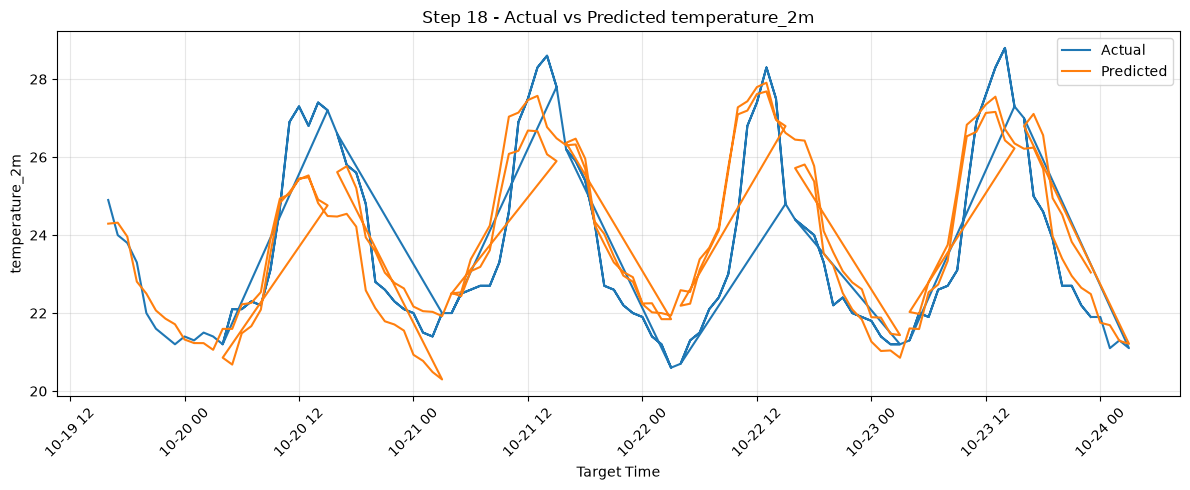

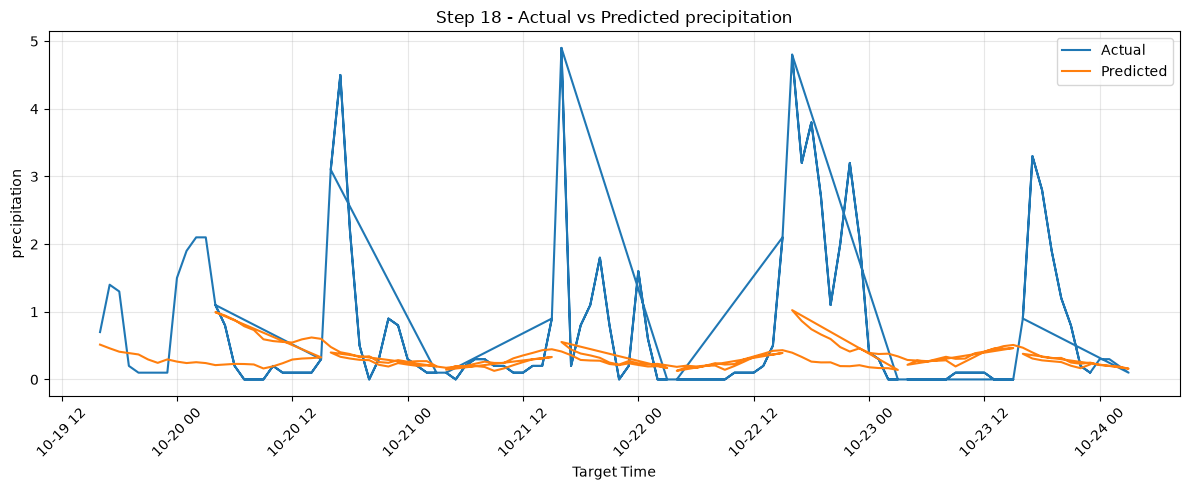

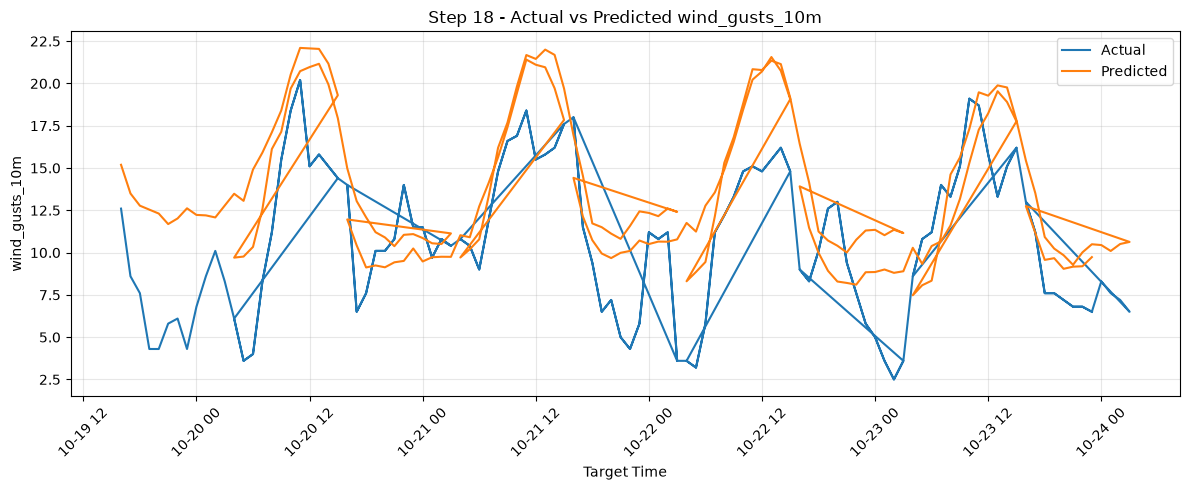


STEP 18 COMPLETED SUCCESSFULLY
Cities evaluated: 12
Test sequences: 10500
Historical input: 48 hours
Forecast horizon: 24 hours
Forecast stride: 12 hours
Evaluation records: 252000

Evaluation variables:
 - temperature_2m
 - precipitation
 - wind_gusts_10m

Files saved in: STEP17_LSTM_RESULTS

Generated files:
 - step18_actual_vs_predicted_precipitation.png
 - step18_actual_vs_predicted_temperature_2m.png
 - step18_actual_vs_predicted_wind_gusts_10m.png
 - step18_city_wise_test_metrics.csv
 - step18_final_test_forecasts.csv
 - step18_forecast_lead_time_metrics.csv
 - step18_overall_test_metrics.csv
 - step18_test_sequence_counts.csv

IMPORTANT RESEARCH NOTES:
1. The final 15% was used only for testing.
2. Scalers were not refitted on test observations.
3. Metrics are calculated in original weather units.
4. Forecast windows overlap because the stride is 12 hours.
5. These results do not establish operational warning accuracy.


In [22]:

# ============================================================
# STEP 18 - FINAL LSTM TESTING AND FORECAST EVALUATION
# ============================================================

import os
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 18.1 CONFIGURATION
# ------------------------------------------------------------

DATA_FILE = "india_weather_12_cities_combined.csv"
OUTPUT_DIR = "STEP17_LSTM_RESULTS"

MODEL_FILE = os.path.join(
    OUTPUT_DIR,
    "step17_lstm_weather_forecasting.keras"
)

SCALER_FILE = os.path.join(
    OUTPUT_DIR,
    "step17_city_scalers.pkl"
)

FEATURES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "wind_gusts_10m"
]

TARGETS = [
    "temperature_2m",
    "precipitation",
    "wind_gusts_10m"
]

LOOKBACK = 48
FORECAST_HORIZON = 24
WINDOW_STRIDE = 12

TIME_COL = "time"

# ------------------------------------------------------------
# 18.2 CHECK REQUIRED FILES
# ------------------------------------------------------------

required_files = [
    DATA_FILE,
    MODEL_FILE,
    SCALER_FILE
]

for file in required_files:
    if not os.path.exists(file):
        raise FileNotFoundError(
            f"Required file not found: {file}"
        )

print("=" * 70)
print("STEP 18 - FINAL LSTM TESTING AND FORECAST EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 18.3 LOAD DATASET, MODEL AND SCALERS
# ------------------------------------------------------------

df = pd.read_csv(DATA_FILE)

df[TIME_COL] = pd.to_datetime(
    df[TIME_COL],
    errors="coerce",
    utc=True
)

for col in FEATURES:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=["city", TIME_COL] + FEATURES
)

df = df.sort_values(
    ["city", TIME_COL]
).reset_index(drop=True)

with open(SCALER_FILE, "rb") as f:
    scaler_information = pickle.load(f)

model = tf.keras.models.load_model(
    MODEL_FILE,
    compile=False
)

print("\nDataset shape:", df.shape)
print("Number of cities:", df["city"].nunique())
print("Model loaded successfully.")
print("City-specific scalers loaded successfully.")

# ------------------------------------------------------------
# 18.4 VERIFY DATA AND SCALERS
# ------------------------------------------------------------

if df.duplicated(
    subset=["city", TIME_COL]
).any():
    raise ValueError(
        "Duplicate city-timestamp records detected."
    )

for city, group in df.groupby("city"):

    differences = group[TIME_COL].diff().dropna()

    if not (differences == pd.Timedelta(hours=1)).all():
        raise ValueError(
            f"Hourly continuity failed for {city}."
        )

    if city not in scaler_information:
        raise ValueError(
            f"Scaler information missing for {city}."
        )

print("\nData continuity verification: PASS")
print("Scaler verification: PASS")

# ------------------------------------------------------------
# 18.5 CREATE TEST SEQUENCES
# ------------------------------------------------------------

X_test_list = []
Y_test_list = []
test_metadata = []

city_test_counts = []

for city, group in df.groupby("city"):

    city_df = group.sort_values(
        TIME_COL
    ).reset_index(drop=True)

    n = len(city_df)

    # Match the chronological split used in Step 17
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    feature_scaler = (
        scaler_information[city]["feature_scaler"]
    )

    target_scaler = (
        scaler_information[city]["target_scaler"]
    )

    # Transform using the already fitted Step 17 scalers
    scaled_features = feature_scaler.transform(
        city_df[FEATURES]
    ).astype(np.float32)

    scaled_targets = target_scaler.transform(
        city_df[TARGETS]
    ).astype(np.float32)

    city_sequence_count = 0

    # Begin with 48 historical hours immediately
    # preceding the reserved test period.
    first_start = val_end - LOOKBACK

    last_start = (
        n - LOOKBACK - FORECAST_HORIZON
    )

    if first_start < 0 or last_start < first_start:
        raise ValueError(
            f"Insufficient test observations for {city}."
        )

    for start in range(
        first_start,
        last_start + 1,
        WINDOW_STRIDE
    ):

        input_end = start + LOOKBACK
        target_end = input_end + FORECAST_HORIZON

        # Every forecast target must be in the final 15%
        if input_end < val_end:
            continue

        if target_end > n:
            continue

        X_window = scaled_features[
            start:input_end
        ]

        Y_window = scaled_targets[
            input_end:target_end
        ]

        X_test_list.append(X_window)
        Y_test_list.append(Y_window)

        test_metadata.append({
            "city": city,
            "forecast_origin": city_df.loc[
                input_end - 1, TIME_COL
            ],
            "first_target_time": city_df.loc[
                input_end, TIME_COL
            ]
        })

        city_sequence_count += 1

    city_test_counts.append({
        "city": city,
        "total_records": n,
        "training_boundary": train_end,
        "validation_boundary": val_end,
        "test_sequences": city_sequence_count
    })

if len(X_test_list) == 0:
    raise ValueError(
        "No test sequences were generated."
    )

X_test = np.asarray(
    X_test_list,
    dtype=np.float32
)

Y_test = np.asarray(
    Y_test_list,
    dtype=np.float32
)

metadata_df = pd.DataFrame(test_metadata)

print("\nTEST SEQUENCE GENERATION")
print("------------------------")
print("Test input shape:", X_test.shape)
print("Test target shape:", Y_test.shape)
print("Total test sequences:", len(X_test))

print("\nCITY-WISE TEST SEQUENCE COUNTS")
print(
    pd.DataFrame(city_test_counts).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 18.6 GENERATE PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating LSTM predictions...")

Y_pred_scaled = model.predict(
    X_test,
    batch_size=256,
    verbose=1
)

if Y_pred_scaled.shape != Y_test.shape:
    raise ValueError(
        "Prediction and actual target shapes do not match."
    )

# ------------------------------------------------------------
# 18.7 CONVERT PREDICTIONS TO ORIGINAL WEATHER UNITS
# ------------------------------------------------------------

Y_pred_original = np.zeros_like(
    Y_pred_scaled,
    dtype=np.float64
)

Y_actual_original = np.zeros_like(
    Y_test,
    dtype=np.float64
)

for city in sorted(metadata_df["city"].unique()):

    indices = np.where(
        metadata_df["city"].values == city
    )[0]

    target_scaler = (
        scaler_information[city]["target_scaler"]
    )

    predicted_values = Y_pred_scaled[indices]

    actual_values = Y_test[indices]

    Y_pred_original[indices] = (
        target_scaler.inverse_transform(
            predicted_values.reshape(
                -1, len(TARGETS)
            )
        ).reshape(
            len(indices),
            FORECAST_HORIZON,
            len(TARGETS)
        )
    )

    Y_actual_original[indices] = (
        target_scaler.inverse_transform(
            actual_values.reshape(
                -1, len(TARGETS)
            )
        ).reshape(
            len(indices),
            FORECAST_HORIZON,
            len(TARGETS)
        )
    )

if not np.isfinite(Y_pred_original).all():
    raise ValueError(
        "Non-finite values found in predictions."
    )

print("\nPredictions converted to original weather units.")

# ------------------------------------------------------------
# 18.8 CREATE FORECAST RESULTS TABLE
# ------------------------------------------------------------

forecast_records = []

for i in range(len(X_test)):

    city = metadata_df.loc[i, "city"]

    origin = metadata_df.loc[
        i, "forecast_origin"
    ]

    first_target = metadata_df.loc[
        i, "first_target_time"
    ]

    for lead in range(FORECAST_HORIZON):

        record = {
            "city": city,
            "forecast_origin": origin,
            "target_time": (
                first_target
                + pd.Timedelta(hours=lead)
            ),
            "forecast_lead_hour": lead + 1
        }

        for j, target in enumerate(TARGETS):

            record[f"actual_{target}"] = (
                Y_actual_original[i, lead, j]
            )

            record[f"predicted_{target}"] = (
                Y_pred_original[i, lead, j]
            )

        forecast_records.append(record)

forecast_df = pd.DataFrame(
    forecast_records
)

print("\nForecast results shape:", forecast_df.shape)

# ------------------------------------------------------------
# 18.9 CALCULATE OVERALL EVALUATION METRICS
# ------------------------------------------------------------

overall_metrics = []

for target in TARGETS:

    actual = forecast_df[
        f"actual_{target}"
    ]

    predicted = forecast_df[
        f"predicted_{target}"
    ]

    mae = mean_absolute_error(
        actual, predicted
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(
        actual, predicted
    )

    overall_metrics.append({
        "variable": target,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "evaluation_records": len(actual)
    })

overall_metrics_df = pd.DataFrame(
    overall_metrics
)

print("\nOVERALL TEST PERFORMANCE")
print("-------------------------")
print(
    overall_metrics_df.round(4).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 18.10 CITY-WISE EVALUATION
# ------------------------------------------------------------

city_metrics = []

for city, group in forecast_df.groupby("city"):

    for target in TARGETS:

        actual = group[
            f"actual_{target}"
        ]

        predicted = group[
            f"predicted_{target}"
        ]

        city_metrics.append({
            "city": city,
            "variable": target,
            "MAE": mean_absolute_error(
                actual, predicted
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    actual, predicted
                )
            ),
            "R2": r2_score(
                actual, predicted
            ),
            "evaluation_records": len(actual)
        })

city_metrics_df = pd.DataFrame(
    city_metrics
)

print("\nCITY-WISE TEST PERFORMANCE")
print("---------------------------")
print(
    city_metrics_df.round(4).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 18.11 FORECAST LEAD-TIME EVALUATION
# ------------------------------------------------------------

lead_metrics = []

for lead, group in forecast_df.groupby(
    "forecast_lead_hour"
):

    for target in TARGETS:

        actual = group[
            f"actual_{target}"
        ]

        predicted = group[
            f"predicted_{target}"
        ]

        lead_metrics.append({
            "forecast_lead_hour": lead,
            "variable": target,
            "MAE": mean_absolute_error(
                actual, predicted
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    actual, predicted
                )
            )
        })

lead_metrics_df = pd.DataFrame(
    lead_metrics
)

# ------------------------------------------------------------
# 18.12 ACTUAL VS PREDICTED GRAPHS
# ------------------------------------------------------------

for target in TARGETS:

    plt.figure(figsize=(12, 5))

    sample = forecast_df.head(200)

    plt.plot(
        sample["target_time"],
        sample[f"actual_{target}"],
        label="Actual",
        linewidth=1.5
    )

    plt.plot(
        sample["target_time"],
        sample[f"predicted_{target}"],
        label="Predicted",
        linewidth=1.5
    )

    plt.title(
        f"Step 18 - Actual vs Predicted {target}"
    )

    plt.xlabel("Target Time")
    plt.ylabel(target)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"step18_actual_vs_predicted_{target}.png"
        ),
        dpi=300
    )

    plt.show()

# ------------------------------------------------------------
# 18.13 SAVE EVALUATION RESULTS
# ------------------------------------------------------------

forecast_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step18_final_test_forecasts.csv"
    ),
    index=False
)

overall_metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step18_overall_test_metrics.csv"
    ),
    index=False
)

city_metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step18_city_wise_test_metrics.csv"
    ),
    index=False
)

lead_metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step18_forecast_lead_time_metrics.csv"
    ),
    index=False
)

pd.DataFrame(city_test_counts).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step18_test_sequence_counts.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 18.14 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 18 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Cities evaluated:", metadata_df["city"].nunique())
print("Test sequences:", len(X_test))
print("Historical input:", LOOKBACK, "hours")
print("Forecast horizon:", FORECAST_HORIZON, "hours")
print("Forecast stride:", WINDOW_STRIDE, "hours")
print("Evaluation records:", len(forecast_df))

print("\nEvaluation variables:")
for target in TARGETS:
    print(" -", target)

print("\nFiles saved in:", OUTPUT_DIR)

print("\nGenerated files:")
for file in sorted(os.listdir(OUTPUT_DIR)):
    if file.startswith("step18_"):
        print(" -", file)

print("\nIMPORTANT RESEARCH NOTES:")
print("1. The final 15% was used only for testing.")
print("2. Scalers were not refitted on test observations.")
print("3. Metrics are calculated in original weather units.")
print("4. Forecast windows overlap because the stride is 12 hours.")
print("5. These results do not establish operational warning accuracy.")

print("=" * 70)


STEP 19.1 - LSTM VS BASELINE COMPARISON

Weather dataset records: 841536
LSTM forecast records: 252000
Cities: 12

BASELINE MISSING VALUE CHECK
persistence_temperature_2m       0
seasonal_naive_temperature_2m    0
persistence_precipitation        0
seasonal_naive_precipitation     0
persistence_wind_gusts_10m       0
seasonal_naive_wind_gusts_10m    0

Both baselines successfully generated.

OVERALL BASELINE COMPARISON
---------------------------
      variable          model    MAE   RMSE      R2  evaluation_records
temperature_2m           LSTM 1.4831 2.0998  0.9538              252000
temperature_2m    Persistence 3.3819 4.6378  0.7748              252000
temperature_2m Seasonal Naive 1.0574 1.5455  0.9750              252000
 precipitation           LSTM 0.1952 0.5481  0.2057              252000
 precipitation    Persistence 0.2109 0.7403 -0.4490              252000
 precipitation Seasonal Naive 0.2174 0.7590 -0.5230              252000
wind_gusts_10m           LSTM 3.8897 5.1398  

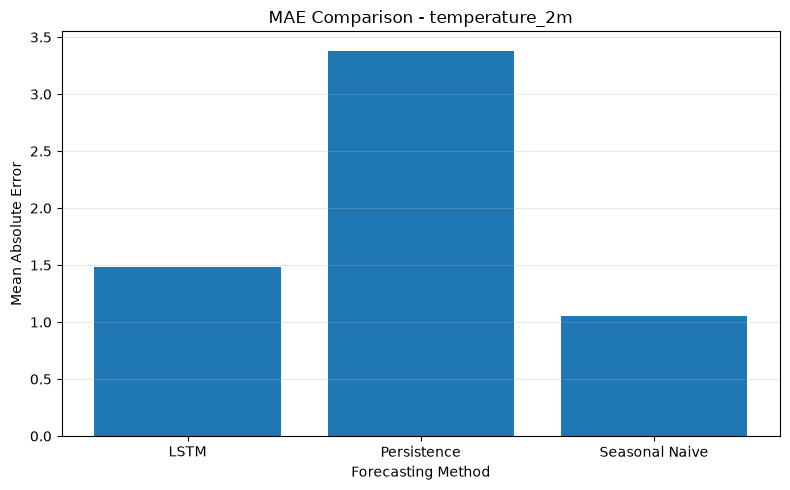

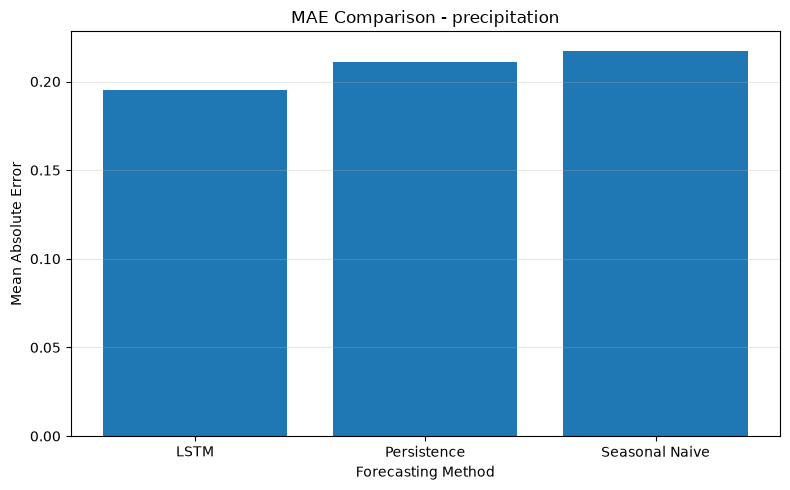

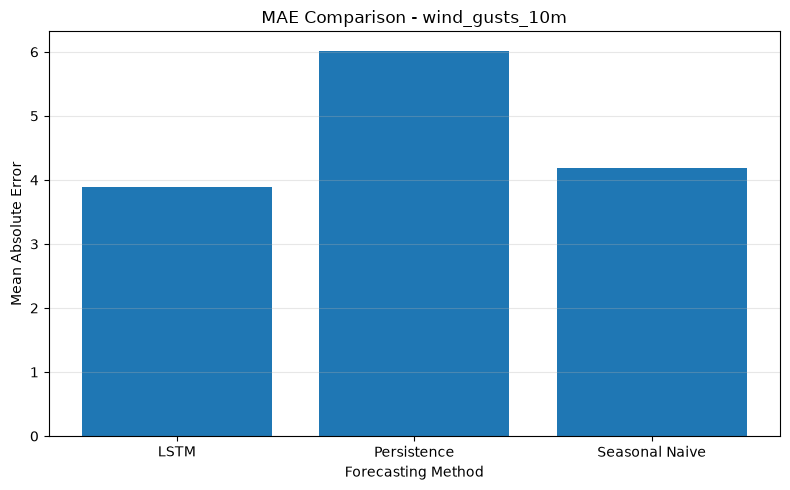


BEST METHOD BY VARIABLE
-----------------------
temperature_2m: Seasonal Naive (MAE = 1.0574)
precipitation: LSTM (MAE = 0.1952)
wind_gusts_10m: LSTM (MAE = 3.8897)

STEP 19.1 COMPLETED SUCCESSFULLY
Cities evaluated: 12
Evaluation records: 252000

Methods compared:
1. LSTM
2. Persistence baseline
3. Seasonal-naive baseline

Variables evaluated:
- temperature_2m
- precipitation
- wind_gusts_10m

Files saved:
- step19_city_wise_baseline_comparison.csv
- step19_lead_time_baseline_comparison.csv
- step19_lstm_and_baseline_predictions.csv
- step19_mae_comparison_precipitation.png
- step19_mae_comparison_temperature_2m.png
- step19_mae_comparison_wind_gusts_10m.png
- step19_overall_baseline_comparison.csv

IMPORTANT:
1. All methods use the same test forecast records.
2. Baseline observations come only from forecast history.
3. No test values were used to fit a model or scaler.
4. Lower MAE and RMSE indicate smaller forecast errors.
5. Higher R2 indicates better explained variance.
6. Overla

In [23]:

# ============================================================
# STEP 19.1 - LSTM VS BASELINE FORECAST COMPARISON
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 19.1.1 CONFIGURATION
# ------------------------------------------------------------

DATA_FILE = "india_weather_12_cities_combined.csv"
OUTPUT_DIR = "STEP17_LSTM_RESULTS"

FORECAST_FILE = os.path.join(
    OUTPUT_DIR,
    "step18_final_test_forecasts.csv"
)

TARGETS = [
    "temperature_2m",
    "precipitation",
    "wind_gusts_10m"
]

# ------------------------------------------------------------
# 19.1.2 CHECK FILES
# ------------------------------------------------------------

for file in [DATA_FILE, FORECAST_FILE]:
    if not os.path.exists(file):
        raise FileNotFoundError(
            f"Required file not found: {file}"
        )

# ------------------------------------------------------------
# 19.1.3 LOAD DATA
# ------------------------------------------------------------

weather = pd.read_csv(DATA_FILE)

forecast = pd.read_csv(FORECAST_FILE)

weather["time"] = pd.to_datetime(
    weather["time"],
    utc=True,
    errors="coerce"
)

forecast["forecast_origin"] = pd.to_datetime(
    forecast["forecast_origin"],
    utc=True,
    errors="coerce"
)

forecast["target_time"] = pd.to_datetime(
    forecast["target_time"],
    utc=True,
    errors="coerce"
)

for col in TARGETS:
    weather[col] = pd.to_numeric(
        weather[col],
        errors="coerce"
    )

    forecast[f"actual_{col}"] = pd.to_numeric(
        forecast[f"actual_{col}"],
        errors="coerce"
    )

    forecast[f"predicted_{col}"] = pd.to_numeric(
        forecast[f"predicted_{col}"],
        errors="coerce"
    )

weather = weather.dropna(
    subset=["city", "time"] + TARGETS
)

forecast = forecast.dropna(
    subset=["city", "forecast_origin", "target_time"]
)

# ------------------------------------------------------------
# 19.1.4 VERIFY UNIQUE WEATHER RECORDS
# ------------------------------------------------------------

if weather.duplicated(["city", "time"]).any():
    raise ValueError(
        "Duplicate city-time records found in weather data."
    )

print("=" * 70)
print("STEP 19.1 - LSTM VS BASELINE COMPARISON")
print("=" * 70)

print("\nWeather dataset records:", len(weather))
print("LSTM forecast records:", len(forecast))
print("Cities:", forecast["city"].nunique())

# ------------------------------------------------------------
# 19.1.5 CREATE PERSISTENCE BASELINE
# ------------------------------------------------------------

# Persistence predicts that future values remain equal
# to the latest observation at the forecast origin.

origin_data = weather[
    ["city", "time"] + TARGETS
].copy()

origin_data = origin_data.rename(
    columns={
        "time": "forecast_origin",
        **{
            col: f"persistence_{col}"
            for col in TARGETS
        }
    }
)

comparison = forecast.merge(
    origin_data,
    on=["city", "forecast_origin"],
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 19.1.6 CREATE SEASONAL-NAIVE BASELINE
# ------------------------------------------------------------

# Predict each target hour using the observed value
# at the same hour on the previous day.

comparison["seasonal_reference_time"] = (
    comparison["target_time"]
    - pd.Timedelta(hours=24)
)

seasonal_data = weather[
    ["city", "time"] + TARGETS
].copy()

seasonal_data = seasonal_data.rename(
    columns={
        "time": "seasonal_reference_time",
        **{
            col: f"seasonal_naive_{col}"
            for col in TARGETS
        }
    }
)

comparison = comparison.merge(
    seasonal_data,
    on=["city", "seasonal_reference_time"],
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 19.1.7 CHECK BASELINE COVERAGE
# ------------------------------------------------------------

baseline_columns = []

for col in TARGETS:
    baseline_columns.extend([
        f"persistence_{col}",
        f"seasonal_naive_{col}"
    ])

missing_counts = comparison[
    baseline_columns
].isna().sum()

print("\nBASELINE MISSING VALUE CHECK")
print(missing_counts.to_string())

if comparison[baseline_columns].isna().any().any():
    raise ValueError(
        "Baseline values are missing. "
        "Check timestamp alignment and dataset coverage."
    )

print("\nBoth baselines successfully generated.")

# ------------------------------------------------------------
# 19.1.8 CALCULATE OVERALL METRICS
# ------------------------------------------------------------

overall_results = []

for target in TARGETS:

    actual = comparison[
        f"actual_{target}"
    ]

    prediction_methods = {
        "LSTM": comparison[f"predicted_{target}"],
        "Persistence": comparison[f"persistence_{target}"],
        "Seasonal Naive": comparison[
            f"seasonal_naive_{target}"
        ]
    }

    for method, predicted in prediction_methods.items():

        mae = mean_absolute_error(
            actual, predicted
        )

        rmse = np.sqrt(
            mean_squared_error(actual, predicted)
        )

        r2 = r2_score(
            actual, predicted
        )

        overall_results.append({
            "variable": target,
            "model": method,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "evaluation_records": len(actual)
        })

overall_df = pd.DataFrame(overall_results)

print("\nOVERALL BASELINE COMPARISON")
print("---------------------------")

print(
    overall_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 19.1.9 CITY-WISE COMPARISON
# ------------------------------------------------------------

city_results = []

for city, group in comparison.groupby("city"):

    for target in TARGETS:

        actual = group[f"actual_{target}"]

        methods = {
            "LSTM": group[f"predicted_{target}"],
            "Persistence": group[f"persistence_{target}"],
            "Seasonal Naive": group[
                f"seasonal_naive_{target}"
            ]
        }

        for method, predicted in methods.items():

            city_results.append({
                "city": city,
                "variable": target,
                "model": method,
                "MAE": mean_absolute_error(
                    actual, predicted
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(
                        actual, predicted
                    )
                ),
                "R2": r2_score(
                    actual, predicted
                ),
                "evaluation_records": len(actual)
            })

city_df = pd.DataFrame(city_results)

print("\nCITY-WISE BASELINE COMPARISON")
print("-----------------------------")

print(
    city_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 19.1.10 FORECAST LEAD-TIME COMPARISON
# ------------------------------------------------------------

lead_results = []

for lead, group in comparison.groupby(
    "forecast_lead_hour"
):

    for target in TARGETS:

        actual = group[f"actual_{target}"]

        methods = {
            "LSTM": group[f"predicted_{target}"],
            "Persistence": group[f"persistence_{target}"],
            "Seasonal Naive": group[
                f"seasonal_naive_{target}"
            ]
        }

        for method, predicted in methods.items():

            lead_results.append({
                "forecast_lead_hour": lead,
                "variable": target,
                "model": method,
                "MAE": mean_absolute_error(
                    actual, predicted
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(
                        actual, predicted
                    )
                )
            })

lead_df = pd.DataFrame(lead_results)

# ------------------------------------------------------------
# 19.1.11 VISUALISE MAE COMPARISON
# ------------------------------------------------------------

for target in TARGETS:

    plot_data = overall_df[
        overall_df["variable"] == target
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        plot_data["model"],
        plot_data["MAE"]
    )

    plt.title(
        f"MAE Comparison - {target}"
    )

    plt.xlabel("Forecasting Method")
    plt.ylabel("Mean Absolute Error")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"step19_mae_comparison_{target}.png"
        ),
        dpi=300
    )

    plt.show()

# ------------------------------------------------------------
# 19.1.12 IDENTIFY BEST METHOD BY MAE
# ------------------------------------------------------------

print("\nBEST METHOD BY VARIABLE")
print("-----------------------")

for target in TARGETS:

    subset = overall_df[
        overall_df["variable"] == target
    ]

    best = subset.loc[
        subset["MAE"].idxmin()
    ]

    print(
        f"{target}: {best['model']} "
        f"(MAE = {best['MAE']:.4f})"
    )

# ------------------------------------------------------------
# 19.1.13 SAVE RESULTS
# ------------------------------------------------------------

overall_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step19_overall_baseline_comparison.csv"
    ),
    index=False
)

city_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step19_city_wise_baseline_comparison.csv"
    ),
    index=False
)

lead_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step19_lead_time_baseline_comparison.csv"
    ),
    index=False
)

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step19_lstm_and_baseline_predictions.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 19.1.14 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 19.1 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Cities evaluated:", comparison["city"].nunique())
print("Evaluation records:", len(comparison))

print("\nMethods compared:")
print("1. LSTM")
print("2. Persistence baseline")
print("3. Seasonal-naive baseline")

print("\nVariables evaluated:")
for target in TARGETS:
    print("-", target)

print("\nFiles saved:")

for file in sorted(os.listdir(OUTPUT_DIR)):
    if file.startswith("step19_"):
        print("-", file)

print("\nIMPORTANT:")
print("1. All methods use the same test forecast records.")
print("2. Baseline observations come only from forecast history.")
print("3. No test values were used to fit a model or scaler.")
print("4. Lower MAE and RMSE indicate smaller forecast errors.")
print("5. Higher R2 indicates better explained variance.")
print("6. Overlapping forecast windows remain in the evaluation.")

print("=" * 70)


STEP 19.2 - LEAD-TIME AND RAINFALL ANALYSIS

Evaluation records: 252000
Cities: 12

FORECAST LEAD GROUP COUNTS
lead_group
Hours 1-6      63000
Hours 7-12     63000
Hours 13-18    63000
Hours 19-24    63000

LEAD-GROUP PERFORMANCE
----------------------
 lead_group       variable          model    MAE   RMSE  records
  Hours 1-6 temperature_2m           LSTM 1.5562 2.3031    63000
  Hours 1-6 temperature_2m    Persistence 2.3592 3.5352    63000
  Hours 1-6 temperature_2m Seasonal Naive 1.0463 1.5249    63000
  Hours 1-6  precipitation           LSTM 0.1711 0.4731    63000
  Hours 1-6  precipitation    Persistence 0.1579 0.5870    63000
  Hours 1-6  precipitation Seasonal Naive 0.2048 0.7272    63000
  Hours 1-6 wind_gusts_10m           LSTM 3.4689 4.6281    63000
  Hours 1-6 wind_gusts_10m    Persistence 4.8430 6.6745    63000
  Hours 1-6 wind_gusts_10m Seasonal Naive 4.1287 5.7730    63000
 Hours 7-12 temperature_2m           LSTM 1.5619 2.1569    63000
 Hours 7-12 temperature_2m    Pe

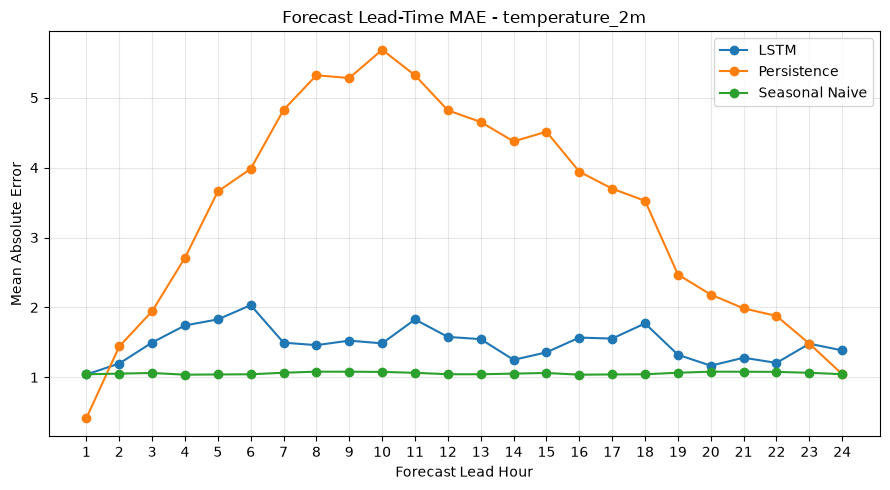

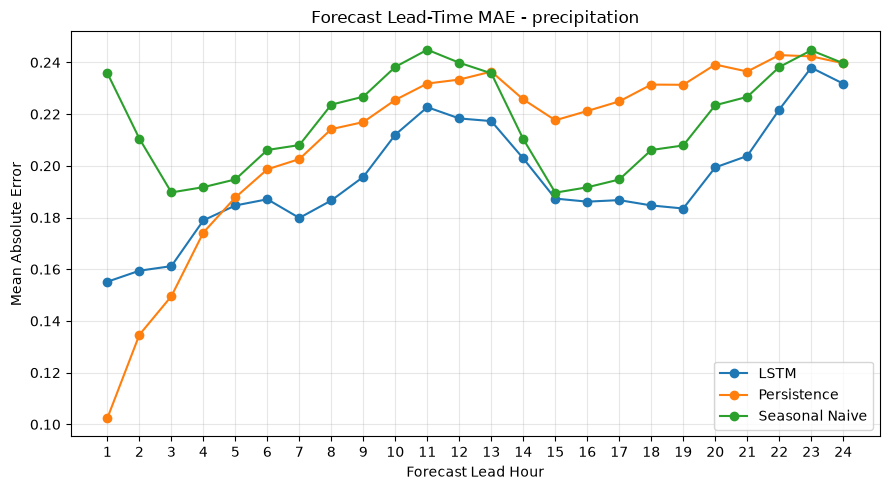

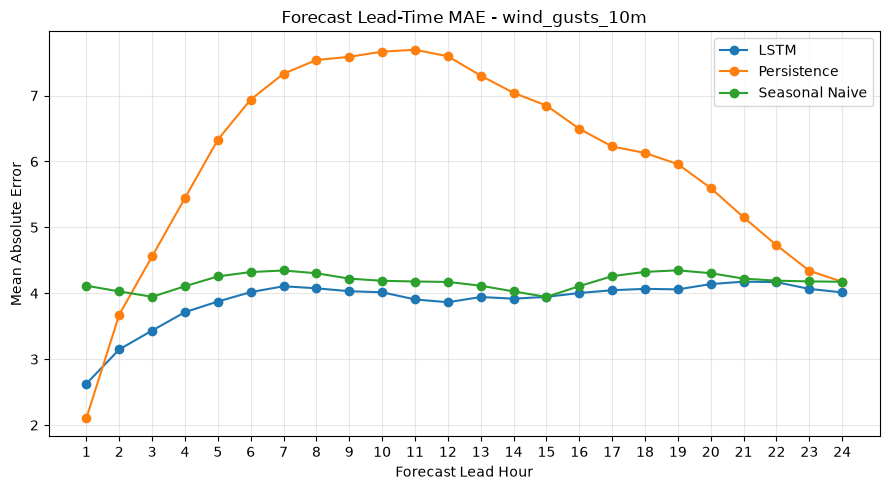

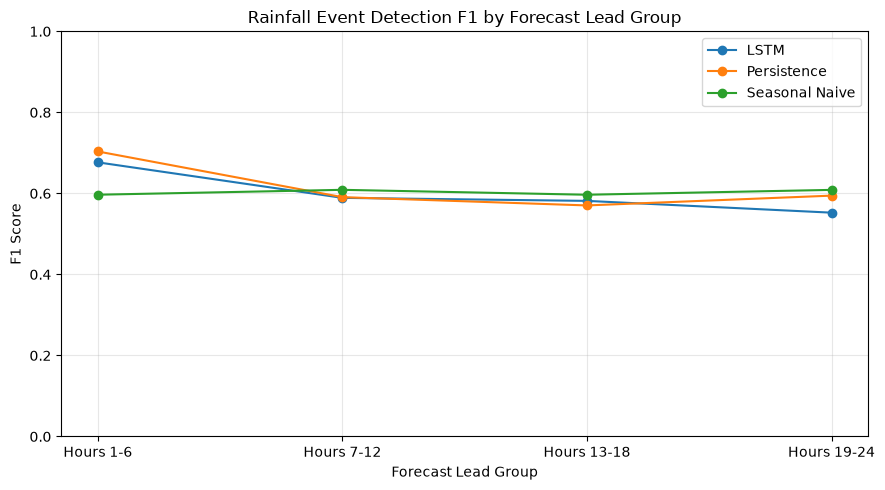


STEP 19.2 COMPLETED SUCCESSFULLY

Forecast lead groups:
1. Hours 1-6
2. Hours 7-12
3. Hours 13-18
4. Hours 19-24

Rainfall threshold: 0.1 mm/hour

Evaluation records: 252000
Cities: 12

Generated output files:
- step19_2_lead_group_metrics.csv
- step19_2_individual_hour_metrics.csv
- step19_2_rainfall_dry_wet_metrics.csv
- step19_2_rainfall_event_detection.csv
- step19_2_rainfall_confusion_matrix.csv
- step19_2_rainfall_lead_group_detection.csv

Generated charts:
- Lead-time MAE charts for three variables
- Rainfall event F1 score by lead group

RESEARCH NOTES:
1. The 0.1 mm/hour rainfall threshold is exploratory.
2. Wet-hour regression uses actual wet hours only.
3. Rain-event metrics use clipped non-negative predictions.
4. Precision, recall and F1 measure event detection.
5. Overlapping forecast windows are retained.
6. These results do not establish operational warning skill.


In [24]:

# ============================================================
# STEP 19.2 - LEAD-TIME AND RAINFALL PERFORMANCE ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 19.2.1 CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = "STEP17_LSTM_RESULTS"

INPUT_FILE = os.path.join(
    OUTPUT_DIR,
    "step19_lstm_and_baseline_predictions.csv"
)

RAIN_THRESHOLD = 0.1  # mm/hour; exploratory threshold

TARGETS = [
    "temperature_2m",
    "precipitation",
    "wind_gusts_10m"
]

METHODS = {
    "LSTM": "predicted",
    "Persistence": "persistence",
    "Seasonal Naive": "seasonal_naive"
}

# ------------------------------------------------------------
# 19.2.2 LOAD PREVIOUS RESULTS
# ------------------------------------------------------------

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"Required file not found: {INPUT_FILE}"
    )

df = pd.read_csv(INPUT_FILE)

required_columns = [
    "city",
    "forecast_lead_hour"
]

for target in TARGETS:
    required_columns.append(f"actual_{target}")

    for prefix in METHODS.values():
        required_columns.append(
            f"{prefix}_{target}"
        )

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df["forecast_lead_hour"] = pd.to_numeric(
    df["forecast_lead_hour"],
    errors="coerce"
)

df = df.dropna(
    subset=required_columns
).copy()

if not df["forecast_lead_hour"].between(1, 24).all():
    raise ValueError(
        "Forecast lead hours must be between 1 and 24."
    )

print("=" * 70)
print("STEP 19.2 - LEAD-TIME AND RAINFALL ANALYSIS")
print("=" * 70)

print("\nEvaluation records:", len(df))
print("Cities:", df["city"].nunique())

# ------------------------------------------------------------
# 19.2.3 CREATE FORECAST LEAD GROUPS
# ------------------------------------------------------------

df["lead_group"] = pd.cut(
    df["forecast_lead_hour"],
    bins=[0, 6, 12, 18, 24],
    labels=[
        "Hours 1-6",
        "Hours 7-12",
        "Hours 13-18",
        "Hours 19-24"
    ],
    include_lowest=True
)

print("\nFORECAST LEAD GROUP COUNTS")
print(
    df["lead_group"].value_counts(
        sort=False
    ).to_string()
)

# ------------------------------------------------------------
# 19.2.4 LEAD-GROUP REGRESSION METRICS
# ------------------------------------------------------------

lead_group_results = []

for lead_group, group in df.groupby(
    "lead_group",
    observed=False
):

    for target in TARGETS:

        actual = group[f"actual_{target}"]

        for method, prefix in METHODS.items():

            predicted = group[
                f"{prefix}_{target}"
            ]

            lead_group_results.append({
                "lead_group": str(lead_group),
                "variable": target,
                "model": method,
                "MAE": mean_absolute_error(
                    actual, predicted
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(
                        actual, predicted
                    )
                ),
                "records": len(group)
            })

lead_group_df = pd.DataFrame(
    lead_group_results
)

print("\nLEAD-GROUP PERFORMANCE")
print("----------------------")

print(
    lead_group_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 19.2.5 INDIVIDUAL FORECAST-HOUR METRICS
# ------------------------------------------------------------

hour_results = []

for lead_hour, group in df.groupby(
    "forecast_lead_hour"
):

    for target in TARGETS:

        actual = group[f"actual_{target}"]

        for method, prefix in METHODS.items():

            predicted = group[
                f"{prefix}_{target}"
            ]

            hour_results.append({
                "forecast_lead_hour": int(lead_hour),
                "variable": target,
                "model": method,
                "MAE": mean_absolute_error(
                    actual, predicted
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(
                        actual, predicted
                    )
                ),
                "records": len(group)
            })

hour_df = pd.DataFrame(hour_results)

print("\nINDIVIDUAL FORECAST-HOUR METRICS")
print("--------------------------------")

for target in TARGETS:

    print(f"\n{target}")

    subset = hour_df[
        hour_df["variable"] == target
    ]

    print(
        subset.pivot(
            index="forecast_lead_hour",
            columns="model",
            values="MAE"
        ).round(4).to_string()
    )

# ------------------------------------------------------------
# 19.2.6 RAINFALL DRY-HOUR AND WET-HOUR ANALYSIS
# ------------------------------------------------------------

actual_rain = df["actual_precipitation"]

df["rain_condition"] = np.where(
    actual_rain >= RAIN_THRESHOLD,
    "Wet hour",
    "Dry hour"
)

print("\nRAINFALL CONDITION COUNTS")
print("-------------------------")

print(
    df["rain_condition"].value_counts().to_string()
)

rain_regression_results = []

for condition, group in df.groupby(
    "rain_condition"
):

    for method, prefix in METHODS.items():

        actual = group["actual_precipitation"]

        predicted = group[
            f"{prefix}_precipitation"
        ]

        rain_regression_results.append({
            "condition": condition,
            "model": method,
            "MAE": mean_absolute_error(
                actual, predicted
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    actual, predicted
                )
            ),
            "records": len(group)
        })

rain_regression_df = pd.DataFrame(
    rain_regression_results
)

print("\nDRY-HOUR AND WET-HOUR RAINFALL REGRESSION")
print("-----------------------------------------")

print(
    rain_regression_df.round(4).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 19.2.7 RAIN EVENT DETECTION
# ------------------------------------------------------------

# For event detection only, negative predicted rainfall
# is clipped to zero because rainfall cannot be negative.
#
# Regression metrics above use the original predictions.

rain_event_results = []
confusion_results = []

actual_event = (
    df["actual_precipitation"] >= RAIN_THRESHOLD
).astype(int)

for method, prefix in METHODS.items():

    predicted_rain = df[
        f"{prefix}_precipitation"
    ].clip(lower=0)

    predicted_event = (
        predicted_rain >= RAIN_THRESHOLD
    ).astype(int)

    rain_event_results.append({
        "model": method,
        "threshold_mm_per_hour": RAIN_THRESHOLD,
        "accuracy": accuracy_score(
            actual_event, predicted_event
        ),
        "precision": precision_score(
            actual_event,
            predicted_event,
            zero_division=0
        ),
        "recall": recall_score(
            actual_event,
            predicted_event,
            zero_division=0
        ),
        "F1_score": f1_score(
            actual_event,
            predicted_event,
            zero_division=0
        ),
        "actual_wet_hours": int(
            actual_event.sum()
        ),
        "predicted_wet_hours": int(
            predicted_event.sum()
        )
    })

    tn, fp, fn, tp = confusion_matrix(
        actual_event,
        predicted_event,
        labels=[0, 1]
    ).ravel()

    confusion_results.append({
        "model": method,
        "true_negative": tn,
        "false_positive": fp,
        "false_negative": fn,
        "true_positive": tp
    })

rain_event_df = pd.DataFrame(
    rain_event_results
)

confusion_df = pd.DataFrame(
    confusion_results
)

print("\nRAINFALL EVENT DETECTION")
print("------------------------")

print(
    rain_event_df.round(4).to_string(index=False)
)

print("\nRAINFALL CONFUSION MATRIX COUNTS")
print("--------------------------------")

print(
    confusion_df.to_string(index=False)
)

# ------------------------------------------------------------
# 19.2.8 LSTM RAIN EVENT DETECTION BY LEAD GROUP
# ------------------------------------------------------------

rain_lead_results = []

for lead_group, group in df.groupby(
    "lead_group",
    observed=False
):

    actual_event_group = (
        group["actual_precipitation"]
        >= RAIN_THRESHOLD
    ).astype(int)

    for method, prefix in METHODS.items():

        predicted_rain = group[
            f"{prefix}_precipitation"
        ].clip(lower=0)

        predicted_event = (
            predicted_rain >= RAIN_THRESHOLD
        ).astype(int)

        rain_lead_results.append({
            "lead_group": str(lead_group),
            "model": method,
            "precision": precision_score(
                actual_event_group,
                predicted_event,
                zero_division=0
            ),
            "recall": recall_score(
                actual_event_group,
                predicted_event,
                zero_division=0
            ),
            "F1_score": f1_score(
                actual_event_group,
                predicted_event,
                zero_division=0
            ),
            "records": len(group)
        })

rain_lead_df = pd.DataFrame(
    rain_lead_results
)

print("\nRAINFALL EVENT DETECTION BY LEAD GROUP")
print("--------------------------------------")

print(
    rain_lead_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 19.2.9 PLOT LEAD-TIME MAE
# ------------------------------------------------------------

for target in TARGETS:

    plt.figure(figsize=(9, 5))

    subset = hour_df[
        hour_df["variable"] == target
    ]

    for method in METHODS:

        method_data = subset[
            subset["model"] == method
        ].sort_values("forecast_lead_hour")

        plt.plot(
            method_data["forecast_lead_hour"],
            method_data["MAE"],
            marker="o",
            label=method
        )

    plt.title(
        f"Forecast Lead-Time MAE - {target}"
    )

    plt.xlabel("Forecast Lead Hour")
    plt.ylabel("Mean Absolute Error")
    plt.xticks(range(1, 25))
    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"step19_2_lead_time_mae_{target}.png"
        ),
        dpi=300
    )

    plt.show()

# ------------------------------------------------------------
# 19.2.10 PLOT RAINFALL EVENT F1 SCORE
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for method in METHODS:

    subset = rain_lead_df[
        rain_lead_df["model"] == method
    ]

    plt.plot(
        subset["lead_group"],
        subset["F1_score"],
        marker="o",
        label=method
    )

plt.title("Rainfall Event Detection F1 by Forecast Lead Group")
plt.xlabel("Forecast Lead Group")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "step19_2_rainfall_event_f1_by_lead.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 19.2.11 SAVE ALL RESULTS
# ------------------------------------------------------------

outputs = {
    "step19_2_lead_group_metrics.csv":
        lead_group_df,

    "step19_2_individual_hour_metrics.csv":
        hour_df,

    "step19_2_rainfall_dry_wet_metrics.csv":
        rain_regression_df,

    "step19_2_rainfall_event_detection.csv":
        rain_event_df,

    "step19_2_rainfall_confusion_matrix.csv":
        confusion_df,

    "step19_2_rainfall_lead_group_detection.csv":
        rain_lead_df
}

for filename, result in outputs.items():

    result.to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=False
    )

# ------------------------------------------------------------
# 19.2.12 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 19.2 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nForecast lead groups:")
print("1. Hours 1-6")
print("2. Hours 7-12")
print("3. Hours 13-18")
print("4. Hours 19-24")

print("\nRainfall threshold:", RAIN_THRESHOLD, "mm/hour")

print("\nEvaluation records:", len(df))
print("Cities:", df["city"].nunique())

print("\nGenerated output files:")

for filename in outputs:
    print("-", filename)

print("\nGenerated charts:")
print("- Lead-time MAE charts for three variables")
print("- Rainfall event F1 score by lead group")

print("\nRESEARCH NOTES:")
print("1. The 0.1 mm/hour rainfall threshold is exploratory.")
print("2. Wet-hour regression uses actual wet hours only.")
print("3. Rain-event metrics use clipped non-negative predictions.")
print("4. Precision, recall and F1 measure event detection.")
print("5. Overlapping forecast windows are retained.")
print("6. These results do not establish operational warning skill.")

print("=" * 70)


STEP 19.3 - CITY-WISE FORECASTING ANALYSIS

Evaluation records: 252000
Cities: 12
Rainfall threshold: 0.1 mm/hour

CITY-WISE REGRESSION METRICS
----------------------------
              city       variable          model    MAE   RMSE      R2  records
         Bengaluru temperature_2m           LSTM 1.0386 1.3600  0.8429    21000
         Bengaluru temperature_2m    Persistence 3.6536 4.7601 -0.9249    21000
         Bengaluru temperature_2m Seasonal Naive 0.7909 1.0862  0.8998    21000
         Bengaluru  precipitation           LSTM 0.1508 0.4206  0.0885    21000
         Bengaluru  precipitation    Persistence 0.2042 0.6394 -1.1058    21000
         Bengaluru  precipitation Seasonal Naive 0.1628 0.5319 -0.4573    21000
         Bengaluru wind_gusts_10m           LSTM 3.8494 4.9543  0.7783    21000
         Bengaluru wind_gusts_10m    Persistence 7.3109 9.2853  0.2214    21000
         Bengaluru wind_gusts_10m Seasonal Naive 4.1277 5.4041  0.7362    21000
            Bhopal temperat

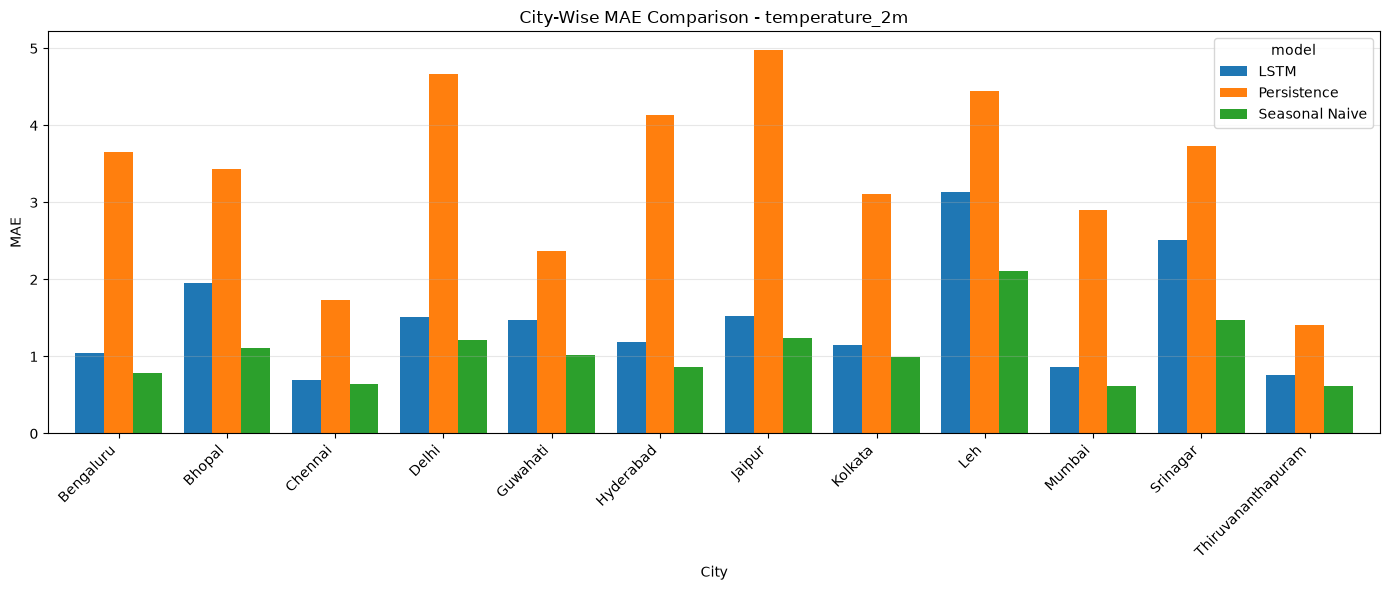

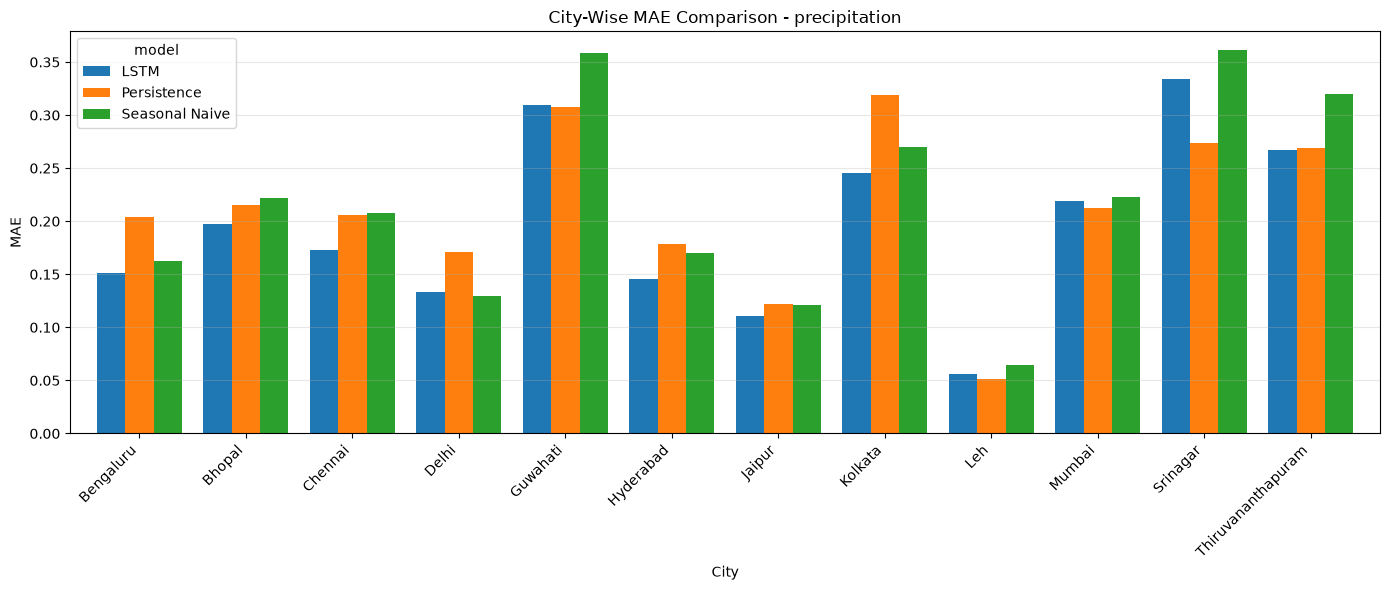

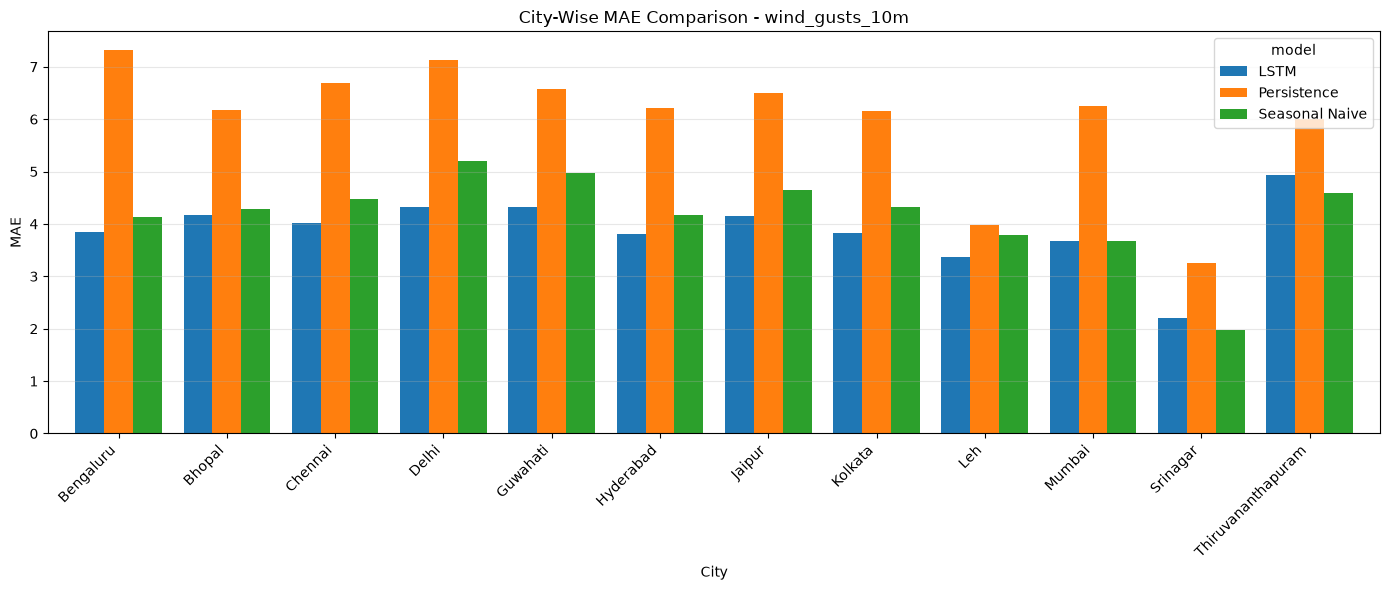

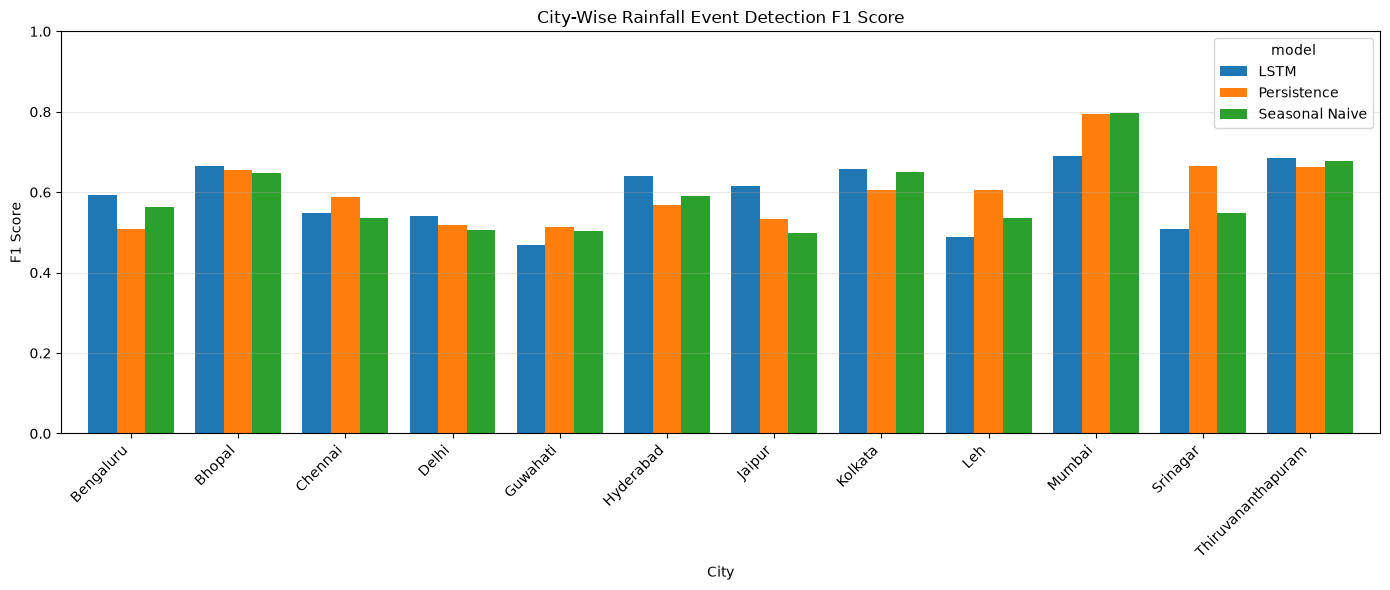

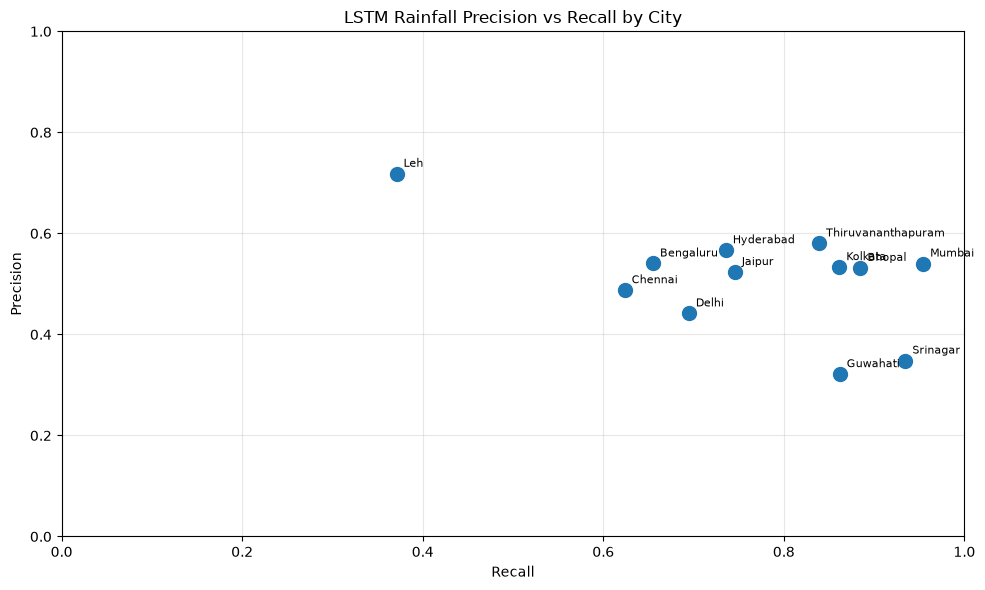


STEP 19.3 COMPLETED SUCCESSFULLY

Evaluation records: 252000
Cities: 12
Rainfall threshold: 0.1 mm/hour

Variables evaluated:
- temperature_2m
- precipitation
- wind_gusts_10m

Forecasting methods:
- LSTM
- Persistence
- Seasonal Naive

Generated CSV files:
- step19_3_city_wise_forecast_metrics.csv
- step19_3_lstm_baseline_skill_by_city.csv
- step19_3_city_rainfall_detection.csv
- step19_3_city_rainfall_confusion_matrix.csv
- step19_3_city_wet_hour_metrics.csv
- step19_3_best_model_by_city.csv

Generated charts:
- City-wise temperature MAE
- City-wise precipitation MAE
- City-wise wind-gust MAE
- City-wise rainfall F1 score
- Rainfall precision-recall comparison

RESEARCH CAUTIONS:
1. The 0.1 mm/hour rainfall threshold is exploratory.
2. Rainfall predictions are clipped at zero for event detection.
3. City-wise metrics are based on overlapping forecast windows.
4. A high rainfall recall may come with more false alarms.
5. City-level results do not establish operational warning skill.


In [25]:

# ============================================================
# STEP 19.3 - CITY-WISE FORECASTING AND RAINFALL ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 19.3.1 CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = "STEP17_LSTM_RESULTS"

INPUT_FILE = os.path.join(
    OUTPUT_DIR,
    "step19_lstm_and_baseline_predictions.csv"
)

RAIN_THRESHOLD = 0.1

TARGETS = [
    "temperature_2m",
    "precipitation",
    "wind_gusts_10m"
]

METHODS = [
    "LSTM",
    "Persistence",
    "Seasonal Naive"
]

# ------------------------------------------------------------
# 19.3.2 CHECK AND LOAD DATA
# ------------------------------------------------------------

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"Required file not found: {INPUT_FILE}"
    )

df = pd.read_csv(INPUT_FILE)

required_columns = [
    "city",
    "actual_temperature_2m",
    "actual_precipitation",
    "actual_wind_gusts_10m",
    "predicted_temperature_2m",
    "predicted_precipitation",
    "predicted_wind_gusts_10m",
    "persistence_temperature_2m",
    "persistence_precipitation",
    "persistence_wind_gusts_10m",
    "seasonal_naive_temperature_2m",
    "seasonal_naive_precipitation",
    "seasonal_naive_wind_gusts_10m"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df = df.dropna(
    subset=required_columns
).copy()

df["city"] = df["city"].astype(str)

print("=" * 70)
print("STEP 19.3 - CITY-WISE FORECASTING ANALYSIS")
print("=" * 70)

print("\nEvaluation records:", len(df))
print("Cities:", df["city"].nunique())
print("Rainfall threshold:", RAIN_THRESHOLD, "mm/hour")

# ------------------------------------------------------------
# 19.3.3 CITY-WISE REGRESSION METRICS
# ------------------------------------------------------------

city_metrics = []

for city, group in df.groupby("city"):

    for target in TARGETS:

        actual = group[f"actual_{target}"]

        predictions = {
            "LSTM": group[f"predicted_{target}"],
            "Persistence": group[f"persistence_{target}"],
            "Seasonal Naive": group[
                f"seasonal_naive_{target}"
            ]
        }

        for method, predicted in predictions.items():

            city_metrics.append({
                "city": city,
                "variable": target,
                "model": method,
                "MAE": mean_absolute_error(
                    actual, predicted
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(
                        actual, predicted
                    )
                ),
                "R2": (
                    1 - np.sum(
                        (actual - predicted) ** 2
                    ) / np.sum(
                        (actual - actual.mean()) ** 2
                    )
                ) if actual.nunique() > 1 else np.nan,
                "records": len(group)
            })

city_metrics_df = pd.DataFrame(city_metrics)

print("\nCITY-WISE REGRESSION METRICS")
print("----------------------------")

print(
    city_metrics_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 19.3.4 LSTM SKILL AGAINST BASELINES
# ------------------------------------------------------------

skill_results = []

for city in sorted(df["city"].unique()):

    city_data = df[df["city"] == city]

    for target in TARGETS:

        actual = city_data[f"actual_{target}"]

        lstm_pred = city_data[f"predicted_{target}"]

        lstm_mae = mean_absolute_error(
            actual, lstm_pred
        )

        lstm_rmse = np.sqrt(
            mean_squared_error(actual, lstm_pred)
        )

        for baseline in ["Persistence", "Seasonal Naive"]:

            baseline_pred = city_data[
                f"{baseline.lower().replace(' ', '_')}_{target}"
            ]

            baseline_mae = mean_absolute_error(
                actual, baseline_pred
            )

            baseline_rmse = np.sqrt(
                mean_squared_error(
                    actual, baseline_pred
                )
            )

            skill_results.append({
                "city": city,
                "variable": target,
                "baseline": baseline,
                "LSTM_MAE": lstm_mae,
                "Baseline_MAE": baseline_mae,
                "MAE_skill_percent": (
                    (baseline_mae - lstm_mae)
                    / baseline_mae * 100
                    if baseline_mae > 0 else np.nan
                ),
                "LSTM_RMSE": lstm_rmse,
                "Baseline_RMSE": baseline_rmse,
                "RMSE_skill_percent": (
                    (baseline_rmse - lstm_rmse)
                    / baseline_rmse * 100
                    if baseline_rmse > 0 else np.nan
                )
            })

skill_df = pd.DataFrame(skill_results)

print("\nLSTM SKILL AGAINST BASELINES")
print("----------------------------")

print(
    skill_df.round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 19.3.5 CITY-WISE RAINFALL EVENT DETECTION
# ------------------------------------------------------------

rain_detection_results = []

rain_confusion_results = []

for city, group in df.groupby("city"):

    actual_rain = (
        group["actual_precipitation"]
        >= RAIN_THRESHOLD
    ).astype(int)

    for method in METHODS:

        if method == "LSTM":
            predicted_rainfall = group[
                "predicted_precipitation"
            ]

        elif method == "Persistence":
            predicted_rainfall = group[
                "persistence_precipitation"
            ]

        else:
            predicted_rainfall = group[
                "seasonal_naive_precipitation"
            ]

        # Negative rainfall predictions are physically invalid.
        # Clip them to zero before event classification.
        predicted_rainfall = predicted_rainfall.clip(
            lower=0
        )

        predicted_rain = (
            predicted_rainfall >= RAIN_THRESHOLD
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            actual_rain,
            predicted_rain,
            labels=[0, 1]
        ).ravel()

        rain_detection_results.append({
            "city": city,
            "model": method,
            "accuracy": accuracy_score(
                actual_rain, predicted_rain
            ),
            "precision": precision_score(
                actual_rain,
                predicted_rain,
                zero_division=0
            ),
            "recall": recall_score(
                actual_rain,
                predicted_rain,
                zero_division=0
            ),
            "F1_score": f1_score(
                actual_rain,
                predicted_rain,
                zero_division=0
            ),
            "actual_wet_hours": int(
                actual_rain.sum()
            ),
            "predicted_wet_hours": int(
                predicted_rain.sum()
            ),
            "records": len(group)
        })

        rain_confusion_results.append({
            "city": city,
            "model": method,
            "true_negative": int(tn),
            "false_positive": int(fp),
            "false_negative": int(fn),
            "true_positive": int(tp)
        })

rain_detection_df = pd.DataFrame(
    rain_detection_results
)

rain_confusion_df = pd.DataFrame(
    rain_confusion_results
)

print("\nCITY-WISE RAINFALL EVENT DETECTION")
print("----------------------------------")

print(
    rain_detection_df.round(4).to_string(index=False)
)

print("\nCITY-WISE RAINFALL CONFUSION COUNTS")
print("-----------------------------------")

print(
    rain_confusion_df.to_string(index=False)
)

# ------------------------------------------------------------
# 19.3.6 CITY-WISE WET-HOUR RAINFALL REGRESSION
# ------------------------------------------------------------

wet_results = []

for city, group in df.groupby("city"):

    wet_group = group[
        group["actual_precipitation"] >= RAIN_THRESHOLD
    ]

    if len(wet_group) == 0:
        continue

    actual = wet_group["actual_precipitation"]

    predictions = {
        "LSTM": wet_group["predicted_precipitation"],
        "Persistence": wet_group["persistence_precipitation"],
        "Seasonal Naive": wet_group[
            "seasonal_naive_precipitation"
        ]
    }

    for method, predicted in predictions.items():

        predicted = predicted.clip(lower=0)

        wet_results.append({
            "city": city,
            "model": method,
            "wet_hour_MAE": mean_absolute_error(
                actual, predicted
            ),
            "wet_hour_RMSE": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "actual_wet_records": len(wet_group)
        })

wet_metrics_df = pd.DataFrame(wet_results)

print("\nWET-HOUR RAINFALL REGRESSION BY CITY")
print("------------------------------------")

print(
    wet_metrics_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 19.3.7 IDENTIFY BEST MODEL FOR EACH CITY
# ------------------------------------------------------------

best_model_results = []

for city in sorted(df["city"].unique()):

    for target in TARGETS:

        subset = city_metrics_df[
            (city_metrics_df["city"] == city) &
            (city_metrics_df["variable"] == target)
        ]

        best = subset.loc[
            subset["MAE"].idxmin()
        ]

        best_model_results.append({
            "city": city,
            "variable": target,
            "best_model": best["model"],
            "best_MAE": best["MAE"],
            "best_RMSE": best["RMSE"]
        })

best_model_df = pd.DataFrame(
    best_model_results
)

print("\nBEST FORECASTING METHOD BY CITY")
print("--------------------------------")

print(
    best_model_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 19.3.8 RAINFALL FALSE-ALARM ANALYSIS
# ------------------------------------------------------------

lstm_rain = rain_detection_df[
    rain_detection_df["model"] == "LSTM"
].copy()

lstm_rain = lstm_rain.sort_values(
    "precision",
    ascending=True
)

print("\nCITIES WITH LOWEST LSTM RAINFALL PRECISION")
print("-------------------------------------------")

print(
    lstm_rain[
        [
            "city",
            "precision",
            "recall",
            "F1_score",
            "actual_wet_hours",
            "predicted_wet_hours"
        ]
    ].head(5).round(4).to_string(index=False)
)

print("\nCITIES WITH HIGHEST LSTM RAINFALL F1")
print("-------------------------------------")

print(
    lstm_rain.sort_values(
        "F1_score",
        ascending=False
    )[
        [
            "city",
            "precision",
            "recall",
            "F1_score"
        ]
    ].head(5).round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 19.3.9 CHART - CITY-WISE LSTM VS BASELINE MAE
# ------------------------------------------------------------

for target in TARGETS:

    plot_data = city_metrics_df[
        city_metrics_df["variable"] == target
    ]

    pivot_data = plot_data.pivot(
        index="city",
        columns="model",
        values="MAE"
    )

    pivot_data = pivot_data[
        METHODS
    ]

    ax = pivot_data.plot(
        kind="bar",
        figsize=(14, 6),
        width=0.8
    )

    ax.set_title(
        f"City-Wise MAE Comparison - {target}"
    )

    ax.set_xlabel("City")
    ax.set_ylabel("MAE")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"step19_3_city_mae_{target}.png"
        ),
        dpi=300
    )

    plt.show()

# ------------------------------------------------------------
# 19.3.10 CHART - RAINFALL F1 SCORE BY CITY
# ------------------------------------------------------------

rain_pivot = rain_detection_df.pivot(
    index="city",
    columns="model",
    values="F1_score"
)

rain_pivot = rain_pivot[
    METHODS
]

ax = rain_pivot.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

ax.set_title(
    "City-Wise Rainfall Event Detection F1 Score"
)

ax.set_xlabel("City")
ax.set_ylabel("F1 Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "step19_3_city_rainfall_f1.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 19.3.11 CHART - LSTM RAINFALL PRECISION VS RECALL
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    lstm_rain["recall"],
    lstm_rain["precision"],
    s=100
)

for _, row in lstm_rain.iterrows():

    plt.annotate(
        row["city"],
        (row["recall"], row["precision"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(
    "LSTM Rainfall Precision vs Recall by City"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "step19_3_rainfall_precision_recall.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 19.3.12 SAVE ALL RESULTS
# ------------------------------------------------------------

output_files = {
    "step19_3_city_wise_forecast_metrics.csv":
        city_metrics_df,

    "step19_3_lstm_baseline_skill_by_city.csv":
        skill_df,

    "step19_3_city_rainfall_detection.csv":
        rain_detection_df,

    "step19_3_city_rainfall_confusion_matrix.csv":
        rain_confusion_df,

    "step19_3_city_wet_hour_metrics.csv":
        wet_metrics_df,

    "step19_3_best_model_by_city.csv":
        best_model_df
}

for filename, result_df in output_files.items():

    result_df.to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=False
    )

# ------------------------------------------------------------
# 19.3.13 FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 19.3 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nEvaluation records:", len(df))
print("Cities:", df["city"].nunique())
print("Rainfall threshold:", RAIN_THRESHOLD, "mm/hour")

print("\nVariables evaluated:")
for target in TARGETS:
    print("-", target)

print("\nForecasting methods:")
for method in METHODS:
    print("-", method)

print("\nGenerated CSV files:")

for filename in output_files:
    print("-", filename)

print("\nGenerated charts:")
print("- City-wise temperature MAE")
print("- City-wise precipitation MAE")
print("- City-wise wind-gust MAE")
print("- City-wise rainfall F1 score")
print("- Rainfall precision-recall comparison")

print("\nRESEARCH CAUTIONS:")
print("1. The 0.1 mm/hour rainfall threshold is exploratory.")
print("2. Rainfall predictions are clipped at zero for event detection.")
print("3. City-wise metrics are based on overlapping forecast windows.")
print("4. A high rainfall recall may come with more false alarms.")
print("5. City-level results do not establish operational warning skill.")

print("\n" + "=" * 70)


STEP 19.4 - FORECAST ERROR AND RESIDUAL ANALYSIS

1. DATA LOADED
----------------------------------------
Dataset shape: (252000, 17)
Available columns: ['city', 'forecast_origin', 'target_time', 'forecast_lead_hour', 'actual_temperature_2m', 'predicted_temperature_2m', 'actual_precipitation', 'predicted_precipitation', 'actual_wind_gusts_10m', 'predicted_wind_gusts_10m', 'persistence_temperature_2m', 'persistence_precipitation', 'persistence_wind_gusts_10m', 'seasonal_reference_time', 'seasonal_naive_temperature_2m', 'seasonal_naive_precipitation', 'seasonal_naive_wind_gusts_10m']

2. COLUMN MAPPING
----------------------------------------

temperature_2m
  Actual: actual_temperature_2m
  LSTM: predicted_temperature_2m
  Persistence: persistence_temperature_2m
  Seasonal Naive: seasonal_naive_temperature_2m

precipitation
  Actual: actual_precipitation
  LSTM: predicted_precipitation
  Persistence: persistence_precipitation
  Seasonal Naive: seasonal_naive_precipitation

wind_gusts_10

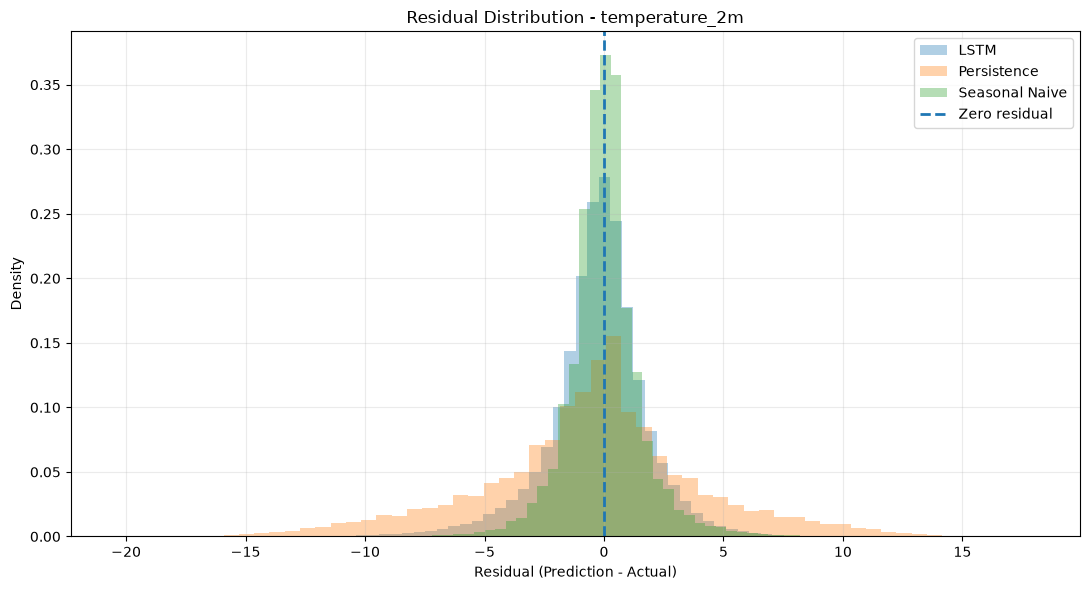

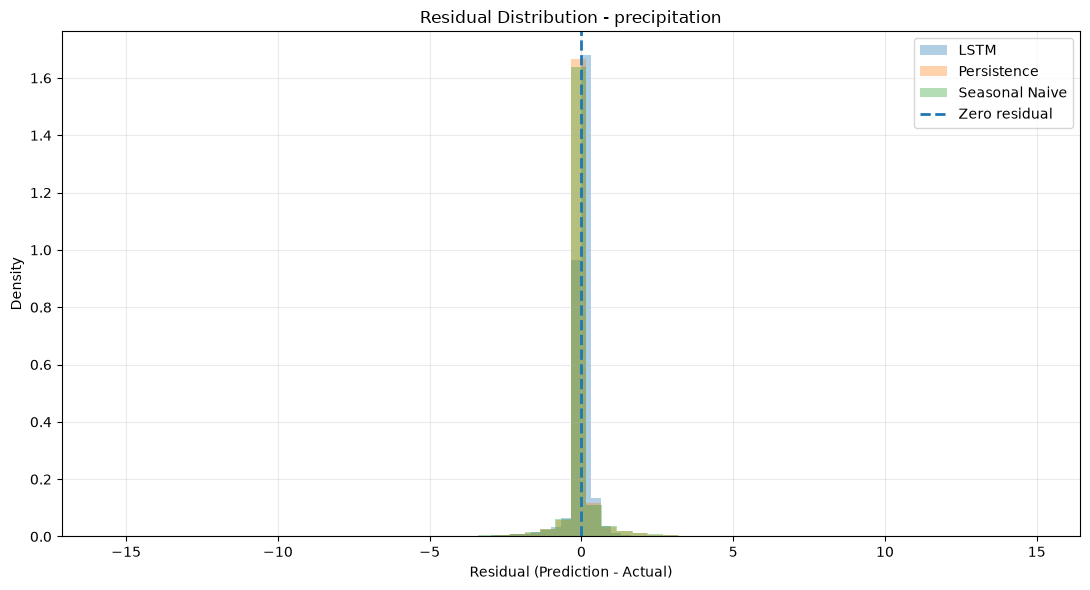

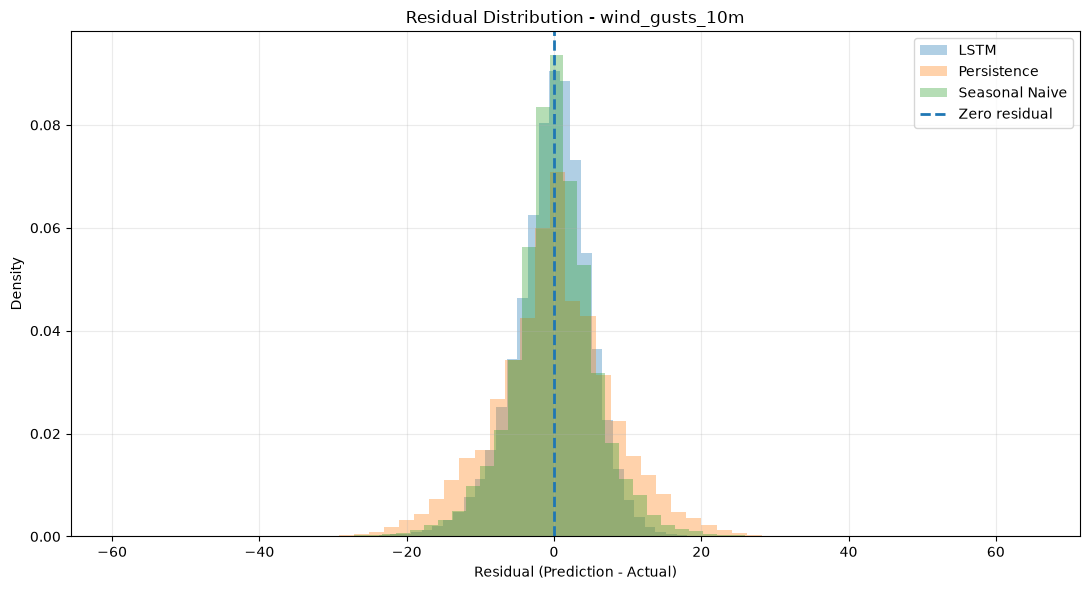

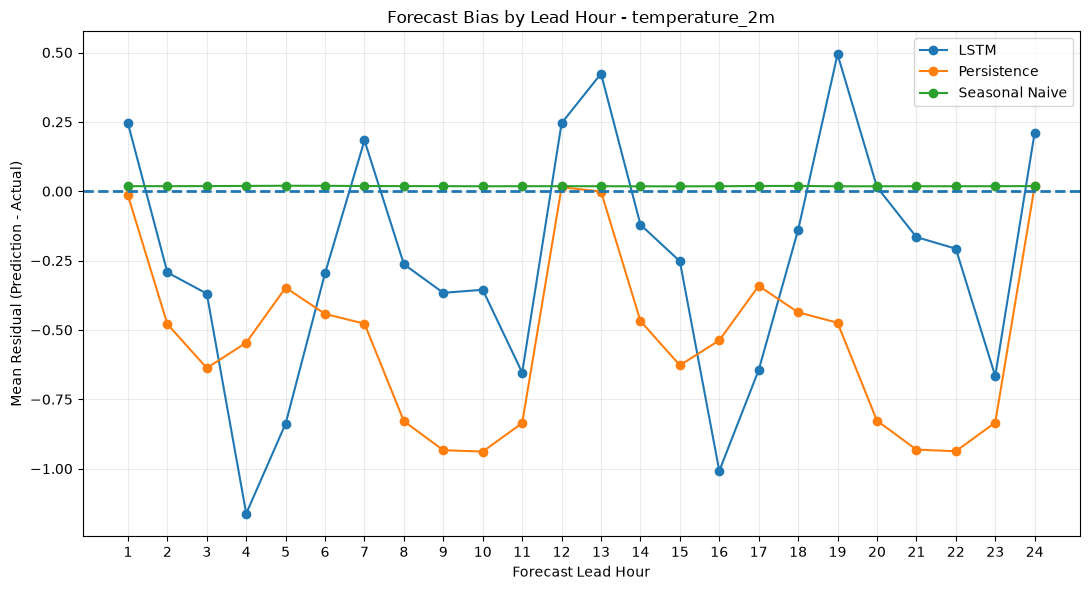

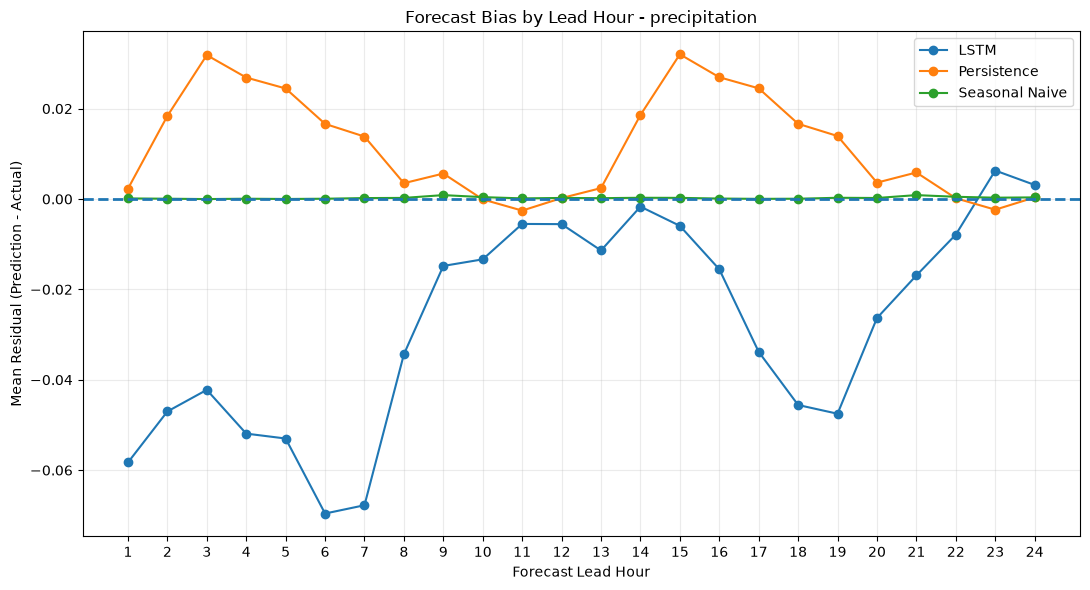

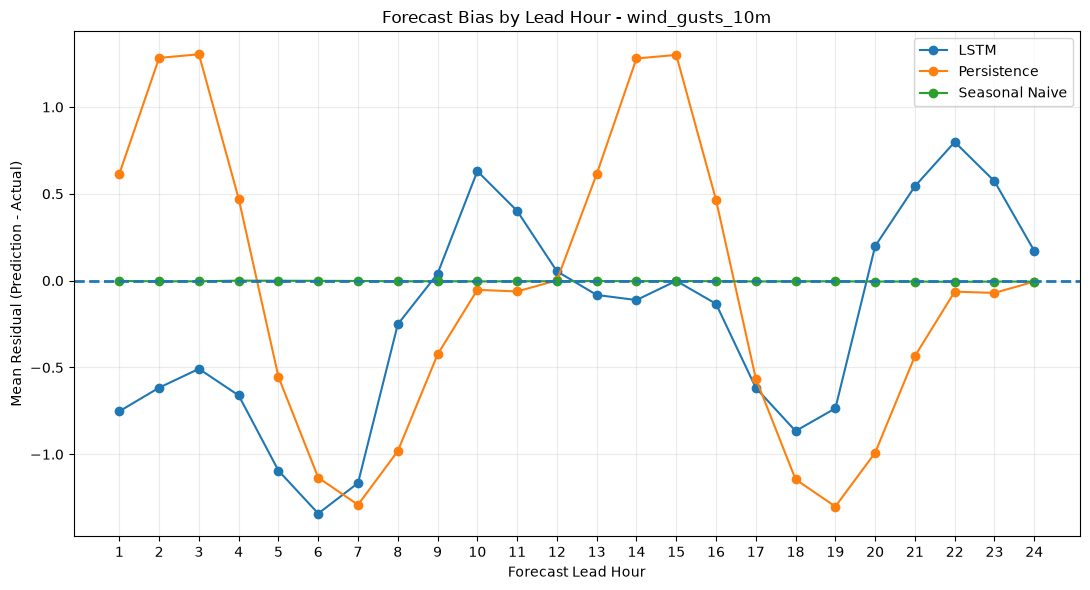

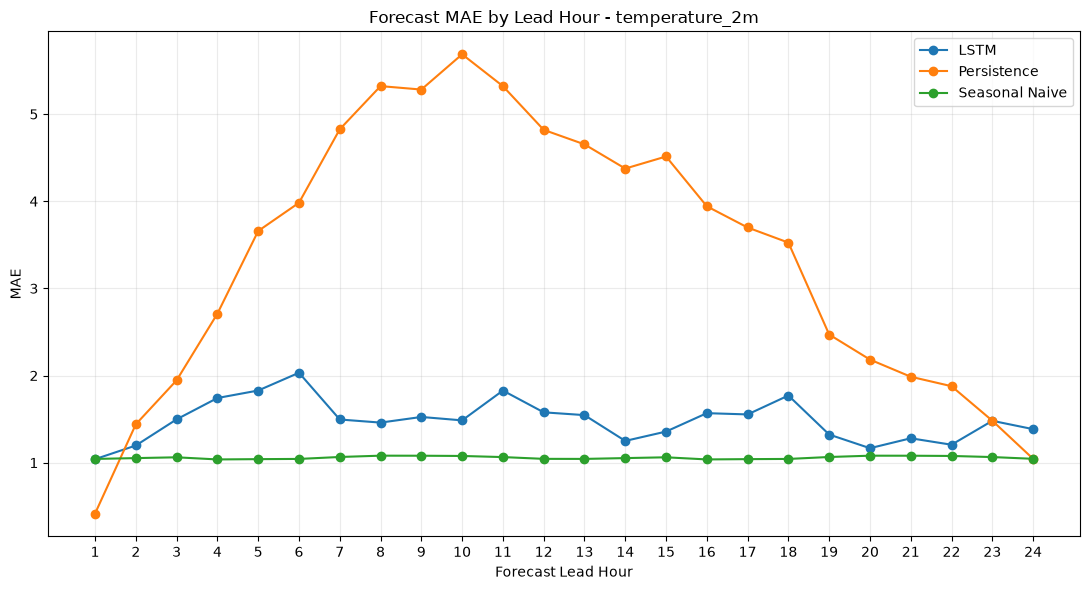

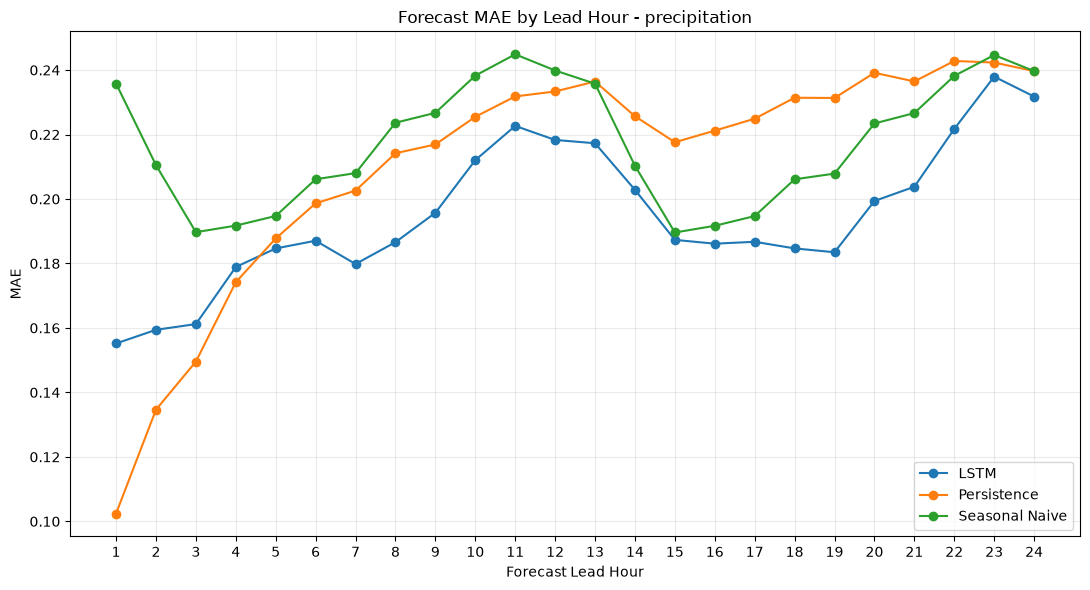

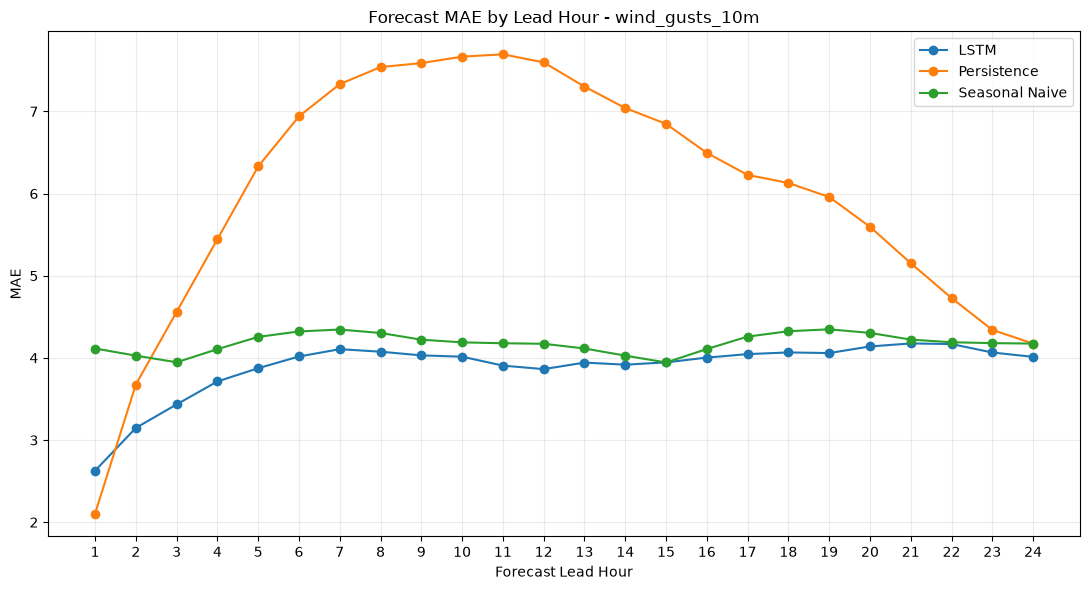


STEP 19.4 COMPLETED SUCCESSFULLY

Valid evaluation records: 252000
Cities: 12
Models: ['LSTM', 'Persistence', 'Seasonal Naive']
Variables: ['temperature_2m', 'precipitation', 'wind_gusts_10m']

Generated CSV files:
- step19_4_overall_residual_summary.csv
- step19_4_city_residual_summary.csv
- step19_4_lead_hour_residual_summary.csv
- step19_4_model_bias_summary.csv

Generated charts:
- Residual distributions: 3
- Mean bias by lead hour: 3
- MAE by lead hour: 3

Output folder: STEP19_4_RESIDUAL_ANALYSIS

RESEARCH CAUTIONS:
1. Positive residual means overprediction.
2. Negative residual means underprediction.
3. Residual patterns do not establish causal explanations.
4. Forecast windows overlap, so records are not independent.
5. Residual analysis is diagnostic, not independent validation.


In [26]:

# ======================================================================
# STEP 19.4 - FORECAST ERROR AND RESIDUAL ANALYSIS
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

print("=" * 75)
print("STEP 19.4 - FORECAST ERROR AND RESIDUAL ANALYSIS")
print("=" * 75)

# ----------------------------------------------------------------------
# 1. LOAD FORECAST PREDICTIONS
# ----------------------------------------------------------------------

INPUT_FILE = os.path.join(
    "STEP17_LSTM_RESULTS",
    "step19_lstm_and_baseline_predictions.csv"
)

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"Prediction file not found: {INPUT_FILE}\n"
        "Check your Jupyter Notebook working directory."
    )

df = pd.read_csv(INPUT_FILE)

print("\n1. DATA LOADED")
print("-" * 40)
print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())

# Normalize column names for matching
column_lookup = {
    str(col).strip().lower(): col
    for col in df.columns
}

def find_column(candidates, description):
    for candidate in candidates:
        key = candidate.lower()
        if key in column_lookup:
            return column_lookup[key]

    raise ValueError(
        f"Could not identify {description}.\n"
        f"Checked: {candidates}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# ----------------------------------------------------------------------
# 2. IDENTIFY REQUIRED COLUMNS
# ----------------------------------------------------------------------

city_col = find_column(
    ["city"],
    "city column"
)

lead_col = find_column(
    [
        "lead_hour",
        "forecast_lead_hour",
        "lead_time_hours",
        "forecast_hour",
        "lead"
    ],
    "forecast lead-hour column"
)

variables = [
    "temperature_2m",
    "precipitation",
    "wind_gusts_10m"
]

models = [
    "LSTM",
    "Persistence",
    "Seasonal Naive"
]

column_map = {}

for variable in variables:

    actual_col = find_column(
        [
            f"actual_{variable}",
            f"{variable}_actual",
            f"y_true_{variable}",
            variable
        ],
        f"actual {variable}"
    )

    lstm_col = find_column(
        [
            f"lstm_{variable}",
            f"{variable}_lstm",
            f"predicted_{variable}",
            f"{variable}_predicted"
        ],
        f"LSTM prediction for {variable}"
    )

    persistence_col = find_column(
        [
            f"persistence_{variable}",
            f"{variable}_persistence"
        ],
        f"Persistence prediction for {variable}"
    )

    seasonal_col = find_column(
        [
            f"seasonal_naive_{variable}",
            f"{variable}_seasonal_naive"
        ],
        f"Seasonal Naive prediction for {variable}"
    )

    column_map[variable] = {
        "Actual": actual_col,
        "LSTM": lstm_col,
        "Persistence": persistence_col,
        "Seasonal Naive": seasonal_col
    }

print("\n2. COLUMN MAPPING")
print("-" * 40)

for variable, mapping in column_map.items():
    print(f"\n{variable}")
    for name, col in mapping.items():
        print(f"  {name}: {col}")

# ----------------------------------------------------------------------
# 3. VALIDATE AND CLEAN REQUIRED EVALUATION FIELDS
# ----------------------------------------------------------------------

required_columns = [city_col, lead_col]

for mapping in column_map.values():
    required_columns.extend(mapping.values())

analysis_df = df[required_columns].copy()

analysis_df[city_col] = analysis_df[city_col].astype(str).str.strip()

analysis_df[lead_col] = pd.to_numeric(
    analysis_df[lead_col],
    errors="coerce"
)

for col in set(required_columns) - {city_col}:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col],
        errors="coerce"
    )

print("\n3. DATA QUALITY CHECK")
print("-" * 40)

print("Missing values in required fields:")
print(analysis_df.isna().sum())

print("\nNon-finite numeric values:")

numeric_columns = [
    col for col in analysis_df.columns
    if col != city_col
]

non_finite_count = (
    ~np.isfinite(analysis_df[numeric_columns])
).sum()

print(non_finite_count)

# Remove rows with missing or non-finite evaluation values
valid_mask = analysis_df[required_columns].notna().all(axis=1)

for col in numeric_columns:
    valid_mask &= np.isfinite(analysis_df[col])

analysis_df = analysis_df.loc[valid_mask].copy()

if analysis_df.empty:
    raise ValueError("No valid evaluation records remain.")

analysis_df[lead_col] = analysis_df[lead_col].astype(int)

print("\nValid evaluation records:", len(analysis_df))
print("Cities:", analysis_df[city_col].nunique())
print("Forecast lead hours:",
      sorted(analysis_df[lead_col].unique()))

# ----------------------------------------------------------------------
# 4. CALCULATE RESIDUAL METRICS
# ----------------------------------------------------------------------

def calculate_residual_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    residual = predicted - actual

    return {
        "records": len(residual),
        "MAE": np.mean(np.abs(residual)),
        "RMSE": np.sqrt(np.mean(residual ** 2)),
        "Mean_Bias": np.mean(residual),
        "Median_Bias": np.median(residual),
        "Residual_STD": np.std(residual, ddof=1)
            if len(residual) > 1 else 0.0,
        "Residual_Q05": np.quantile(residual, 0.05),
        "Residual_Q95": np.quantile(residual, 0.95)
    }

# ----------------------------------------------------------------------
# 5. OVERALL RESIDUAL SUMMARY
# ----------------------------------------------------------------------

overall_rows = []

for variable in variables:

    actual_col = column_map[variable]["Actual"]

    for model in models:

        prediction_col = column_map[variable][model]

        metrics = calculate_residual_metrics(
            analysis_df[actual_col],
            analysis_df[prediction_col]
        )

        overall_rows.append({
            "variable": variable,
            "model": model,
            **metrics
        })

overall_summary = pd.DataFrame(overall_rows)

print("\n4. OVERALL RESIDUAL SUMMARY")
print("-" * 75)
print(overall_summary.round(4).to_string(index=False))

# ----------------------------------------------------------------------
# 6. CITY-WISE RESIDUAL ANALYSIS
# ----------------------------------------------------------------------

city_rows = []

for city, city_data in analysis_df.groupby(city_col):

    for variable in variables:

        actual_col = column_map[variable]["Actual"]

        for model in models:

            prediction_col = column_map[variable][model]

            metrics = calculate_residual_metrics(
                city_data[actual_col],
                city_data[prediction_col]
            )

            city_rows.append({
                "city": city,
                "variable": variable,
                "model": model,
                **metrics
            })

city_summary = pd.DataFrame(city_rows)

print("\n5. CITY-WISE RESIDUAL SUMMARY")
print("-" * 75)

for variable in variables:

    print(f"\n{variable}")
    print(
        city_summary[
            city_summary["variable"] == variable
        ][
            [
                "city", "model", "MAE",
                "RMSE", "Mean_Bias", "records"
            ]
        ].round(4).to_string(index=False)
    )

# ----------------------------------------------------------------------
# 7. LEAD-HOUR RESIDUAL ANALYSIS
# ----------------------------------------------------------------------

lead_rows = []

for lead, lead_data in analysis_df.groupby(lead_col):

    for variable in variables:

        actual_col = column_map[variable]["Actual"]

        for model in models:

            prediction_col = column_map[variable][model]

            metrics = calculate_residual_metrics(
                lead_data[actual_col],
                lead_data[prediction_col]
            )

            lead_rows.append({
                "lead_hour": lead,
                "variable": variable,
                "model": model,
                **metrics
            })

lead_summary = pd.DataFrame(lead_rows)

print("\n6. LEAD-HOUR RESIDUAL ANALYSIS")
print("-" * 75)

for variable in variables:

    print(f"\n{variable}")

    print(
        lead_summary[
            lead_summary["variable"] == variable
        ][
            [
                "lead_hour", "model",
                "MAE", "RMSE", "Mean_Bias", "records"
            ]
        ].round(4).to_string(index=False)
    )

# ----------------------------------------------------------------------
# 8. IDENTIFY OVERPREDICTION AND UNDERPREDICTION
# ----------------------------------------------------------------------

bias_rows = []

for _, row in overall_summary.iterrows():

    if row["Mean_Bias"] > 0:
        direction = "Overprediction"
    elif row["Mean_Bias"] < 0:
        direction = "Underprediction"
    else:
        direction = "No average bias"

    bias_rows.append({
        "variable": row["variable"],
        "model": row["model"],
        "Mean_Bias": row["Mean_Bias"],
        "Bias_Direction": direction
    })

bias_summary = pd.DataFrame(bias_rows)

print("\n7. MODEL BIAS DIRECTION")
print("-" * 60)
print(bias_summary.round(4).to_string(index=False))

# ----------------------------------------------------------------------
# 9. CREATE OUTPUT DIRECTORY
# ----------------------------------------------------------------------

OUTPUT_DIR = "STEP19_4_RESIDUAL_ANALYSIS"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# 10. SAVE SUMMARY FILES
# ----------------------------------------------------------------------

overall_summary.to_csv(
    os.path.join(OUTPUT_DIR, "step19_4_overall_residual_summary.csv"),
    index=False
)

city_summary.to_csv(
    os.path.join(OUTPUT_DIR, "step19_4_city_residual_summary.csv"),
    index=False
)

lead_summary.to_csv(
    os.path.join(OUTPUT_DIR, "step19_4_lead_hour_residual_summary.csv"),
    index=False
)

bias_summary.to_csv(
    os.path.join(OUTPUT_DIR, "step19_4_model_bias_summary.csv"),
    index=False
)

# ----------------------------------------------------------------------
# 11. RESIDUAL DISTRIBUTION CHARTS
# ----------------------------------------------------------------------

for variable in variables:

    actual_col = column_map[variable]["Actual"]

    plt.figure(figsize=(11, 6))

    for model in models:

        prediction_col = column_map[variable][model]

        residual = (
            analysis_df[prediction_col]
            - analysis_df[actual_col]
        )

        plt.hist(
            residual,
            bins=60,
            density=True,
            alpha=0.35,
            label=model
        )

    plt.axvline(
        0,
        linestyle="--",
        linewidth=2,
        label="Zero residual"
    )

    plt.title(f"Residual Distribution - {variable}")
    plt.xlabel("Residual (Prediction - Actual)")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"step19_4_residual_distribution_{variable}.png"
        ),
        dpi=300
    )

    plt.show()
    plt.close()

# ----------------------------------------------------------------------
# 12. MEAN BIAS BY FORECAST LEAD HOUR
# ----------------------------------------------------------------------

for variable in variables:

    plot_data = lead_summary[
        lead_summary["variable"] == variable
    ]

    plt.figure(figsize=(11, 6))

    for model in models:

        model_data = plot_data[
            plot_data["model"] == model
        ].sort_values("lead_hour")

        plt.plot(
            model_data["lead_hour"],
            model_data["Mean_Bias"],
            marker="o",
            label=model
        )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=2
    )

    plt.title(f"Forecast Bias by Lead Hour - {variable}")
    plt.xlabel("Forecast Lead Hour")
    plt.ylabel("Mean Residual (Prediction - Actual)")
    plt.xticks(sorted(analysis_df[lead_col].unique()))
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"step19_4_bias_by_lead_{variable}.png"
        ),
        dpi=300
    )

    plt.show()
    plt.close()

# ----------------------------------------------------------------------
# 13. MAE BY FORECAST LEAD HOUR
# ----------------------------------------------------------------------

for variable in variables:

    plot_data = lead_summary[
        lead_summary["variable"] == variable
    ]

    plt.figure(figsize=(11, 6))

    for model in models:

        model_data = plot_data[
            plot_data["model"] == model
        ].sort_values("lead_hour")

        plt.plot(
            model_data["lead_hour"],
            model_data["MAE"],
            marker="o",
            label=model
        )

    plt.title(f"Forecast MAE by Lead Hour - {variable}")
    plt.xlabel("Forecast Lead Hour")
    plt.ylabel("MAE")
    plt.xticks(sorted(analysis_df[lead_col].unique()))
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"step19_4_mae_by_lead_{variable}.png"
        ),
        dpi=300
    )

    plt.show()
    plt.close()

# ----------------------------------------------------------------------
# 14. FINAL VALIDATION
# ----------------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 19.4 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nValid evaluation records:", len(analysis_df))
print("Cities:", analysis_df[city_col].nunique())
print("Models:", models)
print("Variables:", variables)

print("\nGenerated CSV files:")
for filename in [
    "step19_4_overall_residual_summary.csv",
    "step19_4_city_residual_summary.csv",
    "step19_4_lead_hour_residual_summary.csv",
    "step19_4_model_bias_summary.csv"
]:
    print("-", filename)

print("\nGenerated charts:")
print("- Residual distributions: 3")
print("- Mean bias by lead hour: 3")
print("- MAE by lead hour: 3")

print("\nOutput folder:", OUTPUT_DIR)

print("\nRESEARCH CAUTIONS:")
print("1. Positive residual means overprediction.")
print("2. Negative residual means underprediction.")
print("3. Residual patterns do not establish causal explanations.")
print("4. Forecast windows overlap, so records are not independent.")
print("5. Residual analysis is diagnostic, not independent validation.")

print("=" * 75)


STEP 19.5 TO STEP 19.8 - FINAL FORECAST ANALYSIS

INPUT FILE
---------------------------------------------------------------------------
File: C:\Users\admin\STEP17_LSTM_RESULTS\step19_lstm_and_baseline_predictions.csv
Dataset shape: (252000, 17)

COLUMN VALIDATION: PASS

DATA VALIDATION
---------------------------------------------------------------------------
Original records: 252000
Valid records: 252000
Removed invalid records: 0
Cities: 12
Forecast lead range: 1 to 24
Missing values: 0

MODEL CONFIGURATION READY

STEP 19.5 - RAINFALL THRESHOLD AND CLIPPING ANALYSIS

19.5.1 RAINFALL THRESHOLD SENSITIVITY
         model  actual_wet_threshold_mm  prediction_threshold_mm  accuracy  precision  recall     F1  false_alarm_ratio    CSI  actual_wet_count  predicted_wet_count
          LSTM                      0.1                     0.05    0.6821     0.4011  0.8694 0.5489             0.5989 0.3783             56069               121534
          LSTM                      0.1            

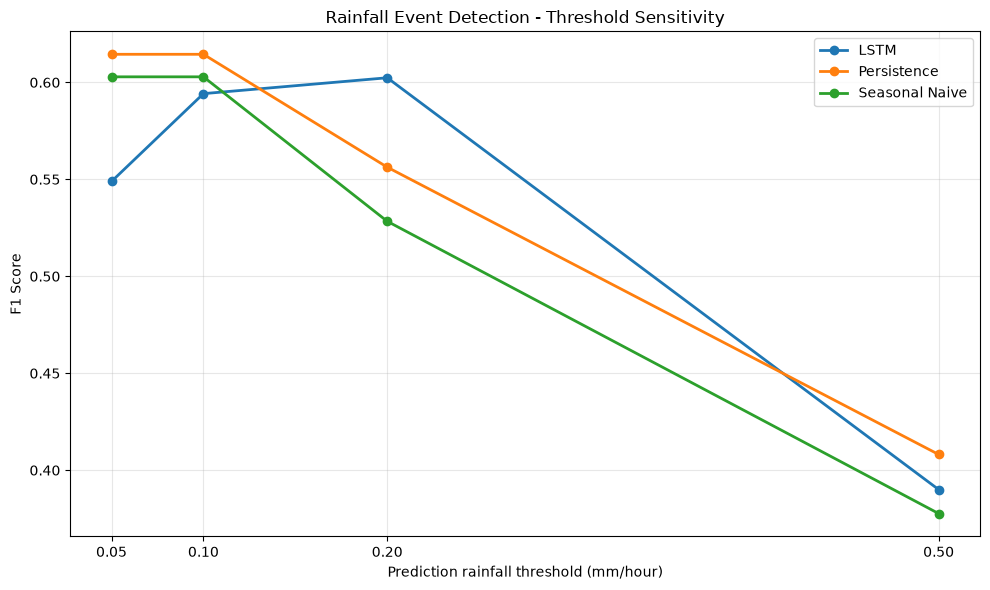

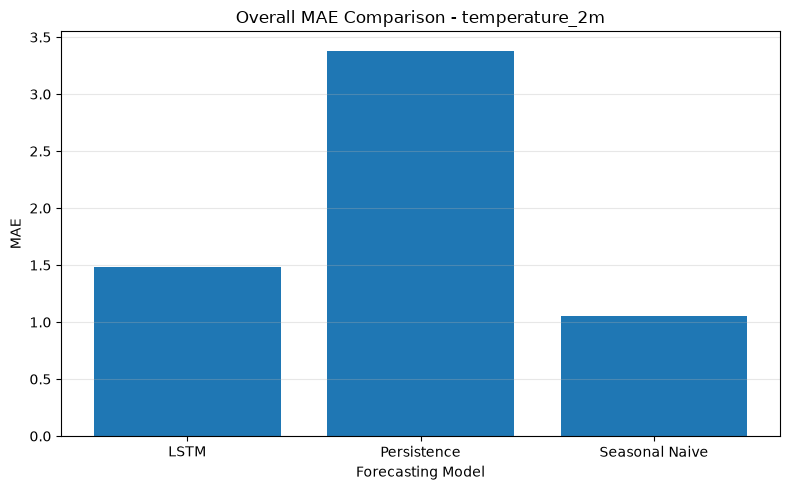

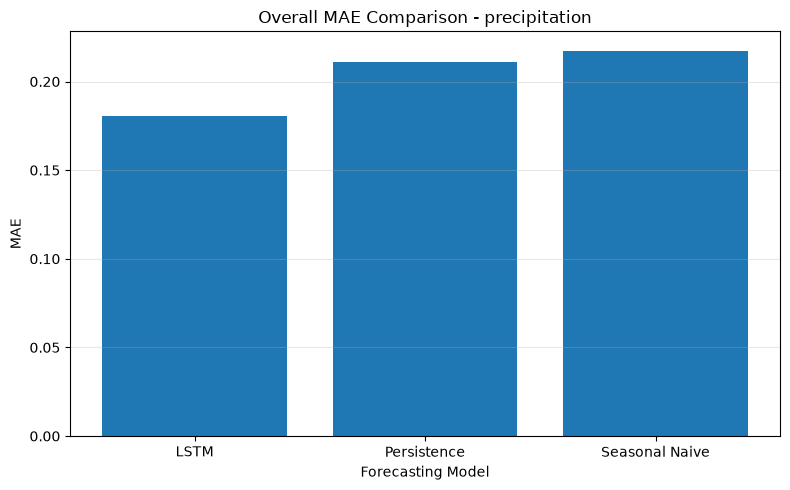

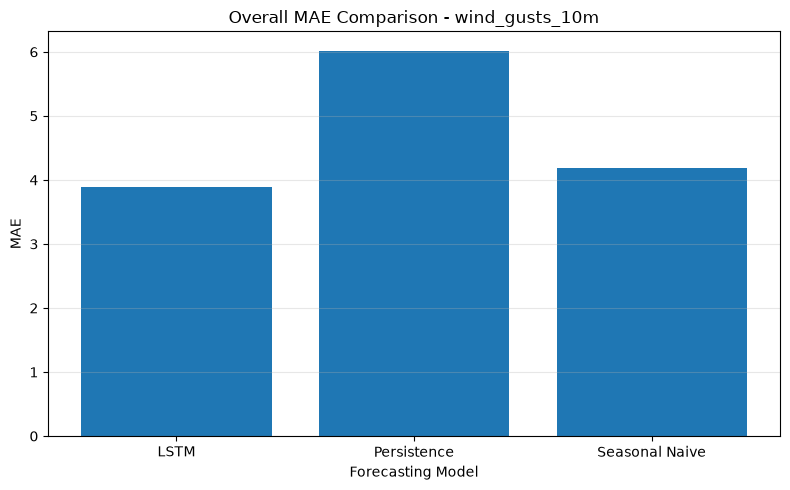

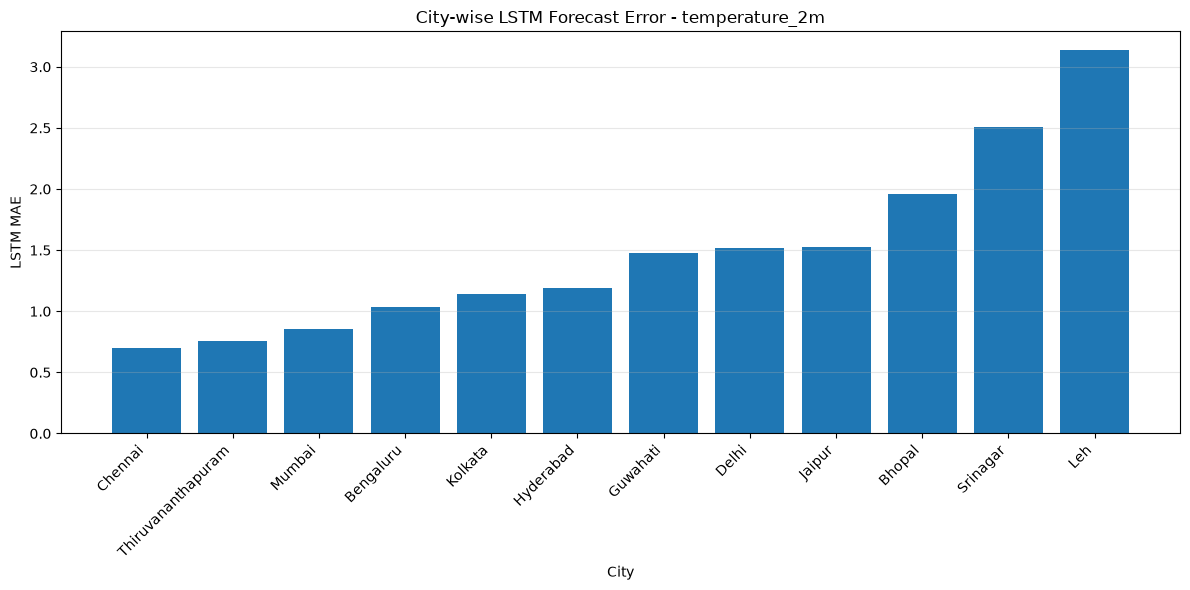

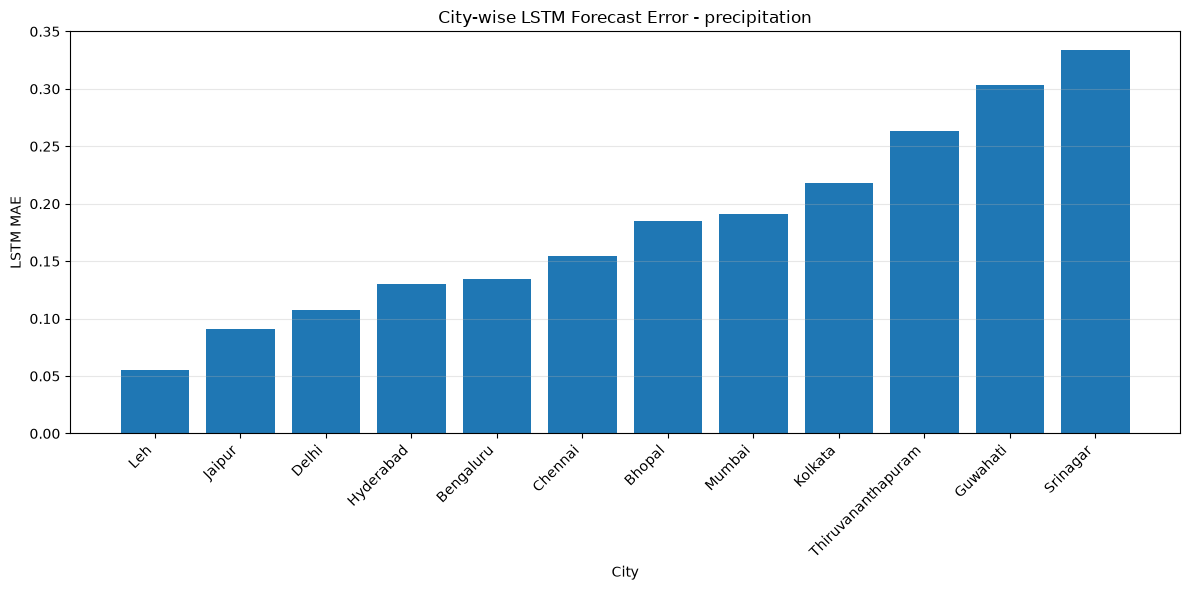

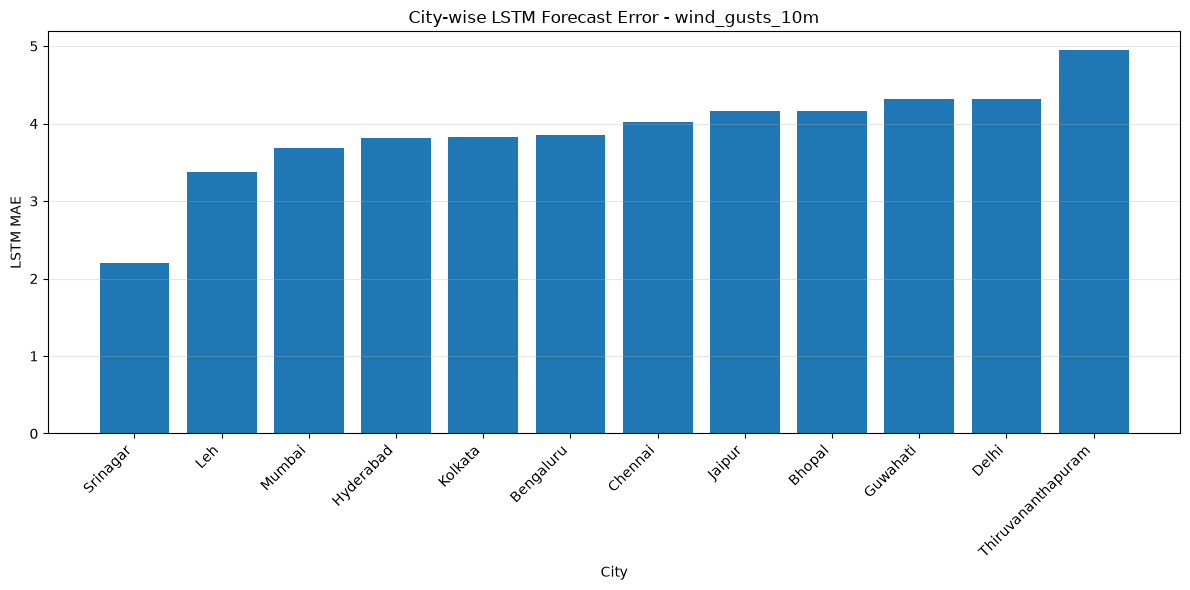

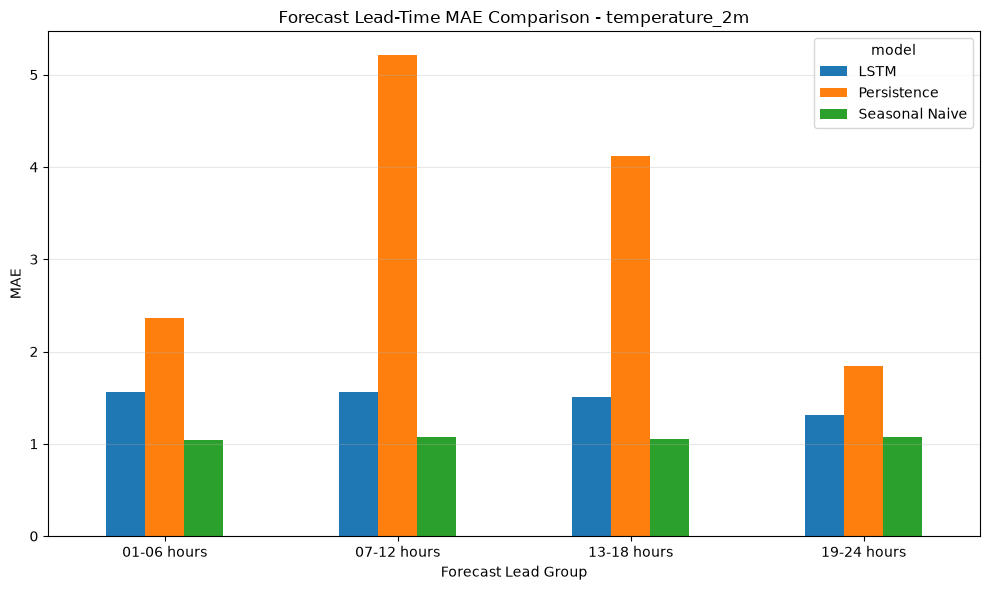

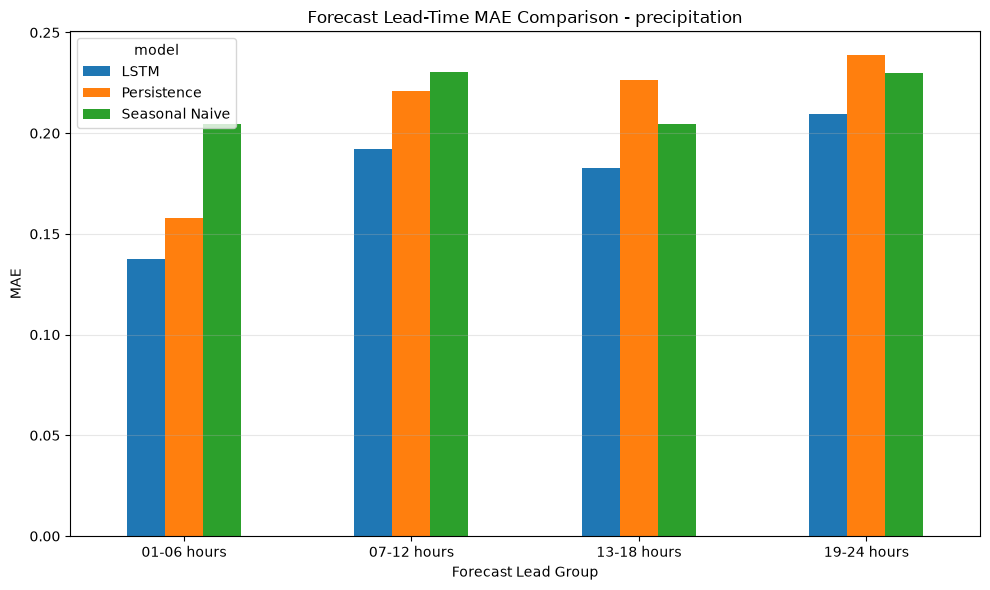

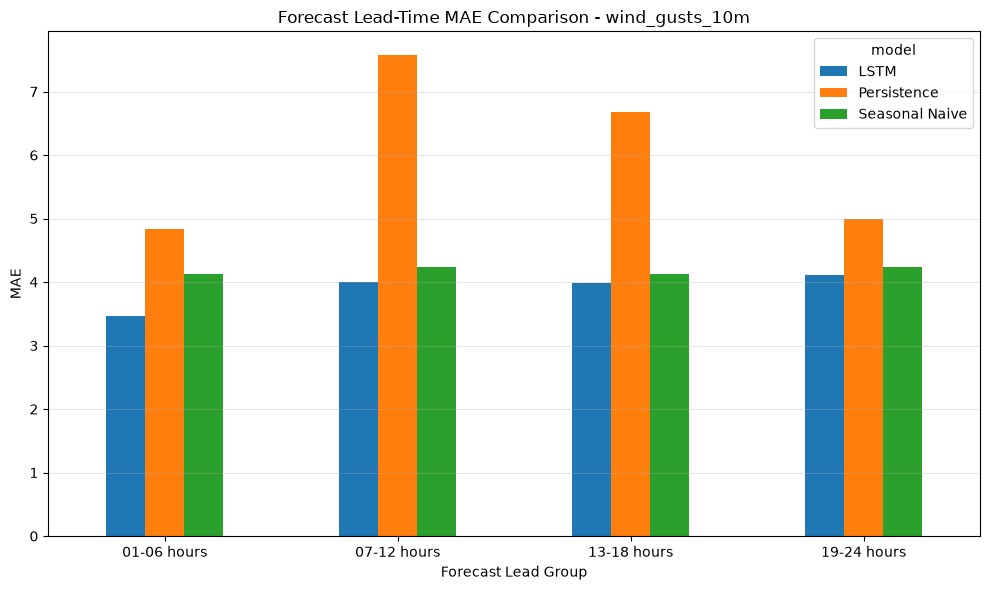


FINAL OUTPUT VALIDATION
Output directory: C:\Users\admin\STEP19_5_TO_19_8_FINAL_OUTPUTS

CSV FILES: 12
   step19_5_rainfall_confusion_matrices.csv
   step19_5_rainfall_raw_vs_clipped_metrics.csv
   step19_5_rainfall_threshold_sensitivity.csv
   step19_5_rainfall_wet_hour_metrics.csv
   step19_6_city_model_metrics.csv
   step19_6_lstm_skill_vs_baselines.csv
   step19_6_overall_model_metrics.csv
   step19_7_final_city_comparison.csv
   step19_7_final_lead_group_comparison.csv
   step19_7_final_overall_comparison.csv
   step19_7_final_rainfall_event_comparison.csv
   step19_8_research_summary.csv

CHART FILES: 10
   step19_8_city_wise_lstm_mae_precipitation.png
   step19_8_city_wise_lstm_mae_temperature_2m.png
   step19_8_city_wise_lstm_mae_wind_gusts_10m.png
   step19_8_lead_group_mae_precipitation.png
   step19_8_lead_group_mae_temperature_2m.png
   step19_8_lead_group_mae_wind_gusts_10m.png
   step19_8_overall_mae_precipitation.png
   step19_8_overall_mae_temperature_2m.png
   step19_

In [27]:

# ======================================================================
# MSc RESEARCH PROJECT
# EXTREME WEATHER & MICRO-CLIMATE ANOMALY EARLY WARNING SYSTEM
#
# STEP 19.5 TO STEP 19.8 - COMPLETE FINAL ANALYSIS
#
# Step 19.5: Rainfall threshold sensitivity and non-negative predictions
# Step 19.6: LSTM vs baseline performance evaluation
# Step 19.7: Final overall, city-wise and lead-time comparison
# Step 19.8: Research outputs, charts and final summary
#
# INPUT:
# step19_lstm_and_baseline_predictions.csv
#
# OUTPUT:
# STEP19_5_TO_19_8_FINAL_OUTPUTS/
#
# IMPORTANT:
# - Does not retrain the LSTM.
# - Does not tune thresholds using test data.
# - Rainfall thresholds are exploratory sensitivity analyses.
# - Test-set results are evaluation results, not operational validation.
# ======================================================================


# ======================================================================
# 1. IMPORT LIBRARIES
# ======================================================================

import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")

print("=" * 75)
print("STEP 19.5 TO STEP 19.8 - FINAL FORECAST ANALYSIS")
print("=" * 75)


# ======================================================================
# 2. FIND AND LOAD INPUT DATA
# ======================================================================

FILE_NAME = "step19_lstm_and_baseline_predictions.csv"

possible_paths = [
    Path("STEP17_LSTM_RESULTS") / FILE_NAME,
    Path(FILE_NAME),
]

input_file = None

for path in possible_paths:
    if path.exists():
        input_file = path
        break

if input_file is None:
    raise FileNotFoundError(
        f"\nCould not find {FILE_NAME}.\n"
        "Place this script in your main project folder, or make sure "
        "the CSV exists inside STEP17_LSTM_RESULTS."
    )

df = pd.read_csv(input_file)

print("\nINPUT FILE")
print("-" * 75)
print("File:", input_file.resolve())
print("Dataset shape:", df.shape)


# ======================================================================
# 3. VALIDATE REQUIRED COLUMNS
# ======================================================================

required_columns = [
    "city",
    "forecast_origin",
    "target_time",
    "forecast_lead_hour",

    "actual_temperature_2m",
    "predicted_temperature_2m",
    "persistence_temperature_2m",
    "seasonal_naive_temperature_2m",

    "actual_precipitation",
    "predicted_precipitation",
    "persistence_precipitation",
    "seasonal_naive_precipitation",

    "actual_wind_gusts_10m",
    "predicted_wind_gusts_10m",
    "persistence_wind_gusts_10m",
    "seasonal_naive_wind_gusts_10m"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required columns:\n" + str(missing_columns)
    )

print("\nCOLUMN VALIDATION: PASS")


# ======================================================================
# 4. DATA CLEANING AND PREPARATION
# ======================================================================

original_count = len(df)

df["forecast_origin"] = pd.to_datetime(
    df["forecast_origin"], errors="coerce"
)

df["target_time"] = pd.to_datetime(
    df["target_time"], errors="coerce"
)

numeric_columns = [
    col for col in required_columns
    if col not in [
        "city",
        "forecast_origin",
        "target_time"
    ]
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(subset=required_columns).copy()

removed_count = original_count - len(df)

if df.empty:
    raise ValueError("No valid records remain after data validation.")

df["forecast_lead_hour"] = (
    df["forecast_lead_hour"].astype(int)
)

df["city"] = df["city"].astype(str)

df = df.sort_values(
    ["city", "forecast_origin", "forecast_lead_hour"]
).reset_index(drop=True)

print("\nDATA VALIDATION")
print("-" * 75)
print("Original records:", original_count)
print("Valid records:", len(df))
print("Removed invalid records:", removed_count)
print("Cities:", df["city"].nunique())
print("Forecast lead range:",
      df["forecast_lead_hour"].min(),
      "to",
      df["forecast_lead_hour"].max())
print("Missing values:", int(df[required_columns].isna().sum().sum()))


# ======================================================================
# 5. DEFINE MODEL AND VARIABLE CONFIGURATIONS
# ======================================================================

models = [
    "LSTM",
    "Persistence",
    "Seasonal Naive"
]

variables = {
    "temperature_2m": {
        "actual": "actual_temperature_2m",
        "LSTM": "predicted_temperature_2m",
        "Persistence": "persistence_temperature_2m",
        "Seasonal Naive": "seasonal_naive_temperature_2m",
        "unit": "°C"
    },

    "precipitation": {
        "actual": "actual_precipitation",
        "LSTM": "predicted_precipitation",
        "Persistence": "persistence_precipitation",
        "Seasonal Naive": "seasonal_naive_precipitation",
        "unit": "mm/hour"
    },

    "wind_gusts_10m": {
        "actual": "actual_wind_gusts_10m",
        "LSTM": "predicted_wind_gusts_10m",
        "Persistence": "persistence_wind_gusts_10m",
        "Seasonal Naive": "seasonal_naive_wind_gusts_10m",
        "unit": "km/h"
    }
}

# Create physically non-negative rainfall prediction columns.
# Actual rainfall is not modified.

for model in models:
    source_col = variables["precipitation"][model]

    clipped_col = f"{source_col}_nonnegative"

    df[clipped_col] = df[source_col].clip(lower=0)

print("\nMODEL CONFIGURATION READY")


# ======================================================================
# STEP 19.5
# RAINFALL THRESHOLD SENSITIVITY AND NON-NEGATIVE PREDICTIONS
# ======================================================================

print("\n" + "=" * 75)
print("STEP 19.5 - RAINFALL THRESHOLD AND CLIPPING ANALYSIS")
print("=" * 75)

ACTUAL_WET_THRESHOLD = 0.1

PREDICTION_THRESHOLDS = [
    0.05,
    0.10,
    0.20,
    0.50
]

actual_rain = df["actual_precipitation"].to_numpy()

actual_wet = (
    actual_rain >= ACTUAL_WET_THRESHOLD
).astype(int)

threshold_results = []
confusion_results = []
rainfall_regression_results = []
wet_hour_results = []

for model in models:

    original_prediction_col = variables["precipitation"][model]
    clipped_prediction_col = (
        original_prediction_col + "_nonnegative"
    )

    raw_prediction = df[
        original_prediction_col
    ].to_numpy()

    clipped_prediction = df[
        clipped_prediction_col
    ].to_numpy()

    # --------------------------------------------------------------
    # 19.5.1 RAW VS CLIPPED RAINFALL REGRESSION
    # --------------------------------------------------------------

    for version, prediction in [
        ("Raw", raw_prediction),
        ("Non-negative clipped", clipped_prediction)
    ]:

        rainfall_regression_results.append({
            "model": model,
            "prediction_version": version,
            "MAE": mean_absolute_error(
                actual_rain, prediction
            ),
            "RMSE": np.sqrt(
                mean_squared_error(actual_rain, prediction)
            ),
            "R2": r2_score(actual_rain, prediction),
            "Bias": np.mean(prediction - actual_rain),
            "Negative_prediction_count": int(
                np.sum(prediction < 0)
            )
        })

    # --------------------------------------------------------------
    # 19.5.2 WET-HOUR REGRESSION
    # --------------------------------------------------------------

    wet_mask = actual_rain >= ACTUAL_WET_THRESHOLD

    if wet_mask.sum() > 0:

        wet_actual = actual_rain[wet_mask]
        wet_predicted = clipped_prediction[wet_mask]

        wet_hour_results.append({
            "model": model,
            "wet_hour_count": int(wet_mask.sum()),
            "MAE": mean_absolute_error(
                wet_actual, wet_predicted
            ),
            "RMSE": np.sqrt(
                mean_squared_error(wet_actual, wet_predicted)
            ),
            "Bias": np.mean(wet_predicted - wet_actual)
        })

    # --------------------------------------------------------------
    # 19.5.3 RAINFALL EVENT THRESHOLD SENSITIVITY
    # Actual wet threshold remains fixed at 0.1 mm/hour.
    # Prediction thresholds are varied for sensitivity analysis.
    # --------------------------------------------------------------

    for prediction_threshold in PREDICTION_THRESHOLDS:

        predicted_wet = (
            clipped_prediction >= prediction_threshold
        ).astype(int)

        accuracy = accuracy_score(
            actual_wet, predicted_wet
        )

        precision = precision_score(
            actual_wet,
            predicted_wet,
            zero_division=0
        )

        recall = recall_score(
            actual_wet,
            predicted_wet,
            zero_division=0
        )

        f1 = f1_score(
            actual_wet,
            predicted_wet,
            zero_division=0
        )

        tn, fp, fn, tp = confusion_matrix(
            actual_wet,
            predicted_wet,
            labels=[0, 1]
        ).ravel()

        false_alarm_ratio = (
            fp / (fp + tp)
            if (fp + tp) > 0 else 0
        )

        csi_denominator = tp + fp + fn

        csi = (
            tp / csi_denominator
            if csi_denominator > 0 else 0
        )

        threshold_results.append({
            "model": model,
            "actual_wet_threshold_mm": ACTUAL_WET_THRESHOLD,
            "prediction_threshold_mm": prediction_threshold,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "F1": f1,
            "false_alarm_ratio": false_alarm_ratio,
            "CSI": csi,
            "actual_wet_count": int(actual_wet.sum()),
            "predicted_wet_count": int(predicted_wet.sum())
        })

        confusion_results.append({
            "model": model,
            "prediction_threshold_mm": prediction_threshold,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })


step195_threshold_df = pd.DataFrame(threshold_results)
step195_confusion_df = pd.DataFrame(confusion_results)

step195_regression_df = pd.DataFrame(
    rainfall_regression_results
)

step195_wet_df = pd.DataFrame(wet_hour_results)

print("\n19.5.1 RAINFALL THRESHOLD SENSITIVITY")
print(step195_threshold_df.round(4).to_string(index=False))

print("\n19.5.2 RAW VS NON-NEGATIVE RAINFALL REGRESSION")
print(step195_regression_df.round(4).to_string(index=False))

print("\n19.5.3 WET-HOUR REGRESSION")
print(step195_wet_df.round(4).to_string(index=False))


# ======================================================================
# STEP 19.6
# OVERALL AND CITY-WISE MODEL PERFORMANCE
# ======================================================================

print("\n" + "=" * 75)
print("STEP 19.6 - MODEL PERFORMANCE EVALUATION")
print("=" * 75)


def calculate_regression_metrics(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted),
        "Bias": np.mean(predicted - actual)
    }


overall_metrics = []
city_metrics = []

for variable, config in variables.items():

    actual_col = config["actual"]

    actual = df[actual_col].to_numpy()

    for model in models:

        if variable == "precipitation":
            prediction_col = (
                config[model] + "_nonnegative"
            )
        else:
            prediction_col = config[model]

        predicted = df[prediction_col].to_numpy()

        metric_values = calculate_regression_metrics(
            actual, predicted
        )

        overall_metrics.append({
            "variable": variable,
            "model": model,
            "unit": config["unit"],
            "records": len(df),
            **metric_values
        })

        # City-wise metrics
        for city, city_data in df.groupby("city"):

            city_actual = city_data[
                actual_col
            ].to_numpy()

            city_predicted = city_data[
                prediction_col
            ].to_numpy()

            city_metric_values = calculate_regression_metrics(
                city_actual,
                city_predicted
            )

            city_metrics.append({
                "city": city,
                "variable": variable,
                "model": model,
                "records": len(city_data),
                **city_metric_values
            })


step196_overall_df = pd.DataFrame(overall_metrics)
step196_city_df = pd.DataFrame(city_metrics)

print("\n19.6.1 OVERALL MODEL METRICS")
print(step196_overall_df.round(4).to_string(index=False))

print("\n19.6.2 CITY-WISE MODEL METRICS")
print(step196_city_df.round(4).to_string(index=False))


# ======================================================================
# 19.6.3 LSTM SKILL RELATIVE TO BASELINES
# Positive skill means LSTM has lower MAE than the baseline.
# Negative skill means the baseline has lower MAE.
# ======================================================================

skill_results = []

for variable in variables:

    subset = step196_overall_df[
        step196_overall_df["variable"] == variable
    ]

    lstm_mae = subset.loc[
        subset["model"] == "LSTM", "MAE"
    ].iloc[0]

    for baseline in ["Persistence", "Seasonal Naive"]:

        baseline_mae = subset.loc[
            subset["model"] == baseline, "MAE"
        ].iloc[0]

        skill = (
            (baseline_mae - lstm_mae) / baseline_mae * 100
            if baseline_mae != 0 else np.nan
        )

        skill_results.append({
            "variable": variable,
            "LSTM_MAE": lstm_mae,
            "baseline": baseline,
            "baseline_MAE": baseline_mae,
            "LSTM_skill_percentage": skill
        })


step196_skill_df = pd.DataFrame(skill_results)

print("\n19.6.3 LSTM SKILL VS BASELINES")
print(step196_skill_df.round(4).to_string(index=False))


# ======================================================================
# STEP 19.7
# FINAL OVERALL, CITY-WISE AND LEAD-TIME COMPARISON
# ======================================================================

print("\n" + "=" * 75)
print("STEP 19.7 - FINAL COMPARISON")
print("=" * 75)


# ----------------------------------------------------------------------
# 19.7.1 FINAL OVERALL COMPARISON
# ----------------------------------------------------------------------

final_overall_df = step196_overall_df.copy()

final_overall_df["MAE_rank_within_variable"] = (
    final_overall_df.groupby("variable")["MAE"]
    .rank(method="min", ascending=True)
)

final_overall_df["RMSE_rank_within_variable"] = (
    final_overall_df.groupby("variable")["RMSE"]
    .rank(method="min", ascending=True)
)

print("\n19.7.1 FINAL OVERALL COMPARISON")
print(final_overall_df.round(4).to_string(index=False))


# ----------------------------------------------------------------------
# 19.7.2 FINAL CITY-WISE COMPARISON
# ----------------------------------------------------------------------

final_city_df = step196_city_df.copy()

final_city_df["MAE_rank_within_city_variable"] = (
    final_city_df.groupby(["city", "variable"])["MAE"]
    .rank(method="min", ascending=True)
)

print("\n19.7.2 CITY-WISE MAE RANKING")
print(
    final_city_df[
        [
            "city",
            "variable",
            "model",
            "MAE",
            "RMSE",
            "R2",
            "MAE_rank_within_city_variable"
        ]
    ].round(4).to_string(index=False)
)


# ----------------------------------------------------------------------
# 19.7.3 FORECAST LEAD GROUP COMPARISON
# ----------------------------------------------------------------------

def assign_lead_group(hour):

    if 1 <= hour <= 6:
        return "01-06 hours"

    elif 7 <= hour <= 12:
        return "07-12 hours"

    elif 13 <= hour <= 18:
        return "13-18 hours"

    elif 19 <= hour <= 24:
        return "19-24 hours"

    else:
        return "Outside 1-24 hours"


df["lead_group"] = df[
    "forecast_lead_hour"
].apply(assign_lead_group)

lead_results = []

lead_groups = [
    "01-06 hours",
    "07-12 hours",
    "13-18 hours",
    "19-24 hours"
]

for variable, config in variables.items():

    actual_col = config["actual"]

    for lead_group in lead_groups:

        group_data = df[
            df["lead_group"] == lead_group
        ]

        if group_data.empty:
            continue

        actual = group_data[
            actual_col
        ].to_numpy()

        for model in models:

            if variable == "precipitation":
                prediction_col = (
                    config[model] + "_nonnegative"
                )
            else:
                prediction_col = config[model]

            predicted = group_data[
                prediction_col
            ].to_numpy()

            metric_values = calculate_regression_metrics(
                actual, predicted
            )

            lead_results.append({
                "variable": variable,
                "lead_group": lead_group,
                "model": model,
                "records": len(group_data),
                **metric_values
            })


final_lead_df = pd.DataFrame(lead_results)

print("\n19.7.3 FORECAST LEAD GROUP COMPARISON")
print(final_lead_df.round(4).to_string(index=False))


# ----------------------------------------------------------------------
# 19.7.4 FINAL RAINFALL EVENT COMPARISON
# Fixed exploratory threshold: 0.1 mm/hour
# ----------------------------------------------------------------------

rainfall_event_results = []

for model in models:

    prediction_col = (
        variables["precipitation"][model] +
        "_nonnegative"
    )

    predicted_rain = df[
        prediction_col
    ].to_numpy()

    predicted_wet = (
        predicted_rain >= ACTUAL_WET_THRESHOLD
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual_wet,
        predicted_wet,
        labels=[0, 1]
    ).ravel()

    rainfall_event_results.append({
        "model": model,
        "threshold_mm_per_hour": ACTUAL_WET_THRESHOLD,
        "accuracy": accuracy_score(
            actual_wet, predicted_wet
        ),
        "precision": precision_score(
            actual_wet, predicted_wet,
            zero_division=0
        ),
        "recall": recall_score(
            actual_wet, predicted_wet,
            zero_division=0
        ),
        "F1": f1_score(
            actual_wet, predicted_wet,
            zero_division=0
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })


final_rainfall_event_df = pd.DataFrame(
    rainfall_event_results
)

print("\n19.7.4 FINAL RAINFALL EVENT COMPARISON")
print(final_rainfall_event_df.round(4).to_string(index=False))


# ======================================================================
# STEP 19.8
# FINAL OUTPUT EXPORT AND RESEARCH SUMMARY
# ======================================================================

print("\n" + "=" * 75)
print("STEP 19.8 - FINAL OUTPUT EXPORT")
print("=" * 75)

OUTPUT_DIR = Path("STEP19_5_TO_19_8_FINAL_OUTPUTS")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ======================================================================
# 19.8.1 SAVE CSV REPORTS
# ======================================================================

csv_outputs = {
    "step19_5_rainfall_threshold_sensitivity.csv":
        step195_threshold_df,

    "step19_5_rainfall_confusion_matrices.csv":
        step195_confusion_df,

    "step19_5_rainfall_raw_vs_clipped_metrics.csv":
        step195_regression_df,

    "step19_5_rainfall_wet_hour_metrics.csv":
        step195_wet_df,

    "step19_6_overall_model_metrics.csv":
        step196_overall_df,

    "step19_6_city_model_metrics.csv":
        step196_city_df,

    "step19_6_lstm_skill_vs_baselines.csv":
        step196_skill_df,

    "step19_7_final_overall_comparison.csv":
        final_overall_df,

    "step19_7_final_city_comparison.csv":
        final_city_df,

    "step19_7_final_lead_group_comparison.csv":
        final_lead_df,

    "step19_7_final_rainfall_event_comparison.csv":
        final_rainfall_event_df
}

for filename, output_df in csv_outputs.items():

    output_path = OUTPUT_DIR / filename

    output_df.to_csv(
        output_path,
        index=False
    )

    print("Saved:", filename)


# ======================================================================
# 19.8.2 CHART 1 - RAINFALL THRESHOLD SENSITIVITY
# ======================================================================

plt.figure(figsize=(10, 6))

for model in models:

    model_data = step195_threshold_df[
        step195_threshold_df["model"] == model
    ]

    plt.plot(
        model_data["prediction_threshold_mm"],
        model_data["F1"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.xlabel("Prediction rainfall threshold (mm/hour)")
plt.ylabel("F1 Score")
plt.title(
    "Rainfall Event Detection - Threshold Sensitivity"
)
plt.xticks(PREDICTION_THRESHOLDS)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "step19_8_rainfall_threshold_sensitivity.png",
    dpi=300
)

plt.show()
plt.close()


# ======================================================================
# 19.8.3 CHART 2 - OVERALL MAE COMPARISON
# ======================================================================

for variable in variables:

    plot_data = step196_overall_df[
        step196_overall_df["variable"] == variable
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        plot_data["model"],
        plot_data["MAE"]
    )

    plt.xlabel("Forecasting Model")
    plt.ylabel("MAE")
    plt.title(
        f"Overall MAE Comparison - {variable}"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR /
        f"step19_8_overall_mae_{variable}.png",
        dpi=300
    )

    plt.show()
    plt.close()


# ======================================================================
# 19.8.4 CHART 3 - CITY-WISE LSTM MAE
# ======================================================================

for variable in variables:

    plot_data = final_city_df[
        (final_city_df["variable"] == variable) &
        (final_city_df["model"] == "LSTM")
    ].sort_values("MAE")

    plt.figure(figsize=(12, 6))

    plt.bar(
        plot_data["city"],
        plot_data["MAE"]
    )

    plt.xlabel("City")
    plt.ylabel("LSTM MAE")
    plt.title(
        f"City-wise LSTM Forecast Error - {variable}"
    )

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR /
        f"step19_8_city_wise_lstm_mae_{variable}.png",
        dpi=300
    )

    plt.show()
    plt.close()


# ======================================================================
# 19.8.5 CHART 4 - LEAD GROUP MAE
# ======================================================================

for variable in variables:

    plot_data = final_lead_df[
        final_lead_df["variable"] == variable
    ]

    pivot_data = plot_data.pivot(
        index="lead_group",
        columns="model",
        values="MAE"
    )

    pivot_data = pivot_data.reindex(lead_groups)

    plt.figure(figsize=(10, 6))

    pivot_data.plot(
        kind="bar",
        ax=plt.gca()
    )

    plt.xlabel("Forecast Lead Group")
    plt.ylabel("MAE")
    plt.title(
        f"Forecast Lead-Time MAE Comparison - {variable}"
    )

    plt.xticks(rotation=0)
    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR /
        f"step19_8_lead_group_mae_{variable}.png",
        dpi=300
    )

    plt.show()
    plt.close()


# ======================================================================
# 19.8.6 GENERATE RESEARCH SUMMARY
# ======================================================================

summary_lines = []

summary_lines.append(
    "EXTREME WEATHER & MICRO-CLIMATE ANOMALY EARLY WARNING SYSTEM"
)

summary_lines.append(
    "STEP 19.5 TO STEP 19.8 - FINAL FORECAST ANALYSIS"
)

summary_lines.append("=" * 70)

summary_lines.append(
    f"Valid forecast records: {len(df):,}"
)

summary_lines.append(
    f"Number of cities: {df['city'].nunique()}"
)

summary_lines.append(
    f"Forecast lead hours: "
    f"{df['forecast_lead_hour'].min()}-"
    f"{df['forecast_lead_hour'].max()}"
)

summary_lines.append("")

summary_lines.append("OVERALL MODEL PERFORMANCE")

for variable in variables:

    summary_lines.append("")
    summary_lines.append(f"VARIABLE: {variable}")

    subset = final_overall_df[
        final_overall_df["variable"] == variable
    ].sort_values("MAE")

    for _, row in subset.iterrows():

        summary_lines.append(
            f"{row['model']}: "
            f"MAE={row['MAE']:.4f}, "
            f"RMSE={row['RMSE']:.4f}, "
            f"R2={row['R2']:.4f}, "
            f"Bias={row['Bias']:.4f}"
        )

    best_model = subset.iloc[0]["model"]

    summary_lines.append(
        f"Lowest-MAE model for {variable}: {best_model}"
    )


summary_lines.append("")
summary_lines.append("RAINFALL EVENT DETECTION")
summary_lines.append(
    f"Actual wet-hour threshold: {ACTUAL_WET_THRESHOLD} mm/hour"
)

for _, row in final_rainfall_event_df.iterrows():

    summary_lines.append(
        f"{row['model']}: "
        f"Precision={row['precision']:.4f}, "
        f"Recall={row['recall']:.4f}, "
        f"F1={row['F1']:.4f}"
    )


summary_lines.append("")
summary_lines.append("RESEARCH LIMITATIONS AND INTERPRETATION")

summary_lines.append(
    "1. The evaluation uses the reserved test predictions from Step 18."
)

summary_lines.append(
    "2. The LSTM was not retrained during Steps 19.5-19.8."
)

summary_lines.append(
    "3. Non-negative rainfall clipping is a physical post-processing constraint."
)

summary_lines.append(
    "4. Rainfall prediction thresholds are exploratory sensitivity settings, "
    "not independently calibrated warning thresholds."
)

summary_lines.append(
    "5. The 0.1 mm/hour rainfall event threshold is an exploratory "
    "wet-hour definition."
)

summary_lines.append(
    "6. Forecast windows overlap. Therefore, forecast records are not "
    "statistically independent."
)

summary_lines.append(
    "7. These results evaluate forecasting performance and do not establish "
    "operational early-warning capability."
)

summary_lines.append(
    "8. Independent event-based validation and warning lead-time evaluation "
    "are required before operational deployment."
)

summary_text = "\n".join(summary_lines)

summary_path = OUTPUT_DIR / "step19_8_research_summary.txt"

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(summary_text)


# Save a structured summary CSV too.

summary_csv = pd.DataFrame({
    "research_summary": summary_lines
})

summary_csv.to_csv(
    OUTPUT_DIR / "step19_8_research_summary.csv",
    index=False
)


# ======================================================================
# 19.8.7 FINAL OUTPUT VALIDATION
# ======================================================================

print("\n" + "=" * 75)
print("FINAL OUTPUT VALIDATION")
print("=" * 75)

saved_csv_files = list(
    OUTPUT_DIR.glob("*.csv")
)

saved_png_files = list(
    OUTPUT_DIR.glob("*.png")
)

saved_txt_files = list(
    OUTPUT_DIR.glob("*.txt")
)

print("Output directory:", OUTPUT_DIR.resolve())

print("\nCSV FILES:", len(saved_csv_files))

for file in sorted(saved_csv_files):
    print("  ", file.name)

print("\nCHART FILES:", len(saved_png_files))

for file in sorted(saved_png_files):
    print("  ", file.name)

print("\nTEXT FILES:", len(saved_txt_files))

for file in sorted(saved_txt_files):
    print("  ", file.name)


expected_csv_count = len(csv_outputs) + 1

if len(saved_csv_files) < expected_csv_count:
    raise RuntimeError(
        "Output validation failed: expected CSV files are missing."
    )

if len(saved_png_files) < 7:
    raise RuntimeError(
        "Output validation failed: expected charts are missing."
    )

if not summary_path.exists():
    raise RuntimeError(
        "Research summary file was not created."
    )


# ======================================================================
# FINAL COMPLETION MESSAGE
# ======================================================================

print("\n" + "=" * 75)
print("STEP 19.5 TO STEP 19.8 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Input records analysed:", len(df))
print("Cities analysed:", df["city"].nunique())

print("CSV reports created:", len(saved_csv_files))
print("Charts created:", len(saved_png_files))
print("Research summary created:", summary_path.exists())

print("\nALL OUTPUTS ARE SAVED IN:")
print(OUTPUT_DIR.resolve())

print("\nIMPORTANT:")
print(
    "Review the exported metrics and research limitations before "
    "using the results in your dissertation."
)

print("=" * 75)


In [30]:

# ======================================================================
# STEP 20.1 - HAZARD INDICATOR PREPARATION AND WARNING CRITERIA AUDIT
# Extreme Weather & Micro-Climate Anomaly Early Warning System
# ======================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 20.1 - HAZARD INDICATOR PREPARATION")
print("=" * 75)


# ======================================================================
# 1. LOAD FORECAST DATA
# ======================================================================

input_candidates = [
    Path("STEP17_LSTM_RESULTS") /
    "step19_lstm_and_baseline_predictions.csv",
    Path("step19_lstm_and_baseline_predictions.csv")
]

input_file = None

for candidate in input_candidates:
    if candidate.exists():
        input_file = candidate
        break

if input_file is None:
    raise FileNotFoundError(
        "Could not locate step19_lstm_and_baseline_predictions.csv. "
        "Check your main project folder."
    )

forecast_df = pd.read_csv(input_file)

print("\nINPUT VALIDATION")
print("-" * 75)
print("Input file:", input_file.resolve())
print("Dataset shape:", forecast_df.shape)


# ======================================================================
# 2. VALIDATE REQUIRED COLUMNS
# ======================================================================

required_columns = [
    "city",
    "forecast_origin",
    "target_time",
    "forecast_lead_hour",
    "actual_temperature_2m",
    "predicted_temperature_2m",
    "actual_precipitation",
    "predicted_precipitation",
    "actual_wind_gusts_10m",
    "predicted_wind_gusts_10m"
]

missing_columns = [
    col for col in required_columns
    if col not in forecast_df.columns
]

if missing_columns:
    raise ValueError(
        "Required columns missing: " + str(missing_columns)
    )

forecast_df = forecast_df[required_columns].copy()

forecast_df["forecast_origin"] = pd.to_datetime(
    forecast_df["forecast_origin"],
    errors="coerce"
)

forecast_df["target_time"] = pd.to_datetime(
    forecast_df["target_time"],
    errors="coerce"
)

numeric_columns = [
    col for col in required_columns
    if col not in ["city", "forecast_origin", "target_time"]
]

for col in numeric_columns:
    forecast_df[col] = pd.to_numeric(
        forecast_df[col],
        errors="coerce"
    )

forecast_df = forecast_df.replace(
    [np.inf, -np.inf],
    np.nan
)

before_cleaning = len(forecast_df)

forecast_df = forecast_df.dropna(
    subset=required_columns
).copy()

print("Valid records:", len(forecast_df))
print("Removed invalid records:", before_cleaning - len(forecast_df))

if forecast_df.empty:
    raise ValueError("No valid forecast records available.")


# ======================================================================
# 3. CHECK FORECAST WINDOW COMPLETENESS
# ======================================================================

forecast_df["forecast_lead_hour"] = (
    forecast_df["forecast_lead_hour"].astype(int)
)

group_columns = ["city", "forecast_origin"]

window_check = (
    forecast_df.groupby(group_columns)
    .agg(
        record_count=("forecast_lead_hour", "size"),
        unique_leads=("forecast_lead_hour", "nunique"),
        minimum_lead=("forecast_lead_hour", "min"),
        maximum_lead=("forecast_lead_hour", "max")
    )
    .reset_index()
)

window_check["complete_24_hour_window"] = (
    (window_check["record_count"] == 24) &
    (window_check["unique_leads"] == 24) &
    (window_check["minimum_lead"] == 1) &
    (window_check["maximum_lead"] == 24)
)

complete_windows = window_check[
    window_check["complete_24_hour_window"]
].copy()

incomplete_windows = window_check[
    ~window_check["complete_24_hour_window"]
].copy()

print("\nFORECAST WINDOW VALIDATION")
print("-" * 75)
print("Total city-origin windows:", len(window_check))
print("Complete 24-hour windows:", len(complete_windows))
print("Incomplete windows:", len(incomplete_windows))

if complete_windows.empty:
    raise ValueError("No complete 24-hour forecast windows found.")

forecast_df = forecast_df.merge(
    complete_windows[group_columns],
    on=group_columns,
    how="inner"
).copy()


# ======================================================================
# 4. PREPARE NON-NEGATIVE RAINFALL PREDICTIONS
# ======================================================================

forecast_df["predicted_precipitation_nonnegative"] = (
    forecast_df["predicted_precipitation"].clip(lower=0)
)

negative_actual_rain = (
    forecast_df["actual_precipitation"] < 0
)

if negative_actual_rain.any():
    raise ValueError(
        "Negative actual rainfall values found. "
        "Investigate the source data before proceeding."
    )


# ======================================================================
# 5. AGGREGATE EACH 24-HOUR FORECAST WINDOW
# ======================================================================

hazard_features = (
    forecast_df.groupby(group_columns)
    .agg(
        forecast_start=("target_time", "min"),
        forecast_end=("target_time", "max"),
        forecast_hours=("target_time", "nunique"),

        actual_rainfall_24h_mm=(
            "actual_precipitation", "sum"
        ),

        forecast_rainfall_24h_mm=(
            "predicted_precipitation_nonnegative", "sum"
        ),

        actual_max_temperature_c=(
            "actual_temperature_2m", "max"
        ),

        forecast_max_temperature_c=(
            "predicted_temperature_2m", "max"
        ),

        actual_max_wind_gust_kmh=(
            "actual_wind_gusts_10m", "max"
        ),

        forecast_max_wind_gust_kmh=(
            "predicted_wind_gusts_10m", "max"
        )
    )
    .reset_index()
)

print("\nHAZARD FEATURE DATASET")
print("-" * 75)
print("Shape:", hazard_features.shape)
print("Cities:", hazard_features["city"].nunique())
print(
    "Complete forecast hours:",
    hazard_features["forecast_hours"].eq(24).all()
)


# ======================================================================
# 6. APPLY IMD 24-HOUR RAINFALL CATEGORIES
# ======================================================================

def classify_imd_rainfall(rainfall):

    if rainfall >= 204.5:
        return "Extremely Heavy Rain"

    elif rainfall >= 115.6:
        return "Very Heavy Rain"

    elif rainfall >= 64.5:
        return "Heavy Rain"

    elif rainfall >= 15.6:
        return "Moderate Rain"

    elif rainfall >= 2.5:
        return "Light Rain"

    elif rainfall >= 0.1:
        return "Very Light Rain"

    else:
        return "No Measurable Rain"


hazard_features["forecast_rainfall_category"] = (
    hazard_features["forecast_rainfall_24h_mm"]
    .apply(classify_imd_rainfall)
)

hazard_features["actual_rainfall_category"] = (
    hazard_features["actual_rainfall_24h_mm"]
    .apply(classify_imd_rainfall)
)


# ======================================================================
# 7. TEMPERATURE SCREENING
# NOT AN OFFICIAL HEAT-WAVE DECLARATION
# ======================================================================

coastal_cities = [
    "Chennai",
    "Mumbai",
    "Kolkata",
    "Thiruvananthapuram"
]

hill_cities = [
    "Leh",
    "Srinagar"
]


def get_temperature_screening_gate(city):

    if city in hill_cities:
        return 30.0, "Hilly screening category"

    elif city in coastal_cities:
        return 37.0, "Coastal screening category"

    else:
        return 40.0, "Plain screening category"


gates = hazard_features["city"].apply(
    get_temperature_screening_gate
)

hazard_features["temperature_screening_gate_c"] = (
    gates.apply(lambda x: x[0])
)

hazard_features["temperature_screening_category"] = (
    gates.apply(lambda x: x[1])
)

hazard_features["temperature_gate_reached"] = (
    hazard_features["forecast_max_temperature_c"] >=
    hazard_features["temperature_screening_gate_c"]
)

hazard_features["temperature_screening_status"] = np.where(
    hazard_features["temperature_gate_reached"],
    "Temperature gate reached - review required",
    "Temperature gate not reached"
)


# ======================================================================
# 8. WIND GUST SCREENING
# ======================================================================

hazard_features["wind_screening_status"] = (
    "Forecast available - validated warning threshold required"
)


# ======================================================================
# 9. WARNING CRITERIA READINESS AUDIT
# ======================================================================

readiness_rows = [

    {
        "hazard": "Heavy rainfall",
        "required_measurement": "24-hour accumulated rainfall",
        "available_in_project": "Yes - hourly rainfall forecasts",
        "derived_in_step20_1": "Yes",
        "official_criteria_reference": "IMD 24-hour rainfall categories",
        "remaining_requirement": (
            "Independent validation of forecast rainfall "
            "and warning performance"
        ),
        "warning_rule_ready": "Threshold screening only"
    },

    {
        "hazard": "Heat wave",
        "required_measurement": (
            "Daily maximum temperature and departure from normal"
        ),
        "available_in_project": (
            "Hourly temperature forecasts; climatological normals "
            "not confirmed"
        ),
        "derived_in_step20_1": (
            "Maximum-temperature screening proxy only"
        ),
        "official_criteria_reference": "IMD heat-wave criteria",
        "remaining_requirement": (
            "Station-specific climatological normals, "
            "station classification and persistence assessment"
        ),
        "warning_rule_ready": "No - incomplete criteria"
    },

    {
        "hazard": "Strong wind",
        "required_measurement": (
            "Wind gust forecasts and hazard-specific thresholds"
        ),
        "available_in_project": "Yes - wind gust forecasts",
        "derived_in_step20_1": "Yes",
        "official_criteria_reference": (
            "Hazard-specific official threshold still required"
        ),
        "remaining_requirement": (
            "Verified wind warning thresholds and independent validation"
        ),
        "warning_rule_ready": "No - threshold not configured"
    }
]

readiness_df = pd.DataFrame(readiness_rows)


# ======================================================================
# 10. SUMMARY TABLES
# ======================================================================

rainfall_summary = (
    hazard_features.groupby("forecast_rainfall_category")
    .size()
    .reset_index(name="forecast_window_count")
)

temperature_summary = (
    hazard_features.groupby(
        ["city", "temperature_screening_status"]
    )
    .size()
    .reset_index(name="forecast_window_count")
)

city_summary = (
    hazard_features.groupby("city")
    .agg(
        forecast_windows=("forecast_origin", "count"),

        mean_forecast_rainfall_24h=(
            "forecast_rainfall_24h_mm", "mean"
        ),

        maximum_forecast_rainfall_24h=(
            "forecast_rainfall_24h_mm", "max"
        ),

        maximum_forecast_temperature=(
            "forecast_max_temperature_c", "max"
        ),

        maximum_forecast_wind_gust=(
            "forecast_max_wind_gust_kmh", "max"
        ),

        temperature_gate_reached_windows=(
            "temperature_gate_reached", "sum"
        )
    )
    .reset_index()
)


# ======================================================================
# 11. CREATE OUTPUT FOLDER AND SAVE FILES
# ======================================================================

OUTPUT_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

hazard_features.to_csv(
    OUTPUT_DIR / "step20_1_hazard_feature_table.csv",
    index=False
)

readiness_df.to_csv(
    OUTPUT_DIR / "step20_1_warning_criteria_readiness.csv",
    index=False
)

rainfall_summary.to_csv(
    OUTPUT_DIR / "step20_1_rainfall_category_summary.csv",
    index=False
)

temperature_summary.to_csv(
    OUTPUT_DIR / "step20_1_temperature_screening_summary.csv",
    index=False
)

city_summary.to_csv(
    OUTPUT_DIR / "step20_1_city_hazard_summary.csv",
    index=False
)

window_check.to_csv(
    OUTPUT_DIR / "step20_1_forecast_window_validation.csv",
    index=False
)


# ======================================================================
# 12. GENERATE TEXT REPORT
# ======================================================================

report_lines = [
    "STEP 20.1 - HAZARD INDICATOR PREPARATION",
    "=" * 65,
    f"Input records: {len(pd.read_csv(input_file))}",
    f"Complete forecast windows: {len(complete_windows)}",
    f"Incomplete forecast windows: {len(incomplete_windows)}",
    f"Cities: {hazard_features['city'].nunique()}",
    "",
    "RAINFALL CATEGORY COUNTS",
    rainfall_summary.to_string(index=False),
    "",
    "WARNING CRITERIA READINESS",
    readiness_df.to_string(index=False),
    "",
    "IMPORTANT LIMITATIONS",
    "1. Rainfall categories use 24-hour accumulation.",
    "2. Temperature screening is not an official heat-wave declaration.",
    "3. Heat-wave departure-from-normal information is not yet integrated.",
    "4. Wind-gust warning thresholds have not yet been configured.",
    "5. These are historical test forecasts, not live operational forecasts.",
    "6. Independent warning validation is required before deployment."
]

report_path = (
    OUTPUT_DIR / "step20_1_hazard_readiness_report.txt"
)

with open(report_path, "w", encoding="utf-8") as file:
    file.write("\n".join(report_lines))


# ======================================================================
# 13. FINAL VALIDATION
# ======================================================================

print("\n" + "=" * 75)
print("STEP 20.1 - RESULTS")
print("=" * 75)

print("\nRAINFALL CATEGORY SUMMARY")
print(rainfall_summary.to_string(index=False))

print("\nTEMPERATURE SCREENING SUMMARY")
print(temperature_summary.to_string(index=False))

print("\nWARNING CRITERIA READINESS")
print(readiness_df.to_string(index=False))

print("\nCITY-WISE HAZARD SUMMARY")
print(city_summary.round(3).to_string(index=False))

print("\nOUTPUT VALIDATION")
print("-" * 75)

output_files = list(OUTPUT_DIR.glob("*"))

for file in sorted(output_files):
    print("Saved:", file.name)

print("\nHazard feature records:", len(hazard_features))

print(
    "Complete 24-hour windows:",
    hazard_features["forecast_hours"].eq(24).all()
)

print(
    "Missing hazard feature values:",
    int(hazard_features.isna().sum().sum())
)

if hazard_features.empty:
    raise RuntimeError("Hazard feature dataset is empty.")

if not hazard_features["forecast_hours"].eq(24).all():
    raise RuntimeError("Some forecast windows are not 24 hours.")

if len(output_files) < 7:
    raise RuntimeError("Some expected output files are missing.")

print("\n" + "=" * 75)
print("STEP 20.1 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Output folder:", OUTPUT_DIR.resolve())


STEP 20.1 - HAZARD INDICATOR PREPARATION

INPUT VALIDATION
---------------------------------------------------------------------------
Input file: C:\Users\admin\STEP17_LSTM_RESULTS\step19_lstm_and_baseline_predictions.csv
Dataset shape: (252000, 17)
Valid records: 252000
Removed invalid records: 0

FORECAST WINDOW VALIDATION
---------------------------------------------------------------------------
Total city-origin windows: 10500
Complete 24-hour windows: 10500
Incomplete windows: 0

HAZARD FEATURE DATASET
---------------------------------------------------------------------------
Shape: (10500, 11)
Cities: 12
Complete forecast hours: True

STEP 20.1 - RESULTS

RAINFALL CATEGORY SUMMARY
forecast_rainfall_category  forecast_window_count
                Heavy Rain                      6
                Light Rain                   2989
             Moderate Rain                    525
        No Measurable Rain                    626
           Very Light Rain                   6354



In [31]:

# ======================================================================
# STEP 20.2 - RAINFALL HAZARD SCREENING AND THRESHOLD CLASSIFICATION
# Extreme Weather & Micro-Climate Anomaly Early Warning System
# ======================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 20.2 - RAINFALL HAZARD SCREENING")
print("=" * 75)


# ======================================================================
# 1. LOAD STEP 20.1 OUTPUT
# ======================================================================

INPUT_FILE = Path(
    "STEP20_EARLY_WARNING_SYSTEM"
) / "step20_1_hazard_feature_table.csv"

OUTPUT_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Step 20.1 output not found: {INPUT_FILE.resolve()}"
    )

df = pd.read_csv(INPUT_FILE)

print("\nINPUT VALIDATION")
print("-" * 75)
print("Input file:", INPUT_FILE.resolve())
print("Dataset shape:", df.shape)


# ======================================================================
# 2. VALIDATE REQUIRED COLUMNS
# ======================================================================

required_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end",
    "forecast_hours",
    "forecast_rainfall_24h_mm",
    "actual_rainfall_24h_mm"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required columns: " + str(missing_columns)
    )

df["forecast_origin"] = pd.to_datetime(
    df["forecast_origin"],
    errors="coerce"
)

for col in [
    "forecast_rainfall_24h_mm",
    "actual_rainfall_24h_mm",
    "forecast_hours"
]:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.replace([np.inf, -np.inf], np.nan)

before = len(df)

df = df.dropna(
    subset=required_columns
).copy()

print("Valid records:", len(df))
print("Invalid records removed:", before - len(df))

if df.empty:
    raise ValueError("No valid rainfall records found.")

if (df["forecast_rainfall_24h_mm"] < 0).any():
    raise ValueError("Negative forecast rainfall values found.")

if (df["actual_rainfall_24h_mm"] < 0).any():
    raise ValueError("Negative actual rainfall values found.")

if not df["forecast_hours"].eq(24).all():
    raise ValueError("Incomplete 24-hour forecast windows found.")

if df.duplicated(
    subset=["city", "forecast_origin"]
).any():
    raise ValueError(
        "Duplicate city and forecast-origin records found."
    )


# ======================================================================
# 3. DEFINE IMD RAINFALL INTENSITY THRESHOLDS
# ======================================================================

# Based on IMD 24-hour accumulated rainfall terminology.
#
# Very Light:       0.1 - 2.4 mm
# Light:            2.5 - 15.5 mm
# Moderate:        15.6 - 64.4 mm
# Heavy:           64.5 - 115.5 mm
# Very Heavy:      115.6 - 204.4 mm
# Extremely Heavy: >= 204.5 mm
#
# These are screening equivalents applied to rolling forecast totals.
# They are NOT official operational alerts.

THRESHOLDS = {
    "very_light": 0.1,
    "light": 2.5,
    "moderate": 15.6,
    "heavy": 64.5,
    "very_heavy": 115.6,
    "extremely_heavy": 204.5
}


# ======================================================================
# 4. CLASSIFY FORECAST RAINFALL
# ======================================================================

def classify_rainfall(value):

    if value >= THRESHOLDS["extremely_heavy"]:
        return "Extremely Heavy Rain"

    elif value >= THRESHOLDS["very_heavy"]:
        return "Very Heavy Rain"

    elif value >= THRESHOLDS["heavy"]:
        return "Heavy Rain"

    elif value >= THRESHOLDS["moderate"]:
        return "Moderate Rain"

    elif value >= THRESHOLDS["light"]:
        return "Light Rain"

    elif value >= THRESHOLDS["very_light"]:
        return "Very Light Rain"

    else:
        return "No Measurable Rain"


df["rainfall_screening_category"] = (
    df["forecast_rainfall_24h_mm"]
    .apply(classify_rainfall)
)

df["actual_rainfall_category_recalculated"] = (
    df["actual_rainfall_24h_mm"]
    .apply(classify_rainfall)
)


# ======================================================================
# 5. CREATE RAINFALL SCREENING FLAGS
# ======================================================================

df["heavy_rain_screening"] = (
    df["forecast_rainfall_24h_mm"] >= 64.5
)

df["very_heavy_rain_screening"] = (
    df["forecast_rainfall_24h_mm"] >= 115.6
)

df["extremely_heavy_rain_screening"] = (
    df["forecast_rainfall_24h_mm"] >= 204.5
)

df["rainfall_screening_level"] = np.select(
    [
        df["forecast_rainfall_24h_mm"] >= 204.5,
        df["forecast_rainfall_24h_mm"] >= 115.6,
        df["forecast_rainfall_24h_mm"] >= 64.5
    ],
    [
        "Extremely Heavy Equivalent",
        "Very Heavy Equivalent",
        "Heavy Equivalent"
    ],
    default="Below Heavy Rain Threshold"
)

df["rainfall_review_required"] = (
    df["heavy_rain_screening"]
)


# ======================================================================
# 6. CREATE OVERALL RAINFALL CATEGORY SUMMARY
# ======================================================================

category_order = [
    "No Measurable Rain",
    "Very Light Rain",
    "Light Rain",
    "Moderate Rain",
    "Heavy Rain",
    "Very Heavy Rain",
    "Extremely Heavy Rain"
]

rainfall_summary = (
    df.groupby("rainfall_screening_category")
    .size()
    .reindex(category_order, fill_value=0)
    .reset_index(name="forecast_window_count")
)

rainfall_summary["percentage"] = (
    rainfall_summary["forecast_window_count"] /
    len(df) * 100
)


# ======================================================================
# 7. CITY-WISE RAINFALL SCREENING
# ======================================================================

city_summary = (
    df.groupby("city")
    .agg(
        forecast_windows=("forecast_origin", "count"),

        mean_forecast_rainfall_mm=(
            "forecast_rainfall_24h_mm", "mean"
        ),

        maximum_forecast_rainfall_mm=(
            "forecast_rainfall_24h_mm", "max"
        ),

        heavy_rain_windows=(
            "heavy_rain_screening", "sum"
        ),

        very_heavy_rain_windows=(
            "very_heavy_rain_screening", "sum"
        ),

        extremely_heavy_rain_windows=(
            "extremely_heavy_rain_screening", "sum"
        )
    )
    .reset_index()
)

city_summary["heavy_rain_window_percentage"] = (
    city_summary["heavy_rain_windows"] /
    city_summary["forecast_windows"] * 100
)


# ======================================================================
# 8. EXTRACT HEAVY-RAINFALL CANDIDATE WINDOWS
# ======================================================================

heavy_rain_candidates = (
    df[df["heavy_rain_screening"]]
    .sort_values(
        "forecast_rainfall_24h_mm",
        ascending=False
    )
    .copy()
)

candidate_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end",
    "forecast_rainfall_24h_mm",
    "rainfall_screening_category",
    "rainfall_screening_level",
    "actual_rainfall_24h_mm",
    "actual_rainfall_category_recalculated"
]

heavy_rain_candidates = heavy_rain_candidates[
    candidate_columns
]


# ======================================================================
# 9. COMPARE FORECAST AND ACTUAL RAINFALL CATEGORIES
# ======================================================================

category_comparison = pd.crosstab(
    df["actual_rainfall_category_recalculated"],
    df["rainfall_screening_category"],
    rownames=["Actual category"],
    colnames=["Forecast category"],
    dropna=False
)

# This is a descriptive comparison only.
# Overlapping forecast windows are not independent observations.


# ======================================================================
# 10. CREATE THRESHOLD SUMMARY
# ======================================================================

threshold_summary = pd.DataFrame([
    {
        "rainfall_category": "Heavy Rain",
        "minimum_mm": 64.5,
        "maximum_mm": 115.5
    },
    {
        "rainfall_category": "Very Heavy Rain",
        "minimum_mm": 115.6,
        "maximum_mm": 204.4
    },
    {
        "rainfall_category": "Extremely Heavy Rain",
        "minimum_mm": 204.5,
        "maximum_mm": np.nan
    }
])


# ======================================================================
# 11. SAVE OUTPUT FILES
# ======================================================================

df.to_csv(
    OUTPUT_DIR / "step20_2_rainfall_screening_all_windows.csv",
    index=False
)

rainfall_summary.to_csv(
    OUTPUT_DIR / "step20_2_rainfall_category_summary.csv",
    index=False
)

city_summary.to_csv(
    OUTPUT_DIR / "step20_2_city_rainfall_screening.csv",
    index=False
)

heavy_rain_candidates.to_csv(
    OUTPUT_DIR / "step20_2_heavy_rain_candidate_windows.csv",
    index=False
)

category_comparison.to_csv(
    OUTPUT_DIR / "step20_2_actual_vs_forecast_category_comparison.csv"
)

threshold_summary.to_csv(
    OUTPUT_DIR / "step20_2_imd_rainfall_thresholds.csv",
    index=False
)


# ======================================================================
# 12. FINAL VALIDATION AND REPORT
# ======================================================================

print("\n" + "=" * 75)
print("STEP 20.2 - RAINFALL SCREENING RESULTS")
print("=" * 75)

print("\nOVERALL RAINFALL CATEGORY SUMMARY")
print(rainfall_summary.round(3).to_string(index=False))

print("\nCITY-WISE RAINFALL SCREENING")
print(city_summary.round(3).to_string(index=False))

print("\nHEAVY-RAINFALL CANDIDATE WINDOWS")
print("Candidate count:", len(heavy_rain_candidates))

if not heavy_rain_candidates.empty:
    print(
        heavy_rain_candidates.head(10).round(3).to_string(
            index=False
        )
    )
else:
    print("No heavy-rainfall candidate windows found.")

print("\nACTUAL VS FORECAST CATEGORY COMPARISON")
print(category_comparison.to_string())

print("\nTHRESHOLD SUMMARY")
print(threshold_summary.to_string(index=False))

print("\nOUTPUT VALIDATION")
print("-" * 75)

output_files = [
    "step20_2_rainfall_screening_all_windows.csv",
    "step20_2_rainfall_category_summary.csv",
    "step20_2_city_rainfall_screening.csv",
    "step20_2_heavy_rain_candidate_windows.csv",
    "step20_2_actual_vs_forecast_category_comparison.csv",
    "step20_2_imd_rainfall_thresholds.csv"
]

for filename in output_files:
    path = OUTPUT_DIR / filename

    if not path.exists():
        raise RuntimeError(
            "Expected output file missing: " + filename
        )

    print("Saved:", filename)

print("\nTotal forecast windows:", len(df))
print("Cities:", df["city"].nunique())
print(
    "Missing rainfall values:",
    int(
        df[
            [
                "forecast_rainfall_24h_mm",
                "actual_rainfall_24h_mm"
            ]
        ].isna().sum().sum()
    )
)

if len(df) != 10500:
    print(
        "NOTE: Record count differs from the Step 20.1 "
        "baseline of 10,500. Check the input filtering."
    )

print("\n" + "=" * 75)
print("STEP 20.2 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Output folder:", OUTPUT_DIR.resolve())


STEP 20.2 - RAINFALL HAZARD SCREENING

INPUT VALIDATION
---------------------------------------------------------------------------
Input file: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM\step20_1_hazard_feature_table.csv
Dataset shape: (10500, 18)
Valid records: 10500
Invalid records removed: 0

STEP 20.2 - RAINFALL SCREENING RESULTS

OVERALL RAINFALL CATEGORY SUMMARY
rainfall_screening_category  forecast_window_count  percentage
         No Measurable Rain                    626       5.962
            Very Light Rain                   6354      60.514
                 Light Rain                   2989      28.467
              Moderate Rain                    525       5.000
                 Heavy Rain                      6       0.057
            Very Heavy Rain                      0       0.000
       Extremely Heavy Rain                      0       0.000

CITY-WISE RAINFALL SCREENING
              city  forecast_windows  mean_forecast_rainfall_mm  maximum_forecast_rainfall_mm  

In [32]:

# ============================================================================
# STEP 20.3 - TEMPERATURE AND HEAT-RISK SCREENING
# ============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 20.3 - TEMPERATURE AND HEAT-RISK SCREENING")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. INPUT FILE
# --------------------------------------------------------------------------

BASE_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")

INPUT_FILE = (
    BASE_DIR / "step20_2_rainfall_screening_all_windows.csv"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_FILE.resolve()}"
    )

df = pd.read_csv(INPUT_FILE)

print("\nINPUT VALIDATION")
print("-" * 75)
print("Input file:", INPUT_FILE.resolve())
print("Dataset shape:", df.shape)

# --------------------------------------------------------------------------
# 2. REQUIRED COLUMN VALIDATION
# --------------------------------------------------------------------------

required_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end",
    "forecast_hours",
    "forecast_max_temperature_c"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# --------------------------------------------------------------------------
# 3. DATA CLEANING
# --------------------------------------------------------------------------

for col in [
    "forecast_origin",
    "forecast_start",
    "forecast_end"
]:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce",
        utc=True
    )

df["forecast_hours"] = pd.to_numeric(
    df["forecast_hours"],
    errors="coerce"
)

df["forecast_max_temperature_c"] = pd.to_numeric(
    df["forecast_max_temperature_c"],
    errors="coerce"
)

df = df.replace([np.inf, -np.inf], np.nan)

before = len(df)

df = df.dropna(
    subset=required_columns
).copy()

print("Valid records:", len(df))
print("Invalid records removed:", before - len(df))

if not df["forecast_hours"].eq(24).all():
    raise ValueError("Some forecast windows are not 24 hours.")

if df.empty:
    raise ValueError("No valid forecast records.")

# --------------------------------------------------------------------------
# 4. CITY-WISE TEMPERATURE SCREENING THRESHOLDS
# --------------------------------------------------------------------------

coastal_cities = [
    "Chennai",
    "Mumbai",
    "Kolkata",
    "Thiruvananthapuram"
]

hill_cities = [
    "Leh",
    "Srinagar"
]

def get_temperature_threshold(city):

    if city in hill_cities:
        return 30.0

    elif city in coastal_cities:
        return 37.0

    else:
        return 40.0

df["temperature_screening_threshold_c"] = (
    df["city"].apply(get_temperature_threshold)
)

# --------------------------------------------------------------------------
# 5. CALCULATE TEMPERATURE EXCEEDANCE
# --------------------------------------------------------------------------

df["temperature_excess_c"] = (
    df["forecast_max_temperature_c"] -
    df["temperature_screening_threshold_c"]
)

df["temperature_gate_reached"] = (
    df["temperature_excess_c"] >= 0
)

df["temperature_screening_level"] = np.where(
    df["temperature_gate_reached"],
    "Temperature Gate Reached",
    "Temperature Gate Not Reached"
)

df["heat_risk_status"] = np.where(
    df["temperature_gate_reached"],
    "REVIEW REQUIRED - SCREENING ONLY",
    "NO TEMPERATURE GATE EXCEEDANCE"
)

# --------------------------------------------------------------------------
# 6. CITY-WISE TEMPERATURE SUMMARY
# --------------------------------------------------------------------------

city_summary = (
    df.groupby("city")
    .agg(
        forecast_windows=("city", "size"),
        mean_forecast_temperature_c=(
            "forecast_max_temperature_c", "mean"
        ),
        maximum_forecast_temperature_c=(
            "forecast_max_temperature_c", "max"
        ),
        screening_threshold_c=(
            "temperature_screening_threshold_c", "first"
        ),
        temperature_gate_exceedances=(
            "temperature_gate_reached", "sum"
        ),
        maximum_temperature_excess_c=(
            "temperature_excess_c", "max"
        )
    )
    .reset_index()
)

city_summary["temperature_gate_percentage"] = (
    city_summary["temperature_gate_exceedances"] /
    city_summary["forecast_windows"] * 100
)

# --------------------------------------------------------------------------
# 7. EXTRACT TEMPERATURE CANDIDATES
# --------------------------------------------------------------------------

temperature_candidates = df[
    df["temperature_gate_reached"]
].copy()

temperature_candidates = temperature_candidates.sort_values(
    "temperature_excess_c",
    ascending=False
)

# --------------------------------------------------------------------------
# 8. SAVE OUTPUT FILES
# --------------------------------------------------------------------------

city_summary.to_csv(
    BASE_DIR / "step20_3_temperature_city_summary.csv",
    index=False
)

temperature_candidates.to_csv(
    BASE_DIR / "step20_3_temperature_screening_candidates.csv",
    index=False
)

df.to_csv(
    BASE_DIR / "step20_3_temperature_all_windows.csv",
    index=False
)

# --------------------------------------------------------------------------
# 9. DISPLAY RESULTS
# --------------------------------------------------------------------------

print("\nCITY-WISE TEMPERATURE SCREENING")
print("-" * 75)
print(city_summary.round(3).to_string(index=False))

print("\nTEMPERATURE SCREENING CANDIDATES")
print("-" * 75)
print("Candidate count:", len(temperature_candidates))

if not temperature_candidates.empty:

    display_columns = [
        "city",
        "forecast_origin",
        "forecast_max_temperature_c",
        "temperature_screening_threshold_c",
        "temperature_excess_c",
        "temperature_screening_level"
    ]

    print(
        temperature_candidates[
            display_columns
        ].head(20).round(3).to_string(index=False)
    )

else:
    print("No temperature screening candidates detected.")

# --------------------------------------------------------------------------
# 10. FINAL VALIDATION
# --------------------------------------------------------------------------

print("\nOUTPUT VALIDATION")
print("-" * 75)

print("Total forecast windows:", len(df))
print("Number of cities:", df["city"].nunique())
print(
    "Missing temperature values:",
    df["forecast_max_temperature_c"].isna().sum()
)

print(
    "Temperature candidate count:",
    len(temperature_candidates)
)

print("\nSaved:")
print("step20_3_temperature_city_summary.csv")
print("step20_3_temperature_screening_candidates.csv")
print("step20_3_temperature_all_windows.csv")

print("\n" + "=" * 75)
print("STEP 20.3 COMPLETED SUCCESSFULLY")
print("=" * 75)

print(
    "Output folder:",
    BASE_DIR.resolve()
)

print("\nNOTE: These are preliminary research screening thresholds,")
print("not official IMD heat-wave declarations.")


STEP 20.3 - TEMPERATURE AND HEAT-RISK SCREENING

INPUT VALIDATION
---------------------------------------------------------------------------
Input file: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM\step20_2_rainfall_screening_all_windows.csv
Dataset shape: (10500, 25)
Valid records: 10500
Invalid records removed: 0

CITY-WISE TEMPERATURE SCREENING
---------------------------------------------------------------------------
              city  forecast_windows  mean_forecast_temperature_c  maximum_forecast_temperature_c  screening_threshold_c  temperature_gate_exceedances  maximum_temperature_excess_c  temperature_gate_percentage
         Bengaluru               875                       27.027                          32.292                   40.0                             0                        -7.708                        0.000
            Bhopal               875                       27.729                          39.653                   40.0                             0     

In [33]:

# ============================================================================
# STEP 20.4 - WIND-GUST RISK SCREENING
# Project: Extreme Weather & Micro-Climate Anomaly Early Warning System
# ============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 20.4 - WIND-GUST RISK SCREENING")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. INPUT FILE
# --------------------------------------------------------------------------

BASE_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")

INPUT_FILE = (
    BASE_DIR / "step20_3_temperature_all_windows.csv"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_FILE.resolve()}"
    )

df = pd.read_csv(INPUT_FILE)

print("\nINPUT VALIDATION")
print("-" * 75)
print("Input file:", INPUT_FILE.resolve())
print("Dataset shape:", df.shape)

# --------------------------------------------------------------------------
# 2. REQUIRED COLUMN VALIDATION
# --------------------------------------------------------------------------

required_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end",
    "forecast_hours",
    "forecast_max_wind_gust_kmh"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# --------------------------------------------------------------------------
# 3. DATA CLEANING
# --------------------------------------------------------------------------

for col in [
    "forecast_origin",
    "forecast_start",
    "forecast_end"
]:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce",
        utc=True
    )

df["forecast_hours"] = pd.to_numeric(
    df["forecast_hours"],
    errors="coerce"
)

df["forecast_max_wind_gust_kmh"] = pd.to_numeric(
    df["forecast_max_wind_gust_kmh"],
    errors="coerce"
)

df = df.replace([np.inf, -np.inf], np.nan)

before = len(df)

df = df.dropna(
    subset=required_columns
).copy()

print("Valid records:", len(df))
print("Invalid records removed:", before - len(df))

if df.empty:
    raise ValueError("No valid wind forecast records.")

if not df["forecast_hours"].eq(24).all():
    raise ValueError("Incomplete 24-hour forecast windows found.")

if (df["forecast_max_wind_gust_kmh"] < 0).any():
    raise ValueError("Negative wind-gust values detected.")

if df.duplicated(
    subset=["city", "forecast_origin"]
).any():
    raise ValueError("Duplicate city-origin forecast windows found.")

# --------------------------------------------------------------------------
# 4. CALCULATE CITY-WISE WIND-GUST PERCENTILES
# --------------------------------------------------------------------------

# These are relative statistical thresholds calculated from the
# forecast evaluation sample. They are NOT official IMD thresholds.

wind_thresholds = (
    df.groupby("city")["forecast_max_wind_gust_kmh"]
    .agg(
        mean_wind_gust_kmh="mean",
        median_wind_gust_kmh="median",
        maximum_wind_gust_kmh="max",
        wind_q95=lambda x: x.quantile(0.95),
        wind_q99=lambda x: x.quantile(0.99)
    )
    .reset_index()
)

# Attach city-specific thresholds to each forecast window.

df = df.merge(
    wind_thresholds[
        ["city", "wind_q95", "wind_q99"]
    ],
    on="city",
    how="left",
    validate="many_to_one"
)

# --------------------------------------------------------------------------
# 5. IDENTIFY WIND-GUST SCREENING LEVELS
# --------------------------------------------------------------------------

df["wind_high_screening"] = (
    df["forecast_max_wind_gust_kmh"] >= df["wind_q99"]
)

df["wind_moderate_screening"] = (
    (df["forecast_max_wind_gust_kmh"] >= df["wind_q95"]) &
    (~df["wind_high_screening"])
)

df["wind_screening_level"] = np.select(
    [
        df["wind_high_screening"],
        df["wind_moderate_screening"]
    ],
    [
        "High Relative Wind Screening",
        "Moderate Relative Wind Screening"
    ],
    default="Below Relative Wind Threshold"
)

df["wind_screening_status"] = np.select(
    [
        df["wind_high_screening"],
        df["wind_moderate_screening"]
    ],
    [
        "HIGH RELATIVE WIND - REVIEW REQUIRED",
        "MODERATE RELATIVE WIND - REVIEW REQUIRED"
    ],
    default="BELOW RELATIVE WIND THRESHOLD"
)

# --------------------------------------------------------------------------
# 6. CALCULATE WIND SCREENING SCORES
# --------------------------------------------------------------------------

df["wind_risk_screening_score"] = np.select(
    [
        df["wind_high_screening"],
        df["wind_moderate_screening"]
    ],
    [
        2,
        1
    ],
    default=0
)

# --------------------------------------------------------------------------
# 7. CITY-WISE WIND SUMMARY
# --------------------------------------------------------------------------

city_summary = (
    df.groupby("city")
    .agg(
        forecast_windows=("city", "size"),

        mean_forecast_wind_gust_kmh=(
            "forecast_max_wind_gust_kmh", "mean"
        ),

        maximum_forecast_wind_gust_kmh=(
            "forecast_max_wind_gust_kmh", "max"
        ),

        moderate_wind_windows=(
            "wind_moderate_screening", "sum"
        ),

        high_wind_windows=(
            "wind_high_screening", "sum"
        )
    )
    .reset_index()
)

city_summary = city_summary.merge(
    wind_thresholds,
    on="city",
    how="left",
    validate="one_to_one"
)

city_summary["moderate_wind_percentage"] = (
    city_summary["moderate_wind_windows"] /
    city_summary["forecast_windows"] * 100
)

city_summary["high_wind_percentage"] = (
    city_summary["high_wind_windows"] /
    city_summary["forecast_windows"] * 100
)

# --------------------------------------------------------------------------
# 8. EXTRACT WIND SCREENING CANDIDATES
# --------------------------------------------------------------------------

wind_candidates = df[
    df["wind_high_screening"] |
    df["wind_moderate_screening"]
].copy()

wind_candidates = wind_candidates.sort_values(
    "forecast_max_wind_gust_kmh",
    ascending=False
)

candidate_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end",
    "forecast_max_wind_gust_kmh",
    "wind_q95",
    "wind_q99",
    "wind_screening_level",
    "wind_risk_screening_score"
]

wind_candidates = wind_candidates[
    candidate_columns
].copy()

# --------------------------------------------------------------------------
# 9. SAVE OUTPUT FILES
# --------------------------------------------------------------------------

df.to_csv(
    BASE_DIR / "step20_4_wind_screening_all_windows.csv",
    index=False
)

city_summary.to_csv(
    BASE_DIR / "step20_4_wind_city_summary.csv",
    index=False
)

wind_candidates.to_csv(
    BASE_DIR / "step20_4_wind_screening_candidates.csv",
    index=False
)

wind_thresholds.to_csv(
    BASE_DIR / "step20_4_city_wind_percentile_thresholds.csv",
    index=False
)

# --------------------------------------------------------------------------
# 10. DISPLAY CITY-WISE RESULTS
# --------------------------------------------------------------------------

print("\nCITY-WISE WIND-GUST SCREENING SUMMARY")
print("-" * 75)

print(
    city_summary[
        [
            "city",
            "forecast_windows",
            "mean_forecast_wind_gust_kmh",
            "maximum_forecast_wind_gust_kmh",
            "wind_q95",
            "wind_q99",
            "moderate_wind_windows",
            "high_wind_windows",
            "high_wind_percentage"
        ]
    ].round(3).to_string(index=False)
)

# --------------------------------------------------------------------------
# 11. DISPLAY WIND CANDIDATES
# --------------------------------------------------------------------------

print("\nWIND-GUST SCREENING CANDIDATES")
print("-" * 75)

print("Total candidate windows:", len(wind_candidates))

if not wind_candidates.empty:

    print(
        wind_candidates.head(20).round(3).to_string(
            index=False
        )
    )

else:
    print("No wind-gust screening candidates detected.")

# --------------------------------------------------------------------------
# 12. FINAL VALIDATION
# --------------------------------------------------------------------------

print("\nOUTPUT VALIDATION")
print("-" * 75)

print("Total forecast windows:", len(df))
print("Number of cities:", df["city"].nunique())

print(
    "Missing wind-gust values:",
    df["forecast_max_wind_gust_kmh"].isna().sum()
)

print(
    "Missing wind percentile thresholds:",
    df[["wind_q95", "wind_q99"]].isna().sum().sum()
)

print(
    "Moderate wind windows:",
    int(df["wind_moderate_screening"].sum())
)

print(
    "High wind windows:",
    int(df["wind_high_screening"].sum())
)

print(
    "Total wind candidate windows:",
    len(wind_candidates)
)

print("\nSAVED FILES")
print("-" * 75)

print("step20_4_wind_screening_all_windows.csv")
print("step20_4_wind_city_summary.csv")
print("step20_4_wind_screening_candidates.csv")
print("step20_4_city_wind_percentile_thresholds.csv")

# --------------------------------------------------------------------------
# 13. FINAL COMPLETION CHECK
# --------------------------------------------------------------------------

output_files = [
    "step20_4_wind_screening_all_windows.csv",
    "step20_4_wind_city_summary.csv",
    "step20_4_wind_screening_candidates.csv",
    "step20_4_city_wind_percentile_thresholds.csv"
]

for filename in output_files:

    path = BASE_DIR / filename

    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Output validation failed: {filename}"
        )

print("\n" + "=" * 75)
print("STEP 20.4 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Output folder:", BASE_DIR.resolve())

print("\nNOTE:")
print("95th and 99th percentiles are exploratory relative thresholds.")
print("They are not official IMD wind-warning thresholds.")
print("Human review and independent validation are required.")


STEP 20.4 - WIND-GUST RISK SCREENING

INPUT VALIDATION
---------------------------------------------------------------------------
Input file: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM\step20_3_temperature_all_windows.csv
Dataset shape: (10500, 29)
Valid records: 10500
Invalid records removed: 0

CITY-WISE WIND-GUST SCREENING SUMMARY
---------------------------------------------------------------------------
              city  forecast_windows  mean_forecast_wind_gust_kmh  maximum_forecast_wind_gust_kmh  wind_q95  wind_q99  moderate_wind_windows  high_wind_windows  high_wind_percentage
         Bengaluru               875                       29.551                          52.930    45.904    50.037                     35                  9                 1.029
            Bhopal               875                       23.488                          47.550    33.450    39.563                     35                  9                 1.029
           Chennai               875     

In [34]:

# ============================================================================
# STEP 20.5 - ANOMALY DETECTION INTEGRATION
# ============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 20.5 - ANOMALY DETECTION INTEGRATION")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. INPUT FILES
# --------------------------------------------------------------------------

BASE_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")

FORECAST_FILE = (
    BASE_DIR / "step20_4_wind_screening_all_windows.csv"
)

if not FORECAST_FILE.exists():
    raise FileNotFoundError(
        f"Forecast file not found: {FORECAST_FILE.resolve()}"
    )

forecast_df = pd.read_csv(FORECAST_FILE)

print("\nFORECAST INPUT VALIDATION")
print("-" * 75)
print("Input file:", FORECAST_FILE.resolve())
print("Dataset shape:", forecast_df.shape)

# --------------------------------------------------------------------------
# 2. VALIDATE FORECAST COLUMNS
# --------------------------------------------------------------------------

required_forecast_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end"
]

missing = [
    col for col in required_forecast_columns
    if col not in forecast_df.columns
]

if missing:
    raise ValueError(
        f"Missing forecast columns: {missing}"
    )

for col in [
    "forecast_origin",
    "forecast_start",
    "forecast_end"
]:
    forecast_df[col] = pd.to_datetime(
        forecast_df[col],
        errors="coerce",
        utc=True
    )

forecast_df = forecast_df.dropna(
    subset=required_forecast_columns
).copy()

if forecast_df.duplicated(
    subset=["city", "forecast_origin"]
).any():
    raise ValueError("Duplicate city-origin forecast windows found.")

# --------------------------------------------------------------------------
# 3. LOCATE STEP 16 CONSENSUS FILE
# --------------------------------------------------------------------------

possible_files = [
    Path("step16_7_consensus_all_results.csv"),
    Path("STEP16_RESULTS/step16_7_consensus_all_results.csv"),
    Path("STEP16_7_RESULTS/step16_7_consensus_all_results.csv"),
    Path("STEP16_OUTPUTS/step16_7_consensus_all_results.csv"),
    Path("STEP16_CONSENSUS_RESULTS/step16_7_consensus_all_results.csv")
]

ANOMALY_FILE = None

for file_path in possible_files:
    if file_path.exists():
        ANOMALY_FILE = file_path
        break

# Search project subfolders if not found above.
if ANOMALY_FILE is None:

    matches = list(
        Path(".").glob("**/step16_7_consensus_all_results.csv")
    )

    matches = [
        path for path in matches
        if "STEP20_EARLY_WARNING_SYSTEM" not in str(path)
    ]

    if matches:
        ANOMALY_FILE = matches[0]

if ANOMALY_FILE is None:
    raise FileNotFoundError(
        "Step 16 consensus file was not found. "
        "Please locate step16_7_consensus_all_results.csv "
        "and share its folder path."
    )

print("\nANOMALY INPUT")
print("-" * 75)
print("Consensus file:", ANOMALY_FILE.resolve())

anomaly_df = pd.read_csv(ANOMALY_FILE)

print("Consensus dataset shape:", anomaly_df.shape)
print("\nAvailable columns:")
print(anomaly_df.columns.tolist())

# --------------------------------------------------------------------------
# 4. IDENTIFY CITY AND TIMESTAMP COLUMNS
# --------------------------------------------------------------------------

city_column = next(
    (
        col for col in anomaly_df.columns
        if col.lower() == "city"
    ),
    None
)

time_candidates = [
    "time",
    "timestamp",
    "datetime",
    "target_time",
    "date_time"
]

time_column = next(
    (
        col for name in time_candidates
        for col in anomaly_df.columns
        if col.lower() == name
    ),
    None
)

if city_column is None or time_column is None:
    raise ValueError(
        "Could not identify city and timestamp columns. "
        "Share the displayed column list so the mapping can be corrected."
    )

anomaly_df[time_column] = pd.to_datetime(
    anomaly_df[time_column],
    errors="coerce",
    utc=True
)

anomaly_df = anomaly_df.dropna(
    subset=[city_column, time_column]
).copy()

# --------------------------------------------------------------------------
# 5. IDENTIFY CONSENSUS ANOMALY INDICATOR
# --------------------------------------------------------------------------

# Prefer a numeric model-vote column when available.
vote_priority = [
    "three_model_votes",
    "anomaly_votes",
    "consensus_votes",
    "model_votes",
    "total_votes",
    "three_model_consensus_votes"
]

vote_column = None

for preferred in vote_priority:
    for col in anomaly_df.columns:
        if col.lower() == preferred:
            vote_column = col
            break
    if vote_column is not None:
        break

# Otherwise, search for a vote column by name.
if vote_column is None:
    for col in anomaly_df.columns:
        name = col.lower()
        if "vote" in name and "percentage" not in name:
            values = pd.to_numeric(
                anomaly_df[col],
                errors="coerce"
            )
            if values.notna().any():
                vote_column = col
                break

# Explicit binary consensus columns.
consensus_column = None

if vote_column is None:
    consensus_names = [
        "three_model_unanimous",
        "majority_anomaly",
        "consensus_anomaly",
        "unanimous_anomaly",
        "consensus_flag",
        "three_model_consensus"
    ]

    for preferred in consensus_names:
        for col in anomaly_df.columns:
            if col.lower() == preferred:
                consensus_column = col
                break
        if consensus_column is not None:
            break

# Find individual binary anomaly flags if needed.
flag_columns = []

if vote_column is None and consensus_column is None:

    excluded_words = [
        "score",
        "rate",
        "percentage",
        "error"
    ]

    for col in anomaly_df.columns:

        name = col.lower()

        if "anomaly" not in name:
            continue

        if any(word in name for word in excluded_words):
            continue

        values = pd.to_numeric(
            anomaly_df[col],
            errors="coerce"
        )

        if values.notna().any():

            unique_values = set(
                values.dropna().unique()
            )

            if unique_values.issubset({0, 1}):
                flag_columns.append(col)

# --------------------------------------------------------------------------
# 6. CREATE ANOMALY FLAG
# --------------------------------------------------------------------------

if vote_column is not None:

    vote_values = pd.to_numeric(
        anomaly_df[vote_column],
        errors="coerce"
    )

    if vote_values.isna().all():
        raise ValueError("Vote column contains no numeric values.")

    anomaly_df["integrated_anomaly_flag"] = (
        vote_values >= 2
    )

    detection_method = (
        f"Vote count: {vote_column}; threshold >= 2"
    )

elif consensus_column is not None:

    values = anomaly_df[consensus_column]

    numeric_values = pd.to_numeric(
        values,
        errors="coerce"
    )

    if numeric_values.notna().any():

        anomaly_df["integrated_anomaly_flag"] = (
            numeric_values.fillna(0) == 1
        )

    else:

        text_values = values.astype(str).str.lower().str.strip()

        anomaly_df["integrated_anomaly_flag"] = (
            text_values.isin([
                "true",
                "yes",
                "1",
                "unanimous",
                "majority",
                "anomaly"
            ])
        )

    detection_method = (
        f"Existing consensus flag: {consensus_column}"
    )

elif flag_columns:

    for col in flag_columns:
        anomaly_df[col] = pd.to_numeric(
            anomaly_df[col],
            errors="coerce"
        ).fillna(0)

    if len(flag_columns) >= 2:

        anomaly_df["integrated_anomaly_flag"] = (
            anomaly_df[flag_columns].sum(axis=1) >= 2
        )

        detection_method = (
            "At least two binary anomaly flags: " +
            ", ".join(flag_columns)
        )

    else:

        anomaly_df["integrated_anomaly_flag"] = (
            anomaly_df[flag_columns[0]] == 1
        )

        detection_method = (
            "Single binary anomaly flag: " +
            flag_columns[0]
        )

else:

    raise ValueError(
        "No usable consensus vote, consensus flag, "
        "or binary anomaly columns were found. "
        "Share the displayed Step 16 column list."
    )

print("\nANOMALY DETECTION METHOD")
print("-" * 75)
print(detection_method)

# --------------------------------------------------------------------------
# 7. EXTRACT ANOMALY OBSERVATIONS
# --------------------------------------------------------------------------

anomaly_events = anomaly_df[
    anomaly_df["integrated_anomaly_flag"]
].copy()

anomaly_events = anomaly_events[
    [city_column, time_column]
].rename(
    columns={
        city_column: "city",
        time_column: "anomaly_time"
    }
)

anomaly_events = anomaly_events.drop_duplicates(
    subset=["city", "anomaly_time"]
)

print("\nANOMALY OBSERVATION SUMMARY")
print("-" * 75)
print("Original consensus records:", len(anomaly_df))
print("Detected anomaly observations:", len(anomaly_events))
print("Cities in anomaly file:", anomaly_df[city_column].nunique())

# --------------------------------------------------------------------------
# 8. COUNT ANOMALIES WITHIN EACH FORECAST WINDOW
# --------------------------------------------------------------------------

# The window start and end are both included because the forecast
# records represent hourly observations from start through end.

anomaly_by_city = {}

for city, group in anomaly_events.groupby("city"):

    timestamps = np.sort(
        group["anomaly_time"].astype("int64").to_numpy()
    )

    anomaly_by_city[city] = timestamps

event_counts = []
event_rates = []

for row in forecast_df.itertuples(index=False):

    city = row.city

    if city not in anomaly_by_city:
        event_counts.append(0)
        event_rates.append(0.0)
        continue

    timestamps = anomaly_by_city[city]

    start_ns = pd.Timestamp(
        row.forecast_start
    ).value

    end_ns = pd.Timestamp(
        row.forecast_end
    ).value

    left = np.searchsorted(
        timestamps,
        start_ns,
        side="left"
    )

    right = np.searchsorted(
        timestamps,
        end_ns,
        side="right"
    )

    count = int(right - left)

    event_counts.append(count)

    event_rates.append(
        count / 24.0
    )

forecast_df["anomaly_event_count"] = event_counts

forecast_df["anomaly_event_rate"] = event_rates

forecast_df["anomaly_detected_in_window"] = (
    forecast_df["anomaly_event_count"] > 0
)

forecast_df["anomaly_integration_status"] = (
    "INTEGRATED"
)

# --------------------------------------------------------------------------
# 9. CITY-WISE ANOMALY INTEGRATION SUMMARY
# --------------------------------------------------------------------------

city_summary = (
    forecast_df.groupby("city")
    .agg(
        forecast_windows=("city", "size"),
        windows_with_anomalies=(
            "anomaly_detected_in_window",
            "sum"
        ),
        total_anomaly_events=(
            "anomaly_event_count",
            "sum"
        ),
        mean_anomaly_event_rate=(
            "anomaly_event_rate",
            "mean"
        )
    )
    .reset_index()
)

city_summary["windows_with_anomalies_percentage"] = (
    city_summary["windows_with_anomalies"] /
    city_summary["forecast_windows"] * 100
)

# --------------------------------------------------------------------------
# 10. OVERALL ANOMALY SUMMARY
# --------------------------------------------------------------------------

overall_summary = pd.DataFrame([
    {
        "metric": "Forecast windows",
        "value": len(forecast_df)
    },
    {
        "metric": "Pilot cities",
        "value": forecast_df["city"].nunique()
    },
    {
        "metric": "Detected anomaly observations",
        "value": len(anomaly_events)
    },
    {
        "metric": "Forecast windows containing anomalies",
        "value": int(
            forecast_df["anomaly_detected_in_window"].sum()
        )
    },
    {
        "metric": "Total anomaly observations counted in windows",
        "value": int(
            forecast_df["anomaly_event_count"].sum()
        )
    }
])

# --------------------------------------------------------------------------
# 11. SAVE OUTPUT FILES
# --------------------------------------------------------------------------

forecast_df.to_csv(
    BASE_DIR / "step20_5_anomaly_integrated_all_windows.csv",
    index=False
)

city_summary.to_csv(
    BASE_DIR / "step20_5_anomaly_city_summary.csv",
    index=False
)

anomaly_events.to_csv(
    BASE_DIR / "step20_5_consensus_anomaly_observations.csv",
    index=False
)

overall_summary.to_csv(
    BASE_DIR / "step20_5_anomaly_overall_summary.csv",
    index=False
)

# --------------------------------------------------------------------------
# 12. FINAL VALIDATION
# --------------------------------------------------------------------------

print("\nCITY-WISE ANOMALY INTEGRATION")
print("-" * 75)
print(city_summary.round(4).to_string(index=False))

print("\nOVERALL ANOMALY SUMMARY")
print("-" * 75)
print(overall_summary.to_string(index=False))

print("\nOUTPUT VALIDATION")
print("-" * 75)

print("Forecast windows:", len(forecast_df))
print("Cities:", forecast_df["city"].nunique())

print(
    "Missing anomaly counts:",
    forecast_df["anomaly_event_count"].isna().sum()
)

print(
    "Missing anomaly flags:",
    forecast_df["anomaly_detected_in_window"].isna().sum()
)

if forecast_df["anomaly_event_count"].isna().any():
    raise RuntimeError("Missing anomaly counts detected.")

if forecast_df["city"].nunique() != 12:
    raise RuntimeError("Expected 12 pilot cities.")

# --------------------------------------------------------------------------
# 13. SAVE VALIDATION REPORT
# --------------------------------------------------------------------------

validation = pd.DataFrame([
    {
        "validation": "Forecast data available",
        "result": len(forecast_df) > 0
    },
    {
        "validation": "12 pilot cities",
        "result": forecast_df["city"].nunique() == 12
    },
    {
        "validation": "No missing anomaly counts",
        "result": forecast_df["anomaly_event_count"].notna().all()
    },
    {
        "validation": "No missing anomaly flags",
        "result": forecast_df["anomaly_detected_in_window"].notna().all()
    },
    {
        "validation": "Anomaly integration method identified",
        "result": bool(detection_method)
    }
])

validation.to_csv(
    BASE_DIR / "step20_5_anomaly_integration_validation.csv",
    index=False
)

if not validation["result"].all():
    raise RuntimeError("Anomaly integration validation failed.")

# --------------------------------------------------------------------------
# 14. FINAL OUTPUT
# --------------------------------------------------------------------------

print("\nSAVED FILES")
print("-" * 75)

print("step20_5_anomaly_integrated_all_windows.csv")
print("step20_5_anomaly_city_summary.csv")
print("step20_5_consensus_anomaly_observations.csv")
print("step20_5_anomaly_overall_summary.csv")
print("step20_5_anomaly_integration_validation.csv")

print("\n" + "=" * 75)
print("STEP 20.5 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Anomaly detection method:", detection_method)
print("Output folder:", BASE_DIR.resolve())

print("\nNOTE:")
print("Anomaly detections are model-based screening results.")
print("They are not independently confirmed extreme weather events.")
print("Overlapping forecast windows can count the same event more than once.")


STEP 20.5 - ANOMALY DETECTION INTEGRATION

FORECAST INPUT VALIDATION
---------------------------------------------------------------------------
Input file: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM\step20_4_wind_screening_all_windows.csv
Dataset shape: (10500, 35)

ANOMALY INPUT
---------------------------------------------------------------------------
Consensus file: C:\Users\admin\step16_7_consensus_all_results.csv
Consensus dataset shape: (841536, 14)

Available columns:
['city', 'time', 'zscore_anomaly', 'isolation_forest_anomaly', 'lof_score', 'lof_anomaly', 'autoencoder_error', 'autoencoder_anomaly', 'lof_evaluated', 'three_model_anomaly_count', 'four_model_anomaly_count', 'three_model_votes', 'three_model_consensus', 'four_model_consensus']

ANOMALY DETECTION METHOD
---------------------------------------------------------------------------
Vote count: three_model_votes; threshold >= 2

ANOMALY OBSERVATION SUMMARY
--------------------------------------------------------------

In [35]:

# ============================================================================
# STEP 20.5 - ANOMALY TIMESTAMP AND CITY MATCHING DIAGNOSTIC
# ============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")

FORECAST_FILE = (
    BASE_DIR / "step20_4_wind_screening_all_windows.csv"
)

ANOMALY_FILE = Path(
    "step16_7_consensus_all_results.csv"
)

print("=" * 75)
print("STEP 20.5 - TIMESTAMP AND CITY MATCHING DIAGNOSTIC")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. LOAD BOTH DATASETS
# --------------------------------------------------------------------------

forecast = pd.read_csv(FORECAST_FILE)
anomaly = pd.read_csv(ANOMALY_FILE)

forecast["forecast_start"] = pd.to_datetime(
    forecast["forecast_start"],
    errors="coerce",
    utc=True
)

forecast["forecast_end"] = pd.to_datetime(
    forecast["forecast_end"],
    errors="coerce",
    utc=True
)

anomaly["time"] = pd.to_datetime(
    anomaly["time"],
    errors="coerce",
    utc=True
)

anomaly["three_model_votes"] = pd.to_numeric(
    anomaly["three_model_votes"],
    errors="coerce"
)

# --------------------------------------------------------------------------
# 2. CHECK DATE RANGES
# --------------------------------------------------------------------------

print("\nFORECAST DATE RANGE")
print("-" * 75)
print("Minimum forecast start:", forecast["forecast_start"].min())
print("Maximum forecast end:", forecast["forecast_end"].max())

print("\nANOMALY DATE RANGE")
print("-" * 75)
print("Minimum anomaly time:", anomaly["time"].min())
print("Maximum anomaly time:", anomaly["time"].max())

# --------------------------------------------------------------------------
# 3. CHECK CITY NAME MATCHING
# --------------------------------------------------------------------------

forecast["city_clean"] = (
    forecast["city"].astype(str).str.strip().str.lower()
)

anomaly["city_clean"] = (
    anomaly["city"].astype(str).str.strip().str.lower()
)

forecast_cities = set(forecast["city_clean"].unique())
anomaly_cities = set(anomaly["city_clean"].unique())

print("\nCITY MATCHING")
print("-" * 75)
print("Forecast cities:", len(forecast_cities))
print("Anomaly cities:", len(anomaly_cities))
print("Matching cities:", len(forecast_cities & anomaly_cities))

print("Forecast-only cities:", sorted(forecast_cities - anomaly_cities))
print("Anomaly-only cities:", sorted(anomaly_cities - forecast_cities))

# --------------------------------------------------------------------------
# 4. FILTER CONSENSUS ANOMALIES
# --------------------------------------------------------------------------

anomalies = anomaly[
    anomaly["three_model_votes"] >= 2
].copy()

anomalies = anomalies.dropna(
    subset=["city_clean", "time"]
)

print("\nCONSENSUS ANOMALY RECORDS")
print("-" * 75)
print("Total consensus anomalies:", len(anomalies))
print("Minimum anomaly time:", anomalies["time"].min())
print("Maximum anomaly time:", anomalies["time"].max())

# --------------------------------------------------------------------------
# 5. CHECK OVERLAPPING DATES
# --------------------------------------------------------------------------

forecast_min = forecast["forecast_start"].min()
forecast_max = forecast["forecast_end"].max()

date_overlap = anomalies[
    (anomalies["time"] >= forecast_min) &
    (anomalies["time"] <= forecast_max)
].copy()

print("\nDATE OVERLAP CHECK")
print("-" * 75)
print("Anomaly observations within overall forecast date range:",
      len(date_overlap))

# --------------------------------------------------------------------------
# 6. CHECK MATCHES CITY BY CITY
# --------------------------------------------------------------------------

results = []

for city in sorted(forecast_cities):

    city_forecast = forecast[
        forecast["city_clean"] == city
    ]

    city_anomalies = anomalies[
        anomalies["city_clean"] == city
    ]

    start = city_forecast["forecast_start"].min()
    end = city_forecast["forecast_end"].max()

    matching_dates = city_anomalies[
        (city_anomalies["time"] >= start) &
        (city_anomalies["time"] <= end)
    ]

    results.append({
        "city": city,
        "forecast_windows": len(city_forecast),
        "forecast_start": start,
        "forecast_end": end,
        "total_consensus_anomalies": len(city_anomalies),
        "anomalies_in_forecast_date_range": len(matching_dates)
    })

diagnostic_summary = pd.DataFrame(results)

print("\nCITY-WISE DATE MATCHING")
print("-" * 75)
print(diagnostic_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 7. CHECK EXACT TIMESTAMP MATCHING
# --------------------------------------------------------------------------

print("\nEXACT TIMESTAMP MATCHING")
print("-" * 75)

forecast_times = set(
    zip(
        forecast["city_clean"],
        forecast["forecast_start"]
    )
)

anomaly_times = set(
    zip(
        anomalies["city_clean"],
        anomalies["time"]
    )
)

exact_matches = forecast_times.intersection(anomaly_times)

print("Exact city + forecast-start timestamp matches:",
      len(exact_matches))

# --------------------------------------------------------------------------
# 8. SAVE DIAGNOSTIC REPORT
# --------------------------------------------------------------------------

diagnostic_summary.to_csv(
    BASE_DIR / "step20_5_timestamp_city_diagnostic.csv",
    index=False
)

print("\nSaved:")
print("step20_5_timestamp_city_diagnostic.csv")

print("\n" + "=" * 75)
print("DIAGNOSTIC CHECK COMPLETED")
print("=" * 75)


STEP 20.5 - TIMESTAMP AND CITY MATCHING DIAGNOSTIC

FORECAST DATE RANGE
---------------------------------------------------------------------------
Minimum forecast start: 2024-10-19 16:00:00+00:00
Maximum forecast end: 2025-12-31 15:00:00+00:00

ANOMALY DATE RANGE
---------------------------------------------------------------------------
Minimum anomaly time: 2018-01-01 00:00:00+00:00
Maximum anomaly time: 2025-12-31 23:00:00+00:00

CITY MATCHING
---------------------------------------------------------------------------
Forecast cities: 12
Anomaly cities: 12
Matching cities: 12
Forecast-only cities: []
Anomaly-only cities: []

CONSENSUS ANOMALY RECORDS
---------------------------------------------------------------------------
Total consensus anomalies: 12084
Minimum anomaly time: 2018-01-02 17:00:00+00:00
Maximum anomaly time: 2025-12-22 09:00:00+00:00

DATE OVERLAP CHECK
---------------------------------------------------------------------------
Anomaly observations within overall

In [36]:

# ============================================================================
# STEP 20.5 - CORRECTED ANOMALY DETECTION INTEGRATION
# ============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 20.5 - CORRECTED ANOMALY DETECTION INTEGRATION")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. PATHS
# --------------------------------------------------------------------------

BASE_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")
BASE_DIR.mkdir(exist_ok=True)

FORECAST_FILE = (
    BASE_DIR / "step20_4_wind_screening_all_windows.csv"
)

ANOMALY_FILE = Path(
    "step16_7_consensus_all_results.csv"
)

if not FORECAST_FILE.exists():
    raise FileNotFoundError(
        f"Forecast file not found: {FORECAST_FILE.resolve()}"
    )

if not ANOMALY_FILE.exists():
    raise FileNotFoundError(
        f"Consensus file not found: {ANOMALY_FILE.resolve()}"
    )

# --------------------------------------------------------------------------
# 2. LOAD DATA
# --------------------------------------------------------------------------

forecast = pd.read_csv(FORECAST_FILE)
consensus = pd.read_csv(ANOMALY_FILE)

print("\nINPUT VALIDATION")
print("-" * 75)
print("Forecast file:", FORECAST_FILE.resolve())
print("Forecast shape:", forecast.shape)
print("Consensus file:", ANOMALY_FILE.resolve())
print("Consensus shape:", consensus.shape)

# Required columns
forecast_required = [
    "city", "forecast_start", "forecast_end"
]

consensus_required = [
    "city", "time", "three_model_votes"
]

for col in forecast_required:
    if col not in forecast.columns:
        raise ValueError(f"Missing forecast column: {col}")

for col in consensus_required:
    if col not in consensus.columns:
        raise ValueError(f"Missing consensus column: {col}")

# --------------------------------------------------------------------------
# 3. CLEAN CITY NAMES AND TIMESTAMPS
# --------------------------------------------------------------------------

forecast["city_clean"] = (
    forecast["city"].astype(str).str.strip().str.lower()
)

consensus["city_clean"] = (
    consensus["city"].astype(str).str.strip().str.lower()
)

forecast["forecast_start"] = pd.to_datetime(
    forecast["forecast_start"],
    errors="coerce",
    utc=True
)

forecast["forecast_end"] = pd.to_datetime(
    forecast["forecast_end"],
    errors="coerce",
    utc=True
)

consensus["time"] = pd.to_datetime(
    consensus["time"],
    errors="coerce",
    utc=True
)

consensus["three_model_votes"] = pd.to_numeric(
    consensus["three_model_votes"],
    errors="coerce"
)

# Remove invalid forecast intervals
forecast = forecast.dropna(
    subset=["city_clean", "forecast_start", "forecast_end"]
).copy()

forecast = forecast[
    forecast["forecast_end"] >= forecast["forecast_start"]
].copy()

# --------------------------------------------------------------------------
# 4. SELECT CONSENSUS ANOMALIES
# --------------------------------------------------------------------------

anomalies = consensus[
    consensus["three_model_votes"] >= 2
].copy()

anomalies = anomalies.dropna(
    subset=["city_clean", "time"]
).copy()

# Each city-hour should be counted only once
anomalies = anomalies.drop_duplicates(
    subset=["city_clean", "time"]
).copy()

anomalies = anomalies.sort_values(
    ["city_clean", "time"]
).reset_index(drop=True)

print("\nANOMALY SELECTION")
print("-" * 75)
print("Original consensus records:", len(consensus))
print("Anomaly observations (votes >= 2):", len(anomalies))
print("Cities represented:", anomalies["city_clean"].nunique())

# --------------------------------------------------------------------------
# 5. MATCH ANOMALIES TO COMPLETE FORECAST INTERVALS
#    Inclusive interval: forecast_start <= anomaly_time <= forecast_end
# --------------------------------------------------------------------------

forecast["anomaly_event_count"] = 0

# Store sorted anomaly timestamps separately for each city
city_anomaly_times = {}

for city, group in anomalies.groupby("city_clean"):
    city_anomaly_times[city] = (
        group["time"].sort_values().astype("int64").to_numpy()
    )

for city, index_values in forecast.groupby("city_clean").groups.items():

    if city not in city_anomaly_times:
        continue

    anomaly_ns = city_anomaly_times[city]

    start_ns = (
        forecast.loc[index_values, "forecast_start"]
        .astype("int64")
        .to_numpy()
    )

    end_ns = (
        forecast.loc[index_values, "forecast_end"]
        .astype("int64")
        .to_numpy()
    )

    # First anomaly at or after forecast start
    left_positions = np.searchsorted(
        anomaly_ns, start_ns, side="left"
    )

    # First anomaly strictly after forecast end
    right_positions = np.searchsorted(
        anomaly_ns, end_ns, side="right"
    )

    counts = right_positions - left_positions

    forecast.loc[
        index_values, "anomaly_event_count"
    ] = counts

# --------------------------------------------------------------------------
# 6. CREATE ANOMALY FLAGS AND EVENT RATES
# --------------------------------------------------------------------------

forecast["anomaly_event_count"] = (
    forecast["anomaly_event_count"].astype(int)
)

forecast["anomaly_event_rate"] = (
    forecast["anomaly_event_count"] / 24.0
)

forecast["anomaly_detected_in_window"] = (
    forecast["anomaly_event_count"] > 0
).astype(int)

forecast["anomaly_integration_status"] = np.where(
    forecast["anomaly_detected_in_window"] == 1,
    "Consensus anomaly found in forecast interval",
    "No consensus anomaly found in forecast interval"
)

print("\nINTEGRATION RESULTS")
print("-" * 75)
print("Forecast windows:", len(forecast))
print(
    "Windows containing anomalies:",
    int(forecast["anomaly_detected_in_window"].sum())
)
print(
    "Total anomaly observations counted across windows:",
    int(forecast["anomaly_event_count"].sum())
)

# --------------------------------------------------------------------------
# 7. CITY-WISE SUMMARY
# --------------------------------------------------------------------------

city_summary = (
    forecast.groupby("city", as_index=False)
    .agg(
        forecast_windows=("city", "size"),
        windows_with_anomalies=(
            "anomaly_detected_in_window", "sum"
        ),
        total_anomaly_events=("anomaly_event_count", "sum"),
        mean_anomaly_event_rate=("anomaly_event_rate", "mean")
    )
)

city_summary["windows_with_anomalies_percentage"] = (
    city_summary["windows_with_anomalies"]
    / city_summary["forecast_windows"] * 100
)

city_summary = city_summary.sort_values(
    "total_anomaly_events", ascending=False
)

print("\nCITY-WISE ANOMALY INTEGRATION")
print("-" * 75)
print(city_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 8. OVERALL SUMMARY
# --------------------------------------------------------------------------

overall_summary = pd.DataFrame({
    "metric": [
        "Forecast windows",
        "Pilot cities",
        "Detected consensus anomaly observations",
        "Anomaly observations within forecast date range",
        "Forecast windows containing anomalies",
        "Total anomaly observations counted across windows",
        "Percentage of forecast windows containing anomalies"
    ],
    "value": [
        len(forecast),
        forecast["city_clean"].nunique(),
        len(anomalies),
        int(
            (
                (anomalies["time"] >= forecast["forecast_start"].min()) &
                (anomalies["time"] <= forecast["forecast_end"].max())
            ).sum()
        ),
        int(forecast["anomaly_detected_in_window"].sum()),
        int(forecast["anomaly_event_count"].sum()),
        round(
            forecast["anomaly_detected_in_window"].mean() * 100,
            3
        )
    ]
})

print("\nOVERALL ANOMALY SUMMARY")
print("-" * 75)
print(overall_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 9. VALIDATION
# --------------------------------------------------------------------------

validation = pd.DataFrame({
    "check": [
        "Forecast records available",
        "Forecast city count",
        "Consensus anomaly records available",
        "Forecast windows with valid timestamps",
        "Missing anomaly event counts",
        "Missing anomaly flags",
        "Windows with anomalies",
        "Total anomaly observations counted in windows"
    ],
    "result": [
        len(forecast),
        forecast["city_clean"].nunique(),
        len(anomalies),
        forecast[
            ["forecast_start", "forecast_end"]
        ].notna().all(axis=1).sum(),
        forecast["anomaly_event_count"].isna().sum(),
        forecast["anomaly_detected_in_window"].isna().sum(),
        int(forecast["anomaly_detected_in_window"].sum()),
        int(forecast["anomaly_event_count"].sum())
    ]
})

print("\nOUTPUT VALIDATION")
print("-" * 75)
print(validation.to_string(index=False))

if forecast["anomaly_event_count"].isna().any():
    raise ValueError("Missing anomaly event counts detected.")

if forecast["anomaly_detected_in_window"].isna().any():
    raise ValueError("Missing anomaly flags detected.")

if (forecast["anomaly_event_count"] < 0).any():
    raise ValueError("Negative anomaly event counts detected.")

# --------------------------------------------------------------------------
# 10. SAVE OUTPUT FILES
# --------------------------------------------------------------------------

forecast_output = (
    BASE_DIR / "step20_5_anomaly_integrated_all_windows.csv"
)

city_output = (
    BASE_DIR / "step20_5_anomaly_city_summary.csv"
)

anomaly_output = (
    BASE_DIR / "step20_5_consensus_anomaly_observations.csv"
)

overall_output = (
    BASE_DIR / "step20_5_anomaly_overall_summary.csv"
)

validation_output = (
    BASE_DIR / "step20_5_anomaly_integration_validation.csv"
)

forecast.to_csv(forecast_output, index=False)
city_summary.to_csv(city_output, index=False)
anomalies.to_csv(anomaly_output, index=False)
overall_summary.to_csv(overall_output, index=False)
validation.to_csv(validation_output, index=False)

print("\nSAVED FILES")
print("-" * 75)

for file in [
    forecast_output,
    city_output,
    anomaly_output,
    overall_output,
    validation_output
]:
    print(file.name)

# --------------------------------------------------------------------------
# 11. FINAL COMPLETION STATUS
# --------------------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 20.5 CORRECTED INTEGRATION COMPLETED")
print("=" * 75)

print("Anomaly method: three_model_votes >= 2")
print("Matching method: city + inclusive forecast time interval")
print("Forecast windows:", len(forecast))
print("Windows with anomalies:",
      int(forecast["anomaly_detected_in_window"].sum()))
print("Total anomaly observations counted across windows:",
      int(forecast["anomaly_event_count"].sum()))
print("Output folder:", BASE_DIR.resolve())

print("\nIMPORTANT:")
print("Anomaly detections are model-based screening results.")
print("They are not independently confirmed extreme weather events.")
print("Overlapping forecast windows can count the same observation")
print("more than once.")


STEP 20.5 - CORRECTED ANOMALY DETECTION INTEGRATION

INPUT VALIDATION
---------------------------------------------------------------------------
Forecast file: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM\step20_4_wind_screening_all_windows.csv
Forecast shape: (10500, 35)
Consensus file: C:\Users\admin\step16_7_consensus_all_results.csv
Consensus shape: (841536, 14)

ANOMALY SELECTION
---------------------------------------------------------------------------
Original consensus records: 841536
Anomaly observations (votes >= 2): 12084
Cities represented: 12

INTEGRATION RESULTS
---------------------------------------------------------------------------
Forecast windows: 10500
Windows containing anomalies: 1099
Total anomaly observations counted across windows: 3723

CITY-WISE ANOMALY INTEGRATION
---------------------------------------------------------------------------
              city  forecast_windows  windows_with_anomalies  total_anomaly_events  mean_anomaly_event_rate  windows_wi

In [37]:

# ============================================================================
# STEP 20.6 - INPUT COLUMN INSPECTION
# ============================================================================

import pandas as pd
from pathlib import Path

file_path = Path(
    "STEP20_EARLY_WARNING_SYSTEM/"
    "step20_5_anomaly_integrated_all_windows.csv"
)

df = pd.read_csv(file_path, nrows=5)

print("=" * 75)
print("STEP 20.6 - MULTI-HAZARD INPUT COLUMN INSPECTION")
print("=" * 75)

print("\nDATASET SHAPE (first 5 rows):", df.shape)

print("\nALL COLUMN NAMES")
print("-" * 75)

for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nSAMPLE DATA")
print("-" * 75)
print(df.head().to_string(index=False))

print("\n" + "=" * 75)
print("COLUMN INSPECTION COMPLETED")
print("=" * 75)


STEP 20.6 - MULTI-HAZARD INPUT COLUMN INSPECTION

DATASET SHAPE (first 5 rows): (5, 40)

ALL COLUMN NAMES
---------------------------------------------------------------------------
01. city
02. forecast_origin
03. forecast_start
04. forecast_end
05. forecast_hours
06. actual_rainfall_24h_mm
07. forecast_rainfall_24h_mm
08. actual_max_temperature_c
09. forecast_max_temperature_c
10. actual_max_wind_gust_kmh
11. forecast_max_wind_gust_kmh
12. forecast_rainfall_category
13. actual_rainfall_category
14. temperature_screening_gate_c
15. temperature_screening_category
16. temperature_gate_reached
17. temperature_screening_status
18. wind_screening_status
19. rainfall_screening_category
20. actual_rainfall_category_recalculated
21. heavy_rain_screening
22. very_heavy_rain_screening
23. extremely_heavy_rain_screening
24. rainfall_screening_level
25. rainfall_review_required
26. temperature_screening_threshold_c
27. temperature_excess_c
28. temperature_screening_level
29. heat_risk_status
30. 

In [38]:

# ============================================================================
# STEP 20.6 - MULTI-HAZARD RISK CLASSIFICATION
# ============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 20.6 - MULTI-HAZARD RISK CLASSIFICATION")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. PATHS AND INPUT
# --------------------------------------------------------------------------

BASE_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")
BASE_DIR.mkdir(exist_ok=True)

INPUT_FILE = (
    BASE_DIR / "step20_5_anomaly_integrated_all_windows.csv"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_FILE.resolve()}"
    )

df = pd.read_csv(INPUT_FILE)

print("\nINPUT VALIDATION")
print("-" * 75)
print("Input file:", INPUT_FILE.resolve())
print("Dataset shape:", df.shape)

# --------------------------------------------------------------------------
# 2. REQUIRED COLUMN VALIDATION
# --------------------------------------------------------------------------

required_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end",
    "forecast_rainfall_24h_mm",
    "forecast_max_temperature_c",
    "forecast_max_wind_gust_kmh",
    "heavy_rain_screening",
    "very_heavy_rain_screening",
    "extremely_heavy_rain_screening",
    "temperature_gate_reached",
    "wind_moderate_screening",
    "wind_high_screening",
    "anomaly_event_count",
    "anomaly_detected_in_window"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required column validation: PASS")

# --------------------------------------------------------------------------
# 3. DATA CLEANING AND VALIDATION
# --------------------------------------------------------------------------

df["city"] = df["city"].astype(str).str.strip()

numeric_columns = [
    "forecast_rainfall_24h_mm",
    "forecast_max_temperature_c",
    "forecast_max_wind_gust_kmh",
    "anomaly_event_count"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )

def convert_to_boolean(series):
    """Safely convert CSV boolean values to True/False."""
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)

    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )

boolean_columns = [
    "heavy_rain_screening",
    "very_heavy_rain_screening",
    "extremely_heavy_rain_screening",
    "temperature_gate_reached",
    "wind_moderate_screening",
    "wind_high_screening",
    "anomaly_detected_in_window"
]

for col in boolean_columns:
    df[col] = convert_to_boolean(df[col])

df["forecast_start"] = pd.to_datetime(
    df["forecast_start"],
    errors="coerce",
    utc=True
)

df["forecast_end"] = pd.to_datetime(
    df["forecast_end"],
    errors="coerce",
    utc=True
)

original_records = len(df)

df = df.dropna(
    subset=[
        "city",
        "forecast_start",
        "forecast_end",
        "forecast_rainfall_24h_mm",
        "forecast_max_temperature_c",
        "forecast_max_wind_gust_kmh",
        "anomaly_event_count"
    ]
).copy()

df = df[
    df["forecast_end"] >= df["forecast_start"]
].copy()

if df.empty:
    raise ValueError("No valid forecast records remain.")

print("\nDATA VALIDATION")
print("-" * 75)
print("Original records:", original_records)
print("Valid records:", len(df))
print("Invalid records removed:", original_records - len(df))
print("Pilot cities:", df["city"].nunique())

# --------------------------------------------------------------------------
# 4. RAINFALL HAZARD CLASSIFICATION
# --------------------------------------------------------------------------

# Severity:
# 0 = Below heavy rainfall screening threshold
# 1 = Heavy rainfall
# 2 = Very heavy rainfall
# 3 = Extremely heavy rainfall

df["rainfall_hazard_level"] = 0

df.loc[
    df["heavy_rain_screening"],
    "rainfall_hazard_level"
] = 1

df.loc[
    df["very_heavy_rain_screening"],
    "rainfall_hazard_level"
] = 2

df.loc[
    df["extremely_heavy_rain_screening"],
    "rainfall_hazard_level"
] = 3

rainfall_labels = {
    0: "No Heavy Rain Screening",
    1: "Heavy Rain",
    2: "Very Heavy Rain",
    3: "Extremely Heavy Rain"
}

df["rainfall_hazard_category"] = (
    df["rainfall_hazard_level"].map(rainfall_labels)
)

df["rainfall_hazard_flag"] = (
    df["rainfall_hazard_level"] > 0
).astype(int)

# --------------------------------------------------------------------------
# 5. HEAT HAZARD CLASSIFICATION
# --------------------------------------------------------------------------

# The existing city-specific screening gate is used.
# It is not an official heatwave declaration.

df["heat_hazard_level"] = (
    df["temperature_gate_reached"].astype(int)
)

df["heat_hazard_flag"] = (
    df["heat_hazard_level"] > 0
).astype(int)

df["heat_hazard_category"] = np.where(
    df["heat_hazard_flag"] == 1,
    "Temperature Screening Gate Reached",
    "No Temperature Gate Exceedance"
)

# --------------------------------------------------------------------------
# 6. WIND HAZARD CLASSIFICATION
# --------------------------------------------------------------------------

# Severity:
# 0 = Below relative wind threshold
# 1 = Moderate relative wind screening
# 2 = High relative wind screening

df["wind_hazard_level"] = 0

df.loc[
    df["wind_moderate_screening"],
    "wind_hazard_level"
] = 1

df.loc[
    df["wind_high_screening"],
    "wind_hazard_level"
] = 2

wind_labels = {
    0: "Below Relative Wind Threshold",
    1: "Moderate Wind Screening",
    2: "High Wind Screening"
}

df["wind_hazard_category"] = (
    df["wind_hazard_level"].map(wind_labels)
)

df["wind_hazard_flag"] = (
    df["wind_hazard_level"] > 0
).astype(int)

# --------------------------------------------------------------------------
# 7. ANOMALY SUPPORTING EVIDENCE
# --------------------------------------------------------------------------

df["anomaly_support_flag"] = (
    df["anomaly_detected_in_window"].astype(int)
)

df["anomaly_support_category"] = np.where(
    df["anomaly_support_flag"] == 1,
    "Consensus Anomaly Present",
    "No Consensus Anomaly Detected"
)

# Anomaly evidence does not independently create a weather hazard.

# --------------------------------------------------------------------------
# 8. MULTI-HAZARD INDICATOR COUNT
# --------------------------------------------------------------------------

hazard_flag_columns = [
    "rainfall_hazard_flag",
    "heat_hazard_flag",
    "wind_hazard_flag"
]

df["active_hazard_count"] = (
    df[hazard_flag_columns].sum(axis=1)
)

df["high_severity_hazard_count"] = (
    (df["rainfall_hazard_level"] >= 2).astype(int)
    + (df["wind_hazard_level"] >= 2).astype(int)
)

# --------------------------------------------------------------------------
# 9. MULTI-HAZARD RISK SCORE
# --------------------------------------------------------------------------

# Transparent additive screening score:
# Rainfall severity: 0 to 3
# Heat screening: 0 to 1
# Wind severity: 0 to 2
#
# Maximum possible score = 6.
# This is an uncalibrated research score, not a probability.

df["multi_hazard_risk_score"] = (
    df["rainfall_hazard_level"]
    + df["heat_hazard_level"]
    + df["wind_hazard_level"]
)

# --------------------------------------------------------------------------
# 10. FINAL RISK CLASSIFICATION
# --------------------------------------------------------------------------

# HIGH:
# - Any very heavy or extremely heavy rainfall screening
# - Any high wind screening
# - Two or more active hazard indicators
#
# MODERATE:
# - Exactly one active hazard indicator, without high severity
#
# LOW:
# - No active hazard indicators

conditions = [
    (
        (df["high_severity_hazard_count"] >= 1)
        | (df["active_hazard_count"] >= 2)
    ),
    (df["active_hazard_count"] == 1)
]

choices = [
    "HIGH",
    "MODERATE"
]

df["multi_hazard_risk_category"] = np.select(
    conditions,
    choices,
    default="LOW"
)

df["risk_category_code"] = (
    df["multi_hazard_risk_category"]
    .map({"LOW": 0, "MODERATE": 1, "HIGH": 2})
)

# --------------------------------------------------------------------------
# 11. ANOMALY CORROBORATION
# --------------------------------------------------------------------------

df["risk_anomaly_corroboration"] = np.where(
    (df["multi_hazard_risk_category"] != "LOW")
    & (df["anomaly_support_flag"] == 1),
    "Hazard Screening With Anomaly Support",
    np.where(
        df["multi_hazard_risk_category"] != "LOW",
        "Hazard Screening Without Anomaly Support",
        np.where(
            df["anomaly_support_flag"] == 1,
            "Anomaly Only - No Hazard Gate Reached",
            "No Hazard or Anomaly Indicator"
        )
    )
)

# --------------------------------------------------------------------------
# 12. RISK CATEGORY SUMMARY
# --------------------------------------------------------------------------

risk_summary = (
    df.groupby("multi_hazard_risk_category")
    .size()
    .reindex(["LOW", "MODERATE", "HIGH"], fill_value=0)
    .reset_index(name="forecast_windows")
)

risk_summary["percentage"] = (
    risk_summary["forecast_windows"]
    / len(df) * 100
)

print("\nOVERALL MULTI-HAZARD RISK DISTRIBUTION")
print("-" * 75)
print(risk_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 13. HAZARD COMPONENT SUMMARY
# --------------------------------------------------------------------------

component_summary = pd.DataFrame({
    "hazard_component": [
        "Rainfall",
        "Heat",
        "Wind",
        "Anomaly Supporting Evidence"
    ],
    "windows_with_indicator": [
        int(df["rainfall_hazard_flag"].sum()),
        int(df["heat_hazard_flag"].sum()),
        int(df["wind_hazard_flag"].sum()),
        int(df["anomaly_support_flag"].sum())
    ]
})

component_summary["percentage_of_windows"] = (
    component_summary["windows_with_indicator"]
    / len(df) * 100
)

print("\nHAZARD COMPONENT SUMMARY")
print("-" * 75)
print(component_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 14. CITY-WISE MULTI-HAZARD SUMMARY
# --------------------------------------------------------------------------

city_summary = (
    df.groupby("city", as_index=False)
    .agg(
        forecast_windows=("city", "size"),
        low_risk_windows=(
            "risk_category_code",
            lambda x: (x == 0).sum()
        ),
        moderate_risk_windows=(
            "risk_category_code",
            lambda x: (x == 1).sum()
        ),
        high_risk_windows=(
            "risk_category_code",
            lambda x: (x == 2).sum()
        ),
        rainfall_hazard_windows=(
            "rainfall_hazard_flag", "sum"
        ),
        heat_hazard_windows=(
            "heat_hazard_flag", "sum"
        ),
        wind_hazard_windows=(
            "wind_hazard_flag", "sum"
        ),
        anomaly_supported_windows=(
            "anomaly_support_flag", "sum"
        ),
        mean_risk_score=(
            "multi_hazard_risk_score", "mean"
        )
    )
)

city_summary["high_risk_percentage"] = (
    city_summary["high_risk_windows"]
    / city_summary["forecast_windows"] * 100
)

city_summary["moderate_risk_percentage"] = (
    city_summary["moderate_risk_windows"]
    / city_summary["forecast_windows"] * 100
)

city_summary = city_summary.sort_values(
    "high_risk_windows",
    ascending=False
)

print("\nCITY-WISE MULTI-HAZARD SUMMARY")
print("-" * 75)
print(city_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 15. HIGH-RISK FORECAST WINDOWS
# --------------------------------------------------------------------------

high_risk_windows = df[
    df["multi_hazard_risk_category"] == "HIGH"
].copy()

high_risk_windows = high_risk_windows.sort_values(
    ["multi_hazard_risk_score", "forecast_start"],
    ascending=[False, True]
)

print("\nHIGH-RISK FORECAST WINDOW SUMMARY")
print("-" * 75)
print("High-risk windows:", len(high_risk_windows))

if len(high_risk_windows) > 0:
    display_columns = [
        "city",
        "forecast_start",
        "forecast_end",
        "forecast_rainfall_24h_mm",
        "forecast_max_temperature_c",
        "forecast_max_wind_gust_kmh",
        "rainfall_hazard_category",
        "heat_hazard_category",
        "wind_hazard_category",
        "active_hazard_count",
        "multi_hazard_risk_score",
        "anomaly_support_flag",
        "multi_hazard_risk_category"
    ]

    print(
        high_risk_windows[display_columns]
        .head(20)
        .to_string(index=False)
    )
else:
    print("No high-risk windows identified.")

# --------------------------------------------------------------------------
# 16. OVERALL VALIDATION
# --------------------------------------------------------------------------

validation = pd.DataFrame({
    "validation_check": [
        "Total valid forecast windows",
        "Number of pilot cities",
        "Missing rainfall hazard levels",
        "Missing heat hazard levels",
        "Missing wind hazard levels",
        "Missing multi-hazard risk scores",
        "Missing risk categories",
        "Negative risk scores",
        "Risk scores above maximum of 6",
        "Risk category count matches dataset"
    ],
    "result": [
        len(df),
        df["city"].nunique(),
        df["rainfall_hazard_level"].isna().sum(),
        df["heat_hazard_level"].isna().sum(),
        df["wind_hazard_level"].isna().sum(),
        df["multi_hazard_risk_score"].isna().sum(),
        df["multi_hazard_risk_category"].isna().sum(),
        (df["multi_hazard_risk_score"] < 0).sum(),
        (df["multi_hazard_risk_score"] > 6).sum(),
        int(df["multi_hazard_risk_category"].value_counts().sum())
    ]
})

print("\nOUTPUT VALIDATION")
print("-" * 75)
print(validation.to_string(index=False))

if df["multi_hazard_risk_category"].isna().any():
    raise ValueError("Missing risk categories detected.")

if not df["multi_hazard_risk_category"].isin(
    ["LOW", "MODERATE", "HIGH"]
).all():
    raise ValueError("Unexpected risk category detected.")

if not df["multi_hazard_risk_score"].between(0, 6).all():
    raise ValueError("Risk score outside expected range.")

if len(df) != risk_summary["forecast_windows"].sum():
    raise ValueError("Risk summary record count mismatch.")

# --------------------------------------------------------------------------
# 17. SAVE OUTPUT FILES
# --------------------------------------------------------------------------

integrated_output = (
    BASE_DIR / "step20_6_multi_hazard_all_windows.csv"
)

risk_summary_output = (
    BASE_DIR / "step20_6_overall_risk_summary.csv"
)

component_output = (
    BASE_DIR / "step20_6_hazard_component_summary.csv"
)

city_output = (
    BASE_DIR / "step20_6_city_wise_risk_summary.csv"
)

high_risk_output = (
    BASE_DIR / "step20_6_high_risk_forecast_windows.csv"
)

validation_output = (
    BASE_DIR / "step20_6_risk_classification_validation.csv"
)

df.to_csv(integrated_output, index=False)
risk_summary.to_csv(risk_summary_output, index=False)
component_summary.to_csv(component_output, index=False)
city_summary.to_csv(city_output, index=False)
high_risk_windows.to_csv(high_risk_output, index=False)
validation.to_csv(validation_output, index=False)

print("\nSAVED FILES")
print("-" * 75)

for file in [
    integrated_output,
    risk_summary_output,
    component_output,
    city_output,
    high_risk_output,
    validation_output
]:
    print(file.name)

# --------------------------------------------------------------------------
# 18. FINAL REPORT
# --------------------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 20.6 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Forecast windows:", len(df))
print("Pilot cities:", df["city"].nunique())
print("Low risk:", int((df["risk_category_code"] == 0).sum()))
print("Moderate risk:", int((df["risk_category_code"] == 1).sum()))
print("High risk:", int((df["risk_category_code"] == 2).sum()))
print("Maximum risk score:", df["multi_hazard_risk_score"].max())
print("Output folder:", BASE_DIR.resolve())

print("\nRESEARCH LIMITATIONS:")
print("1. Screening thresholds are preliminary and not officially calibrated.")
print("2. Risk categories are rule-based, not learned probabilities.")
print("3. Anomaly detections are supporting evidence, not confirmed hazards.")
print("4. Overlapping forecast windows are not independent observations.")
print("5. Independent meteorological validation is still required.")


STEP 20.6 - MULTI-HAZARD RISK CLASSIFICATION

INPUT VALIDATION
---------------------------------------------------------------------------
Input file: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM\step20_5_anomaly_integrated_all_windows.csv
Dataset shape: (10500, 40)
Required column validation: PASS

DATA VALIDATION
---------------------------------------------------------------------------
Original records: 10500
Valid records: 10500
Invalid records removed: 0
Pilot cities: 12

OVERALL MULTI-HAZARD RISK DISTRIBUTION
---------------------------------------------------------------------------
multi_hazard_risk_category  forecast_windows  percentage
                       LOW              9941    94.67619
                  MODERATE               433     4.12381
                      HIGH               126     1.20000

HAZARD COMPONENT SUMMARY
---------------------------------------------------------------------------
           hazard_component  windows_with_indicator  percentage_of_windows

In [39]:

# ============================================================================
# STEP 20.7 - RESEARCH ALERT GENERATION
# ============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 20.7 - RESEARCH ALERT GENERATION")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. PATHS AND INPUT
# --------------------------------------------------------------------------

BASE_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")
BASE_DIR.mkdir(exist_ok=True)

INPUT_FILE = (
    BASE_DIR / "step20_6_multi_hazard_all_windows.csv"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_FILE.resolve()}"
    )

df = pd.read_csv(INPUT_FILE)

print("\nINPUT VALIDATION")
print("-" * 75)
print("Input file:", INPUT_FILE.resolve())
print("Dataset shape:", df.shape)

# --------------------------------------------------------------------------
# 2. REQUIRED COLUMN VALIDATION
# --------------------------------------------------------------------------

required_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end",
    "multi_hazard_risk_category",
    "multi_hazard_risk_score",
    "rainfall_hazard_category",
    "heat_hazard_category",
    "wind_hazard_category",
    "rainfall_hazard_flag",
    "heat_hazard_flag",
    "wind_hazard_flag",
    "anomaly_support_flag",
    "active_hazard_count"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required column validation: PASS")

# --------------------------------------------------------------------------
# 3. DATA VALIDATION
# --------------------------------------------------------------------------

date_columns = [
    "forecast_origin",
    "forecast_start",
    "forecast_end"
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce",
        utc=True
    )

numeric_columns = [
    "multi_hazard_risk_score",
    "rainfall_hazard_flag",
    "heat_hazard_flag",
    "wind_hazard_flag",
    "anomaly_support_flag",
    "active_hazard_count"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

original_records = len(df)

df = df.dropna(
    subset=[
        "city",
        "forecast_origin",
        "forecast_start",
        "forecast_end",
        "multi_hazard_risk_category",
        "multi_hazard_risk_score"
    ]
).copy()

df["multi_hazard_risk_category"] = (
    df["multi_hazard_risk_category"]
    .astype(str)
    .str.strip()
    .str.upper()
)

valid_categories = ["LOW", "MODERATE", "HIGH"]

if not df["multi_hazard_risk_category"].isin(
    valid_categories
).all():
    raise ValueError("Unexpected risk category detected.")

if (df["forecast_end"] < df["forecast_start"]).any():
    raise ValueError("Invalid forecast time interval detected.")

if not df["multi_hazard_risk_score"].between(0, 6).all():
    raise ValueError("Invalid multi-hazard risk score detected.")

print("\nDATA VALIDATION")
print("-" * 75)
print("Original records:", original_records)
print("Valid records:", len(df))
print("Invalid records removed:", original_records - len(df))
print("Pilot cities:", df["city"].nunique())

# --------------------------------------------------------------------------
# 4. CREATE ALERT IDENTIFIERS
# --------------------------------------------------------------------------

df = df.reset_index(drop=True)

df["alert_id"] = [
    f"WEATHER-SCREEN-{i:06d}"
    for i in range(1, len(df) + 1)
]

# --------------------------------------------------------------------------
# 5. GENERATE ALERT PRIORITY
# --------------------------------------------------------------------------

priority_mapping = {
    "LOW": "NO SCREENING ALERT",
    "MODERATE": "MODERATE PRIORITY SCREENING",
    "HIGH": "HIGH PRIORITY SCREENING"
}

df["alert_priority"] = (
    df["multi_hazard_risk_category"]
    .map(priority_mapping)
)

df["screening_alert_generated"] = (
    df["multi_hazard_risk_category"] != "LOW"
).astype(int)

# --------------------------------------------------------------------------
# 6. IDENTIFY HAZARD TRIGGERS
# --------------------------------------------------------------------------

def get_hazard_triggers(row):

    triggers = []

    if int(row["rainfall_hazard_flag"]) == 1:
        triggers.append(
            "Rainfall: " +
            str(row["rainfall_hazard_category"])
        )

    if int(row["heat_hazard_flag"]) == 1:
        triggers.append(
            "Temperature: " +
            str(row["heat_hazard_category"])
        )

    if int(row["wind_hazard_flag"]) == 1:
        triggers.append(
            "Wind: " +
            str(row["wind_hazard_category"])
        )

    return (
        "; ".join(triggers)
        if triggers
        else "No rainfall, heat or wind screening threshold reached"
    )

df["hazard_trigger_details"] = df.apply(
    get_hazard_triggers,
    axis=1
)

# --------------------------------------------------------------------------
# 7. ANOMALY SUPPORTING INFORMATION
# --------------------------------------------------------------------------

df["anomaly_signal_status"] = np.where(
    df["anomaly_support_flag"] == 1,
    "Consensus anomaly also detected",
    "No consensus anomaly detected"
)

# Anomaly evidence does not independently determine alert priority.

# --------------------------------------------------------------------------
# 8. GENERATE ALERT TITLES
# --------------------------------------------------------------------------

title_mapping = {
    "LOW": "No Hazard Screening Alert",
    "MODERATE": "Moderate Multi-Hazard Screening Watch",
    "HIGH": "High-Priority Multi-Hazard Screening Alert"
}

df["alert_title"] = (
    df["multi_hazard_risk_category"]
    .map(title_mapping)
)

# --------------------------------------------------------------------------
# 9. GENERATE ALERT MESSAGES
# --------------------------------------------------------------------------

def create_alert_message(row):

    city = row["city"]

    start = row["forecast_start"].strftime(
        "%Y-%m-%d %H:%M UTC"
    )

    end = row["forecast_end"].strftime(
        "%Y-%m-%d %H:%M UTC"
    )

    category = row["multi_hazard_risk_category"]

    if category == "HIGH":
        message = (
            f"HIGH-PRIORITY SCREENING: {city} has one or more "
            f"high-severity or multiple hazard screening indicators "
            f"for the forecast period {start} to {end}."
        )

    elif category == "MODERATE":
        message = (
            f"MODERATE SCREENING WATCH: {city} has one active "
            f"hazard screening indicator for the forecast period "
            f"{start} to {end}."
        )

    else:
        message = (
            f"NO HAZARD SCREENING ALERT: {city} has no active "
            f"rainfall, temperature or wind screening threshold "
            f"for the forecast period {start} to {end}."
        )

    return message

df["alert_message"] = df.apply(
    create_alert_message,
    axis=1
)

# --------------------------------------------------------------------------
# 10. RECOMMENDED REVIEW ACTION
# --------------------------------------------------------------------------

def get_review_action(row):

    category = row["multi_hazard_risk_category"]

    if category == "HIGH":
        return (
            "Promptly review the forecast and individual hazard "
            "indicators; compare with official IMD and local "
            "authority information."
        )

    elif category == "MODERATE":
        return (
            "Review the indicated hazard and monitor updated "
            "forecasts and official meteorological information."
        )

    return (
        "Continue routine forecast monitoring; no screening "
        "threshold was reached in this forecast window."
    )

df["recommended_review_action"] = df.apply(
    get_review_action,
    axis=1
)

# --------------------------------------------------------------------------
# 11. RESEARCH DISCLAIMER
# --------------------------------------------------------------------------

df["alert_disclaimer"] = (
    "Research screening output only. Not an official IMD warning "
    "or a public safety notification. Thresholds require "
    "independent meteorological validation."
)

df["alert_delivery_status"] = (
    "GENERATED - NOT SENT"
)

# --------------------------------------------------------------------------
# 12. CREATE ACTIVE ALERT REGISTER
# --------------------------------------------------------------------------

alerts = df[
    df["screening_alert_generated"] == 1
].copy()

alerts = alerts.sort_values(
    ["multi_hazard_risk_category",
     "multi_hazard_risk_score",
     "forecast_start"],
    ascending=[True, False, True]
)

print("\nALERT GENERATION SUMMARY")
print("-" * 75)
print("Total forecast windows:", len(df))
print("Generated screening alerts:", len(alerts))
print(
    "High-priority alerts:",
    int((alerts["multi_hazard_risk_category"] == "HIGH").sum())
)
print(
    "Moderate-priority alerts:",
    int((alerts["multi_hazard_risk_category"] == "MODERATE").sum())
)
print(
    "No-alert windows:",
    int((df["multi_hazard_risk_category"] == "LOW").sum())
)

# --------------------------------------------------------------------------
# 13. ALERT CATEGORY SUMMARY
# --------------------------------------------------------------------------

alert_summary = (
    df.groupby(
        ["multi_hazard_risk_category", "alert_priority"]
    )
    .size()
    .reset_index(name="forecast_windows")
)

alert_summary["percentage"] = (
    alert_summary["forecast_windows"]
    / len(df) * 100
)

print("\nALERT CATEGORY SUMMARY")
print("-" * 75)
print(alert_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 14. CITY-WISE ALERT SUMMARY
# --------------------------------------------------------------------------

city_alert_summary = (
    df.groupby("city", as_index=False)
    .agg(
        total_forecast_windows=("alert_id", "count"),
        total_screening_alerts=(
            "screening_alert_generated", "sum"
        ),
        high_priority_alerts=(
            "multi_hazard_risk_category",
            lambda x: (x == "HIGH").sum()
        ),
        moderate_priority_alerts=(
            "multi_hazard_risk_category",
            lambda x: (x == "MODERATE").sum()
        ),
        anomaly_supported_windows=(
            "anomaly_support_flag", "sum"
        )
    )
)

city_alert_summary["alert_percentage"] = (
    city_alert_summary["total_screening_alerts"]
    / city_alert_summary["total_forecast_windows"] * 100
)

city_alert_summary = city_alert_summary.sort_values(
    "total_screening_alerts",
    ascending=False
)

print("\nCITY-WISE ALERT SUMMARY")
print("-" * 75)
print(city_alert_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 15. HIGH-PRIORITY ALERT PREVIEW
# --------------------------------------------------------------------------

high_alerts = alerts[
    alerts["multi_hazard_risk_category"] == "HIGH"
].copy()

print("\nHIGH-PRIORITY ALERT PREVIEW")
print("-" * 75)
print("Number of high-priority alerts:", len(high_alerts))

preview_columns = [
    "alert_id",
    "city",
    "forecast_start",
    "forecast_end",
    "alert_priority",
    "multi_hazard_risk_score",
    "hazard_trigger_details",
    "anomaly_signal_status",
    "alert_delivery_status"
]

if len(high_alerts) > 0:
    print(
        high_alerts[preview_columns]
        .head(15)
        .to_string(index=False)
    )
else:
    print("No high-priority screening alerts generated.")

# --------------------------------------------------------------------------
# 16. OUTPUT VALIDATION
# --------------------------------------------------------------------------

validation = pd.DataFrame({
    "validation_check": [
        "Total forecast windows",
        "Unique alert identifiers",
        "Missing alert identifiers",
        "Missing alert priorities",
        "Missing alert messages",
        "Missing hazard trigger details",
        "Missing review actions",
        "Missing disclaimers",
        "Generated alert count",
        "Alert count matches MODERATE + HIGH"
    ],
    "result": [
        len(df),
        df["alert_id"].nunique(),
        df["alert_id"].isna().sum(),
        df["alert_priority"].isna().sum(),
        df["alert_message"].isna().sum(),
        df["hazard_trigger_details"].isna().sum(),
        df["recommended_review_action"].isna().sum(),
        df["alert_disclaimer"].isna().sum(),
        len(alerts),
        int(
            len(alerts) ==
            (
                (df["multi_hazard_risk_category"] == "MODERATE").sum()
                + (df["multi_hazard_risk_category"] == "HIGH").sum()
            )
        )
    ]
})

print("\nOUTPUT VALIDATION")
print("-" * 75)
print(validation.to_string(index=False))

if df["alert_id"].duplicated().any():
    raise ValueError("Duplicate alert identifiers detected.")

if df[
    [
        "alert_priority",
        "alert_message",
        "hazard_trigger_details",
        "recommended_review_action",
        "alert_disclaimer"
    ]
].isna().any().any():
    raise ValueError("Missing alert content detected.")

if len(alerts) != (
    (df["multi_hazard_risk_category"] == "MODERATE").sum()
    + (df["multi_hazard_risk_category"] == "HIGH").sum()
):
    raise ValueError("Alert count validation failed.")

# --------------------------------------------------------------------------
# 17. SAVE OUTPUT FILES
# --------------------------------------------------------------------------

all_alerts_file = (
    BASE_DIR / "step20_7_all_forecast_alert_records.csv"
)

active_alerts_file = (
    BASE_DIR / "step20_7_active_screening_alerts.csv"
)

high_alerts_file = (
    BASE_DIR / "step20_7_high_priority_alerts.csv"
)

alert_summary_file = (
    BASE_DIR / "step20_7_alert_category_summary.csv"
)

city_summary_file = (
    BASE_DIR / "step20_7_city_wise_alert_summary.csv"
)

validation_file = (
    BASE_DIR / "step20_7_alert_generation_validation.csv"
)

df.to_csv(all_alerts_file, index=False)
alerts.to_csv(active_alerts_file, index=False)
high_alerts.to_csv(high_alerts_file, index=False)
alert_summary.to_csv(alert_summary_file, index=False)
city_alert_summary.to_csv(city_summary_file, index=False)
validation.to_csv(validation_file, index=False)

# --------------------------------------------------------------------------
# 18. SAVE RESEARCH ALERT REPORT
# --------------------------------------------------------------------------

report_file = (
    BASE_DIR / "step20_7_research_alert_report.txt"
)

with open(report_file, "w", encoding="utf-8") as f:

    f.write("STEP 20.7 - RESEARCH ALERT GENERATION REPORT\n")
    f.write("=" * 65 + "\n\n")

    f.write(f"Forecast windows: {len(df)}\n")
    f.write(f"Pilot cities: {df['city'].nunique()}\n")
    f.write(f"Total screening alerts: {len(alerts)}\n")

    f.write(
        "High-priority screening alerts: "
        f"{len(high_alerts)}\n"
    )

    f.write(
        "Moderate-priority screening alerts: "
        f"{int((alerts['multi_hazard_risk_category'] == 'MODERATE').sum())}\n"
    )

    f.write(
        "No-alert forecast windows: "
        f"{int((df['multi_hazard_risk_category'] == 'LOW').sum())}\n\n"
    )

    f.write("IMPORTANT RESEARCH LIMITATIONS\n")
    f.write("-" * 65 + "\n")
    f.write(
        "These alerts are generated by preliminary rule-based "
        "screening criteria.\n"
    )
    f.write(
        "They are not official IMD warnings or public safety alerts.\n"
    )
    f.write(
        "City-relative wind thresholds are not official wind-warning "
        "thresholds.\n"
    )
    f.write(
        "Rolling forecast windows overlap and may generate repeated "
        "alerts for the same weather episode.\n"
    )
    f.write(
        "Independent validation is required before operational use.\n"
    )

# --------------------------------------------------------------------------
# 19. FINAL OUTPUT
# --------------------------------------------------------------------------

print("\nSAVED FILES")
print("-" * 75)

for file in [
    all_alerts_file,
    active_alerts_file,
    high_alerts_file,
    alert_summary_file,
    city_summary_file,
    validation_file,
    report_file
]:
    print(file.name)

print("\n" + "=" * 75)
print("STEP 20.7 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Forecast windows:", len(df))
print("Total screening alerts:", len(alerts))
print("High-priority alerts:", len(high_alerts))
print(
    "Moderate-priority alerts:",
    int((alerts["multi_hazard_risk_category"] == "MODERATE").sum())
)
print("Output folder:", BASE_DIR.resolve())

print("\nIMPORTANT:")
print("Alerts were generated and saved, not transmitted.")
print("These are research screening outputs, not official warnings.")


STEP 20.7 - RESEARCH ALERT GENERATION

INPUT VALIDATION
---------------------------------------------------------------------------
Input file: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM\step20_6_multi_hazard_all_windows.csv
Dataset shape: (10500, 57)
Required column validation: PASS

DATA VALIDATION
---------------------------------------------------------------------------
Original records: 10500
Valid records: 10500
Invalid records removed: 0
Pilot cities: 12

ALERT GENERATION SUMMARY
---------------------------------------------------------------------------
Total forecast windows: 10500
Generated screening alerts: 559
High-priority alerts: 126
Moderate-priority alerts: 433
No-alert windows: 9941

ALERT CATEGORY SUMMARY
---------------------------------------------------------------------------
multi_hazard_risk_category              alert_priority  forecast_windows  percentage
                      HIGH     HIGH PRIORITY SCREENING               126     1.20000
                    

In [40]:

# ============================================================================
# STEP 20.8 - FINAL VALIDATION AND PROJECT EXPORT
# ============================================================================

import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime, timezone
import zipfile

print("=" * 75)
print("STEP 20.8 - FINAL VALIDATION AND PROJECT EXPORT")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. PROJECT DIRECTORY
# --------------------------------------------------------------------------

BASE_DIR = Path("STEP20_EARLY_WARNING_SYSTEM")
BASE_DIR.mkdir(exist_ok=True)

print("\nPROJECT DIRECTORY")
print("-" * 75)
print("Output folder:", BASE_DIR.resolve())

# --------------------------------------------------------------------------
# 2. REQUIRED OUTPUT FILES FROM STEPS 20.1 TO 20.7
# --------------------------------------------------------------------------

required_files = [
    # Step 20.1
    "step20_1_city_hazard_summary.csv",
    "step20_1_hazard_feature_table.csv",
    "step20_1_hazard_readiness_report.txt",

    # Step 20.2
    "step20_2_rainfall_screening_all_windows.csv",
    "step20_2_rainfall_category_summary.csv",
    "step20_2_heavy_rain_candidate_windows.csv",

    # Step 20.3
    "step20_3_temperature_all_windows.csv",
    "step20_3_temperature_city_summary.csv",
    "step20_3_temperature_screening_candidates.csv",

    # Step 20.4
    "step20_4_wind_screening_all_windows.csv",
    "step20_4_wind_city_summary.csv",
    "step20_4_wind_screening_candidates.csv",

    # Step 20.5
    "step20_5_anomaly_integrated_all_windows.csv",
    "step20_5_anomaly_city_summary.csv",
    "step20_5_consensus_anomaly_observations.csv",
    "step20_5_anomaly_overall_summary.csv",
    "step20_5_anomaly_integration_validation.csv",

    # Step 20.6
    "step20_6_multi_hazard_all_windows.csv",
    "step20_6_overall_risk_summary.csv",
    "step20_6_hazard_component_summary.csv",
    "step20_6_city_wise_risk_summary.csv",
    "step20_6_high_risk_forecast_windows.csv",
    "step20_6_risk_classification_validation.csv",

    # Step 20.7
    "step20_7_all_forecast_alert_records.csv",
    "step20_7_active_screening_alerts.csv",
    "step20_7_high_priority_alerts.csv",
    "step20_7_alert_category_summary.csv",
    "step20_7_city_wise_alert_summary.csv",
    "step20_7_alert_generation_validation.csv",
    "step20_7_research_alert_report.txt"
]

missing_files = [
    name for name in required_files
    if not (BASE_DIR / name).exists()
]

file_manifest = []

for name in required_files:
    path = BASE_DIR / name

    file_manifest.append({
        "file_name": name,
        "exists": path.exists(),
        "file_size_kb": (
            round(path.stat().st_size / 1024, 2)
            if path.exists() else np.nan
        )
    })

manifest_df = pd.DataFrame(file_manifest)

print("\nSTEP 20.1 TO 20.7 FILE CHECK")
print("-" * 75)
print("Required files:", len(required_files))
print("Existing files:", int(manifest_df["exists"].sum()))
print("Missing files:", len(missing_files))

if missing_files:
    print("\nMISSING REQUIRED FILES:")
    for name in missing_files:
        print("-", name)

    raise FileNotFoundError(
        "Some required Step 20 output files are missing. "
        "Please check the filenames and previous step outputs."
    )

print("Required artifact check: PASS")

# --------------------------------------------------------------------------
# 3. LOAD IMPORTANT FINAL DATASETS
# --------------------------------------------------------------------------

anomaly_df = pd.read_csv(
    BASE_DIR / "step20_5_anomaly_integrated_all_windows.csv"
)

risk_df = pd.read_csv(
    BASE_DIR / "step20_6_multi_hazard_all_windows.csv"
)

risk_summary = pd.read_csv(
    BASE_DIR / "step20_6_overall_risk_summary.csv"
)

alert_df = pd.read_csv(
    BASE_DIR / "step20_7_all_forecast_alert_records.csv"
)

active_alerts = pd.read_csv(
    BASE_DIR / "step20_7_active_screening_alerts.csv"
)

high_alerts = pd.read_csv(
    BASE_DIR / "step20_7_high_priority_alerts.csv"
)

print("\nFINAL DATASET SHAPES")
print("-" * 75)
print("Step 20.5 anomaly integration:", anomaly_df.shape)
print("Step 20.6 risk classification:", risk_df.shape)
print("Step 20.7 all alert records:", alert_df.shape)
print("Step 20.7 active alerts:", active_alerts.shape)
print("Step 20.7 high-priority alerts:", high_alerts.shape)

# --------------------------------------------------------------------------
# 4. RECORD COUNT VALIDATION
# --------------------------------------------------------------------------

EXPECTED_WINDOWS = 10500
EXPECTED_CITIES = 12

record_checks = {
    "Step 20.5 forecast windows": len(anomaly_df),
    "Step 20.6 forecast windows": len(risk_df),
    "Step 20.7 forecast records": len(alert_df),
    "Step 20.7 active alerts": len(active_alerts),
    "Step 20.7 high-priority alerts": len(high_alerts)
}

record_validation = []

for name, actual in record_checks.items():

    if name == "Step 20.7 active alerts":
        expected = 559
    elif name == "Step 20.7 high-priority alerts":
        expected = 126
    else:
        expected = EXPECTED_WINDOWS

    record_validation.append({
        "check": name,
        "expected": expected,
        "actual": actual,
        "status": "PASS" if actual == expected else "FAIL"
    })

record_validation_df = pd.DataFrame(record_validation)

print("\nRECORD COUNT VALIDATION")
print("-" * 75)
print(record_validation_df.to_string(index=False))

# --------------------------------------------------------------------------
# 5. CITY COVERAGE VALIDATION
# --------------------------------------------------------------------------

city_checks = {
    "Step 20.5": anomaly_df["city"].nunique(),
    "Step 20.6": risk_df["city"].nunique(),
    "Step 20.7": alert_df["city"].nunique()
}

city_validation = pd.DataFrame([
    {
        "dataset": name,
        "expected_cities": EXPECTED_CITIES,
        "actual_cities": count,
        "status": "PASS" if count == EXPECTED_CITIES else "FAIL"
    }
    for name, count in city_checks.items()
])

print("\nCITY COVERAGE VALIDATION")
print("-" * 75)
print(city_validation.to_string(index=False))

# --------------------------------------------------------------------------
# 6. STEP 20.5 ANOMALY VALIDATION
# --------------------------------------------------------------------------

anomaly_count = int(
    anomaly_df["anomaly_event_count"].sum()
)

anomaly_windows = int(
    anomaly_df["anomaly_detected_in_window"].sum()
)

anomaly_validation = pd.DataFrame({
    "metric": [
        "Forecast windows containing anomalies",
        "Total anomaly observations counted across windows",
        "Missing anomaly counts",
        "Missing anomaly flags"
    ],
    "value": [
        anomaly_windows,
        anomaly_count,
        anomaly_df["anomaly_event_count"].isna().sum(),
        anomaly_df["anomaly_detected_in_window"].isna().sum()
    ]
})

print("\nANOMALY INTEGRATION VALIDATION")
print("-" * 75)
print(anomaly_validation.to_string(index=False))

# --------------------------------------------------------------------------
# 7. STEP 20.6 RISK CLASSIFICATION VALIDATION
# --------------------------------------------------------------------------

risk_counts = (
    risk_df["multi_hazard_risk_category"]
    .value_counts()
    .reindex(["LOW", "MODERATE", "HIGH"], fill_value=0)
)

risk_validation = pd.DataFrame({
    "risk_category": ["LOW", "MODERATE", "HIGH"],
    "forecast_windows": [
        int(risk_counts["LOW"]),
        int(risk_counts["MODERATE"]),
        int(risk_counts["HIGH"])
    ]
})

risk_validation["percentage"] = (
    risk_validation["forecast_windows"]
    / len(risk_df) * 100
)

print("\nMULTI-HAZARD RISK VALIDATION")
print("-" * 75)
print(risk_validation.to_string(index=False))

# --------------------------------------------------------------------------
# 8. STEP 20.7 ALERT VALIDATION
# --------------------------------------------------------------------------

alert_counts = (
    alert_df["multi_hazard_risk_category"]
    .value_counts()
    .reindex(["LOW", "MODERATE", "HIGH"], fill_value=0)
)

alert_validation = pd.DataFrame({
    "alert_category": ["LOW", "MODERATE", "HIGH"],
    "forecast_windows": [
        int(alert_counts["LOW"]),
        int(alert_counts["MODERATE"]),
        int(alert_counts["HIGH"])
    ]
})

alert_validation["percentage"] = (
    alert_validation["forecast_windows"]
    / len(alert_df) * 100
)

print("\nALERT VALIDATION")
print("-" * 75)
print(alert_validation.to_string(index=False))

# --------------------------------------------------------------------------
# 9. CROSS-STEP RISK AND ALERT CONSISTENCY
# --------------------------------------------------------------------------

key_columns = [
    "city",
    "forecast_start",
    "forecast_end"
]

for col in key_columns:
    if col not in risk_df.columns or col not in alert_df.columns:
        raise ValueError(
            f"Missing cross-validation key column: {col}"
        )

risk_compare = risk_df[
    key_columns + ["multi_hazard_risk_category"]
].copy()

alert_compare = alert_df[
    key_columns + ["multi_hazard_risk_category"]
].copy()

risk_compare["forecast_start"] = pd.to_datetime(
    risk_compare["forecast_start"], utc=True
)

risk_compare["forecast_end"] = pd.to_datetime(
    risk_compare["forecast_end"], utc=True
)

alert_compare["forecast_start"] = pd.to_datetime(
    alert_compare["forecast_start"], utc=True
)

alert_compare["forecast_end"] = pd.to_datetime(
    alert_compare["forecast_end"], utc=True
)

cross_check = risk_compare.merge(
    alert_compare,
    on=key_columns,
    how="outer",
    suffixes=("_risk", "_alert"),
    indicator=True
)

matched_rows = int(
    (cross_check["_merge"] == "both").sum()
)

category_matches = int(
    (
        (cross_check["_merge"] == "both")
        &
        (
            cross_check["multi_hazard_risk_category_risk"]
            == cross_check["multi_hazard_risk_category_alert"]
        )
    ).sum()
)

cross_step_validation = pd.DataFrame({
    "check": [
        "Matched forecast windows",
        "Risk and alert category matches",
        "Unmatched forecast windows"
    ],
    "result": [
        matched_rows,
        category_matches,
        int((cross_check["_merge"] != "both").sum())
    ]
})

print("\nCROSS-STEP CONSISTENCY VALIDATION")
print("-" * 75)
print(cross_step_validation.to_string(index=False))

# --------------------------------------------------------------------------
# 10. FINAL VALIDATION STATUS
# --------------------------------------------------------------------------

all_checks_pass = True

if len(anomaly_df) != EXPECTED_WINDOWS:
    all_checks_pass = False

if len(risk_df) != EXPECTED_WINDOWS:
    all_checks_pass = False

if len(alert_df) != EXPECTED_WINDOWS:
    all_checks_pass = False

if anomaly_df["city"].nunique() != EXPECTED_CITIES:
    all_checks_pass = False

if risk_df["city"].nunique() != EXPECTED_CITIES:
    all_checks_pass = False

if alert_df["city"].nunique() != EXPECTED_CITIES:
    all_checks_pass = False

if (record_validation_df["status"] != "PASS").any():
    all_checks_pass = False

if (city_validation["status"] != "PASS").any():
    all_checks_pass = False

if matched_rows != EXPECTED_WINDOWS:
    all_checks_pass = False

if category_matches != EXPECTED_WINDOWS:
    all_checks_pass = False

if anomaly_df["anomaly_event_count"].isna().any():
    all_checks_pass = False

if risk_df["multi_hazard_risk_category"].isna().any():
    all_checks_pass = False

if alert_df["alert_id"].duplicated().any():
    all_checks_pass = False

if int(alert_counts["MODERATE"]) != 433:
    all_checks_pass = False

if int(alert_counts["HIGH"]) != 126:
    all_checks_pass = False

if int(alert_counts["LOW"]) != 9941:
    all_checks_pass = False

# --------------------------------------------------------------------------
# 11. CREATE FINAL PROJECT SUMMARY
# --------------------------------------------------------------------------

project_summary = pd.DataFrame({
    "metric": [
        "Project",
        "Early-warning development stage",
        "Number of pilot cities",
        "Forecast windows",
        "Anomaly observations counted across windows",
        "Windows containing anomalies",
        "Low-risk windows",
        "Moderate-risk windows",
        "High-risk windows",
        "Total screening alerts",
        "High-priority screening alerts",
        "Moderate-priority screening alerts",
        "Final validation status"
    ],
    "value": [
        "Extreme Weather & Micro-Climate Anomaly Early Warning System",
        "Step 20 - Completed development stages",
        EXPECTED_CITIES,
        len(risk_df),
        anomaly_count,
        anomaly_windows,
        int(risk_counts["LOW"]),
        int(risk_counts["MODERATE"]),
        int(risk_counts["HIGH"]),
        len(active_alerts),
        len(high_alerts),
        int(alert_counts["MODERATE"]),
        "PASS" if all_checks_pass else "REVIEW REQUIRED"
    ]
})

print("\nFINAL PROJECT SUMMARY")
print("-" * 75)
print(project_summary.to_string(index=False))

# --------------------------------------------------------------------------
# 12. SAVE FINAL VALIDATION FILES
# --------------------------------------------------------------------------

manifest_output = (
    BASE_DIR / "step20_8_required_file_manifest.csv"
)

record_output = (
    BASE_DIR / "step20_8_record_validation.csv"
)

city_output = (
    BASE_DIR / "step20_8_city_validation.csv"
)

risk_output = (
    BASE_DIR / "step20_8_final_risk_validation.csv"
)

alert_output = (
    BASE_DIR / "step20_8_final_alert_validation.csv"
)

cross_output = (
    BASE_DIR / "step20_8_cross_step_validation.csv"
)

summary_output = (
    BASE_DIR / "step20_8_final_project_summary.csv"
)

manifest_df.to_csv(manifest_output, index=False)
record_validation_df.to_csv(record_output, index=False)
city_validation.to_csv(city_output, index=False)
risk_validation.to_csv(risk_output, index=False)
alert_validation.to_csv(alert_output, index=False)
cross_step_validation.to_csv(cross_output, index=False)
project_summary.to_csv(summary_output, index=False)

# --------------------------------------------------------------------------
# 13. CREATE FINAL RESEARCH REPORT
# --------------------------------------------------------------------------

report_output = (
    BASE_DIR / "STEP20_FINAL_RESEARCH_REPORT.txt"
)

with open(report_output, "w", encoding="utf-8") as f:

    f.write(
        "EXTREME WEATHER & MICRO-CLIMATE ANOMALY "
        "EARLY WARNING SYSTEM\n"
    )
    f.write("=" * 75 + "\n\n")

    f.write("STEP 20 - FINAL VALIDATION AND EXPORT\n\n")

    f.write(f"Report generated: {datetime.now(timezone.utc).isoformat()}\n")
    f.write(f"Pilot cities: {EXPECTED_CITIES}\n")
    f.write(f"Forecast windows: {len(risk_df)}\n\n")

    f.write("ANOMALY INTEGRATION\n")
    f.write("-" * 75 + "\n")
    f.write(f"Windows with anomalies: {anomaly_windows}\n")
    f.write(f"Anomaly observations counted across windows: {anomaly_count}\n\n")

    f.write("MULTI-HAZARD RISK CLASSIFICATION\n")
    f.write("-" * 75 + "\n")
    f.write(f"Low risk: {int(risk_counts['LOW'])}\n")
    f.write(f"Moderate risk: {int(risk_counts['MODERATE'])}\n")
    f.write(f"High risk: {int(risk_counts['HIGH'])}\n\n")

    f.write("RESEARCH ALERT GENERATION\n")
    f.write("-" * 75 + "\n")
    f.write(f"Total screening alerts: {len(active_alerts)}\n")
    f.write(f"High-priority alerts: {len(high_alerts)}\n")
    f.write(
        f"Moderate-priority alerts: "
        f"{int(alert_counts['MODERATE'])}\n\n"
    )

    f.write("CROSS-STEP CONSISTENCY\n")
    f.write("-" * 75 + "\n")
    f.write(f"Matched forecast windows: {matched_rows}\n")
    f.write(f"Matching risk categories: {category_matches}\n\n")

    f.write("FINAL VALIDATION\n")
    f.write("-" * 75 + "\n")
    f.write(
        "Status: " +
        ("PASS" if all_checks_pass else "REVIEW REQUIRED") +
        "\n\n"
    )

    f.write("IMPORTANT RESEARCH LIMITATIONS\n")
    f.write("-" * 75 + "\n")
    f.write(
        "1. The study uses 12 pilot cities, not nationwide "
        "street-level micro-climate observations.\n"
    )
    f.write(
        "2. Anomaly detections are model-based screening results, "
        "not confirmed hazardous events.\n"
    )
    f.write(
        "3. Risk classes are preliminary rule-based categories, "
        "not calibrated probabilities.\n"
    )
    f.write(
        "4. Screening thresholds require independent validation "
        "against meteorological observations and official criteria.\n"
    )
    f.write(
        "5. Forecast windows overlap and are not statistically "
        "independent observations.\n"
    )
    f.write(
        "6. Generated alerts are research outputs and were not "
        "transmitted as official warnings.\n"
    )
    f.write(
        "7. Operational deployment requires further validation, "
        "monitoring and expert review.\n"
    )

# --------------------------------------------------------------------------
# 14. CREATE COMPLETE STEP 20 ZIP ARCHIVE
# --------------------------------------------------------------------------

zip_output = (
    BASE_DIR / "STEP20_COMPLETE_EARLY_WARNING_SYSTEM.zip"
)

files_to_archive = [
    path for path in BASE_DIR.iterdir()
    if path.is_file() and path != zip_output
]

with zipfile.ZipFile(
    zip_output,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in files_to_archive:
        archive.write(
            path,
            arcname=path.name
        )

# --------------------------------------------------------------------------
# 15. FINAL EXPORT VALIDATION
# --------------------------------------------------------------------------

if not zip_output.exists():
    raise FileNotFoundError("ZIP archive was not created.")

with zipfile.ZipFile(zip_output, "r") as archive:
    archive_test = archive.testzip()
    archived_file_count = len(archive.namelist())

if archive_test is not None:
    raise ValueError(
        f"ZIP archive integrity check failed: {archive_test}"
    )

print("\nFINAL EXPORT VALIDATION")
print("-" * 75)
print("ZIP archive:", zip_output.name)
print("Files included:", archived_file_count)
print("ZIP integrity:", "PASS")
print("Archive size (MB):",
      round(zip_output.stat().st_size / (1024 * 1024), 2))

# --------------------------------------------------------------------------
# 16. FINAL STATUS
# --------------------------------------------------------------------------

print("\n" + "=" * 75)

if all_checks_pass:
    print("STEP 20.8 COMPLETED SUCCESSFULLY")
    print("FINAL VALIDATION STATUS: PASS")
else:
    print("STEP 20.8 EXPORT CREATED - VALIDATION NEEDS REVIEW")
    print("FINAL VALIDATION STATUS: REVIEW REQUIRED")

print("=" * 75)

print("\nFINAL OUTPUT FILES")
print("-" * 75)
print(manifest_output.name)
print(record_output.name)
print(city_output.name)
print(risk_output.name)
print(alert_output.name)
print(cross_output.name)
print(summary_output.name)
print(report_output.name)
print(zip_output.name)

print("\nPROJECT SUMMARY")
print("-" * 75)
print("Pilot cities:", EXPECTED_CITIES)
print("Forecast windows:", len(risk_df))
print("Low risk:", int(risk_counts["LOW"]))
print("Moderate risk:", int(risk_counts["MODERATE"]))
print("High risk:", int(risk_counts["HIGH"]))
print("Total alerts:", len(active_alerts))
print("High-priority alerts:", len(high_alerts))

print("\nProject folder:", BASE_DIR.resolve())
print("ZIP archive:", zip_output.resolve())


STEP 20.8 - FINAL VALIDATION AND PROJECT EXPORT

PROJECT DIRECTORY
---------------------------------------------------------------------------
Output folder: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM

STEP 20.1 TO 20.7 FILE CHECK
---------------------------------------------------------------------------
Required files: 30
Existing files: 30
Missing files: 0
Required artifact check: PASS

FINAL DATASET SHAPES
---------------------------------------------------------------------------
Step 20.5 anomaly integration: (10500, 40)
Step 20.6 risk classification: (10500, 57)
Step 20.7 all alert records: (10500, 67)
Step 20.7 active alerts: (559, 67)
Step 20.7 high-priority alerts: (126, 67)

RECORD COUNT VALIDATION
---------------------------------------------------------------------------
                         check  expected  actual status
    Step 20.5 forecast windows     10500   10500   PASS
    Step 20.6 forecast windows     10500   10500   PASS
    Step 20.7 forecast records     10

In [41]:

# ============================================================================
# STEP 21.1 - DASHBOARD WORKSPACE AND DATA PREPARATION
# ============================================================================

import pandas as pd
import numpy as np
import shutil
import importlib.util
from pathlib import Path

print("=" * 75)
print("STEP 21.1 - DASHBOARD WORKSPACE AND DATA PREPARATION")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. DEFINE PROJECT PATHS
# --------------------------------------------------------------------------

SOURCE_DIR = Path(r"C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM")

DASHBOARD_DIR = Path(r"C:\Users\admin\STEP21_STREAMLIT_DASHBOARD")
DATA_DIR = DASHBOARD_DIR / "data"

DATA_DIR.mkdir(parents=True, exist_ok=True)

print("\nPROJECT DIRECTORIES")
print("-" * 75)
print("Step 20 source:", SOURCE_DIR)
print("Step 21 dashboard:", DASHBOARD_DIR)
print("Dashboard data:", DATA_DIR)

if not SOURCE_DIR.exists():
    raise FileNotFoundError(
        "Step 20 folder not found. Check the SOURCE_DIR path."
    )

# --------------------------------------------------------------------------
# 2. DEFINE REQUIRED DASHBOARD DATA FILES
# --------------------------------------------------------------------------

required_files = [
    "step20_6_multi_hazard_all_windows.csv",
    "step20_6_city_wise_risk_summary.csv",
    "step20_6_overall_risk_summary.csv",
    "step20_7_all_forecast_alert_records.csv",
    "step20_7_active_screening_alerts.csv",
    "step20_7_high_priority_alerts.csv",
    "step20_7_city_wise_alert_summary.csv",
    "step20_8_final_project_summary.csv"
]

missing_files = [
    name for name in required_files
    if not (SOURCE_DIR / name).exists()
]

if missing_files:
    print("\nMISSING SOURCE FILES")
    for name in missing_files:
        print("-", name)

    raise FileNotFoundError(
        "Required Step 20 dashboard data files are missing."
    )

# --------------------------------------------------------------------------
# 3. COPY FILES INTO DASHBOARD DATA FOLDER
# --------------------------------------------------------------------------

copy_results = []

for name in required_files:

    source_path = SOURCE_DIR / name
    destination_path = DATA_DIR / name

    shutil.copy2(source_path, destination_path)

    copy_results.append({
        "file_name": name,
        "copied": destination_path.exists(),
        "size_kb": round(
            destination_path.stat().st_size / 1024, 2
        )
    })

copy_df = pd.DataFrame(copy_results)

print("\nDATA FILE COPY RESULTS")
print("-" * 75)
print(copy_df.to_string(index=False))

if not copy_df["copied"].all():
    raise RuntimeError("One or more dashboard files were not copied.")

# --------------------------------------------------------------------------
# 4. LOAD AND VALIDATE IMPORTANT DASHBOARD DATA
# --------------------------------------------------------------------------

risk_path = DATA_DIR / "step20_6_multi_hazard_all_windows.csv"
active_path = DATA_DIR / "step20_7_active_screening_alerts.csv"
high_path = DATA_DIR / "step20_7_high_priority_alerts.csv"

risk_data = pd.read_csv(risk_path)
active_data = pd.read_csv(active_path)
high_data = pd.read_csv(high_path)

print("\nDASHBOARD DATASET VALIDATION")
print("-" * 75)

print("Risk dataset shape:", risk_data.shape)
print("Active alerts shape:", active_data.shape)
print("High-priority alerts shape:", high_data.shape)

# Required fields for the first dashboard version
required_risk_columns = [
    "city",
    "forecast_start",
    "forecast_end",
    "multi_hazard_risk_category",
    "multi_hazard_risk_score"
]

required_alert_columns = [
    "alert_id",
    "city",
    "forecast_start",
    "forecast_end",
    "alert_priority",
    "alert_message",
    "alert_delivery_status"
]

missing_risk_columns = [
    col for col in required_risk_columns
    if col not in risk_data.columns
]

missing_alert_columns = [
    col for col in required_alert_columns
    if col not in active_data.columns
]

if missing_risk_columns:
    raise ValueError(
        f"Risk dataset missing columns: {missing_risk_columns}"
    )

if missing_alert_columns:
    raise ValueError(
        f"Alert dataset missing columns: {missing_alert_columns}"
    )

print("Risk dataset required columns: PASS")
print("Alert dataset required columns: PASS")

# --------------------------------------------------------------------------
# 5. CHECK CITY AND RISK CATEGORIES
# --------------------------------------------------------------------------

print("\nCITY COVERAGE")
print("-" * 75)

print("Number of cities:", risk_data["city"].nunique())
print("Cities:", sorted(risk_data["city"].dropna().unique()))

print("\nRISK CATEGORY COUNTS")
print("-" * 75)

print(
    risk_data["multi_hazard_risk_category"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nALERT PRIORITY COUNTS")
print("-" * 75)

print(
    active_data["alert_priority"]
    .value_counts(dropna=False)
    .to_string()
)

# --------------------------------------------------------------------------
# 6. CHECK STREAMLIT AND PLOTLY INSTALLATION
# --------------------------------------------------------------------------

streamlit_installed = (
    importlib.util.find_spec("streamlit") is not None
)

plotly_installed = (
    importlib.util.find_spec("plotly") is not None
)

print("\nPACKAGE AVAILABILITY")
print("-" * 75)
print("Streamlit installed:", streamlit_installed)
print("Plotly installed:", plotly_installed)

# --------------------------------------------------------------------------
# 7. CREATE REQUIREMENTS FILE
# --------------------------------------------------------------------------

requirements_text = """streamlit
pandas
numpy
plotly
"""

requirements_path = DASHBOARD_DIR / "requirements.txt"

requirements_path.write_text(
    requirements_text,
    encoding="utf-8"
)

print("\nRequirements file created:", requirements_path.name)

# --------------------------------------------------------------------------
# 8. CREATE DASHBOARD INSTRUCTIONS
# --------------------------------------------------------------------------

instructions = """STEP 21 - STREAMLIT EARLY-WARNING DASHBOARD

PROJECT FOLDER:
STEP21_STREAMLIT_DASHBOARD

DATA FOLDER:
data

SETUP:

1. Open Anaconda Prompt.

2. Activate the project environment:

   conda activate weather_tf

3. If Streamlit or Plotly is missing, install packages:

   python -m pip install -r C:\\Users\\admin\\STEP21_STREAMLIT_DASHBOARD\\requirements.txt

4. The dashboard application will be created in a later project step.

5. After the application file is created, run it using:

   streamlit run app.py

IMPORTANT:

This dashboard presents research screening outputs.
It does not issue official IMD warnings.
All risk thresholds require independent meteorological validation.
"""

instructions_path = DASHBOARD_DIR / "STEP21_README.txt"

instructions_path.write_text(
    instructions,
    encoding="utf-8"
)

# --------------------------------------------------------------------------
# 9. FINAL WORKSPACE VALIDATION
# --------------------------------------------------------------------------

dashboard_files = list(DATA_DIR.glob("*.csv"))

final_checks = {
    "Dashboard folder exists": DASHBOARD_DIR.exists(),
    "Data folder exists": DATA_DIR.exists(),
    "All required files copied": len(dashboard_files) >= len(required_files),
    "Requirements file exists": requirements_path.exists(),
    "Instructions file exists": instructions_path.exists(),
    "Risk data has 10500 records": len(risk_data) == 10500,
    "Active alerts have 559 records": len(active_data) == 559,
    "High alerts have 126 records": len(high_data) == 126
}

print("\nFINAL WORKSPACE VALIDATION")
print("-" * 75)

for check, result in final_checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

if not all(final_checks.values()):
    raise RuntimeError(
        "Dashboard workspace validation failed. "
        "Review the checks above."
    )

print("\n" + "=" * 75)
print("STEP 21.1 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Dashboard folder:", DASHBOARD_DIR.resolve())
print("CSV files copied:", len(dashboard_files))
print("Streamlit installed:", streamlit_installed)
print("Plotly installed:", plotly_installed)

if not streamlit_installed or not plotly_installed:
    print("\nINSTALLATION REQUIRED")
    print("Open Anaconda Prompt and run:")
    print("conda activate weather_tf")
    print(
        r"python -m pip install -r C:\Users\admin\STEP21_STREAMLIT_DASHBOARD\requirements.txt"
    )
else:
    print("\nRequired dashboard packages are available.")

print("\nWAITING FOR STEP 21.1 OUTPUT")


STEP 21.1 - DASHBOARD WORKSPACE AND DATA PREPARATION

PROJECT DIRECTORIES
---------------------------------------------------------------------------
Step 20 source: C:\Users\admin\STEP20_EARLY_WARNING_SYSTEM
Step 21 dashboard: C:\Users\admin\STEP21_STREAMLIT_DASHBOARD
Dashboard data: C:\Users\admin\STEP21_STREAMLIT_DASHBOARD\data

DATA FILE COPY RESULTS
---------------------------------------------------------------------------
                              file_name  copied  size_kb
  step20_6_multi_hazard_all_windows.csv    True  8293.96
    step20_6_city_wise_risk_summary.csv    True     1.23
      step20_6_overall_risk_summary.csv    True     0.13
step20_7_all_forecast_alert_records.csv    True 14406.10
   step20_7_active_screening_alerts.csv    True   768.77
      step20_7_high_priority_alerts.csv    True   178.52
   step20_7_city_wise_alert_summary.csv    True     0.65
     step20_8_final_project_summary.csv    True     0.49

DASHBOARD DATASET VALIDATION
------------------------

In [42]:

# ============================================================================
# STEP 21.2 - STREAMLIT AND PLOTLY INSTALLATION VALIDATION
# ============================================================================

import sys
import streamlit
import plotly
import pandas
import numpy

print("=" * 70)
print("STEP 21.2 - PACKAGE INSTALLATION VALIDATION")
print("=" * 70)

print("\nPYTHON ENVIRONMENT")
print("-" * 70)
print("Python executable:", sys.executable)
print("Python version:", sys.version)

print("\nINSTALLED PACKAGE VERSIONS")
print("-" * 70)
print("Streamlit:", streamlit.__version__)
print("Plotly:", plotly.__version__)
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)

print("\nPACKAGE VALIDATION")
print("-" * 70)

packages = {
    "Streamlit": streamlit.__version__,
    "Plotly": plotly.__version__,
    "Pandas": pandas.__version__,
    "NumPy": numpy.__version__
}

for package, version in packages.items():
    print(f"{package}: PASS ({version})")

print("\n" + "=" * 70)
print("STEP 21.2 COMPLETED SUCCESSFULLY")
print("=" * 70)


STEP 21.2 - PACKAGE INSTALLATION VALIDATION

PYTHON ENVIRONMENT
----------------------------------------------------------------------
Python executable: C:\Users\admin\.conda\envs\weather_tf\python.exe
Python version: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]

INSTALLED PACKAGE VERSIONS
----------------------------------------------------------------------
Streamlit: 1.67.0
Plotly: 7.1.0
Pandas: 3.1.1
NumPy: 2.4.6

PACKAGE VALIDATION
----------------------------------------------------------------------
Streamlit: PASS (1.67.0)
Plotly: PASS (7.1.0)
Pandas: PASS (3.1.1)
NumPy: PASS (2.4.6)

STEP 21.2 COMPLETED SUCCESSFULLY


In [43]:

# ============================================================================
# STEP 21.3 - DASHBOARD DATA SCHEMA INSPECTION
# ============================================================================

from pathlib import Path
import pandas as pd
import sys

# Project directories
BASE_DIR = Path(r"C:\Users\admin\STEP21_STREAMLIT_DASHBOARD")
DATA_DIR = BASE_DIR / "data"

# Required dashboard datasets
files = {
    "Risk dataset": "step20_6_multi_hazard_all_windows.csv",
    "City risk summary": "step20_6_city_wise_risk_summary.csv",
    "Overall risk summary": "step20_6_overall_risk_summary.csv",
    "All alert records": "step20_7_all_forecast_alert_records.csv",
    "Active alerts": "step20_7_active_screening_alerts.csv",
    "High priority alerts": "step20_7_high_priority_alerts.csv",
    "City alert summary": "step20_7_city_wise_alert_summary.csv",
    "Final project summary": "step20_8_final_project_summary.csv"
}

print("=" * 75)
print("STEP 21.3 - DASHBOARD DATA SCHEMA INSPECTION")
print("=" * 75)

print("\nPYTHON ENVIRONMENT")
print("-" * 75)
print("Python:", sys.executable)
print("Dashboard directory:", BASE_DIR)
print("Data directory:", DATA_DIR)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dashboard data directory not found: {DATA_DIR}")

loaded_data = {}
missing_files = []

for dataset_name, filename in files.items():

    file_path = DATA_DIR / filename

    print("\n" + "=" * 75)
    print(dataset_name.upper())
    print("=" * 75)

    if not file_path.exists():
        print("STATUS: FILE NOT FOUND")
        missing_files.append(filename)
        continue

    df = pd.read_csv(file_path)
    loaded_data[dataset_name] = df

    print("File:", filename)
    print("Shape:", df.shape)

    print("\nCOLUMN NAMES AND DATA TYPES")
    print("-" * 75)

    for column in df.columns:
        print(f"{column:<45} {df[column].dtype}")

    print("\nFIRST TWO RECORDS")
    print("-" * 75)
    print(df.head(2).to_string(index=False))

# Final validation
print("\n" + "=" * 75)
print("STEP 21.3 VALIDATION SUMMARY")
print("=" * 75)

print("Datasets successfully loaded:", len(loaded_data))
print("Missing files:", len(missing_files))

if missing_files:
    for filename in missing_files:
        print("MISSING:", filename)

if len(loaded_data) == len(files):
    print("\nALL EIGHT DASHBOARD DATASETS LOADED SUCCESSFULLY")
    print("Schema inspection completed.")
else:
    print("\nSCHEMA INSPECTION INCOMPLETE")
    print("Please check the missing files before continuing.")

print("=" * 75)


STEP 21.3 - DASHBOARD DATA SCHEMA INSPECTION

PYTHON ENVIRONMENT
---------------------------------------------------------------------------
Python: C:\Users\admin\.conda\envs\weather_tf\python.exe
Dashboard directory: C:\Users\admin\STEP21_STREAMLIT_DASHBOARD
Data directory: C:\Users\admin\STEP21_STREAMLIT_DASHBOARD\data

RISK DATASET
File: step20_6_multi_hazard_all_windows.csv
Shape: (10500, 57)

COLUMN NAMES AND DATA TYPES
---------------------------------------------------------------------------
city                                          str
forecast_origin                               str
forecast_start                                str
forecast_end                                  str
forecast_hours                                int64
actual_rainfall_24h_mm                        float64
forecast_rainfall_24h_mm                      float64
actual_max_temperature_c                      float64
forecast_max_temperature_c                    float64
actual_max_wind_gust_kmh  

In [44]:

# ============================================================================
# STEP 21.4 - CREATE STREAMLIT EARLY WARNING DASHBOARD
# ============================================================================

from pathlib import Path
import py_compile
import textwrap

# Project directories
BASE_DIR = Path(r"C:\Users\admin\STEP21_STREAMLIT_DASHBOARD")
DATA_DIR = BASE_DIR / "data"
APP_FILE = BASE_DIR / "app.py"

print("=" * 75)
print("STEP 21.4 - STREAMLIT DASHBOARD APPLICATION CREATION")
print("=" * 75)

# Validate required directories
if not BASE_DIR.exists():
    raise FileNotFoundError(f"Dashboard directory missing: {BASE_DIR}")

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Data directory missing: {DATA_DIR}")

# Complete Streamlit application
app_code = r'''
from pathlib import Path

import pandas as pd
import streamlit as st
import plotly.express as px


# ============================================================================
# PAGE CONFIGURATION
# ============================================================================

st.set_page_config(
    page_title="Extreme Weather Early Warning Dashboard",
    page_icon="🌦️",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"


# ============================================================================
# DATA LOADING
# ============================================================================

@st.cache_data
def load_data():

    files = {
        "risk": "step20_6_multi_hazard_all_windows.csv",
        "city_risk": "step20_6_city_wise_risk_summary.csv",
        "overall_risk": "step20_6_overall_risk_summary.csv",
        "all_alerts": "step20_7_all_forecast_alert_records.csv",
        "active_alerts": "step20_7_active_screening_alerts.csv",
        "high_alerts": "step20_7_high_priority_alerts.csv",
        "city_alerts": "step20_7_city_wise_alert_summary.csv",
        "project_summary": "step20_8_final_project_summary.csv"
    }

    datasets = {}

    for key, filename in files.items():

        path = DATA_DIR / filename

        if not path.exists():
            raise FileNotFoundError(
                f"Required dashboard file not found: {path}"
            )

        datasets[key] = pd.read_csv(path)

    # Parse forecast timestamps as UTC
    for key in ["risk", "all_alerts", "active_alerts", "high_alerts"]:
        for column in ["forecast_origin", "forecast_start", "forecast_end"]:
            if column in datasets[key].columns:
                datasets[key][column] = pd.to_datetime(
                    datasets[key][column],
                    errors="coerce",
                    utc=True
                )

    return datasets


try:
    data = load_data()

except Exception as error:
    st.error(f"Dashboard data loading failed: {error}")
    st.stop()


risk_df = data["risk"].copy()
active_df = data["active_alerts"].copy()
high_df = data["high_alerts"].copy()
city_df = data["city_risk"].copy()
city_alert_df = data["city_alerts"].copy()


# ============================================================================
# DASHBOARD HEADER
# ============================================================================

st.title("🌦️ Extreme Weather & Micro-Climate Anomaly Early Warning System")

st.markdown(
    """
    **Research dashboard | 12-city pilot study | Historical forecast evaluation**

    Explore rainfall, temperature, wind-gust and multi-hazard screening
    results generated by the project's forecasting and anomaly-detection
    pipeline.
    """
)

st.warning(
    "RESEARCH SCREENING ONLY — These are model-generated historical "
    "screening results, not live forecasts, official IMD warnings, "
    "or public safety notifications. Thresholds require independent "
    "meteorological validation."
)


# ============================================================================
# SIDEBAR FILTERS
# ============================================================================

st.sidebar.header("Dashboard Filters")

city_options = ["All Cities"] + sorted(
    risk_df["city"].dropna().unique().tolist()
)

selected_city = st.sidebar.selectbox(
    "Select City",
    city_options
)

risk_options = ["All Categories", "LOW", "MODERATE", "HIGH"]

selected_risk = st.sidebar.selectbox(
    "Select Risk Category",
    risk_options
)

st.sidebar.markdown("---")
st.sidebar.caption(
    "The dataset contains historical forecast windows. "
    "Changing filters does not generate a new forecast."
)


# ============================================================================
# FILTER DATA
# ============================================================================

filtered_risk = risk_df.copy()
filtered_active = active_df.copy()
filtered_high = high_df.copy()

if selected_city != "All Cities":

    filtered_risk = filtered_risk[
        filtered_risk["city"] == selected_city
    ]

    filtered_active = filtered_active[
        filtered_active["city"] == selected_city
    ]

    filtered_high = filtered_high[
        filtered_high["city"] == selected_city
    ]

if selected_risk != "All Categories":

    filtered_risk = filtered_risk[
        filtered_risk["multi_hazard_risk_category"] == selected_risk
    ]

    filtered_active = filtered_active[
        filtered_active["multi_hazard_risk_category"] == selected_risk
    ]

    filtered_high = filtered_high[
        filtered_high["multi_hazard_risk_category"] == selected_risk
    ]


# ============================================================================
# KEY PERFORMANCE INDICATORS
# ============================================================================

st.header("1. Dashboard Overview")

total_windows = len(filtered_risk)

low_count = (
    filtered_risk["multi_hazard_risk_category"] == "LOW"
).sum()

moderate_count = (
    filtered_risk["multi_hazard_risk_category"] == "MODERATE"
).sum()

high_count = (
    filtered_risk["multi_hazard_risk_category"] == "HIGH"
).sum()

active_count = len(filtered_active)
high_priority_count = len(filtered_high)

col1, col2, col3, col4, col5 = st.columns(5)

col1.metric("Forecast Windows", f"{total_windows:,}")
col2.metric("LOW Risk", f"{low_count:,}")
col3.metric("MODERATE Risk", f"{moderate_count:,}")
col4.metric("HIGH Risk", f"{high_count:,}")
col5.metric("Active Screening Alerts", f"{active_count:,}")

st.caption(
    f"High-priority screening alerts in the selected data: "
    f"{high_priority_count:,}"
)


# ============================================================================
# RISK DISTRIBUTION
# ============================================================================

st.header("2. Multi-Hazard Risk Distribution")

if not filtered_risk.empty:

    risk_order = ["LOW", "MODERATE", "HIGH"]

    risk_counts = (
        filtered_risk["multi_hazard_risk_category"]
        .value_counts()
        .reindex(risk_order, fill_value=0)
        .rename_axis("Risk Category")
        .reset_index(name="Forecast Windows")
    )

    col1, col2 = st.columns(2)

    with col1:

        fig = px.pie(
            risk_counts,
            names="Risk Category",
            values="Forecast Windows",
            title="Risk Category Proportion",
            hole=0.45
        )

        st.plotly_chart(fig, use_container_width=True)

    with col2:

        fig = px.bar(
            risk_counts,
            x="Risk Category",
            y="Forecast Windows",
            title="Number of Forecast Windows by Risk",
            text="Forecast Windows"
        )

        st.plotly_chart(fig, use_container_width=True)

else:
    st.info("No forecast windows match the selected filters.")


# ============================================================================
# CITY-WISE RISK ANALYSIS
# ============================================================================

st.header("3. City-Wise Risk Analysis")

filtered_city = city_df.copy()

if selected_city != "All Cities":
    filtered_city = filtered_city[
        filtered_city["city"] == selected_city
    ]

if not filtered_city.empty:

    city_chart = px.bar(
        filtered_city.sort_values(
            "high_risk_percentage",
            ascending=False
        ),
        x="city",
        y="high_risk_percentage",
        title="High-Risk Forecast Windows by City (%)",
        labels={
            "city": "City",
            "high_risk_percentage": "High-Risk Windows (%)"
        },
        text_auto=".2f"
    )

    st.plotly_chart(city_chart, use_container_width=True)

    st.dataframe(
        filtered_city.sort_values(
            "high_risk_percentage",
            ascending=False
        ),
        use_container_width=True,
        hide_index=True
    )

else:
    st.info("No city summary available for this selection.")


# ============================================================================
# HAZARD INDICATORS
# ============================================================================

st.header("4. Hazard Screening Indicators")

hazard_columns = {
    "Rainfall": "rainfall_hazard_flag",
    "Heat": "heat_hazard_flag",
    "Wind": "wind_hazard_flag",
    "Anomaly Support": "anomaly_support_flag"
}

hazard_counts = []

for hazard, column in hazard_columns.items():

    hazard_counts.append({
        "Hazard Indicator": hazard,
        "Forecast Windows": int(filtered_risk[column].sum())
    })

hazard_df = pd.DataFrame(hazard_counts)

col1, col2 = st.columns(2)

with col1:

    fig = px.bar(
        hazard_df,
        x="Hazard Indicator",
        y="Forecast Windows",
        title="Hazard Indicator Counts"
    )

    st.plotly_chart(fig, use_container_width=True)

with col2:

    st.markdown("**Forecast screening measurements**")

    if not filtered_risk.empty:

        measurements = pd.DataFrame({
            "Variable": [
                "Forecast rainfall",
                "Forecast maximum temperature",
                "Forecast maximum wind gust"
            ],
            "Mean": [
                filtered_risk["forecast_rainfall_24h_mm"].mean(),
                filtered_risk["forecast_max_temperature_c"].mean(),
                filtered_risk["forecast_max_wind_gust_kmh"].mean()
            ],
            "Maximum": [
                filtered_risk["forecast_rainfall_24h_mm"].max(),
                filtered_risk["forecast_max_temperature_c"].max(),
                filtered_risk["forecast_max_wind_gust_kmh"].max()
            ]
        })

        st.dataframe(
            measurements.round(2),
            use_container_width=True,
            hide_index=True
        )


# ============================================================================
# ACTIVE SCREENING ALERTS
# ============================================================================

st.header("5. Active Screening Alerts")

st.caption(
    "These are generated research records. "
    "Their delivery status is not a public notification."
)

if not filtered_active.empty:

    display_columns = [
        "alert_id",
        "city",
        "forecast_start",
        "forecast_end",
        "alert_priority",
        "multi_hazard_risk_category",
        "forecast_rainfall_24h_mm",
        "forecast_max_temperature_c",
        "forecast_max_wind_gust_kmh",
        "hazard_trigger_details",
        "recommended_review_action",
        "alert_delivery_status"
    ]

    available_columns = [
        column for column in display_columns
        if column in filtered_active.columns
    ]

    st.dataframe(
        filtered_active[available_columns].sort_values(
            "forecast_start",
            ascending=False
        ),
        use_container_width=True,
        hide_index=True
    )

    st.download_button(
        label="Download Active Screening Alerts CSV",
        data=filtered_active.to_csv(index=False).encode("utf-8"),
        file_name="filtered_active_screening_alerts.csv",
        mime="text/csv"
    )

else:
    st.info("No active screening alerts match the selected filters.")


# ============================================================================
# HIGH PRIORITY SCREENING ALERTS
# ============================================================================

st.header("6. High-Priority Screening Alerts")

if not filtered_high.empty:

    high_columns = [
        "alert_id",
        "city",
        "forecast_start",
        "forecast_end",
        "alert_message",
        "hazard_trigger_details",
        "recommended_review_action",
        "alert_disclaimer",
        "alert_delivery_status"
    ]

    available_high_columns = [
        column for column in high_columns
        if column in filtered_high.columns
    ]

    st.dataframe(
        filtered_high[available_high_columns].sort_values(
            "forecast_start",
            ascending=False
        ),
        use_container_width=True,
        hide_index=True
    )

    st.download_button(
        label="Download High-Priority Alerts CSV",
        data=filtered_high.to_csv(index=False).encode("utf-8"),
        file_name="filtered_high_priority_alerts.csv",
        mime="text/csv"
    )

else:
    st.info("No high-priority screening alerts match the selected filters.")


# ============================================================================
# FORECAST WINDOW EXPLORER
# ============================================================================

st.header("7. Forecast Window Explorer")

if not filtered_risk.empty:

    explorer_columns = [
        "city",
        "forecast_start",
        "forecast_end",
        "forecast_rainfall_24h_mm",
        "forecast_max_temperature_c",
        "forecast_max_wind_gust_kmh",
        "rainfall_hazard_category",
        "heat_hazard_category",
        "wind_hazard_category",
        "anomaly_support_category",
        "multi_hazard_risk_score",
        "multi_hazard_risk_category"
    ]

    available_explorer_columns = [
        column for column in explorer_columns
        if column in filtered_risk.columns
    ]

    st.dataframe(
        filtered_risk[available_explorer_columns].sort_values(
            "forecast_start",
            ascending=False
        ),
        use_container_width=True,
        hide_index=True
    )

    st.download_button(
        label="Download Filtered Forecast Dataset CSV",
        data=filtered_risk.to_csv(index=False).encode("utf-8"),
        file_name="filtered_forecast_risk_dataset.csv",
        mime="text/csv"
    )

else:
    st.info("No forecast records available for this selection.")


# ============================================================================
# PROJECT INFORMATION
# ============================================================================

st.header("8. Project Information")

st.markdown(
    """
    **Project:** Extreme Weather & Micro-Climate Anomaly Early Warning System

    **Study coverage:** 12 selected Indian cities.

    **Historical weather data:** ERA5-based historical weather dataset.

    **Analytical methods:** Z-score, Isolation Forest, Local Outlier Factor,
    Autoencoder, LSTM forecasting, baseline comparison and multi-hazard
    screening.

    **Dashboard purpose:** Research analysis, visualization and review
    of historical model outputs.
    """
)

st.error(
    "IMPORTANT LIMITATION: This dashboard does not provide operational "
    "weather warnings. The 12-city pilot and approximately 25 km ERA5 "
    "grid resolution do not establish street-level coverage. "
    "All screening thresholds and model outputs require independent "
    "validation before any operational use."
)

st.caption(
    "Extreme Weather & Micro-Climate Anomaly Early Warning System | "
    "Research Dashboard"
)
'''

# Write app.py
APP_FILE.write_text(
    textwrap.dedent(app_code).lstrip(),
    encoding="utf-8"
)

print("\nAPPLICATION FILE CREATED")
print("-" * 75)
print("File:", APP_FILE)
print("Size (KB):", round(APP_FILE.stat().st_size / 1024, 2))

# Python syntax validation
print("\nPYTHON SYNTAX VALIDATION")
print("-" * 75)

py_compile.compile(
    str(APP_FILE),
    doraise=True
)

print("app.py syntax: PASS")

# Check required source elements
source = APP_FILE.read_text(encoding="utf-8")

required_elements = [
    "st.set_page_config",
    "load_data",
    "multi_hazard_risk_category",
    "forecast_rainfall_24h_mm",
    "forecast_max_temperature_c",
    "forecast_max_wind_gust_kmh",
    "Active Screening Alerts",
    "High-Priority Screening Alerts",
    "st.download_button",
    "Not official IMD warnings"
]

for element in required_elements:
    status = "PASS" if element in source else "FAIL"
    print(f"{element:<45} {status}")

if not all(element in source for element in required_elements):
    raise RuntimeError("One or more dashboard components are missing.")

print("\n" + "=" * 75)
print("STEP 21.4 COMPLETED SUCCESSFULLY")
print("Streamlit dashboard source file created and syntax validated.")
print("=" * 75)


STEP 21.4 - STREAMLIT DASHBOARD APPLICATION CREATION

APPLICATION FILE CREATED
---------------------------------------------------------------------------
File: C:\Users\admin\STEP21_STREAMLIT_DASHBOARD\app.py
Size (KB): 15.08

PYTHON SYNTAX VALIDATION
---------------------------------------------------------------------------
app.py syntax: PASS
st.set_page_config                            PASS
load_data                                     PASS
multi_hazard_risk_category                    PASS
forecast_rainfall_24h_mm                      PASS
forecast_max_temperature_c                    PASS
forecast_max_wind_gust_kmh                    PASS
Active Screening Alerts                       PASS
High-Priority Screening Alerts                PASS
st.download_button                            PASS
Not official IMD warnings                     FAIL


RuntimeError: One or more dashboard components are missing.

In [45]:

# ============================================================================
# STEP 21.4 - CORRECTED DASHBOARD VALIDATION
# ============================================================================

from pathlib import Path
import py_compile

BASE_DIR = Path(r"C:\Users\admin\STEP21_STREAMLIT_DASHBOARD")
APP_FILE = BASE_DIR / "app.py"

print("=" * 70)
print("STEP 21.4 - CORRECTED DASHBOARD VALIDATION")
print("=" * 70)

if not APP_FILE.exists():
    raise FileNotFoundError(f"Dashboard file missing: {APP_FILE}")

source = APP_FILE.read_text(encoding="utf-8")

# Python syntax validation
py_compile.compile(str(APP_FILE), doraise=True)

print("\nPYTHON SYNTAX")
print("-" * 70)
print("app.py syntax: PASS")

# Validate required dashboard features
required_elements = [
    "st.set_page_config",
    "load_data",
    "multi_hazard_risk_category",
    "forecast_rainfall_24h_mm",
    "forecast_max_temperature_c",
    "forecast_max_wind_gust_kmh",
    "Active Screening Alerts",
    "High-Priority Screening Alerts",
    "st.download_button",
    "official IMD warnings",
    "public safety notifications"
]

print("\nDASHBOARD COMPONENT VALIDATION")
print("-" * 70)

failed = []

for element in required_elements:

    status = "PASS" if element.lower() in source.lower() else "FAIL"

    print(f"{element:<40} {status}")

    if status == "FAIL":
        failed.append(element)

print("\nFINAL VALIDATION")
print("-" * 70)

if not failed:
    print("All required dashboard components: PASS")
    print("Dashboard file size:", round(APP_FILE.stat().st_size / 1024, 2), "KB")
    print("\nSTEP 21.4 COMPLETED SUCCESSFULLY")
else:
    print("Validation failures:", failed)
    raise RuntimeError("Dashboard validation requires further checking.")

print("=" * 70)


STEP 21.4 - CORRECTED DASHBOARD VALIDATION

PYTHON SYNTAX
----------------------------------------------------------------------
app.py syntax: PASS

DASHBOARD COMPONENT VALIDATION
----------------------------------------------------------------------
st.set_page_config                       PASS
load_data                                PASS
multi_hazard_risk_category               PASS
forecast_rainfall_24h_mm                 PASS
forecast_max_temperature_c               PASS
forecast_max_wind_gust_kmh               PASS
Active Screening Alerts                  PASS
High-Priority Screening Alerts           PASS
st.download_button                       PASS
official IMD warnings                    PASS
public safety notifications              PASS

FINAL VALIDATION
----------------------------------------------------------------------
All required dashboard components: PASS
Dashboard file size: 15.08 KB

STEP 21.4 COMPLETED SUCCESSFULLY


In [46]:

# ============================================================================
# STEP 21.6 - INTERACTIVE DASHBOARD FUNCTIONALITY TESTING
# ============================================================================

from pathlib import Path
from io import BytesIO
import pandas as pd
import py_compile

# ---------------------------------------------------------------------------
# 1. PROJECT PATHS
# ---------------------------------------------------------------------------

BASE_DIR = Path(r"C:\Users\admin\STEP21_STREAMLIT_DASHBOARD")
DATA_DIR = BASE_DIR / "data"
APP_FILE = BASE_DIR / "app.py"

RISK_FILE = DATA_DIR / "step20_6_multi_hazard_all_windows.csv"
ACTIVE_FILE = DATA_DIR / "step20_7_active_screening_alerts.csv"
HIGH_FILE = DATA_DIR / "step20_7_high_priority_alerts.csv"

print("=" * 75)
print("STEP 21.6 - INTERACTIVE DASHBOARD FUNCTIONALITY TESTING")
print("=" * 75)

# ---------------------------------------------------------------------------
# 2. CHECK REQUIRED FILES
# ---------------------------------------------------------------------------

required_files = [APP_FILE, RISK_FILE, ACTIVE_FILE, HIGH_FILE]

missing_files = [str(f) for f in required_files if not f.exists()]

if missing_files:
    raise FileNotFoundError(
        "Required files are missing:\n" + "\n".join(missing_files)
    )

print("\n1. REQUIRED FILE VALIDATION")
print("-" * 75)
print("Dashboard application: PASS")
print("Risk dataset: PASS")
print("Active alerts dataset: PASS")
print("High-priority alerts dataset: PASS")

# ---------------------------------------------------------------------------
# 3. LOAD DATASETS
# ---------------------------------------------------------------------------

risk_df = pd.read_csv(RISK_FILE)
active_df = pd.read_csv(ACTIVE_FILE)
high_df = pd.read_csv(HIGH_FILE)

print("\n2. DATASET LOADING")
print("-" * 75)
print("Risk dataset:", risk_df.shape)
print("Active alerts:", active_df.shape)
print("High-priority alerts:", high_df.shape)

# ---------------------------------------------------------------------------
# 4. VALIDATE REQUIRED COLUMNS
# ---------------------------------------------------------------------------

required_risk_columns = [
    "city",
    "multi_hazard_risk_category",
    "forecast_rainfall_24h_mm",
    "forecast_max_temperature_c",
    "forecast_max_wind_gust_kmh"
]

required_alert_columns = [
    "city",
    "alert_priority",
    "alert_id",
    "alert_title",
    "alert_message"
]

for column in required_risk_columns:
    if column not in risk_df.columns:
        raise ValueError(f"Missing risk column: {column}")

for column in required_alert_columns:
    if column not in active_df.columns:
        raise ValueError(f"Missing active alert column: {column}")

print("\n3. REQUIRED COLUMN VALIDATION: PASS")

# ---------------------------------------------------------------------------
# 5. TEST CITY FILTER LOGIC
# ---------------------------------------------------------------------------

cities = sorted(risk_df["city"].dropna().unique())

city_test_results = []

for city in cities:
    filtered = risk_df[risk_df["city"] == city]

    city_test_results.append({
        "city": city,
        "filtered_records": len(filtered),
        "status": "PASS" if len(filtered) > 0 else "FAIL"
    })

city_test_df = pd.DataFrame(city_test_results)

print("\n4. CITY FILTER TEST")
print("-" * 75)
print(city_test_df.to_string(index=False))

if len(cities) != 12 or (city_test_df["status"] != "PASS").any():
    raise RuntimeError("City filter validation failed.")

# ---------------------------------------------------------------------------
# 6. TEST RISK CATEGORY FILTER LOGIC
# ---------------------------------------------------------------------------

expected_categories = ["LOW", "MODERATE", "HIGH"]

risk_test_results = []

for category in expected_categories:
    filtered = risk_df[
        risk_df["multi_hazard_risk_category"] == category
    ]

    risk_test_results.append({
        "risk_category": category,
        "filtered_records": len(filtered),
        "status": "PASS" if len(filtered) > 0 else "FAIL"
    })

risk_test_df = pd.DataFrame(risk_test_results)

print("\n5. RISK CATEGORY FILTER TEST")
print("-" * 75)
print(risk_test_df.to_string(index=False))

if (risk_test_df["status"] != "PASS").any():
    raise RuntimeError("Risk category filter validation failed.")

# ---------------------------------------------------------------------------
# 7. TEST COMBINED CITY AND RISK FILTER
# ---------------------------------------------------------------------------

sample_city = cities[0]
sample_category = "HIGH"

combined_filtered = risk_df[
    (risk_df["city"] == sample_city) &
    (risk_df["multi_hazard_risk_category"] == sample_category)
]

combined_valid = (
    combined_filtered["city"].eq(sample_city).all()
    and combined_filtered["multi_hazard_risk_category"].eq(
        sample_category
    ).all()
)

print("\n6. COMBINED FILTER TEST")
print("-" * 75)
print("Test city:", sample_city)
print("Test risk category:", sample_category)
print("Matching records:", len(combined_filtered))
print("Combined filter:", "PASS" if combined_valid else "FAIL")

if not combined_valid:
    raise RuntimeError("Combined filter validation failed.")

# ---------------------------------------------------------------------------
# 8. TEST ACTIVE AND HIGH-PRIORITY ALERT FILTERS
# ---------------------------------------------------------------------------

active_city_test = active_df[
    active_df["city"] == sample_city
]

high_city_test = high_df[
    high_df["city"] == sample_city
]

print("\n7. ALERT FILTER TEST")
print("-" * 75)
print("Total active alerts:", len(active_df))
print("Total high-priority alerts:", len(high_df))
print("Active alerts for sample city:", len(active_city_test))
print("High-priority alerts for sample city:", len(high_city_test))

if not active_city_test["city"].eq(sample_city).all():
    raise RuntimeError("Active alert city filter failed.")

if not high_city_test["city"].eq(sample_city).all():
    raise RuntimeError("High-priority alert city filter failed.")

print("Alert filtering: PASS")

# ---------------------------------------------------------------------------
# 9. TEST CSV DOWNLOAD DATA GENERATION
# ---------------------------------------------------------------------------

csv_buffer = BytesIO()

combined_filtered.to_csv(
    csv_buffer,
    index=False,
    encoding="utf-8"
)

csv_bytes = csv_buffer.getvalue()

if not csv_bytes:
    raise RuntimeError("CSV generation failed.")

csv_buffer.seek(0)

download_test_df = pd.read_csv(csv_buffer)

download_valid = (
    len(download_test_df) == len(combined_filtered)
    and list(download_test_df.columns) == list(combined_filtered.columns)
)

print("\n8. CSV DOWNLOAD DATA TEST")
print("-" * 75)
print("Generated CSV size:", len(csv_bytes), "bytes")
print("CSV round-trip validation:",
      "PASS" if download_valid else "FAIL")

if not download_valid:
    raise RuntimeError("CSV download data validation failed.")

# ---------------------------------------------------------------------------
# 10. CHECK DASHBOARD SOURCE COMPONENTS
# ---------------------------------------------------------------------------

source = APP_FILE.read_text(encoding="utf-8")
py_compile.compile(str(APP_FILE), doraise=True)

source_checks = {
    "Python syntax": True,
    "City filter widget": "selectbox" in source.lower(),
    "Risk filter widget": "selectbox" in source.lower(),
    "CSV download component": "st.download_button" in source,
    "Risk category field": "multi_hazard_risk_category" in source,
    "Active alerts section": "Active Screening Alerts" in source,
    "High-priority alerts section": "High-Priority Screening Alerts" in source
}

print("\n9. DASHBOARD SOURCE VALIDATION")
print("-" * 75)

for name, status in source_checks.items():
    print(f"{name:<38} {'PASS' if status else 'FAIL'}")

if not all(source_checks.values()):
    raise RuntimeError("Dashboard source validation failed.")

# ---------------------------------------------------------------------------
# 11. FINAL SUMMARY
# ---------------------------------------------------------------------------

print("\n10. FINAL VALIDATION SUMMARY")
print("-" * 75)

print("Number of cities tested:", len(cities))
print("Risk categories tested:", len(expected_categories))
print("Combined filters:", "PASS")
print("Alert filtering:", "PASS")
print("CSV generation:", "PASS")
print("Dashboard source checks:", "PASS")

print("\nSTEP 21.6 DATA AND SOURCE VALIDATION: PASS")

print("=" * 75)


STEP 21.6 - INTERACTIVE DASHBOARD FUNCTIONALITY TESTING

1. REQUIRED FILE VALIDATION
---------------------------------------------------------------------------
Dashboard application: PASS
Risk dataset: PASS
Active alerts dataset: PASS
High-priority alerts dataset: PASS

2. DATASET LOADING
---------------------------------------------------------------------------
Risk dataset: (10500, 57)
Active alerts: (559, 67)
High-priority alerts: (126, 67)

3. REQUIRED COLUMN VALIDATION: PASS

4. CITY FILTER TEST
---------------------------------------------------------------------------
              city  filtered_records status
         Bengaluru               875   PASS
            Bhopal               875   PASS
           Chennai               875   PASS
             Delhi               875   PASS
          Guwahati               875   PASS
         Hyderabad               875   PASS
            Jaipur               875   PASS
           Kolkata               875   PASS
               Leh  

In [47]:

# ================================================================
# STEP 21.7 - FINAL DASHBOARD VALIDATION AND PROJECT PACKAGING
# Run this complete cell in Jupyter Notebook
# ================================================================

from pathlib import Path
import pandas as pd
import zipfile
import py_compile
import sys
from datetime import datetime

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\admin\STEP21_STREAMLIT_DASHBOARD"
)

DATA_DIR = PROJECT_DIR / "data"

APP_FILE = PROJECT_DIR / "app.py"
REQUIREMENTS_FILE = PROJECT_DIR / "requirements.txt"
README_FILE = PROJECT_DIR / "STEP21_README.txt"

ZIP_FILE = PROJECT_DIR / "STEP21_FINAL_DASHBOARD.zip"
REPORT_FILE = PROJECT_DIR / "STEP21_FINAL_VALIDATION_REPORT.txt"

print("=" * 75)
print("STEP 21.7 - FINAL DASHBOARD VALIDATION")
print("=" * 75)

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Dashboard folder not found: {PROJECT_DIR}"
    )

# ------------------------------------------------
# 2. REQUIRED FILE VALIDATION
# ------------------------------------------------

required_files = [
    APP_FILE,
    REQUIREMENTS_FILE,
    README_FILE,
    DATA_DIR / "step20_6_multi_hazard_all_windows.csv",
    DATA_DIR / "step20_6_city_wise_risk_summary.csv",
    DATA_DIR / "step20_6_overall_risk_summary.csv",
    DATA_DIR / "step20_7_all_forecast_alert_records.csv",
    DATA_DIR / "step20_7_active_screening_alerts.csv",
    DATA_DIR / "step20_7_high_priority_alerts.csv",
    DATA_DIR / "step20_7_city_wise_alert_summary.csv",
    DATA_DIR / "step20_8_final_project_summary.csv"
]

missing_files = []

for file_path in required_files:
    if file_path.exists() and file_path.stat().st_size > 0:
        print(f"PASS: {file_path.name}")
    else:
        print(f"FAIL: {file_path.name}")
        missing_files.append(str(file_path))

if missing_files:
    raise FileNotFoundError(
        "Required project files are missing or empty."
    )

print("\nRequired file validation: PASS")

# ------------------------------------------------
# 3. DASHBOARD PYTHON SYNTAX VALIDATION
# ------------------------------------------------

print("\n" + "-" * 75)
print("DASHBOARD APPLICATION VALIDATION")
print("-" * 75)

with open(APP_FILE, "r", encoding="utf-8") as file:
    app_source = file.read()

py_compile.compile(
    str(APP_FILE),
    doraise=True
)

print("PASS: app.py Python syntax")

dashboard_checks = {
    "Streamlit page configuration": "st.set_page_config",
    "Dashboard title": "Extreme Weather",
    "City filter": "Select City",
    "Risk category filter": "Select Risk Category",
    "Risk distribution": "multi_hazard_risk_category",
    "Rainfall forecast": "forecast_rainfall_24h_mm",
    "Temperature forecast": "forecast_max_temperature_c",
    "Wind forecast": "forecast_max_wind_gust_kmh",
    "Active screening alerts": "Active Screening Alerts",
    "High-priority alerts": "High-Priority Screening Alerts",
    "CSV download functionality": "st.download_button"
}

failed_checks = []

for check_name, search_text in dashboard_checks.items():
    if search_text.lower() in app_source.lower():
        print(f"PASS: {check_name}")
    else:
        print(f"FAIL: {check_name}")
        failed_checks.append(check_name)

if failed_checks:
    raise RuntimeError(
        f"Dashboard source checks failed: {failed_checks}"
    )

print("\nDashboard source validation: PASS")

# ------------------------------------------------
# 4. LOAD FINAL DASHBOARD DATASETS
# ------------------------------------------------

print("\n" + "-" * 75)
print("DATASET VALIDATION")
print("-" * 75)

risk = pd.read_csv(
    DATA_DIR / "step20_6_multi_hazard_all_windows.csv"
)

city_risk = pd.read_csv(
    DATA_DIR / "step20_6_city_wise_risk_summary.csv"
)

overall_risk = pd.read_csv(
    DATA_DIR / "step20_6_overall_risk_summary.csv"
)

all_alerts = pd.read_csv(
    DATA_DIR / "step20_7_all_forecast_alert_records.csv"
)

active_alerts = pd.read_csv(
    DATA_DIR / "step20_7_active_screening_alerts.csv"
)

high_alerts = pd.read_csv(
    DATA_DIR / "step20_7_high_priority_alerts.csv"
)

city_alerts = pd.read_csv(
    DATA_DIR / "step20_7_city_wise_alert_summary.csv"
)

project_summary = pd.read_csv(
    DATA_DIR / "step20_8_final_project_summary.csv"
)

datasets = {
    "Risk dataset": risk,
    "City risk summary": city_risk,
    "Overall risk summary": overall_risk,
    "All alert records": all_alerts,
    "Active alerts": active_alerts,
    "High-priority alerts": high_alerts,
    "City alert summary": city_alerts,
    "Final project summary": project_summary
}

for name, df in datasets.items():
    print(
        f"PASS: {name:<25} "
        f"Shape: {df.shape}"
    )

# ------------------------------------------------
# 5. RECORD COUNT VALIDATION
# ------------------------------------------------

print("\n" + "-" * 75)
print("RECORD COUNT VALIDATION")
print("-" * 75)

assert len(risk) == 10500, "Risk dataset count mismatch"
assert len(all_alerts) == 10500, "All alerts count mismatch"
assert len(active_alerts) == 559, "Active alert count mismatch"
assert len(high_alerts) == 126, "High-priority alert count mismatch"

print("PASS: Risk records = 10,500")
print("PASS: All alert records = 10,500")
print("PASS: Active screening alerts = 559")
print("PASS: High-priority alerts = 126")

# ------------------------------------------------
# 6. CITY COVERAGE VALIDATION
# ------------------------------------------------

print("\n" + "-" * 75)
print("CITY COVERAGE VALIDATION")
print("-" * 75)

expected_cities = {
    "Chennai",
    "Bengaluru",
    "Mumbai",
    "Delhi",
    "Kolkata",
    "Hyderabad",
    "Jaipur",
    "Guwahati",
    "Srinagar",
    "Thiruvananthapuram",
    "Bhopal",
    "Leh"
}

actual_cities = set(
    risk["city"].dropna().unique()
)

assert actual_cities == expected_cities, (
    f"City coverage mismatch. Found: {sorted(actual_cities)}"
)

print("PASS: All 12 pilot cities are present")

city_counts = risk["city"].value_counts()

assert (city_counts == 875).all(), (
    "Unexpected forecast window count for one or more cities"
)

print("PASS: 875 forecast windows per city")

# ------------------------------------------------
# 7. RISK CATEGORY VALIDATION
# ------------------------------------------------

print("\n" + "-" * 75)
print("RISK CATEGORY VALIDATION")
print("-" * 75)

risk_counts = (
    risk["multi_hazard_risk_category"]
    .value_counts()
    .to_dict()
)

expected_risk_counts = {
    "LOW": 9941,
    "MODERATE": 433,
    "HIGH": 126
}

for category, expected_count in expected_risk_counts.items():

    actual_count = int(
        risk_counts.get(category, 0)
    )

    assert actual_count == expected_count, (
        f"{category} count mismatch: "
        f"{actual_count} instead of {expected_count}"
    )

    print(
        f"PASS: {category:<10} "
        f"{actual_count:,} records"
    )

assert sum(risk_counts.values()) == 10500

print("PASS: Risk categories account for all records")

# ------------------------------------------------
# 8. ALERT DATA VALIDATION
# ------------------------------------------------

print("\n" + "-" * 75)
print("ALERT DATA VALIDATION")
print("-" * 75)

assert "alert_id" in all_alerts.columns
assert "alert_title" in all_alerts.columns
assert "alert_message" in all_alerts.columns
assert "alert_delivery_status" in all_alerts.columns

assert all_alerts["alert_id"].notna().all()

assert (
    all_alerts["alert_delivery_status"]
    .astype(str)
    .str.contains("NOT SENT", case=False)
    .all()
), "Unexpected alert delivery status found"

print("PASS: Alert identifiers")
print("PASS: Alert titles and messages")
print("PASS: Alerts are marked as NOT SENT")

# ------------------------------------------------
# 9. MISSING VALUE VALIDATION
# ------------------------------------------------

print("\n" + "-" * 75)
print("MISSING VALUE VALIDATION")
print("-" * 75)

critical_columns = [
    "city",
    "forecast_origin",
    "forecast_start",
    "forecast_end",
    "multi_hazard_risk_category"
]

for column in critical_columns:

    missing_count = int(
        risk[column].isna().sum()
    )

    assert missing_count == 0, (
        f"Missing values found in {column}"
    )

    print(f"PASS: {column} - no missing values")

# ------------------------------------------------
# 10. REQUIREMENTS VALIDATION
# ------------------------------------------------

print("\n" + "-" * 75)
print("DEPENDENCY FILE VALIDATION")
print("-" * 75)

with open(
    REQUIREMENTS_FILE,
    "r",
    encoding="utf-8"
) as file:
    requirements_text = file.read().lower()

for package in [
    "streamlit",
    "pandas",
    "numpy",
    "plotly"
]:
    assert package in requirements_text, (
        f"{package} missing from requirements.txt"
    )

    print(f"PASS: {package}")

# ------------------------------------------------
# 11. CREATE FINAL VALIDATION REPORT
# ------------------------------------------------

report_lines = [
    "STEP 21.7 - FINAL DASHBOARD VALIDATION REPORT",
    "=" * 65,
    f"Validation date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    f"Python version: {sys.version.split()[0]}",
    "",
    "PROJECT:",
    str(PROJECT_DIR),
    "",
    "VALIDATION RESULTS:",
    "Required files: PASS",
    "Dashboard Python syntax: PASS",
    "Dashboard feature checks: PASS",
    "Dataset loading: PASS",
    "Forecast record count: PASS",
    "City coverage: PASS",
    "Risk category counts: PASS",
    "Alert data validation: PASS",
    "Critical missing value checks: PASS",
    "Requirements validation: PASS",
    "",
    "DATASET SUMMARY:",
    f"Forecast windows: {len(risk)}",
    f"Pilot cities: {risk['city'].nunique()}",
    f"Active screening alerts: {len(active_alerts)}",
    f"High-priority screening alerts: {len(high_alerts)}",
    f"LOW risk: {risk_counts.get('LOW', 0)}",
    f"MODERATE risk: {risk_counts.get('MODERATE', 0)}",
    f"HIGH risk: {risk_counts.get('HIGH', 0)}",
    "",
    "RESEARCH LIMITATIONS:",
    "- Historical forecast evaluation, not live forecasting.",
    "- Coverage is limited to 12 pilot cities.",
    "- ERA5 data has approximately 25 km grid-scale resolution.",
    "- Model-generated anomalies are not confirmed events.",
    "- Screening categories are not official IMD warnings.",
    "- Alerts were generated for research and were NOT SENT.",
    "- Independent meteorological validation is required.",
    "",
    "FINAL RESULT: PASS"
]

REPORT_FILE.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

print("\nPASS: Final validation report created")

# ------------------------------------------------
# 12. CREATE FINAL PROJECT ZIP
# ------------------------------------------------

print("\n" + "-" * 75)
print("FINAL PROJECT PACKAGING")
print("-" * 75)

package_files = [
    APP_FILE,
    REQUIREMENTS_FILE,
    README_FILE,
    REPORT_FILE
] + [
    DATA_DIR / file_name
    for file_name in [
        "step20_6_multi_hazard_all_windows.csv",
        "step20_6_city_wise_risk_summary.csv",
        "step20_6_overall_risk_summary.csv",
        "step20_7_all_forecast_alert_records.csv",
        "step20_7_active_screening_alerts.csv",
        "step20_7_high_priority_alerts.csv",
        "step20_7_city_wise_alert_summary.csv",
        "step20_8_final_project_summary.csv"
    ]
]

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for file_path in package_files:

        archive_name = file_path.relative_to(
            PROJECT_DIR
        )

        zip_file.write(
            file_path,
            arcname=str(archive_name)
        )

        print(f"PACKAGED: {archive_name}")

# ------------------------------------------------
# 13. ZIP INTEGRITY VALIDATION
# ------------------------------------------------

print("\n" + "-" * 75)
print("ZIP INTEGRITY VALIDATION")
print("-" * 75)

with zipfile.ZipFile(ZIP_FILE, "r") as zip_file:

    bad_file = zip_file.testzip()

    assert bad_file is None, (
        f"ZIP integrity failure: {bad_file}"
    )

    archived_files = zip_file.namelist()

    assert len(archived_files) == len(package_files), (
        "Unexpected number of files in ZIP"
    )

print("PASS: ZIP integrity")
print(f"PASS: Files packaged = {len(archived_files)}")

# ------------------------------------------------
# 14. FINAL RESULT
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 21.7 COMPLETED SUCCESSFULLY")
print("=" * 75)

print(f"Project folder: {PROJECT_DIR}")
print(f"Validation report: {REPORT_FILE}")
print(f"Final ZIP file: {ZIP_FILE}")

print(
    f"ZIP size: {ZIP_FILE.stat().st_size / (1024 * 1024):.2f} MB"
)

print("\nFINAL STATUS: ALL VALIDATIONS PASSED")
print("Research dashboard package created successfully.")


STEP 21.7 - FINAL DASHBOARD VALIDATION
PASS: app.py
PASS: requirements.txt
PASS: STEP21_README.txt
PASS: step20_6_multi_hazard_all_windows.csv
PASS: step20_6_city_wise_risk_summary.csv
PASS: step20_6_overall_risk_summary.csv
PASS: step20_7_all_forecast_alert_records.csv
PASS: step20_7_active_screening_alerts.csv
PASS: step20_7_high_priority_alerts.csv
PASS: step20_7_city_wise_alert_summary.csv
PASS: step20_8_final_project_summary.csv

Required file validation: PASS

---------------------------------------------------------------------------
DASHBOARD APPLICATION VALIDATION
---------------------------------------------------------------------------
PASS: app.py Python syntax
PASS: Streamlit page configuration
PASS: Dashboard title
PASS: City filter
PASS: Risk category filter
PASS: Risk distribution
PASS: Rainfall forecast
PASS: Temperature forecast
PASS: Wind forecast
PASS: Active screening alerts
PASS: High-priority alerts
PASS: CSV download functionality

Dashboard source validation: 

In [48]:

# ================================================================
# STEP 21.8 - FINAL PROJECT HANDOVER AND DOCUMENTATION
# Run this complete code in Jupyter Notebook
# ================================================================

from pathlib import Path
import pandas as pd
import zipfile
import hashlib
import sys
import importlib.metadata
from datetime import datetime

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\admin\STEP21_STREAMLIT_DASHBOARD"
)

DATA_DIR = PROJECT_DIR / "data"

GUIDE_FILE = PROJECT_DIR / "STEP21_HANDOVER_GUIDE.txt"
MANIFEST_FILE = PROJECT_DIR / "STEP21_FILE_MANIFEST.csv"
SUMMARY_FILE = PROJECT_DIR / "STEP21_FINAL_HANDOVER_SUMMARY.txt"

ZIP_FILE = PROJECT_DIR / "STEP21_FINAL_HANDOVER_PACKAGE.zip"

print("=" * 75)
print("STEP 21.8 - FINAL PROJECT HANDOVER")
print("=" * 75)

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project directory not found: {PROJECT_DIR}"
    )

# ------------------------------------------------
# 2. VERIFY REQUIRED PROJECT FILES
# ------------------------------------------------

required_files = [
    PROJECT_DIR / "app.py",
    PROJECT_DIR / "requirements.txt",
    PROJECT_DIR / "STEP21_README.txt",
    PROJECT_DIR / "STEP21_FINAL_VALIDATION_REPORT.txt",

    DATA_DIR / "step20_6_multi_hazard_all_windows.csv",
    DATA_DIR / "step20_6_city_wise_risk_summary.csv",
    DATA_DIR / "step20_6_overall_risk_summary.csv",
    DATA_DIR / "step20_7_all_forecast_alert_records.csv",
    DATA_DIR / "step20_7_active_screening_alerts.csv",
    DATA_DIR / "step20_7_high_priority_alerts.csv",
    DATA_DIR / "step20_7_city_wise_alert_summary.csv",
    DATA_DIR / "step20_8_final_project_summary.csv"
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists() or path.stat().st_size == 0
]

if missing_files:
    raise FileNotFoundError(
        "Missing or empty required files:\n" +
        "\n".join(missing_files)
    )

print("\nPASS: All 12 required project files are available.")

# ------------------------------------------------
# 3. CHECK PYTHON ENVIRONMENT
# ------------------------------------------------

print("\n" + "-" * 75)
print("PYTHON ENVIRONMENT")
print("-" * 75)

environment_info = {
    "Python": sys.version.split()[0],
    "Executable": sys.executable
}

for package in ["streamlit", "pandas", "numpy", "plotly"]:

    try:
        version = importlib.metadata.version(package)
        environment_info[package] = version
        print(f"PASS: {package} - {version}")

    except importlib.metadata.PackageNotFoundError:
        environment_info[package] = "Not detected"
        print(f"WARNING: {package} not detected in this kernel")

print("Python:", environment_info["Python"])
print("Executable:", environment_info["Executable"])

# ------------------------------------------------
# 4. LOAD PROJECT DATA FOR DOCUMENTATION
# ------------------------------------------------

risk = pd.read_csv(
    DATA_DIR / "step20_6_multi_hazard_all_windows.csv"
)

active_alerts = pd.read_csv(
    DATA_DIR / "step20_7_active_screening_alerts.csv"
)

high_alerts = pd.read_csv(
    DATA_DIR / "step20_7_high_priority_alerts.csv"
)

city_count = risk["city"].nunique()

risk_counts = (
    risk["multi_hazard_risk_category"]
    .value_counts()
    .to_dict()
)

assert len(risk) == 10500
assert city_count == 12
assert len(active_alerts) == 559
assert len(high_alerts) == 126

print("\nPASS: Project datasets loaded and verified.")

# ------------------------------------------------
# 5. CREATE HANDOVER GUIDE
# ------------------------------------------------

guide = f"""
EXTREME WEATHER & MICRO-CLIMATE ANOMALY
EARLY WARNING SYSTEM
FINAL PROJECT HANDOVER GUIDE
============================================================

1. PROJECT OVERVIEW
------------------------------------------------------------
This project develops a research-oriented weather forecasting,
anomaly detection and multi-hazard screening dashboard.

The pilot study covers 12 Indian cities using historical
weather data and machine-learning methods.

The dashboard presents historical forecast evaluation and
model-generated screening results.

It does not provide live weather forecasts or official
meteorological warnings.

2. TECHNOLOGIES USED
------------------------------------------------------------
- Python
- Jupyter Notebook
- Pandas and NumPy
- Scikit-learn
- TensorFlow / Keras
- LSTM neural network
- Streamlit
- Plotly
- Open-Meteo historical weather data (ERA5)

3. PROJECT DIRECTORY
------------------------------------------------------------
{PROJECT_DIR}

Main application:
app.py

Dependencies:
requirements.txt

Original project instructions:
STEP21_README.txt

Final validation report:
STEP21_FINAL_VALIDATION_REPORT.txt

Dataset directory:
data/

4. HOW TO OPEN THE PROJECT
------------------------------------------------------------

Step 1:
Extract STEP21_FINAL_HANDOVER_PACKAGE.zip.

Step 2:
Open Anaconda Prompt.

Step 3:
Activate the project environment:

conda activate weather_tf

Step 4:
Navigate to the extracted dashboard directory:

cd /d "{PROJECT_DIR}"

Step 5:
Install dependencies if required:

pip install -r requirements.txt

Step 6:
Launch the dashboard:

streamlit run app.py

Step 7:
Open the local URL displayed in Anaconda Prompt.
Normally Streamlit uses:

http://localhost:8501

Step 8:
To stop the dashboard, return to Anaconda Prompt
and press Ctrl+C.

5. DASHBOARD FEATURES
------------------------------------------------------------
- City selection filter
- Risk category filter
- Multi-hazard risk distribution
- City-wise risk analysis
- Rainfall screening indicators
- Temperature screening indicators
- Wind-gust screening indicators
- Anomaly-support indicators
- Active screening alert table
- High-priority screening alert table
- Forecast window explorer
- CSV download functionality

6. VERIFIED PROJECT DATA
------------------------------------------------------------
Forecast windows: {len(risk)}
Pilot cities: {city_count}
Forecast windows per city: 875

LOW risk windows: {risk_counts.get("LOW", 0)}
MODERATE risk windows: {risk_counts.get("MODERATE", 0)}
HIGH risk windows: {risk_counts.get("HIGH", 0)}

Active screening alerts: {len(active_alerts)}
High-priority screening alerts: {len(high_alerts)}

7. RESEARCH LIMITATIONS
------------------------------------------------------------
- The study covers only 12 pilot cities.
- ERA5 has approximately 25 km grid-scale resolution.
- It does not establish street-level micro-climate coverage.
- Model-generated anomalies are not confirmed weather events.
- Historical forecast windows overlap.
- Screening thresholds are exploratory.
- Risk categories are not calibrated official warnings.
- The dashboard does not send public alerts.
- Independent meteorological validation is required
  before any operational warning application.

8. IMPORTANT SAFETY STATEMENT
------------------------------------------------------------
THIS IS A RESEARCH SCREENING DASHBOARD ONLY.

It must not be used as a replacement for official
meteorological forecasts, IMD warnings or emergency
management instructions.

9. FINAL VALIDATION
------------------------------------------------------------
Step 21.7 validation: PASS
Required project files: PASS
Dashboard syntax: PASS
Dataset validation: PASS
City coverage: PASS
Risk category validation: PASS
Alert validation: PASS
ZIP integrity in Step 21.7: PASS

10. PROJECT STATUS
------------------------------------------------------------
Dashboard development, validation and documentation
are prepared for research project handover.

Generated on:
{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
============================================================
"""

GUIDE_FILE.write_text(
    guide.strip(),
    encoding="utf-8"
)

print("\nPASS: Final handover guide created.")

# ------------------------------------------------
# 6. CREATE FILE MANIFEST WITH SHA-256 CHECKSUMS
# ------------------------------------------------

manifest_rows = []

files_to_document = required_files + [GUIDE_FILE]

for file_path in files_to_document:

    file_hash = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            file_hash.update(chunk)

    manifest_rows.append({
        "file_name": str(file_path.relative_to(PROJECT_DIR)),
        "file_size_bytes": file_path.stat().st_size,
        "file_size_kb": round(
            file_path.stat().st_size / 1024, 2
        ),
        "sha256": file_hash.hexdigest(),
        "verification_status": "PASS"
    })

manifest = pd.DataFrame(manifest_rows)

manifest.to_csv(
    MANIFEST_FILE,
    index=False
)

print("\nPASS: File manifest created.")
print("Manifest entries:", len(manifest))

# ------------------------------------------------
# 7. CREATE FINAL HANDOVER SUMMARY
# ------------------------------------------------

summary_lines = [
    "STEP 21.8 - FINAL PROJECT HANDOVER SUMMARY",
    "=" * 65,
    f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    "",
    "PROJECT: Extreme Weather & Micro-Climate Anomaly Early Warning System",
    "",
    "PROJECT VALIDATION:",
    "Step 21.7: PASS",
    "Handover guide: CREATED",
    "File manifest: CREATED",
    "SHA-256 checksums: GENERATED",
    "",
    "PROJECT DATA:",
    f"Forecast windows: {len(risk)}",
    f"Pilot cities: {city_count}",
    f"Active screening alerts: {len(active_alerts)}",
    f"High-priority screening alerts: {len(high_alerts)}",
    "",
    "RISK DISTRIBUTION:",
    f"LOW: {risk_counts.get('LOW', 0)}",
    f"MODERATE: {risk_counts.get('MODERATE', 0)}",
    f"HIGH: {risk_counts.get('HIGH', 0)}",
    "",
    "FINAL DOCUMENTATION:",
    GUIDE_FILE.name,
    MANIFEST_FILE.name,
    "",
    "RESEARCH DISCLAIMER:",
    "Research screening only; not live forecasting or official IMD warnings.",
    "",
    "FINAL STATUS: HANDOVER DOCUMENTATION CREATED"
]

SUMMARY_FILE.write_text(
    "\n".join(summary_lines),
    encoding="utf-8"
)

print("PASS: Final handover summary created.")

# ------------------------------------------------
# 8. BUILD FINAL HANDOVER PACKAGE
# ------------------------------------------------

package_files = required_files + [
    GUIDE_FILE,
    MANIFEST_FILE,
    SUMMARY_FILE
]

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for file_path in package_files:

        archive_name = file_path.relative_to(
            PROJECT_DIR
        )

        zip_file.write(
            file_path,
            arcname=str(archive_name)
        )

        print("PACKAGED:", archive_name)

# ------------------------------------------------
# 9. VERIFY FINAL ZIP PACKAGE
# ------------------------------------------------

print("\n" + "-" * 75)
print("FINAL HANDOVER ZIP VALIDATION")
print("-" * 75)

with zipfile.ZipFile(ZIP_FILE, "r") as zip_file:

    bad_file = zip_file.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP integrity failure: {bad_file}"
        )

    archived_names = zip_file.namelist()

    expected_names = [
        str(path.relative_to(PROJECT_DIR))
        for path in package_files
    ]

    assert set(archived_names) == set(expected_names), (
        "ZIP contents do not match the expected package files."
    )

print("PASS: ZIP integrity")
print("PASS: All expected files are included")
print("Files packaged:", len(archived_names))

# ------------------------------------------------
# 10. FINAL OUTPUT
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 21.8 - COMPLETED")
print("=" * 75)

print("\nFINAL PROJECT FILES:")
print("Handover guide:", GUIDE_FILE)
print("File manifest:", MANIFEST_FILE)
print("Final summary:", SUMMARY_FILE)
print("Handover ZIP:", ZIP_FILE)

print(
    "\nZIP size:",
    round(ZIP_FILE.stat().st_size / (1024 * 1024), 2),
    "MB"
)

print("\nFINAL STATUS: HANDOVER PACKAGE VERIFIED")
print("Research limitations documented.")
print("Project documentation generated.")
print("ZIP integrity validation passed.")


STEP 21.8 - FINAL PROJECT HANDOVER

PASS: All 12 required project files are available.

---------------------------------------------------------------------------
PYTHON ENVIRONMENT
---------------------------------------------------------------------------
PASS: streamlit - 1.67.0
PASS: pandas - 3.1.1
PASS: numpy - 2.4.6
PASS: plotly - 7.1.0
Python: 3.11.18
Executable: C:\Users\admin\.conda\envs\weather_tf\python.exe

PASS: Project datasets loaded and verified.

PASS: Final handover guide created.

PASS: File manifest created.
Manifest entries: 13
PASS: Final handover summary created.
PACKAGED: app.py
PACKAGED: requirements.txt
PACKAGED: STEP21_README.txt
PACKAGED: STEP21_FINAL_VALIDATION_REPORT.txt
PACKAGED: data\step20_6_multi_hazard_all_windows.csv
PACKAGED: data\step20_6_city_wise_risk_summary.csv
PACKAGED: data\step20_6_overall_risk_summary.csv
PACKAGED: data\step20_7_all_forecast_alert_records.csv
PACKAGED: data\step20_7_active_screening_alerts.csv
PACKAGED: data\step20_7_high_

AssertionError: ZIP contents do not match the expected package files.

In [50]:

# ================================================================
# STEP 21.8 - CORRECTED FINAL HANDOVER ZIP VALIDATION
# Windows-compatible ZIP path verification
# ================================================================

from pathlib import Path
import zipfile

PROJECT_DIR = Path(
    r"C:\Users\admin\STEP21_STREAMLIT_DASHBOARD"
)

DATA_DIR = PROJECT_DIR / "data"

ZIP_FILE = PROJECT_DIR / "STEP21_FINAL_HANDOVER_PACKAGE.zip"

# ------------------------------------------------
# 1. DEFINE ALL EXPECTED PACKAGE FILES
# ------------------------------------------------

package_files = [
    PROJECT_DIR / "app.py",
    PROJECT_DIR / "requirements.txt",
    PROJECT_DIR / "STEP21_README.txt",
    PROJECT_DIR / "STEP21_FINAL_VALIDATION_REPORT.txt",

    DATA_DIR / "step20_6_multi_hazard_all_windows.csv",
    DATA_DIR / "step20_6_city_wise_risk_summary.csv",
    DATA_DIR / "step20_6_overall_risk_summary.csv",
    DATA_DIR / "step20_7_all_forecast_alert_records.csv",
    DATA_DIR / "step20_7_active_screening_alerts.csv",
    DATA_DIR / "step20_7_high_priority_alerts.csv",
    DATA_DIR / "step20_7_city_wise_alert_summary.csv",
    DATA_DIR / "step20_8_final_project_summary.csv",

    PROJECT_DIR / "STEP21_HANDOVER_GUIDE.txt",
    PROJECT_DIR / "STEP21_FILE_MANIFEST.csv",
    PROJECT_DIR / "STEP21_FINAL_HANDOVER_SUMMARY.txt"
]

print("=" * 75)
print("STEP 21.8 - CORRECTED ZIP VALIDATION")
print("=" * 75)

# ------------------------------------------------
# 2. CHECK FILE AVAILABILITY
# ------------------------------------------------

missing_files = [
    str(path)
    for path in package_files
    if not path.exists() or path.stat().st_size == 0
]

if missing_files:
    raise FileNotFoundError(
        "Missing or empty package files:\n" +
        "\n".join(missing_files)
    )

print("PASS: All 15 package files exist.")

# ------------------------------------------------
# 3. REBUILD ZIP USING PORTABLE PATHS
# ------------------------------------------------

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for file_path in package_files:

        # as_posix() ensures forward slashes inside the ZIP
        archive_name = file_path.relative_to(
            PROJECT_DIR
        ).as_posix()

        zip_file.write(
            file_path,
            arcname=archive_name
        )

        print("PACKAGED:", archive_name)

# ------------------------------------------------
# 4. VERIFY ZIP INTEGRITY
# ------------------------------------------------

print("\n" + "-" * 75)
print("ZIP INTEGRITY CHECK")
print("-" * 75)

with zipfile.ZipFile(ZIP_FILE, "r") as zip_file:

    bad_file = zip_file.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP integrity failure: {bad_file}"
        )

    archived_names = set(zip_file.namelist())

    # Use the same portable path format for comparison
    expected_names = {
        path.relative_to(PROJECT_DIR).as_posix()
        for path in package_files
    }

    missing_from_zip = expected_names - archived_names
    unexpected_in_zip = archived_names - expected_names

    if missing_from_zip or unexpected_in_zip:

        print("Missing from ZIP:", missing_from_zip)
        print("Unexpected in ZIP:", unexpected_in_zip)

        raise AssertionError(
            "ZIP contents do not match the expected package."
        )

print("PASS: ZIP integrity")
print("PASS: All expected files included")
print("PASS: No unexpected files")
print("PASS: 15/15 files verified")

# ------------------------------------------------
# 5. FINAL RESULT
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 21.8 - FINAL HANDOVER PACKAGE VERIFIED")
print("=" * 75)

print("ZIP file:", ZIP_FILE)

print(
    "ZIP size:",
    round(ZIP_FILE.stat().st_size / (1024 * 1024), 2),
    "MB"
)

print("FINAL STATUS: PASS")



STEP 21.8 - CORRECTED ZIP VALIDATION
PASS: All 15 package files exist.
PACKAGED: app.py
PACKAGED: requirements.txt
PACKAGED: STEP21_README.txt
PACKAGED: STEP21_FINAL_VALIDATION_REPORT.txt
PACKAGED: data/step20_6_multi_hazard_all_windows.csv
PACKAGED: data/step20_6_city_wise_risk_summary.csv
PACKAGED: data/step20_6_overall_risk_summary.csv
PACKAGED: data/step20_7_all_forecast_alert_records.csv
PACKAGED: data/step20_7_active_screening_alerts.csv
PACKAGED: data/step20_7_high_priority_alerts.csv
PACKAGED: data/step20_7_city_wise_alert_summary.csv
PACKAGED: data/step20_8_final_project_summary.csv
PACKAGED: STEP21_HANDOVER_GUIDE.txt
PACKAGED: STEP21_FILE_MANIFEST.csv
PACKAGED: STEP21_FINAL_HANDOVER_SUMMARY.txt

---------------------------------------------------------------------------
ZIP INTEGRITY CHECK
---------------------------------------------------------------------------
PASS: ZIP integrity
PASS: All expected files included
PASS: No unexpected files
PASS: 15/15 files verified

STEP 